# Chaleur et performance en course à pied : modéliser l'allure à effort égal

**Machine Learning & Deep Learning**

L'été 2026 a donné au lien entre météo et performance sportive une actualité particulière. Juin 2026 a été le mois de juin le plus chaud jamais mesuré en France (+3,8°C au-dessus des normales). Juillet a ensuite battu le record absolu de chaleur mensuelle depuis le début des mesures, avec une moyenne nationale de 24,9°C (Météo-France). Ces conditions n'ont pas empêché le plateau de sportifs élites de s'exprimer, au prix d'aménagements. Le Tour de France a raccourci pour la première fois de son histoire une étape à cause de la chaleur (Malemort-Ussel, le 12 juillet). Au meeting de la Diamond League de Paris, le 28 juin, seules les épreuves professionnelles ont été maintenues, et elles ont produit des chronos de premier plan : 1'53''80 pour Audrey Werro sur 800m, troisième performance de l'histoire, et 3'28''00 pour Cameron Myers sur 1 500m. Les sportifs amateurs ont en revanche beaucoup souffert. Ils n'ont ni encadrement médical ni horaires aménagés, et ont dû maintenir leurs séances d'entraînement pendant plusieurs semaines de canicule.

Dans le même temps, l’entraînement à la chaleur s’est popularisé. Les championnats du monde d’athlétisme de Tokyo, en septembre 2025, se sont disputés avec des températures de plus de 30 °C et une humidité dépassant 80 %. Les fédérations y ont préparé leurs athlètes en chambre climatique, en stage sous climat chaud et avec des protocoles de refroidissement. World Athletics a lancé une étude sur l’acclimatation de ses marathoniens et marcheurs. Elle s’appuie sur les championnats de Doha (2019) : 63 % des athlètes interrogés y avaient suivi une préparation spécifique à la chaleur, et ceux-là avaient en général mieux performé.

Les amateurs n’ont évidemment pas accès aux chambres climatiques ni au suivi physiologique des athlètes professionnels. Les bénéfices de l’acclimatation sont pourtant bien établis. Le consensus d’experts de Racinais et al. (2015) en fait l’intervention la plus efficace pour réduire la contrainte physiologique et préserver la performance en ambiance chaude : des expositions répétées à l’effort au chaud pendant une à deux semaines. Lorenzo et al. (2010) ont même observé, chez des cyclistes entraînés, un gain de performance d’environ 7 % après dix jours d’acclimatation, y compris en ambiance fraîche. Rønnestad et al. (2022) ont montré que cinq semaines d’entraînement en combinaison chauffante augmentent la masse d’hémoglobine de skieurs de fond d’élite, de l’ordre de 30 g de plus que le groupe témoin. Les bénéfices de l'entraînement à la chaleur sont donc bel et bien avérés.

Au-delà de toute préparation volontaire, on ne choisit pas la météo. Un coureur est régulièrement amené à faire une séance planifiée par forte chaleur ou forte humidité, et la même allure n’y correspond plus au même effort. Courir à l’allure prévue revient alors à faire une séance plus dure que prévu, avec un risque de dérive du plan d'entraînement initial voire pour la santé. Les sensations restent le guide le plus sûr pour s’entraîner dans des conditions difficiles : écouter son corps et ralentir quand l’effort devient trop coûteux protège mieux que n’importe quelle allure cible. Reste une question plus délicate : de combien les conditions météo ralentissent-elles réellement un coureur à effort égal ? Y répondre permettrait d’ajuster son allure à l’avance plutôt qu’au ressenti, d’interpréter honnêtement un chrono réalisé par forte chaleur, ou de comparer deux séances courues dans des conditions différentes. C’est cet impact que ce projet cherche à quantifier.

Plusieurs travaux ont abordé cette question. Ely et al. (2007) ont analysé sept grands marathons. Chez les meilleurs hommes, l’écart au record de l’épreuve passe de 1,7 % pour un WBGT de 5 à 10 °C à 4,5 % entre 20 et 25 °C, et les coureurs plus lents sont plus touchés encore. Mantzios et al. (2022) ont élargi l’analyse à 1 258 courses d’endurance (du 3 000 m steeple au marathon, 1936-2019, 42 pays). Ils situent les meilleures performances entre 7,5 et 15 °C de WBGT, avec une baisse de 0,3 à 0,4 % par degré au-delà. L’indicateur de référence dans ces études est le WBGT (Wet Bulb Globe Temperature). Il combine la température de l’air, l’humidité, le vent et le rayonnement solaire en une seule mesure de la contrainte thermique (WBGT = 0,7 T<sub>humide naturelle</sub> + 0,2 T<sub>globe</sub> + 0,1 T<sub>air</sub>). Il est utilisé par l’ACSM et World Athletics pour fixer leurs seuils de risque. Ces études décrivent cependant des performances de vainqueurs, agrégées par course. Elles ne disent pas directement à un coureur à quelle allure courir aujourd’hui pour fournir le même effort que dans des conditions idéales.

C’est l’objet de ce projet. Nous avons constitué un jeu de données d’environ 21 000 performances, du 800 m au marathon, réalisées entre 2023 et 2026 dans 100 villes de 36 pays. Chaque performance est rapportée au record personnel de l’athlète avant la course. Pour chacune, nous avons reconstitué la météo à l’heure et au lieu de la course, à partir de données horaires de réanalyse (ERA5), et calculé le WBGT moyen sur la durée de course par le modèle physique de Liljegren et al. (2008). Sur cette base, nous comparons plusieurs modèles de complexité croissante : régressions linéaires pénalisées, modèle mixte, gradient boosting et réseau de neurones. Ils sont évalués sur des villes jamais vues à l’entraînement. Le modèle retenu alimente un outil de conversion d’allure : pour une vitesse visée en conditions de référence et une météo donnée, il fournit la vitesse équivalente à effort égal, avec son intervalle de confiance.

## Partie 0 — Introduction

### 0.1 La question

> *Pour une température $T$ et une humidité relative $HR$ données (et, si on les connaît, le vent, le
> rayonnement solaire et l'altitude), à quelle vitesse réelle $X$ dois-je courir pour fournir le même
> effort qu'à la vitesse $Y$ en conditions de référence ?*

Pour répondre à cette question, nous analysons plusieurs milliers de performances réelles en compétition
(800 m au marathon, sur piste et sur route, dans une centaine de villes de 36 pays, 2023-2026). L'effort
n'étant pas mesuré, la démarche est indirecte : nous apprenons d'abord **de combien les conditions
ralentissent un athlète par rapport à son propre niveau**, puis nous **inversons** ce modèle pour
convertir une vitesse de référence en vitesse « à effort égal » (partie 0.4).

### 0.2 Contexte physiologique : la thermorégulation à l'effort

Le bilan thermique du coureur s'écrit (en W) :

$$S = M - W_{\text{méca}} \pm R \pm C - E,$$

* $S$ est la chaleur **stockée** par le corps : si $S > 0$ durablement, la température centrale monte ;
* $M$ est la production **métabolique** d'énergie par les muscles ;
* $W_{\text{méca}}$ est le **travail mécanique** fourni. Le rendement musculaire n'étant que de 20 à 25 %,
  les trois quarts environ de $M$ finissent en chaleur ;
* $R$ et $C$ sont les échanges par **rayonnement** (soleil, sol, environnement) et par **convection**
  (contact avec l'air en mouvement) ; ils peuvent refroidir le coureur ou le réchauffer, d'où le signe $\pm$ ;
* $E$ est la perte par **évaporation** de la sueur.

En course, le coût énergétique est d'environ $4\ \text{J kg}^{-1}\text{m}^{-1}$. À $5{,}5$ m/s (le rythme
d'un marathon en 2 h 08), un athlète de 60 kg dépense donc $4 \times 60 \times 5{,}5 \approx 1\,300$ W :
avec un rendement de 20 à 25 %, plus de 1 000 W de chaleur doivent être évacués en permanence,
l'équivalent d'un radiateur électrique.

* Quand la température de l'air se rapproche de celle de la peau (~33-35 °C), $C$ et $R$ deviennent
  faibles, voire négatifs : il ne reste que l'**évaporation**.

* L'évaporation dépend de l'écart de pression de vapeur d'eau entre la peau et l'air : elle est freinée
  par l'**humidité**. Un air chaud et saturé est le cas le plus défavorable.

* Le **rayonnement solaire** ajoute une charge de plusieurs centaines de W/m² ; le **vent** augmente au
  contraire les échanges convectifs et évaporatifs.

Si la chaleur n'est pas évacuée, la température centrale monte. Le débit sanguin cutané, nécessaire pour
transporter la chaleur vers la peau, entre alors en concurrence avec le débit musculaire : le cœur ne peut
pas irriguer les deux au maximum. Le $\dot V O_2\max$ effectif baisse et l'athlète ralentit, souvent
**par anticipation** : il règle son allure pour ne pas atteindre une température critique, avant même
d'y être. L'effet **croît avec la durée** de l'effort, car la chaleur stockée $S$ s'accumule au fil du
temps. Il est faible sur 800 m (environ deux minutes), où la température centrale n'a pas le temps de
monter et où un air chaud, moins dense, peut même aider en réduisant la résistance aérodynamique ; il
devient important au marathon (deux à trois heures). Mantzios *et al.* (2022) trouvent sur des
championnats internationaux un optimum de WBGT entre 7,5 et 15 °C et une dégradation d'environ 0,2 à
0,3 % par °C au-delà, selon l'épreuve. Ely *et al.* (2007) observent au marathon un ralentissement
progressif de 5 à 25 °C de WBGT, plus marqué chez les coureurs lents.

**Altitude.** La pression atmosphérique, et avec elle la pression partielle d'oxygène, diminue d'environ
11 % par 1 000 m d'altitude. Le sang transporte moins d'oxygène, et le $\dot V O_2\max$ baisse d'environ
6 à 8 % par 1 000 m au-dessus de ~500-1 000 m. Les épreuves d'endurance, limitées par l'apport en
oxygène, en pâtissent, alors que les épreuves courtes profitent de la moindre densité de l'air. Le jeu de
données contient des courses à Mexico (~2 200 m), Bogotá (~2 600 m), Kigali, Boulder, Guadalajara ou
Lanzhou (~1 500 m).

### 0.3 Le WBGT (*Wet Bulb Globe Temperature*)

Le WBGT combine en un seul indice, exprimé en °C, les quatre facteurs du bilan thermique (température,
humidité, vent, rayonnement) :

$$\text{WBGT} = 0{,}7\,T_{nwb} + 0{,}2\,T_{g} + 0{,}1\,T_{a},$$

* $T_{nwb}$ : température d'un thermomètre à bulbe **humide naturel**, entouré d'une mèche mouillée, non
  ventilé artificiellement et exposé au soleil. L'eau qui s'évapore refroidit le bulbe, d'autant plus que
  l'air est sec et venté : $T_{nwb}$ mesure la capacité de l'environnement à évacuer la chaleur par
  évaporation, comme le fait la sueur. Par air saturé, l'évaporation cesse et $T_{nwb}$ rejoint $T_a$ ;
* $T_{g}$ : température d'un **globe noir** creux de 15 cm de diamètre, qui absorbe le rayonnement (soleil,
  sol) et se refroidit au vent : il mesure la charge radiative ;
* $T_{a}$ : température de l'air à l'ombre.

Les poids traduisent le rôle dominant de l'évaporation dans la thermorégulation à l'effort : avec 70 %
du poids sur $T_{nwb}$, l'humidité augmente fortement le WBGT à température égale, et le WBGT n'est pas
une simple température (partie 1.2).

Ces grandeurs n'étant pas mesurées sur les parcours, on les a **calculées** avec le modèle physique de
Liljegren *et al.* (2008), la méthode de référence pour estimer le WBGT à partir de mesures
météorologiques standard. Le modèle écrit le bilan d'énergie de la mèche mouillée et celui du globe
(rayonnement solaire direct et diffus, rayonnement thermique, convection, évaporation) et les résout
numériquement à partir de la température, de l'humidité, de la vitesse du vent, du rayonnement solaire
global, de la pression et de la position du soleil, calculée à partir de la date, de l'heure et des
coordonnées du lieu. L'implémentation utilisée (`wbgt_liljegren.py`) reproduit le code C original
d'Argonne à moins de 0,01 °C près. Le WBGT a été calculé **toutes les 5 minutes, du départ jusqu'à
l'arrivée de chaque athlète**, puis moyenné. Un marathonien en 2 h 50 subit ainsi la montée de la
température en fin de matinée, contrairement à un vainqueur en 2 h 05 ; la partie 1.2 montre que cette
dérive atteint en médiane 3,7 °C au marathon.

Repères de l'American College of Sports Medicine (Armstrong *et al.*, 2007) pour les courses :

| WBGT | < 10 °C | 10-18 °C | 18-23 °C | 23-28 °C | > 28 °C |
|---|---|---|---|---|---|
| Drapeau | blanc (risque d'hypothermie) | vert | jaune | rouge | noir (annulation) |

### 0.4 Formulation du problème : que prédit-on ?

L'approche est purement "data-driven" : aucune mesure physiologique (fréquence cardiaque, lactate,
perception de l'effort) n'est disponible. On approche donc l'effort par la **performance en
compétition**, en supposant qu'un athlète en course fournit un **effort maximal** : s'il court plus
lentement que d'habitude par forte chaleur, c'est que la chaleur lui coûte de la vitesse à effort égal.
Cette hypothèse a ses limites (certains athlètes « assurent » par forte chaleur), discutées en partie 11.
Il faut alors comparer chaque performance à une **référence propre à l'athlète**, pour neutraliser son
niveau, son sexe et son épreuve.

**La cible.** Pour la performance $i$, de temps $t_i$, d'un athlète dont le **record personnel avant la
course** vaut $t_i^{\text{RP}}$ :

$$\boxed{\,y_i = 100\,\ln\frac{t_i}{t_i^{\text{RP}}}\,}$$

**Pourquoi un logarithme ?**

* **Une lecture en pourcentage.** Pour $x$ petit, $\ln(1 + x) \approx x$. Si $t = 1{,}02\,t^{\text{RP}}$,
  alors $y = 100 \ln 1{,}02 \approx 1{,}98$. $y_i$ s'exprime donc en « pourcents logarithmiques » :
  $y = 2$ signifie environ 2 % plus lent que son record.
* **La symétrie.** $\ln(t/t^\star) = -\ln(t^\star/t)$ : être 2 points au-dessus ou au-dessous de son
  record se traite de la même façon, ce qui n'est pas le cas du rapport $t/t^\star - 1$.
* **Temps ou vitesse, c'est pareil.** Sur une distance $d$ fixée, $v = d/t$, donc
  $\ln(t/t^\star) = \ln(v^\star/v)$ : $y$ est aussi un écart relatif de **vitesse**, ce qui permettra de
  convertir directement le résultat en allure.
* **L'additivité.** Des effets multiplicatifs sur le temps deviennent additifs sur $y$ : si la chaleur
  multiplie le temps par $e^{\delta_1/100}$ et l'altitude par $e^{\delta_2/100}$, $y$ augmente de $\delta_1 + \delta_2$. C'est la forme
  qui convient aux modèles linéaires.

$y < 0$ correspond à un nouveau record. C'est le cas de 41 % des 14 823 performances valides, mais de
32 % seulement de l'échantillon d'analyse retenu plus bas : la différence vient de la troncature des
listes (partie 1.5).

**Pourquoi le record personnel d'avant course ?** Il est publié **avant** la course et a été établi
**ailleurs**, dans d'autres conditions : il mesure le niveau de l'athlète indépendamment de la météo du
jour. Une référence qui contiendrait la course elle-même créerait un artefact : avec la meilleure
performance de la saison course comprise, une course disputée dans d'excellentes conditions deviendrait sa
propre référence, et l'on aurait $y \geq 0$ par construction. Le record d'avant course est en outre
renseigné pour 71 % des performances, contre 36 % pour la meilleure performance de la saison (MPS) d'avant
course, qui sert de variable de **forme** (partie 1.1).

**Le piège de la troncature (point clé).** Les listes de résultats sont **tronquées par le temps**.
Les grands marathons ne listent que les hommes sous 2 h 37 et les femmes sous 3 h 05, et les petites
courses seulement leurs premiers. Notons $T^{\max}_c$ le temps du dernier coureur listé dans la course
$c$. Un athlète n'apparaît que si $t_i \le T^{\max}_c$, c'est-à-dire si $y_i \leq m_i = 100 \ln \frac{T_c^{\max}}{t_i^{\text{RP}}}$, ce qui biaise l'effet de la chaleur vers $0$, nous y reviendrons.

Par forte chaleur, un athlète au record proche du seuil qui ralentit **disparaît des données** : on ne
voit que ceux qui ont bien couru par rapport à leur niveau. La moyenne observée de $y$ est alors tirée vers
le bas, et l'effet de la chaleur **sous-estimé**. Pour y remédier, on ne garde que les athlètes dont la
marge dépasse $M$ %. Pour eux, tout ralentissement jusqu'à $M$ % reste observable. La partie 1.5 en donne
une illustration, une démonstration formelle et une mesure empirique.

**Facteurs confondants.** Un facteur **confondant** est une variable $Z$ qui influence à la fois
l'exposition étudiée (ici le WBGT, noté $W$) et la performance $y$. Si on l'omet, son effet est attribué à
tort au WBGT. Supposons que le vrai modèle soit $y = \beta_0 + \beta_W W + \beta_Z Z + \varepsilon$, avec $\varepsilon$ non corrélé à $W$ et $Z$,
et que l'on régresse $y$ sur $W$ seul. La pente estimée tend vers

$$\frac{\text{Cov}(W, y)}{\text{Var}(W)} = \frac{\beta_W\,\text{Var}(W) + \beta_Z\,\text{Cov}(W, Z)}{\text{Var}(W)}
= \beta_W + \beta_Z\,\frac{\text{Cov}(W, Z)}{\text{Var}(W)} .$$

C'est le **biais de variable omise**. Son signe est celui du produit $\beta_Z \times \text{Cov}(W, Z)$ : pour
prévoir dans quel sens un facteur biaise l'effet de la chaleur, il faut connaître à la fois son effet sur
$y$ et son lien avec le WBGT (partie 1.4). Bien sûr, de nombreux facteurs confondants sont à contrôler.
Nous avons fait le choix d'exclure les courses de championnats, trop sujettes aux tactiques de course.
Parmi les facteurs confondants inévitables, on prête particulièrement attention au profil de l'athlète
(niveau, âge, sexe), à l'épreuve considérée, au parcours et aux horaires (qui correspondent généralement
au début de la manifestation).

**Utilisation du modèle dans les deux sens.** Si $f$ prédit $y$, la dégradation due aux conditions $\mathcal{C}$
par rapport aux conditions de référence $\mathcal{C}_{\text{ref}}$ (WBGT de `WBGT_REF` °C, brise légère, niveau
de la mer, pas de pluie) est

$$\Delta(\mathcal{C}) = f(\mathcal{C}, x) - f(\mathcal{C}_{\text{ref}}, x)\quad\text{(en points de } y\text{)}.$$

Supposons que l'athlète coure à la vitesse $Y$ (temps $t_Y$) en conditions de référence et à la vitesse
$X$ (temps $t_X$) dans les conditions $\mathcal{C}$, pour le même effort. La différence de cible entre les deux
situations vaut

$$\Delta = 100\ln\frac{t_X}{t^{\text{RP}}} - 100\ln\frac{t_Y}{t^{\text{RP}}} = 100\ln\frac{t_X}{t_Y} = 100\ln\frac{Y}{X},$$

et la vitesse « à effort égal » est donc

$$X = Y\,\exp\!\left(-\frac{\Delta(\mathcal{C})}{100}\right) \qquad \Big(\text{soit } X \approx Y\,(1 - \Delta/100) \text{ au premier ordre}\Big).$$

$\Delta$ dépend du niveau et de la durée de course de l'athlète, donc de $Y$. L'opération inverse
(« j'ai couru à $X$ par 30 °C, combien cela vaut-il en conditions de référence ? ») demande donc de
résoudre numériquement $Y\,e^{-\Delta(\mathcal{C};Y)/100} = X$ (partie 10).

**Le choix des conditions de référence.** Le WBGT de référence vaut 15 °C, haut de la plage « neutre »
de 10 à 15 °C de la littérature. Une référence plus fraîche sortirait des données de piste, qui ne
descendent jamais sous 13,5 °C (partie 1.2) : on ne pourrait pas y évaluer le modèle sans extrapoler. Le
vent de référence est une brise légère (2 m/s à 10 m), l'altitude de référence inférieure à 500 m.

### 0.5 Notations

Les notations sont introduites au fil du document, et chaque symbole garde le même sens d'une partie à l'autre. Le
tableau suivant les rassemble, dans l'ordre où elles apparaissent. Les indices de sommation et les constantes d'un
calcul isolé sont définis localement, là où ils servent.

| symbole | signification | introduit en |
|---|---|---|
| $i = 1, \dots, n$ | indice d'une performance (observation) ; $n$ : nombre de performances | 0.4 |
| $t_i$, $t_i^{\text{RP}}$ | temps de la performance $i$, record personnel de l'athlète avant la course | 0.4 |
| $y_i = 100\ln(t_i/t_i^{\text{RP}})$ | cible : écart logarithmique au record, en points (≈ %) | 0.4 |
| $W$, $W_{\text{ref}}$ | WBGT moyen sur la course, WBGT de référence (15 °C) | 0.3, 0.4 |
| $c$, $T^{\max}_c$ | indice d'une course, temps du dernier coureur listé dans la course $c$ | 0.4 |
| $m_i$, $M$ | marge de troncature de la performance $i$, marge minimale exigée | 0.4 |
| $\mathcal{C}$, $\mathcal{C}_{\text{ref}}$ | conditions météorologiques du jour, conditions de référence | 0.4 |
| $\Delta(\mathcal{C})$, $\Delta(W)$ | dégradation due aux conditions (ou au seul WBGT), en points de $y$ | 0.4, 8.2 |
| $X$, $Y$ | (parties 0.4 et 10) vitesse dans les conditions du jour, vitesse de référence | 0.4 |
| $x_i \in \mathbb{R}^d$, $f_\theta$, $\hat y$ | variables explicatives, prédicteur de paramètres $\theta$, prédiction | 0.5 |
| $\ell$, $\hat{\mathcal{R}}$ | perte, risque empirique $\frac1n\sum_i \ell(f_\theta(x_i), y_i)$ | 0.5 |
| $\beta_0$, $\beta_W$, $\beta_Z$ | constante, effet du WBGT, effet d'un facteur confondant $Z$ | 0.4 |
| $\text{asym}$, $\text{kurt}$ | coefficient d'asymétrie, kurtosis en excès | 1.2 |
| $e$, $\pi_{e \mid b}$ | indice d'un groupe d'épreuves, part du groupe $e$ dans la classe $b$ | 1.3 |
| $\beta_1$, $\varepsilon$, $\sigma^2$ | pente d'une régression simple, aléa, variance de l'aléa | 1.5 |
| $\nu$ | degrés de liberté retirés en plus (`ddl_perdus`) | 1.5 |
| $\varphi$, $\Phi$, $\Lambda$ | densité et fonction de répartition de $\mathcal N(0, 1)$, inverse du ratio de Mills $\varphi/\Phi$ | 1.5 |
| $g$, $j$, $n_g$, $G$, $N$ | indice d'un groupe (course, parcours ou lieu), indice d'un athlète dans le groupe, taille du groupe, nombre de groupes, nombre total d'observations | 1.6 |
| $u_g$, $\tau^2$ | effet aléatoire du groupe $g$, sa variance | 1.6, 4.1 |
| $k$, $K$, $\mathcal{A}_k$, $\mathcal{V}_k$ | indice d'un pli, nombre de plis, apprentissage et validation du pli $k$ | 2.1 |
| $\bar W_g$ | WBGT moyen du parcours $g$ (terme de Mundlak) | 2.3 |
| $X \in \mathbb{R}^{n \times (p+1)}$, $\beta$ ou $w$ | matrice de design, coefficients d'un modèle linéaire | 3.2 |
| $\lambda$ | coefficient de régularisation (ridge, poids des feuilles, *weight decay*) | 3.2 |
| $\psi(W)$, $D$ | base polynomiale du WBGT, degré | 3.3 |
| $V_g$, $\gamma = \tau^2/\sigma^2$, $\omega_g$ | covariance du groupe $g$, rapport des variances, fraction de quasi-centrage | 4.1 |
| $G_i$, $H_i$, $w_l$, $F$, $\kappa$ | gradient et hessien de la perte, valeur de la feuille $l$, nombre de feuilles, gain minimal d'une coupure | 5.1 |
| $\eta$, $n_{\text{arbres}}$ | taux d'apprentissage (boosting, réseau), nombre d'arbres | 5.1 |
| $h_k$, $W_k$, $b_k$, $L$, $\sigma(\cdot)$ | couche $k$ d'un réseau, ses poids et biais, nombre de couches cachées, activation | 6.1 |
| $d_e$, $n_{\text{lot}}$, $n_{\text{mod}}$ | dimension d'un *embedding*, taille d'un mini-lot, nombre de réseaux d'un ensemble | 6.2 à 6.5 |
| $B$ | nombre de répliques bootstrap | 7.2 |
| $\phi_j$ | valeur de Shapley de la variable $j$ | 8.1 |
| $\text{PD}_v$ | dépendance partielle en la variable $v$ | 8.2 |
| $\alpha$, $\hat q$, $\rho_\alpha$, $s_i$, $\hat I(x)$ | niveau d'erreur, quantile conforme, perte *pinball*, score de non-conformité, intervalle de prédiction | 9 |

Deux symboles gardent, par convention, deux sens éloignés : $X$ désigne une vitesse dans les parties 0.4 et 10, et la
matrice de design ailleurs ; $\sigma$ désigne un écart-type, sauf dans la partie 6 où il désigne une fonction
d'activation.

### 0.6 Mise en place

Toutes les expériences utilisent une graine aléatoire unique (`SEED = 0`), afin d'être exactement reproductibles. Les
constantes communes sont la cible (`y_pct`), le WBGT de référence (15 °C) et les cinq groupes d'épreuves (partie 1.1).
Le module `wbgt_liljegren.py` doit se trouver dans le même dossier que le notebook (partie 10).

In [1]:
import os, sys, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 0                       # graine unique : tous les tirages aléatoires en dépendent
CHEMIN_DONNEES = "dataset_ml.csv"
CIBLE = "y_pct"
WBGT_REF = 15.0        # conditions de référence (°C) : haut de la plage « neutre » 10-15 °C, couverte par tous les groupes
GROUPES = ["demi-fond piste", "fond piste", "route courte", "semi-marathon", "marathon"]
t0_notebook = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 2.2.3


### 0.7 Environnement d'exécution : faire cohabiter LightGBM et PyTorch

Cette sous-partie est technique : elle ne concerne pas la modélisation, mais la possibilité d'exécuter le notebook
d'un bout à l'autre. Elle peut être lue au moment où PyTorch apparaît (partie 6).

#### Le problème rencontré

Exécuté d'un bloc sur macOS, le notebook **plante** (erreur de segmentation, le noyau Python s'arrête) ou **se bloque**
indéfiniment dès que PyTorch effectue un calcul après que LightGBM a été utilisé dans le même noyau, c'est-à-dire dès la
partie 6. Chacune des deux bibliothèques fonctionne parfaitement seule ; c'est leur présence **dans le même processus**
qui pose problème. Dans un environnement Anaconda, un second conflit du même type apparaît : PyTorch plante aussi
quand il calcule après que scipy et statsmodels ont été utilisés.

#### Le diagnostic : deux moteurs OpenMP dans un même processus

Pour accélérer leurs calculs, LightGBM et PyTorch répartissent le travail sur plusieurs cœurs du processeur grâce à
**OpenMP**, une bibliothèque de calcul parallèle. Le moteur d'OpenMP (le *runtime*, ici `libomp`) crée et gère un
ensemble de **fils d'exécution** (*threads*) qui travaillent en parallèle. Or chacune des deux bibliothèques, installée
par `pip`, embarque **sa propre copie** de ce moteur : LightGBM charge un `libomp` externe, PyTorch charge celui qu'il
fournit dans son propre dossier. Les deux copies se retrouvent chargées dans le même processus, chacune avec son état
interne et ses fils d'exécution, et elles se marchent dessus : le comportement est indéfini, d'où les plantages et les
blocages.

#### Processus et fils d'exécution

Un **processus** est un programme en cours d'exécution, avec son propre espace mémoire : le noyau Jupyter qui exécute
ce notebook en est un. Un **fil d'exécution** (*thread*) est une unité de travail **à l'intérieur** d'un processus :
tous les fils d'un processus partagent la même mémoire et les mêmes bibliothèques chargées. Cette distinction explique
pourquoi les correctifs portant sur les fils d'exécution échouent. Nous avons essayé :

| tentative | principe | résultat |
|---|---|---|
| `torch.set_num_threads(1)` | un seul fil de calcul pour PyTorch | plantage |
| `OMP_NUM_THREADS=1` | un seul fil pour tout OpenMP | blocage |
| `KMP_DUPLICATE_LIB_OK=TRUE` | tolérer deux copies d'OpenMP | plantage |
| `DYLD_LIBRARY_PATH` vers la copie de PyTorch | forcer une copie unique | plantage |
| importer PyTorch en premier | ordre de chargement | corrige le conflit avec statsmodels, pas celui avec LightGBM |

Réduire le nombre de fils ne supprime pas le problème : les deux moteurs restent **chargés et initialisés** dans le même
processus. Seule une séparation au niveau des **processus**, qui ont chacun leur propre mémoire et leurs propres
bibliothèques, isole réellement les deux moteurs.

#### La solution : un processus dédié à PyTorch

Le notebook est réparti sur deux processus :

| | processus principal (le noyau du notebook) | processus PyTorch |
|---|---|---|
| bibliothèques | numpy, pandas, scikit-learn, statsmodels, LightGBM, SHAP | PyTorch, importé en premier, et numpy |
| PyTorch | **jamais importé** | entraîne les réseaux et calcule leurs prédictions |
| LightGBM | utilisé | **jamais chargé** |
| démarrage | celui du notebook | au premier appel, puis réutilisé |

Le prétraitement des données (imputation, standardisation, codage des catégories) reste dans le processus principal.
Celui-ci envoie au processus PyTorch des **tableaux numpy** (variables, cible, hyperparamètres) et reçoit en retour des
tableaux numpy : les **poids** des réseaux entraînés et leurs **prédictions**. Les objets PyTorch ne franchissent
jamais la frontière entre les deux processus, ce qui évite de charger PyTorch dans le processus principal.

Trois choix techniques méritent d'être justifiés :

* **La méthode `spawn`.** Un processus peut être créé par **duplication** du processus courant (`fork`) ou par démarrage
  d'un **interpréteur Python neuf** (`spawn`). Une duplication copierait la mémoire du noyau, y compris le moteur OpenMP de
  LightGBM déjà initialisé, ce qui est une source connue de blocages. Avec `spawn`, le processus PyTorch part d'un état
  vierge et ne charge que ce dont il a besoin.
* **Des modules plutôt que des fonctions du notebook.** Un processus démarré par `spawn` ne voit pas les fonctions
  définies dans les cellules du notebook : il ne connaît que les modules Python qu'il peut importer. Le code PyTorch est
  donc écrit dans deux fichiers, à côté du notebook : `processus_torch.py` (le mécanisme d'appel, ci-dessous) et
  `reseau_torch.py`, que les cellules de la partie 6 remplissent grâce à la commande `%%writefile`. Leur contenu reste
  ainsi visible dans le notebook, à sa place.
* **Un processus réutilisé.** Le processus PyTorch est démarré au premier appel, puis réutilisé pour tous les suivants,
  car démarrer un interpréteur et importer PyTorch prend quelques secondes. Il est relancé automatiquement si l'un des
  deux modules a été réécrit, pour qu'il en charge la nouvelle version.
* **Les interruptions.** Le bouton « Interrompre » de Jupyter envoie un signal d'interruption (Ctrl-C) à tous les
  processus du noyau. Le processus PyTorch ignore ce signal, pour ne pas mourir quand il est inactif ; si l'interruption
  survient pendant un calcul, le processus principal arrête le processus PyTorch, qui sera relancé à l'appel suivant. À la
  fermeture du noyau, le processus PyTorch est arrêté proprement.

Les données transitent d'un processus à l'autre par **sérialisation** (*pickle*) : quelques mégaoctets au plus, ce qui
est négligeable devant le temps d'apprentissage. Les calculs étant identiques (même code, mêmes graines, même nombre
de fils), les résultats sont exactement ceux d'une exécution dans un seul processus.

**Prérequis.** LightGBM et SHAP doivent être installés dans l'environnement du noyau (`pip install lightgbm shap`), et le
module `wbgt_liljegren.py` doit se trouver dans le dossier du notebook (partie 10). Le notebook écrit les deux modules
`processus_torch.py` et `reseau_torch.py` dans ce même dossier.

La première cellule ci-dessous écrit le module `processus_torch.py`. Il ne charge pas PyTorch au moment de son import :
ses fonctions côté « processus PyTorch » importent PyTorch à l'intérieur de leur corps, et ne sont exécutées que dans le
processus dédié. La seconde cellule importe, dans le processus principal, les deux fonctions d'appel.

In [2]:
%%writefile processus_torch.py
"""Exécution de PyTorch dans un processus séparé (partie 0.7).

Le processus principal du notebook n'importe jamais PyTorch. Tout ce qui touche à PyTorch s'exécute dans un
processus dédié, démarré par la méthode « spawn », qui n'a jamais chargé LightGBM. Les deux processus
n'échangent que des tableaux numpy. Ce module n'importe ni PyTorch ni numpy au chargement : les fonctions
exécutées dans le processus PyTorch les importent dans leur corps (PyTorch en premier).
"""
import atexit
import os
import signal
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool

# ------------------------------------------------------------------ côté processus principal
_ETAT = {"pool": None, "versions": None}
_MODULES = ("reseau_torch.py", "processus_torch.py")


def _versions():
    return tuple(os.path.getmtime(f) if os.path.exists(f) else None for f in _MODULES)


def _ignorer_interruptions():
    """Exécutée au démarrage du processus PyTorch : il ignore Ctrl-C (le bouton « Interrompre » de Jupyter)."""
    signal.signal(signal.SIGINT, signal.SIG_IGN)


def arreter(immediatement=False):
    """Arrête le processus PyTorch (proprement, ou immédiatement en abandonnant le calcul en cours)."""
    pool = _ETAT["pool"]
    if pool is None:
        return
    if immediatement:
        for processus in list(getattr(pool, "_processes", {}).values()):
            processus.terminate()
    pool.shutdown(wait=not immediatement, cancel_futures=True)
    _ETAT["pool"], _ETAT["versions"] = None, None


atexit.register(arreter)


def executer(nom, *args, **kwargs):
    """Exécute la fonction `nom` de ce module dans le processus PyTorch et renvoie son résultat.

    Le processus est démarré au premier appel (méthode spawn), puis réutilisé ; il est relancé si l'un des
    deux modules a été réécrit depuis, pour qu'il en charge la nouvelle version. Une interruption pendant
    un calcul arrête le processus PyTorch, qui sera relancé à l'appel suivant.
    """
    versions = _versions()
    if _ETAT["pool"] is None or _ETAT["versions"] != versions:
        arreter()
        _ETAT["pool"] = ProcessPoolExecutor(max_workers=1, mp_context=mp.get_context("spawn"),
                                            initializer=_ignorer_interruptions)
        _ETAT["versions"] = versions
    try:
        return _ETAT["pool"].submit(_appeler, nom, args, kwargs).result()
    except (KeyboardInterrupt, BrokenProcessPool):
        arreter(immediatement=True)
        raise


def tester(code):
    """Exécute un bloc de code (une cellule de test) dans le processus PyTorch et affiche ses sorties."""
    print(executer("executer_code", code), end="")


# ------------------------------------------------------------------ côté processus PyTorch
def _appeler(nom, args, kwargs):
    return globals()[nom](*args, **kwargs)


def executer_code(code):
    """Exécute `code` dans l'espace de noms du module reseau_torch et renvoie ce qu'il affiche."""
    import contextlib
    import io
    import reseau_torch
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        exec(code, vars(reseau_torch))
    return tampon.getvalue()


def entrainer_ensemble(Xn, Xc, y, Xn_val, Xc_val, y_val, cardinalites, hp, lr, weight_decay, epochs,
                       batch_size, patience, n_modeles, seed):
    """Entraîne n_modeles ReseauPerf. Renvoie leurs poids (dict de tableaux numpy) et leurs historiques."""
    import torch
    from reseau_torch import ReseauPerf, entrainer_reseau

    def tenseur(a, type_):
        return None if a is None else torch.tensor(a, dtype=type_)

    Xn, Xc, y = tenseur(Xn, torch.float32), tenseur(Xc, torch.long), tenseur(y, torch.float32)
    ev = (tenseur(Xn_val, torch.float32), tenseur(Xc_val, torch.long), tenseur(y_val, torch.float32))
    poids, historiques = [], []
    for k in range(n_modeles):
        torch.manual_seed(seed + k)
        r = ReseauPerf(Xn.shape[1], cardinalites, **hp)
        h = entrainer_reseau(r, Xn, Xc, y, *ev, lr=lr, weight_decay=weight_decay, epochs=epochs,
                             batch_size=batch_size, patience=patience, seed=seed + k)
        r.eval()
        poids.append({nom: t.detach().cpu().numpy().copy() for nom, t in r.state_dict().items()})
        historiques.append(h)
    return poids, historiques


def predire_ensemble(poids, Xn, Xc, cardinalites, hp):
    """Moyenne des prédictions (échelle standardisée) des réseaux dont on fournit les poids."""
    import torch
    import numpy as np
    from reseau_torch import ReseauPerf
    Xn, Xc = torch.tensor(Xn, dtype=torch.float32), torch.tensor(Xc, dtype=torch.long)
    predictions = []
    with torch.no_grad():
        for etat in poids:
            r = ReseauPerf(Xn.shape[1], cardinalites, **hp)
            r.load_state_dict({nom: torch.from_numpy(t) for nom, t in etat.items()})
            r.eval()
            predictions.append(r(Xn, Xc).numpy())
    return np.mean(predictions, axis=0)

Overwriting processus_torch.py


In [3]:
# Processus principal : on importe seulement le mécanisme d'appel ; PyTorch n'est jamais importé ici.
from processus_torch import executer, tester

## Partie 1 — Analyse exploratoire orientée modélisation

L'analyse exploratoire n'est pas une fin en soi : elle sert à repérer ce qui conditionnera la
modélisation, c'est-à-dire les plages de conditions couvertes, les combinaisons absentes, les facteurs
confondants et la structure de dépendance entre observations.

### 1.1 Les données

**Provenance et préparation.** Le fichier `dataset_ml.csv` résulte d'une préparation réalisée en amont
(script `preparation_donnees.py`) :

1. résultats de compétitions internationales sur piste et sur route, de 2023 à 2026 : une ligne par
   performance, avec le sexe, l'année de naissance, l'épreuve, le meeting, la ville, la date, l'heure
   locale, le temps, la meilleure performance de la saison et le record personnel publiés **avant** la
   course ;
2. géocodage des villes (coordonnées, fuseau horaire, altitude) ;
3. météo horaire Open-Meteo (réanalyses ERA5 et ERA5-Land, modèle IFS), interpolée au pas de 5 minutes.
   Une **réanalyse** reconstitue la météo passée sur une grille régulière (de 9 à 30 km environ) en
   assimilant les observations disponibles dans un modèle numérique de prévision : c'est une estimation
   de la météo locale, pas une mesure sur le parcours ;
4. WBGT de Liljegren toutes les 5 minutes, moyenné sur la course de chaque athlète (partie 0.3) ;
5. calcul de la cible et des variables de contexte, puis exclusions.

**Les groupes d'épreuves.** Les 15 épreuves sont regroupées en cinq groupes, selon le support (piste ou
route) et la durée de l'effort, qui conditionne l'effet attendu de la chaleur (partie 0.2) :

| groupe | épreuves | durée typique |
|---|---|---|
| demi-fond piste | 800 m, 1 000 m, 1 500 m, mile | 2 à 4 min |
| fond piste | 2 000 m et 3 000 m steeple, 3 000 m, 5 000 m, 10 000 m | 5 à 35 min |
| route courte | mile, 5 km et 10 km sur route | 4 à 35 min |
| semi-marathon | semi-marathon | 1 h à 1 h 30 |
| marathon | marathon | 2 h à 3 h |

**Les niveaux de regroupement.** Quatre identifiants décrivent la structure des données :

| identifiant | définition |
|---|---|
| course (`id_course`) | meeting × ville × date × épreuve × sexe |
| meeting (`id_meeting`) | meeting × ville × date : une réunion, qui compte plusieurs courses |
| parcours (`id_parcours`) | ville × épreuve, toutes éditions confondues |
| lieu (`id_lieu`) | ville |

Ces niveaux sont emboîtés : une course appartient à un meeting et à un parcours, qui appartiennent
eux-mêmes à un lieu.

**Les variables de contexte.**

| variable | définition et rôle |
|---|---|
| `age` | année de la saison moins année de naissance |
| `niveau_pct` | $100\ln(t^{\text{RP}}/t^{\text{RP}}_{\text{méd}})$, où $t^{\text{RP}}_{\text{méd}}$ est le record médian du sexe et de l'épreuve : $< 0$ pour un athlète plus rapide que la médiane |
| `forme_pct` | $100\ln(\text{MPS}/t^{\text{RP}})$ : écart de la meilleure performance de la saison d'avant course au record ($\geq 0$) ; manquante faute de MPS |
| `duree_ref_min` | $t^{\text{RP}}/60$ : durée de course attendue, en minutes |
| `heure_dec` | heure locale de départ (sur piste, heure de début de la réunion) |
| `marge_troncature_pct` | $100\ln(T^{\max}_c/t^{\text{RP}})$ : ralentissement maximal qui reste observable (partie 1.5) |

**Exclusions et échantillon d'analyse.** Sur les 21 126 lignes du fichier, 6 222 n'ont pas de record
d'avant course (pas de référence) et 81 ont un $y$ aberrant (hors de $[-15\,;\,30]$ %) : elles sont
exclues. Il reste 14 823 performances valides, toutes avec météo. L'**échantillon d'analyse** ne garde
que celles dont la marge de troncature vaut au moins 5 % (partie 1.5). Les données sont ensuite triées
par date puis par course, et réindexées de $0$ à $n - 1$ : la validation croisée manipulera des
*positions* de lignes, qui doivent coïncider avec l'index.

In [4]:
def charger_donnees(chemin, seulement_analyse=True):
    '''Charge le jeu de données préparé.

    Entrées
        chemin : str, chemin de dataset_ml.csv
        seulement_analyse : bool, si True ne garde que les lignes inclus_analyse == 1
    Sortie
        pd.DataFrame des lignes valides avec météo, trié par (datetime_utc, id_course), index 0..n-1,
        colonnes date_course et datetime_utc de type datetime64.
    '''
    df = pd.read_csv(chemin, parse_dates=["date_course", "datetime_utc"], low_memory=False)
    df = df[df["motif_exclusion"].isna() & df["wbgt"].notna()]
    if seulement_analyse:
        df = df[df["inclus_analyse"] == 1]
    return df.sort_values(["datetime_utc", "id_course"]).reset_index(drop=True)

#test
df_complet = charger_donnees(CHEMIN_DONNEES, seulement_analyse=False)
df = charger_donnees(CHEMIN_DONNEES)
assert pd.api.types.is_datetime64_any_dtype(df["date_course"])
assert (df["inclus_analyse"] == 1).all() and df["motif_exclusion"].isna().all() and df["wbgt"].notna().all()
assert df[CIBLE].between(-15, 30).all() and (df["marge_troncature_pct"] >= 5).all()
assert df.index.equals(pd.RangeIndex(len(df))) and df["datetime_utc"].is_monotonic_increasing
assert len(df_complet) > len(df)
print(f"{len(df_complet)} performances valides avec météo, dont {len(df)} dans l'échantillon d'analyse")
print(f"{df['id_course'].nunique()} courses, {df['id_meeting'].nunique()} meetings, {df['id_parcours'].nunique()} parcours, "
      f"{df['id_lieu'].nunique()} lieux dans {df['pays'].nunique()} pays")

print(df.groupby("groupe_epreuve").agg(performances=(CIBLE, "size"), courses=("id_course", "nunique"),
                                       lieux=("id_lieu", "nunique"), y_moyen=(CIBLE, "mean")).reindex(GROUPES).round(2))
print(pd.crosstab(df["groupe_epreuve"], df["sexe"], margins=True))
df[["date_course", "ville", "epreuve_norm", "sexe", "temps_s", "rp_s", CIBLE, "marge_troncature_pct", "t_air", "hr",
    "vent_10m", "rayonnement_global", "wbgt", "altitude_m"]].sample(6, random_state=SEED)

14823 performances valides avec météo, dont 10398 dans l'échantillon d'analyse
396 courses, 135 meetings, 172 parcours, 100 lieux dans 36 pays
                 performances  courses  lieux  y_moyen
groupe_epreuve                                        
demi-fond piste          2498       95     21     1.19
fond piste               1019       64     14     0.90
route courte             1890       87     30     1.44
semi-marathon            1134       56     28     1.58
marathon                 3857       94     41     2.18
sexe                F     M    All
groupe_epreuve                    
demi-fond piste   981  1517   2498
fond piste        315   704   1019
marathon         1575  2282   3857
route courte      438  1452   1890
semi-marathon     392   742   1134
All              3701  6697  10398


**Analyse.** L'échantillon d'analyse compte **10 398 performances** (sur 14 823 valides), réparties en
396 courses, 135 meetings, 172 parcours et 100 lieux dans 36 pays.

| groupe d'épreuves | performances | courses | lieux | $\bar y$ (%) | femmes | hommes |
|---|---|---|---|---|---|---|
| demi-fond piste | 2 498 | 95 | 21 | 1,19 | 981 | 1 517 |
| fond piste | 1 019 | 64 | 14 | 0,90 | 315 | 704 |
| route courte | 1 890 | 87 | 30 | 1,44 | 438 | 1 452 |
| semi-marathon | 1 134 | 56 | 28 | 1,58 | 392 | 742 |
| marathon | 3 857 | 94 | 41 | 2,18 | 1 575 | 2 282 |

Le marathon est le groupe le plus représenté (37 % des performances), le fond sur piste le moins (10 %).
Les hommes représentent 64 % des performances, avec un déséquilibre marqué sur route courte (trois hommes
pour une femme). Le $y$ moyen est positif dans tous les groupes et croît du fond sur piste (0,90 %) au
marathon (2,18 %) ; la partie 1.2 explique pourquoi. Les épreuves sur piste se concentrent dans peu de
lieux (21 et 14) : leurs conditions météorologiques reposent sur peu de situations distinctes.

### 1.2 Distributions de la cible et des conditions

Nous décrivons d'abord la distribution de la cible, globalement et par groupe d'épreuves, puis la plage
de conditions météorologiques couverte. Deux indicateurs de forme complètent la moyenne et
l'écart-type $s$ (à une correction de biais près pour les petits échantillons) :

* le **coefficient d'asymétrie** $\text{asym}(y) = \frac1n\sum_i\big(\frac{y_i - \bar y}{s}\big)^3$ vaut 0 pour
  une distribution symétrique ; il est positif quand la queue de droite (les grandes valeurs) est plus
  longue que celle de gauche ;
* le **kurtosis en excès** $\text{kurt}(y) = \frac1n\sum_i\big(\frac{y_i - \bar y}{s}\big)^4 - 3$ vaut 0 pour
  une loi normale ; il est positif quand les valeurs extrêmes sont plus fréquentes que pour une loi
  normale (« queues épaisses »).

Les conditions météorologiques étant communes à tous les coureurs d'une course, leurs corrélations sont
calculées sur **une ligne par course** (396 lignes) : sinon, une course de 293 coureurs compterait 293
fois. Le coefficient de corrélation de Pearson entre deux variables $u$ et $v$,

$$r = \frac{\sum_c (u_c - \bar u)(v_c - \bar v)}{\sqrt{\sum_c (u_c - \bar u)^2}\,\sqrt{\sum_c (v_c - \bar v)^2}} \in [-1\,;\,1],$$

mesure la force d'une relation **linéaire** : $r = 0$ n'exclut pas une relation non linéaire.

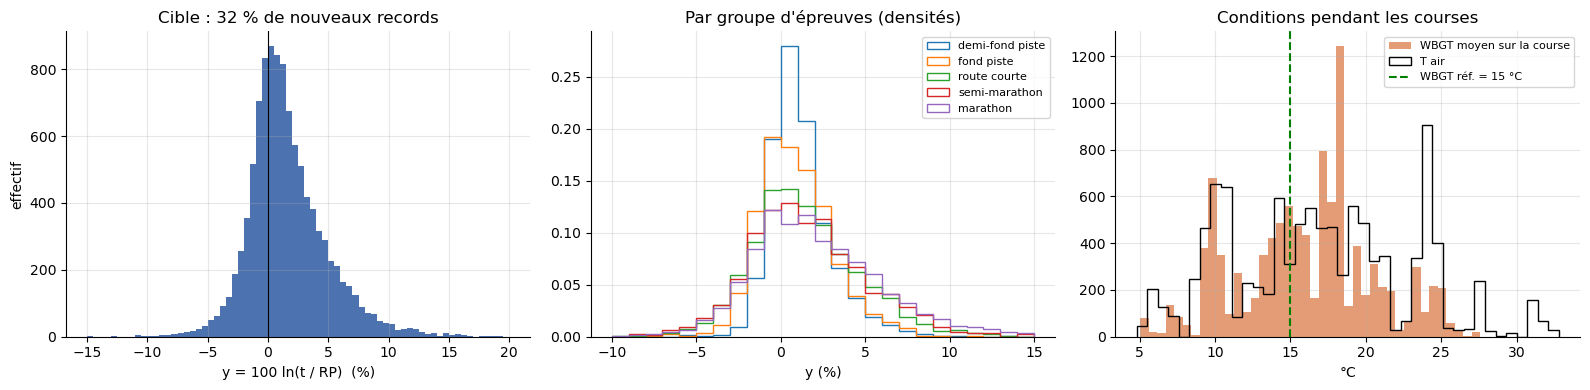

                      count     mean     std     min      5%      50%      95%      max
t_air               10398.0    17.01    5.96    4.80    8.76    16.76    27.35    32.80
hr                  10398.0    61.82   19.06   21.77   34.55    63.25    95.41   100.00
t_rosee             10398.0     8.83    5.19   -6.31   -0.88     9.56    17.10    24.46
vent_10m            10398.0     2.93    1.43    0.30    0.71     2.69     5.50     6.30
rayonnement_global  10398.0   289.06  202.30    0.00   15.30   246.90   700.50   820.89
precipitation_mm_h  10398.0     0.04    0.20    0.00    0.00     0.00     0.15     1.70
nebulosite          10398.0    53.60   41.90    0.00    0.00    60.88   100.00   100.00
pression_hpa        10398.0  1008.60   26.75  758.15  988.00  1014.43  1024.72  1033.06
altitude_m          10398.0    86.02  241.17    3.00    7.00    26.00   216.00  2582.00
t_globe             10398.0    23.14    6.79    7.40   11.99    22.96    35.14    45.72
t_nwb               10398.0    1

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df[CIBLE], bins=np.arange(-15, 20.5, 0.5), color="#4C72B0")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("y = 100 ln(t / RP)  (%)"); axes[0].set_ylabel("effectif")
axes[0].set_title(f"Cible : {100 * (df[CIBLE] < 0).mean():.0f} % de nouveaux records")
for g in GROUPES:
    sous = df[df["groupe_epreuve"] == g]
    axes[1].hist(sous[CIBLE], bins=np.arange(-10, 16, 1.0), histtype="step", density=True, label=g, lw=1.5)
axes[1].legend(fontsize=8); axes[1].set_xlabel("y (%)"); axes[1].set_title("Par groupe d'épreuves (densités)")
axes[2].hist(df["wbgt"], bins=40, color="#DD8452", alpha=0.8, label="WBGT moyen sur la course")
axes[2].hist(df["t_air"], bins=40, histtype="step", color="k", label="T air")
axes[2].axvline(WBGT_REF, color="g", ls="--", label=f"WBGT réf. = {WBGT_REF:g} °C")
axes[2].set_xlabel("°C"); axes[2].legend(fontsize=8); axes[2].set_title("Conditions pendant les courses")
plt.tight_layout(); plt.show()

meteo = ["t_air", "hr", "t_rosee", "vent_10m", "rayonnement_global", "precipitation_mm_h", "nebulosite",
         "pression_hpa", "altitude_m", "t_globe", "t_nwb", "wbgt", "wbgt_depart", "wbgt_max_course"]
print(df[meteo].describe(percentiles=[0.05, 0.5, 0.95]).T.round(2))
print("\nWBGT moyen par groupe d'épreuves :")
print(df.groupby("groupe_epreuve")["wbgt"].describe(percentiles=[0.05, 0.5, 0.95]).reindex(GROUPES).round(1))

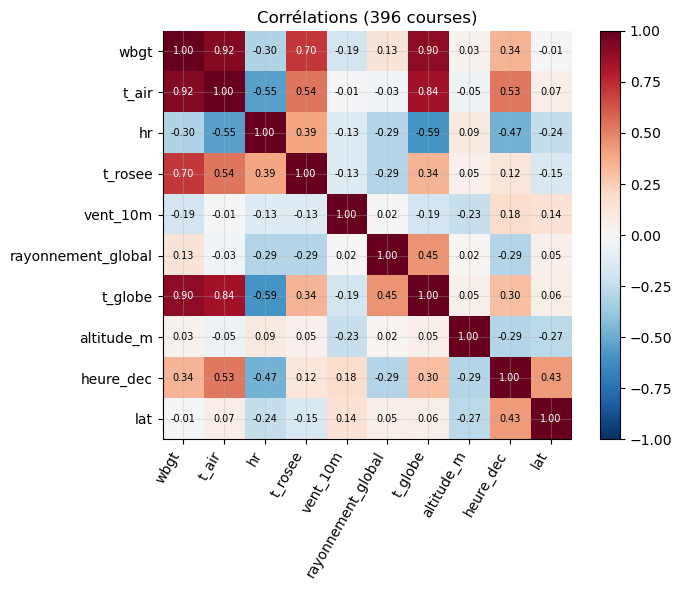

ville
Houston, TX            5.9
Pittsburgh, PA         6.8
Buenos Aires           6.9
Dessau                25.6
Guiyang               25.8
Cape Elizabeth, ME    26.5
Name: wbgt, dtype: float64


In [6]:
# Les conditions sont communes à tous les coureurs d'une course : une ligne par course
par_course = df.drop_duplicates("id_course")
corr = par_course[["wbgt", "t_air", "hr", "t_rosee", "vent_10m", "rayonnement_global", "t_globe", "altitude_m",
                   "heure_dec", "lat"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im); ax.set_title(f"Corrélations ({len(par_course)} courses)"); plt.tight_layout(); plt.show()
print(par_course.groupby("ville")["wbgt"].mean().sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(1))

In [7]:
# Compléments chiffrés pour l'analyse : forme de la cible, poids des courses, composition du WBGT
print(f"y : asymétrie {df[CIBLE].skew():.2f}, kurtosis en excès {df[CIBLE].kurt():.2f}, "
      f"{100 * (df[CIBLE] > 5).mean():.1f} % au-delà de +5 %, {100 * (df[CIBLE] < -5).mean():.1f} % en deçà de -5 %")
print(df.groupby("groupe_epreuve")[CIBLE].agg(moyenne="mean", mediane="median", ecart_type="std", asymetrie="skew",
                                               part_records=lambda s: (s < 0).mean(),
                                               part_sup_5=lambda s: (s > 5).mean()).reindex(GROUPES).round(2))

n_par_course = df.groupby("id_course").size().sort_values(ascending=False)
print(f"\nPerformances par course : médiane {n_par_course.median():.0f}, max {n_par_course.max()} ; "
      f"les 20 plus grosses courses pèsent {100 * n_par_course.head(20).sum() / len(df):.0f} % des lignes")
bandes = pd.cut(df["wbgt"], [0, 10, 18, 23, 28, 40], labels=["<10", "10-18", "18-23", "23-28", ">28"])
print(pd.DataFrame({"% performances": (100 * bandes.value_counts(normalize=True)).round(1),
                    "% courses": (100 * bandes[par_course.index].value_counts(normalize=True)).round(1)}).sort_index().T)
print(pd.crosstab(bandes[par_course.index], par_course["groupe_epreuve"]).reindex(columns=GROUPES))

print("\nConditions médianes par groupe :")
print(df.groupby("groupe_epreuve")[["heure_dec", "t_air", "hr", "rayonnement_global", "vent_10m"]].median()
      .reindex(GROUPES).round(1))
ecart_intra = df.groupby("id_course")["wbgt"].agg(lambda s: s.max() - s.min())
derive = df["wbgt_max_course"] - df["wbgt_depart"]
print(pd.DataFrame({"hausse WBGT départ->max (médiane)": derive.groupby(df["groupe_epreuve"]).median(),
                    "écart de WBGT entre coureurs d'une course (médiane)":
                        ecart_intra.groupby(par_course.set_index("id_course")["groupe_epreuve"]).median()})
      .reindex(GROUPES).round(2))
print(f"Écart de WBGT entre coureurs d'une même course : max {ecart_intra.max():.2f} °C")
print(f"Pluie (> 0,1 mm/h) : {(par_course['precipitation_mm_h'] > 0.1).sum()} courses ; "
      f"altitude > 1 000 m : {(par_course['altitude_m'] > 1000).sum()} courses, "
      f"{(df['altitude_m'] > 1000).sum()} performances")

y : asymétrie 0.87, kurtosis en excès 2.50, 13.5 % au-delà de +5 %, 1.2 % en deçà de -5 %
                 moyenne  mediane  ecart_type  asymetrie  part_records  part_sup_5
groupe_epreuve                                                                    
demi-fond piste     1.19     0.84        1.92       1.52          0.26        0.04
fond piste          0.90     0.65        2.25       0.42          0.38        0.05
route courte        1.44     1.06        3.29       0.55          0.35        0.14
semi-marathon       1.58     1.21        3.56       0.47          0.35        0.16
marathon            2.18     1.62        3.98       0.67          0.32        0.21

Performances par course : médiane 14, max 293 ; les 20 plus grosses courses pèsent 32 % des lignes
wbgt             <10  10-18  18-23  23-28  >28
% performances  11.9   52.6   26.4    9.0  0.0
% courses        8.1   43.2   29.8   18.9  0.0


groupe_epreuve  demi-fond piste  fond piste  route courte  semi-marathon  marathon
wbgt                                                                              
<10                           0           0             6             13        13
10-18                        20          32            41             33        45
18-23                        37          23            20             10        28
23-28                        38           9            20              0         8

Conditions médianes par groupe :
                 heure_dec  t_air    hr  rayonnement_global  vent_10m
groupe_epreuve                                                       
demi-fond piste       20.0   23.8  52.2               192.8       2.7
fond piste            20.0   19.9  52.3               111.5       3.9
route courte          15.0   15.5  72.5               290.6       2.7
semi-marathon          8.5   10.0  77.3               162.3       2.4
marathon              10.0   13.2  64.2         

**Analyse.**

**Forme de la cible.** Sur 10 398 performances, 32 % sont **plus rapides que le record d'avant course** ($y < 0$ :
nouveau record). La médiane vaut 1,1 %, la moyenne 1,6 %. Les centiles 5 et 95 sont à −2,8 % et
+7,5 %. La distribution est **asymétrique à droite** (coefficient d'asymétrie 0,87) et à **queues épaisses**
(kurtosis en excès 2,5) : 13,5 % des performances sont plus de 5 % au-dessus du record, contre 1,2 % plus de
5 % en dessous. On peut courir bien plus lentement que son record (jour sans, course tactique, blessure,
coureur vieillissant), mais rarement beaucoup plus vite.

Le fait que $y$ soit positif en moyenne est attendu et ne doit rien à la météo : le record est le **minimum**
des performances passées. Une course quelconque est donc en moyenne plus lente que ce minimum, et l'écart est
d'autant plus grand que les performances d'un athlète sont dispersées. C'est ce qu'on observe : la moyenne
croît avec la dispersion, de 0,9-1,2 % sur piste à 2,2 % au marathon. Les 32 % de records viennent surtout
d'athlètes en progression (jeunes, record ancien ou établi sur peu de courses).

**Hétéroscédasticité.** La dispersion croît avec la distance : écart-type de 1,9 point en demi-fond,
2,2 en fond sur piste, 3,3 à 3,6 sur route et 4,0 au marathon, soit une **variance quatre fois plus grande**
au marathon qu'en demi-fond. Le demi-fond est aussi le groupe le plus concentré autour de 0 (pic de la
densité entre 0 et 1 %) et le plus asymétrique (1,52) : les coureurs de 800-1 500 m courent souvent, leur
record est récent et proche de leur niveau du moment, et seuls les mauvais jours (courses tactiques,
fatigue) les en éloignent. À l'inverse, 21 % des marathoniens finissent à plus de 5 % de leur record. Deux
conséquences pour la suite :

* une perte quadratique sera **dominée par les erreurs sur route et au marathon** ; les métriques devront
  être lues par groupe d'épreuves, et pas seulement globalement ;
* les queues épaisses rendent le RMSE sensible à quelques contre-performances extrêmes ; le MAE, ou une
  perte robuste (Huber), est un complément utile.

L'écart entre sexes est faible (moyenne 1,7 % chez les femmes, 1,6 % chez les hommes, écarts-types 3,5 et
3,2) et s'explique en partie par la répartition entre épreuves.

**Conditions.** Le WBGT moyen sur la course va de 5 à 27,6 °C (médiane 16,4 °C) : 12 % des performances
sous 10 °C, 53 % entre 10 et 18 °C, 26 % entre 18 et 23 °C, 9 % entre 23 et 28 °C, **aucune au-delà de
28 °C**. Les plages diffèrent beaucoup selon le groupe. Le demi-fond et le fond sur piste (réunions
d'été en soirée, vers 20 h) ne descendent jamais sous 13,5 °C, avec une médiane de 18,3 °C en
demi-fond. Le semi-marathon et le marathon (départs à 8 h 30 - 10 h, saisons intermédiaires) vont de
5 à 22 °C et de 6 à 26 °C, avec des médianes de 10,3 et 14,2 °C.

**Une ligne n'est pas une observation indépendante de la météo.** Le WBGT varie très peu entre les coureurs
d'une même course : l'écart entre le premier et le dernier listé ne dépasse jamais 1,2 °C (médiane 0,24 °C
au marathon). Cela s'explique par la troncature : les listes ne gardent que des coureurs rapides, arrivés à
quelques minutes d'écart. La météo est donc en pratique une **variable de course**, et l'information
disponible sur son effet repose sur **396 courses**, pas sur 10 398 lignes. Ces courses ont des tailles très
inégales : médiane de 14 performances, maximum de 293 (10 km de Lille), et les 20 plus grosses courses
représentent 32 % des lignes. Or ces grosses courses (marathons de Valence, Tokyo, Berlin, semi de
Boulogne) se courent au frais. Les courses chaudes sont plus petites : 19 % des courses sont au-dessus de
23 °C, contre 9 % des performances. Une régression ordinaire, qui pondère chaque ligne de la même façon,
donnerait donc beaucoup de poids à quelques marathons frais et peu aux courses chaudes. C'est ce qui
justifie une validation croisée groupée par lieu (partie 2) et des effets aléatoires de course (partie 4).

**Le WBGT n'a pas la même composition selon le groupe.** Sur piste, les réunions du soir combinent un air
chaud (médiane 23,8 °C en demi-fond), sec (HR 52 %) et un soleil bas (190 W/m²). Les marathons du matin
combinent un air plus frais (13,2 °C), plus humide (64 %) et un fort rayonnement (430 W/m²). Deux exemples
extrêmes donnent le même WBGT par des chemins opposés : le meeting de Dessau 2026 (31,5 °C, HR 38 %, 200 W/m²,
WBGT 26,0 °C) et le marathon de Guiyang 2026 (21,2 °C seulement, mais HR 73 % et 540 W/m², WBGT 25,8 °C).
Le WBGT n'est donc pas une simple température, et un modèle qui ne verrait que $T_{air}$ classerait mal ces
deux courses. À l'inverse, il n'est pas acquis qu'un même WBGT ait le même effet physiologique quelle que
soit sa composition ; la partie 5.4 compare WBGT seul et variables météo brutes.

La **dérive pendant la course** est importante sur les longues distances : du départ au maximum, le WBGT
monte en médiane de 2,4 °C sur semi-marathon et de 3,7 °C au marathon (nulle sur piste). Le WBGT au
départ, la seule valeur souvent publiée, sous-estime donc la contrainte subie. Cela justifie d'utiliser le
WBGT moyen sur la durée de course.

**Corrélations entre variables météo** (une ligne par course). Le WBGT est très corrélé à la température de
l'air (0,92) et à la température de globe (0,90), plus modérément au point de rosée (0,70). Il est peu lié au
rayonnement global pris seul (0,13), car les courses les plus chaudes sont les réunions du soir, sans soleil.
L'humidité relative est **anticorrélée** à la température (−0,55) : c'est le cycle diurne, où l'humidité
relative baisse quand l'air se réchauffe. Les combinaisons « chaud et humide » sont donc rares dans
l'échantillon, et il sera **difficile de séparer les effets de $T$ et de $HR$** à partir des seules données.
C'est l'un des intérêts du WBGT : il les combine par un modèle physique au lieu de demander au modèle
d'apprendre cette combinaison. L'heure de départ est liée à la température (0,53) et à la latitude (0,43) :
elle encode surtout le **type de réunion** (piste le soir en Europe du Nord, route le matin) et sera un
facteur confondant à contrôler avec le groupe d'épreuves. L'altitude n'est presque pas corrélée au WBGT
(0,03), ce qui permet en principe d'estimer son effet séparément. La pression, quasi déterminée par
l'altitude, n'apporte rien de plus.

Les villes extrêmes illustrent la saison plus que le climat : Houston (marathon et semi de janvier, 5,9 °C),
Buenos Aires (semi d'août, en hiver austral, 6,9 °C), Cape Elizabeth (10 km d'août, 26,5 °C). Avec une ou
deux courses par ville, ces moyennes ne caractérisent pas le climat local.

**Combinaisons mal représentées.** Piste au frais (moins de 16 °C) ; semi-marathon au chaud (aucune course
au-delà de 22 °C) ; marathon très chaud (8 courses au-dessus de 23 °C seulement, 102 performances) ; toute
condition extrême (WBGT ≥ 28 °C, drapeau noir de l'ACSM). Le croisement épreuve × chaleur est
**défavorable** : la moitié des courses au-dessus de 23 °C sont des courses de demi-fond, là où
l'effet attendu de la chaleur est le plus faible (§ 0.2). Pour les longues distances, où l'effet est le plus
fort, l'information sur la chaleur est rare. L'effet au marathon par forte chaleur reposera donc sur peu de
courses, et son intervalle de confiance sera large.

Les autres facteurs sont peu variés. La **pluie** ne concerne que 37 courses (> 0,1 mm/h) et son effet sera
mal estimé. Le **vent** à 10 m ne dépasse pas 6,3 m/s : aucune course venteuse. L'**altitude** n'est
observée que sur route, dans 18 courses (168 performances, 1,6 % des données) et 8 lieux au-dessus de
1 000 m, dont certains sont aussi chauds (Guiyang, Kigali, Lanzhou) : son effet sera confondu avec celui de la
chaleur et du plateau d'athlètes. Toute conclusion sur ces combinaisons sera de l'extrapolation.

**Conséquences pour la modélisation.**

1. Le groupe d'épreuves (ou la durée de course) doit entrer dans le modèle, **en interaction avec le WBGT** :
   les plages de WBGT, le niveau moyen de $y$ et sa dispersion diffèrent tous selon le groupe.
2. La météo est une variable de course : l'unité d'information est la course, ce qui impose une validation
   croisée groupée et une structure d'effets de course ou de parcours.
3. Le domaine de validité de l'outil final est un WBGT de 5 à 27 °C, sans altitude marquée ni pluie forte ;
   au-delà, il faudra signaler l'extrapolation à l'utilisateur.

### 1.3 Relation brute entre performance et WBGT

Pour avoir une première idée de l'impact du WBGT sur la performance, on peut tracer la moyenne de $y$
par classe de WBGT. Cette analyse est d'autant plus intéressante quand on classe les données par type
d'épreuve.

**Moyenne par classe et erreur type.** Le WBGT est découpé en classes $(a, b]$ de 3 °C. Dans la classe
$b$, qui compte $n_b$ performances, on calcule la moyenne $\bar y_b$ et son **erreur type**

$$\text{se}(\bar y_b) = \frac{s_b}{\sqrt{n_b}}, \qquad s_b^2 = \frac{1}{n_b - 1}\sum_{i \in b}(y_i - \bar y_b)^2 .$$

L'erreur type est l'écart-type de l'*estimateur* $\bar y_b$, c'est-à-dire sa variabilité d'un échantillon
à l'autre, à ne pas confondre avec l'écart-type $s_b$ des *observations*. Le diviseur $n_b - 1$ rend $s_b^2$
sans biais, la moyenne ayant été estimée sur les mêmes données. D'après le théorème central limite,
$\bar y_b$ suit approximativement une loi normale, d'où l'intervalle de confiance à 95 %
$\bar y_b \pm 1{,}96\,\text{se}(\bar y_b)$, où 1,96 est le quantile 97,5 % de la loi normale centrée réduite.
Par groupe d'épreuves, seules les classes d'au moins 25 performances sont représentées.

Ces barres d'erreur reposent sur une hypothèse cachée : la formule $\text{Var}(\bar y_b) = \sigma^2/n_b$
suppose des observations **indépendantes**. Or les coureurs d'une même course partagent la météo et le
déroulement de la course ; les barres sont donc trop étroites (partie 1.6).

**Le paradoxe de Simpson.** La moyenne de toutes les épreuves dans la classe $b$ est une moyenne pondérée
des moyennes de chaque groupe d'épreuves $e$ :

$$\bar y_b = \sum_e \pi_{e \mid b}\,\bar y_{e, b}, \qquad \pi_{e \mid b} = \text{part du groupe } e \text{ dans la classe } b .$$

Si la composition $\pi_{e \mid b}$ change d'une classe à l'autre, par exemple beaucoup de demi-fond dans
les classes chaudes et beaucoup de marathons dans les classes fraîches, la courbe globale peut monter,
descendre ou s'aplatir même si chaque groupe a une relation nette. Une tendance agrégée peut ainsi
différer, voire s'inverser, par rapport aux tendances de chaque sous-groupe : c'est le **paradoxe de
Simpson**. D'où l'intérêt de lire les courbes par groupe d'épreuves.

moyenne_par_classes : OK


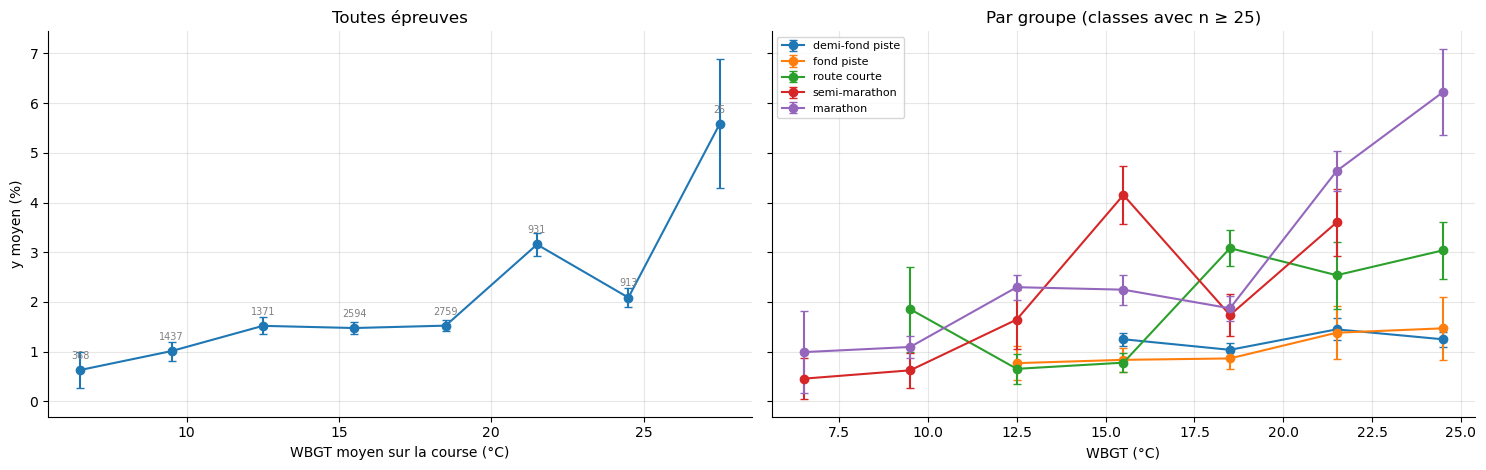

In [8]:
def moyenne_par_classes(x, y, bornes):
    '''Moyenne de y par classe de x.

    Entrées
        x, y : array-like (n,)
        bornes : array-like (B+1,) bornes croissantes des classes (a, b]
    Sortie
        DataFrame (une ligne par classe non vide) de colonnes
        centre, n, moyenne, erreur_type
    '''
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    classes = pd.cut(x, bornes)
    tab = pd.DataFrame({"classe": classes, "y": y}).groupby("classe", observed=True)["y"]
    res = tab.agg(n="size", moyenne="mean", ecart_type="std")
    res["erreur_type"] = res["ecart_type"] / np.sqrt(res["n"])
    res["centre"] = [(iv.left + iv.right) / 2 for iv in res.index]
    return res.reset_index(drop=True)[["centre", "n", "moyenne", "erreur_type"]]

#test
_t = moyenne_par_classes([1, 2, 3, 4, 11], [0, 2, 4, 6, 100], [0, 5, 10, 15])
assert list(_t["n"]) == [4, 1] and np.allclose(_t["moyenne"], [3, 100])
assert np.isclose(_t["erreur_type"].iloc[0], np.std([0, 2, 4, 6], ddof=1) / 2) and np.isnan(_t["erreur_type"].iloc[1])
assert np.allclose(_t["centre"], [2.5, 12.5])
print("moyenne_par_classes : OK")

#affichage
bornes = np.arange(np.floor(df["wbgt"].min()), np.ceil(df["wbgt"].max()) + 3, 3.0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
tab = moyenne_par_classes(df["wbgt"], df[CIBLE], bornes)
axes[0].errorbar(tab["centre"], tab["moyenne"], yerr=1.96 * tab["erreur_type"], fmt="o-", capsize=3)
for _, r in tab.iterrows():
    axes[0].annotate(int(r["n"]), (r["centre"], r["moyenne"]), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=7, color="gray")
axes[0].set_xlabel("WBGT moyen sur la course (°C)"); axes[0].set_ylabel("y moyen (%)"); axes[0].set_title("Toutes épreuves")
for g in GROUPES:
    sous = df[df["groupe_epreuve"] == g]
    t = moyenne_par_classes(sous["wbgt"], sous[CIBLE], bornes)
    t = t[t["n"] >= 25]
    axes[1].errorbar(t["centre"], t["moyenne"], yerr=1.96 * t["erreur_type"], fmt="o-", capsize=3, label=g)
axes[1].legend(fontsize=8); axes[1].set_xlabel("WBGT (°C)"); axes[1].set_title("Par groupe (classes avec n ≥ 25)")
plt.tight_layout(); plt.show()

**Analyse.** Toutes épreuves confondues, $\bar y$ monte de 0,6 % (WBGT 5-8 °C) à 1,0 % (8-11 °C), reste vers 1,5 %
entre 11 et 20 °C, puis passe à 3,2 % entre 20 et 23 °C. Il **retombe** à 2,1 % entre 23 et 26 °C,
une classe composée à 69 % de demi-fond sur piste, puis atteint 5,6 % au-delà de 26 °C (25
performances seulement). Par groupe, le contraste est net :

* **marathon** : environ 1 % jusqu'à 11 °C, 1,9 à 2,3 % entre 11 et 20 °C, puis 4,6 % (20-23 °C) et
  6,2 % (23-26 °C). Le ralentissement est fort et convexe, cohérent avec Ely *et al.* (2007) ;
* **demi-fond et fond sur piste** : presque plats (0,8 à 1,5 %) sur toute leur plage, 12-26 °C ;
* **route courte et semi-marathon** : profils irréguliers, comme le pic du semi entre 14 et 17 °C
  (4,2 %). Chaque classe ne réunit qu'une poignée de courses (2 à 20) : ces moyennes mélangent l'effet
  de la chaleur et celui du lieu (parcours, plateau, âge des coureurs).

La moyenne globale est trompeuse : sa forme dépend surtout de **quel groupe d'épreuves** domine chaque
classe (paradoxe de Simpson). Les barres d'erreur, calculées comme si les performances étaient
indépendantes, sont trop étroites (partie 1.6).

### 1.4 Facteurs confondants

Le WBGT n'est pas distribué au hasard. Les courses chaudes ont lieu dans certains pays (Asie du Sud-Est,
Afrique de l'Ouest, Golfe) et à certaines saisons, avec des plateaux différents : niveau, âge, part
d'athlètes établissant un record. L'altitude se concentre dans quelques villes.

Un facteur confondant n'est dangereux que s'il est **lié au WBGT** (partie 0.4). On mesure donc, au niveau
des courses, la corrélation entre le WBGT et chaque variable de contexte (niveau, âge, forme, altitude,
heure). Chaque course $c$ reçoit un poids $w_c = n_c/\sum_{c'} n_{c'}$ proportionnel à son nombre de
coureurs, pour refléter son poids dans les données individuelles. La corrélation pondérée s'écrit

$$r_w = \frac{\sum_c w_c\,(u_c - \bar u_w)(v_c - \bar v_w)}{\sqrt{\sum_c w_c\,(u_c - \bar u_w)^2}\,\sqrt{\sum_c w_c\,(v_c - \bar v_w)^2}},
\qquad \bar u_w = \sum_c w_c\,u_c .$$

Le sens du biais d'une régression simple de $y$ sur le WBGT se déduit ensuite de la formule du biais de
variable omise (partie 0.4) : il a le signe de $\beta_Z \times \text{Cov}(W, Z)$, où $\beta_Z$ est l'effet du facteur
$Z$ sur $y$.

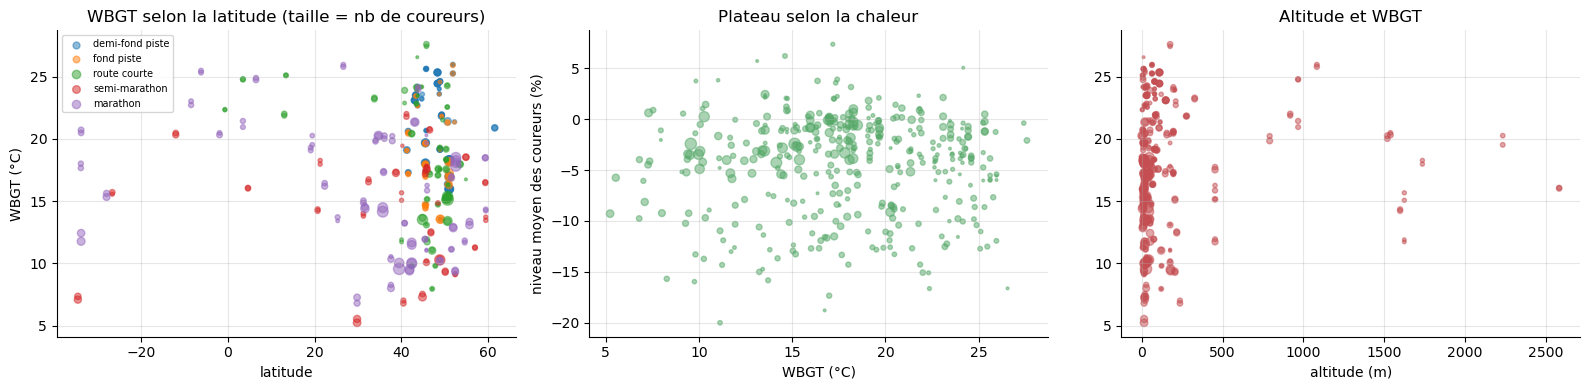

Corrélations au niveau des courses (pondérées par le nombre de coureurs) :
  WBGT ~ niveau      : +0.05
  WBGT ~ age         : -0.43
  WBGT ~ forme       : -0.15
  WBGT ~ altitude_m  : +0.13
  WBGT ~ heure       : +0.42


In [9]:
pc = df.groupby("id_course").agg(wbgt=("wbgt", "mean"), altitude_m=("altitude_m", "first"), lat=("lat", "first"),
                                niveau=("niveau_pct", "mean"), age=("age", "mean"), forme=("forme_pct", "mean"),
                                groupe=("groupe_epreuve", "first"), heure=("heure_dec", "first"), n=(CIBLE, "size"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for g in GROUPES:
    s = pc[pc["groupe"] == g]
    axes[0].scatter(s["lat"], s["wbgt"], s=np.sqrt(s["n"]) * 4, alpha=0.5, label=g)
axes[0].set_xlabel("latitude"); axes[0].set_ylabel("WBGT (°C)"); axes[0].legend(fontsize=7)
axes[0].set_title("WBGT selon la latitude (taille = nb de coureurs)")
axes[1].scatter(pc["wbgt"], pc["niveau"], s=np.sqrt(pc["n"]) * 4, alpha=0.5, color="#55A868")
axes[1].set_xlabel("WBGT (°C)"); axes[1].set_ylabel("niveau moyen des coureurs (%)"); axes[1].set_title("Plateau selon la chaleur")
axes[2].scatter(pc["altitude_m"], pc["wbgt"], s=np.sqrt(pc["n"]) * 4, alpha=0.5, color="#C44E52")
axes[2].set_xlabel("altitude (m)"); axes[2].set_title("Altitude et WBGT")
plt.tight_layout(); plt.show()
print("Corrélations au niveau des courses (pondérées par le nombre de coureurs) :")
w = pc["n"] / pc["n"].sum()
for v in ["niveau", "age", "forme", "altitude_m", "heure"]:
    x = pc[["wbgt", v]].dropna(); ww = w[x.index]
    m = (x * ww.values[:, None]).sum() / ww.sum()
    cov = ((x["wbgt"] - m["wbgt"]) * (x[v] - m[v]) * ww).sum() / ww.sum()
    sd = np.sqrt(((x - m) ** 2 * ww.values[:, None]).sum() / ww.sum())
    print(f"  WBGT ~ {v:11s} : {cov / (sd['wbgt'] * sd[v]):+.2f}")

**Analyse.** Au niveau des courses, le WBGT est corrélé à l'**âge** moyen (−0,43), à l'**heure** (+0,42), à la
**forme** (−0,15) et à l'**altitude** (+0,13), mais presque pas au **niveau** des coureurs (+0,05).
Les biais attendus d'une régression simple de $y$ sur le WBGT :

* **composition des épreuves** : les courses chaudes sont surtout des réunions de piste (38 des 75
  courses au-dessus de 23 °C sont du demi-fond), où la chaleur pèse peu ; les courses fraîches sont des
  marathons et des semis. L'effet poolé **sous-estime** celui du marathon et surestime celui du
  demi-fond ;
* **âge** : $y$ augmente fortement avec l'âge (0,7 % avant 23 ans, 3,5 à 3,8 % après 38 ans), car le record
  d'un coureur âgé est ancien. Les courses chaudes réunissent des coureurs plus jeunes : biais **vers
  le bas** ;
* **altitude** : les lieux d'altitude (Kigali, Mexico, Guiyang, Lanzhou) sont aussi chauds, et
  l'hypoxie ralentit : biais **vers le haut** si l'altitude est omise ;
* **pays et parcours** : WBGT élevé sous les tropiques (Jakarta, Chon Buri, Lagos, Cali) et dans
  les réunions d'été européennes. Ces courses diffèrent aussi par le profil, le plateau et l'enjeu : biais de sens
  inconnu, d'où les effets de parcours de la partie 4 ;
* **sélection** : par forte chaleur, des coureurs renoncent, abandonnent (absents des listes) ou
  « assurent » ; la **troncature** des listes coupe les performances lentes. Biais **vers le bas**,
  traité en partie par la marge $M$ (partie 1.5).

### 1.5 La troncature : démonstration empirique

Revenons sur le piège de la troncature. À titre d'illustration, considérons deux coureurs masculins de même niveau, dont le record au marathon est de 2 h 30. Rappelons que les grands marathons ne listent que les hommes sous 2 h 37 et les femmes sous 3 h 05. Par temps frais, ces deux coureurs finissent entre 2 h 30 et 2 h 35 : ils sont sous le seuil et apparaissent donc sans problème dans les résultats. Par fort WBGT, le premier court cette fois en 2 h 36 et reste listé. Le second, davantage affecté par les conditions, court en 2 h 45 : il dépasse le seuil et disparaît des résultats. Seul le coureur le plus résistant à la chaleur figure donc dans le jeu de données. Pour les athlètes dont le record est proche du seuil, c'est-à-dire les moins rapides de la liste, on n'observe par forte chaleur que ceux qui ont bien couru par rapport à leur niveau. Notons $T^{\max}_c$ le temps du dernier coureur listé dans la course $c$. Un athlète n'apparaît que si $t_i \le T^{\max}_c$, c'est-à-dire si $y_i \leq m_i = 100 \ln \frac{T_c^{\max}}{t_i^{\text{RP}}}$. Leur ralentissement moyen est alors sous-estimé, et l'effet de la chaleur est biaisé vers zéro. 

Pour s'en convaincre, modélisons formellement cette illustration. Supposons que, en l'absence de troncature, $y_i$ suive une loi normale $\mathcal{N}(\mu_i, \sigma^2)$, c'est-à-dire $y_i = \mu_i + \varepsilon_i$ avec $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$. Ici $\mu_i = \mathbb{E}[y_i]$ est le ralentissement moyen attendu pour l'athlète $i$ dans les conditions de sa course. Une hausse du WBGT augmente $\mu_i$. Mais on n'observe $y_i$ que si $y_i \leq m_i$, et la quantité réellement observée est $\mathbb{E}[y_i | y_i \leq m_i]$.

Notons $a_i=\frac{(m_i-\mu_i)}{\sigma}$, $\varphi$ et $\Phi$ la densité et la fonction de répartition de la loi normale centrée réduite. L'espérance d'une loi normale tronquée par le haut vaut :

$$\mathbb{E}[y_i | y_i \leq m_i]=\mu_i-\sigma \Lambda(a_i)$$

avec $\Lambda(a)=\frac{\varphi(a)}{\Phi(a)}$ (inverse du ratio de Mills).

En effet, 

$$\mathbb{E}[\varepsilon | \varepsilon \leq \sigma a] = \frac{1}{\Phi(a)}\int_{-\infty}^a \sigma z\varphi(z) \text{d}z=-\sigma\frac{\varphi(a)}{\Phi(a)}$$

car $z\varphi(z)=-\varphi'(z)$.

Ainsi, si la chaleur augmente $\mu_i$ de $\delta$, la moyenne réellement observée n'augmente que de
$\delta\,\frac{\partial}{\partial \mu}\mathbb{E}[y \mid y \leq m]$. Pour calculer cette dérivée, on note que
$a = (m - \mu)/\sigma$ dépend de $\mu$, avec $\frac{\partial a}{\partial \mu} = -\frac{1}{\sigma}$, et que,
puisque $\varphi'(a) = -a\,\varphi(a)$,

$$\Lambda'(a) = \frac{\varphi'(a)\,\Phi(a) - \varphi(a)^2}{\Phi(a)^2} = -\Lambda(a)\big(a + \Lambda(a)\big).$$

On obtient

$$\frac{\partial}{\partial \mu}\big[\mu - \sigma\Lambda(a)\big] = 1 - \sigma\,\Lambda'(a)\cdot\Big(-\frac{1}{\sigma}\Big) = 1 + \Lambda'(a)
= 1 - \Lambda(a)\big(a + \Lambda(a)\big).$$

Le facteur $1 - \Lambda(a)(a + \Lambda(a))$ est compris entre $0$ et $1$ : c'est aussi le rapport
$\text{Var}(y \mid y \leq m)/\sigma^2$, la variance d'une loi tronquée étant toujours positive et inférieure à
celle de la loi complète. La pente estimée est donc **atténuée**, d'autant plus que la marge $a$ est
faible. Quand la marge est grande (troncature négligeable), $\Lambda(a) \to 0$, le facteur tend vers 1 et le
biais disparaît.

Comme annoncé, l'idée est donc de ne garder que les athlètes dont la marge au seuil est suffisante :
$m_i \geq M$ avec $M$ la marge fixée. Ce filtre porte sur le **record** de l'athlète comparé au dernier
temps listé, et non sur son résultat du jour : il écarte les athlètes proches du seuil, pas ceux qui ont
mal couru. Le coût est bien entendu celui d'un échantillon plus petit et de meilleur niveau. Le filtre
réduit le biais sans l'éliminer : un ralentissement supérieur à la marge, ou un abandon, reste invisible.

Parmi les $4 425$ performances valides dont la marge est inférieure à $5\%$, $63\%$ sont des records personnels ($y<0$), contre $32\%$ dans l'échantillon d'analyse (marge $\geq 5 \%$). Un athlète dont le record est proche du dernier temps listé n'apparaît que s'il court vite.

Pour observer l'impact qu'a le choix de la marge minimale $M$ retenue, on compare la pente de $y$ en
fonction du WBGT selon la marge de troncature minimale $M$ exigée (0, 2, 5, 8, 10 et 12 %). Si la
troncature biaise vers 0, la pente doit **augmenter** avec $M$, au prix d'un échantillon plus petit et de
niveau plus élevé.

**La régression linéaire simple.** On suppose que la performance dépend du WBGT $x$ par une droite, plus
un aléa : $y = \beta_0 + \beta_1 x + \varepsilon$, où $\beta_1$ est la pente (en points de $y$ par °C), $\beta_0$ l'ordonnée à
l'origine et $\varepsilon$ un aléa de moyenne nulle et de variance $\sigma^2$. Par moindres carrés, on
retient les valeurs de $\beta_0, \beta_1$ qui minimisent la somme des carrés des résidus
$S(\beta_0, \beta_1) = \sum_i (y_i - \beta_0 - \beta_1 x_i)^2$. En annulant les dérivées partielles :

* $\partial S/\partial \beta_0 = -2\sum_i (y_i - \beta_0 - \beta_1 x_i) = 0$ donne $\hat\beta_0 = \bar y - \hat\beta_1\,\bar x$ : la
  droite passe par le point moyen $(\bar x, \bar y)$ ;
* $\partial S/\partial \beta_1 = -2\sum_i x_i(y_i - \beta_0 - \beta_1 x_i) = 0$ donne, en remplaçant $\beta_0$ par $\hat\beta_0$,
  $\sum_i (x_i - \bar x)(y_i - \bar y) = \hat\beta_1\sum_i (x_i - \bar x)^2$, d'où

$$\hat\beta_1 = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2} = \frac{\widehat{\text{Cov}}(x, y)}{\widehat{\text{Var}}(x)}
= r\,\frac{s_y}{s_x},\qquad \hat\beta_0 = \bar y - \hat\beta_1\,\bar x .$$

La pente combine la force du lien linéaire ($r$) et le rapport des échelles des deux variables.

**La précision de la pente.** Puisque $\sum_i(x_i-\overline{x})=0$, on peut écrire
$\hat\beta_1 = \frac{1}{S_{xx}}\sum_i(x_i-\overline{x})\,y_i$ avec $S_{xx}=\sum_i(x_i-\overline{x})^2$ : c'est une
combinaison linéaire des $y_i$. Avec des $\varepsilon_i$ indépendants de variance $\sigma^2$ :

$$\mathbb{E}[\hat\beta_1] = \beta_1, \qquad
\text{Var}(\hat\beta_1) = \frac{\sum_i(x_i-\overline{x})^2\,\sigma^2}{S_{xx}^2} = \frac{\sigma^2}{S_{xx}}, \qquad
\widehat{\text{se}}(\hat\beta_1) = \frac{\hat\sigma}{\sqrt{S_{xx}}} .$$

L'erreur type diminue quand il y a plus de données, quand le WBGT varie sur une plage plus large et quand le
bruit $\sigma$ est plus faible.

On cherche enfin à estimer $\sigma^2$, inconnu, dont dépend directement $\text{Var}(\hat\beta_1)$. L'estimation se
fait à partir des résidus $\hat \varepsilon_i = y_i - \hat\beta_0 - \hat\beta_1 x_i$. Ceux-ci vérifient deux
contraintes : $\sum_i \hat \varepsilon_i=0$ et $\sum_i x_i \hat \varepsilon_i=0$. Ils ne varient librement
que dans un espace de dimension $n-2$, le nombre de **degrés de liberté**. On montre que
$\mathbb{E}[\sum_i \hat \varepsilon_i^2]=(n-2)\sigma^2$, d'où l'estimateur sans biais

$$\hat \sigma^2=\frac{\sum_i \hat \varepsilon_i^2}{n-2-\nu}.$$

Diviser par $n$ sous-estimerait $\sigma^2$, la droite étant ajustée au plus près des points. Le paramètre
`ddl_perdus` $= \nu$ retire des degrés de liberté supplémentaires quand d'autres paramètres ont été estimés ;
il vaut $0$ dans cette section. Pour $n$ grand, $\hat\beta_1$ est approximativement normal, d'où l'intervalle de
confiance à 95 % $\hat\beta_1 \pm 1{,}96\,\widehat{\text{se}}(\hat\beta_1)$ : si l'on refaisait l'expérience, 95 % des
intervalles ainsi construits contiendraient la vraie pente.

**L'expérience.** Pour chaque $M$, on garde les performances valides de marge $\geq M$ (toutes épreuves,
puis le marathon seul pour éviter le paradoxe de Simpson), et l'on calcule la pente, son intervalle de
confiance et l'effectif. Trois points guident la lecture :

* sans troncature, la pente serait à peu près constante : le sous-échantillon change, pas la vraie pente.
  Avec une troncature qui atténue la pente, elle doit augmenter avec $M$ ;
* un $M$ plus grand réduit le biais mais retire des données : l'intervalle de confiance s'élargit
  (compromis biais-variance), et l'échantillon change de nature (athlètes plus rapides), ce qui peut aussi
  modifier la pente si l'effet de la chaleur dépend du niveau ;
* les sous-échantillons sont **emboîtés** (celui de $M = 12$ est inclus dans celui de $M = 5$) : les pentes
  sont très corrélées entre elles, et des intervalles qui se chevauchent ne suffisent pas à conclure que
  deux pentes sont égales.

In [10]:
def pente_ols_simple(x, y, ddl_perdus=0):
    '''Régression linéaire simple y = a + b x.

    Entrées : x, y array-like (n,) ; ddl_perdus : int, degrés de liberté retirés en plus des 2 paramètres
    Sortie : dict avec 'pente', 'ordonnee', 'erreur_type_pente'
    '''
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    xc, yc = x - x.mean(), y - y.mean()
    sxx = np.sum(xc ** 2)
    b = np.sum(xc * yc) / sxx
    a = y.mean() - b * x.mean()
    residus = y - a - b * x
    sigma2 = np.sum(residus ** 2) / (len(x) - 2 - ddl_perdus)
    return {"pente": b, "ordonnee": a, "erreur_type_pente": np.sqrt(sigma2 / sxx)}


def pentes_selon_marge(df, marges, groupe=None, x="wbgt"):
    '''Pente de y en fonction de x pour chaque marge minimale M.

    Sortie : DataFrame [marge, n, pente, ic_bas, ic_haut]
    '''
    lignes = []
    for M in marges:
        sel = df[df["marge_troncature_pct"] >= M]
        if groupe is not None:
            sel = sel[sel["groupe_epreuve"] == groupe]
        r = pente_ols_simple(sel[x], sel[CIBLE])
        lignes.append({"marge": M, "n": len(sel), "pente": r["pente"],
                       "ic_bas": r["pente"] - 1.96 * r["erreur_type_pente"],
                       "ic_haut": r["pente"] + 1.96 * r["erreur_type_pente"]})
    return pd.DataFrame(lignes)

In [11]:
#test
_x = np.array([0., 1, 2, 3, 4]); _y = 2 + 0.5 * _x + np.array([0.1, -0.1, 0, 0.1, -0.1])
_r = pente_ols_simple(_x, _y)
_p = np.polyfit(_x, _y, 1)
assert np.isclose(_r["pente"], _p[0]) and np.isclose(_r["ordonnee"], _p[1])
_res = _y - np.polyval(_p, _x)
assert np.isclose(_r["erreur_type_pente"], np.sqrt(np.sum(_res ** 2) / 3 / 10))
_d = pd.DataFrame({"wbgt": [10., 20, 30, 10, 20, 30], CIBLE: [0., 1, 2, 0, 2, 4], "marge_troncature_pct": [1., 1, 1, 9, 9, 9],
                   "groupe_epreuve": ["marathon"] * 6})
_t = pentes_selon_marge(_d, [0, 5])
assert list(_t["n"]) == [6, 3] and np.isclose(_t["pente"].iloc[1], 0.2) and np.isclose(_t["pente"].iloc[0], 0.15)
print("pente_ols_simple, pentes_selon_marge : OK")

pente_ols_simple, pentes_selon_marge : OK


Toutes épreuves 
  marge     n  pente  ic_bas  ic_haut
     0 14221 0.1127  0.1012   0.1243
     2 13104 0.1045  0.0925   0.1165
     5 10398 0.0952  0.0813   0.1091
     8  7637 0.0959  0.0788   0.1129
    10  5961 0.0992  0.0796   0.1188
    12  4514 0.1103  0.0872   0.1334
Marathon 
  marge    n  pente  ic_bas  ic_haut
     0 5382 0.2219  0.1979   0.2460
     2 4919 0.2295  0.2046   0.2544
     5 3857 0.2276  0.1994   0.2559
     8 2899 0.2361  0.2030   0.2692
    10 2392 0.2396  0.2031   0.2762
    12 1974 0.2571  0.2169   0.2974


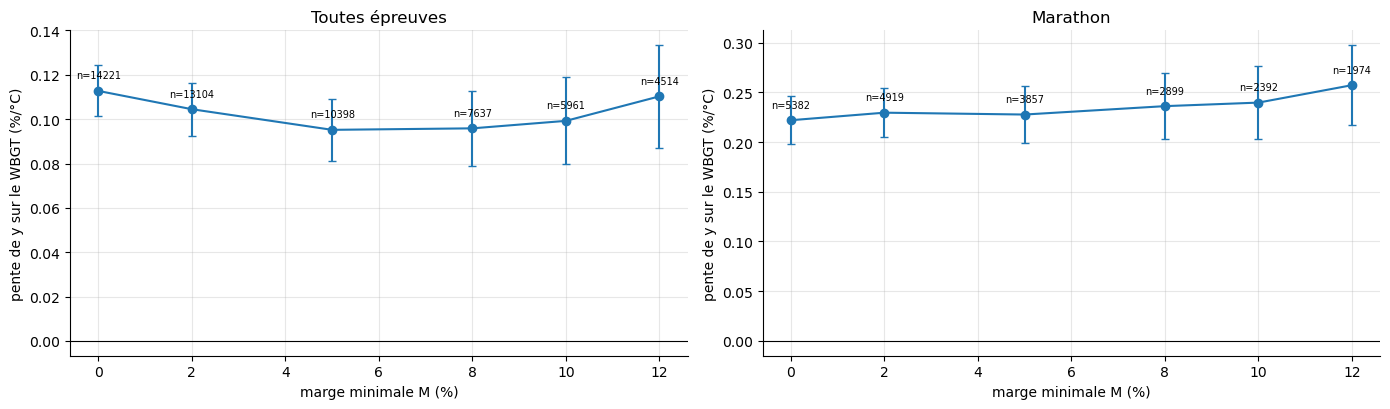

In [12]:
MARGES = [0, 2, 5, 8, 10, 12]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, g in zip(axes, [None, "marathon"]):
    t = pentes_selon_marge(df_complet, MARGES, groupe=g)
    ax.errorbar(t["marge"], t["pente"], yerr=[t["pente"] - t["ic_bas"], t["ic_haut"] - t["pente"]], fmt="o-", capsize=3)
    for _, r in t.iterrows():
        ax.annotate(f"n={int(r['n'])}", (r["marge"], r["pente"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7)
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("marge minimale M (%)"); ax.set_ylabel("pente de y sur le WBGT (%/°C)")
    ax.set_title("Toutes épreuves" if g is None else "Marathon")
    print(("Toutes épreuves" if g is None else "Marathon"), "\n", t.round(4).to_string(index=False))
plt.tight_layout(); plt.show()

**Analyse.** La pente globale bouge peu avec la marge : 0,113 %/°C sans filtre ($M = 0$, 14 221 performances),
0,095 pour $M = 5$, 0,110 pour $M = 12$ (4 514 performances). Sur le **marathon**, elle croît
légèrement avec $M$ : 0,222 → 0,228 → 0,257 %/°C. C'est le sens attendu : quand les listes sont
tronquées, les performances lentes des jours chauds manquent, ce qui **atténue** la pente ; exiger une
marge plus grande retire les courses où cette atténuation est possible. L'ampleur reste modeste (+15 %
entre $M = 0$ et $M = 12$, dans les marges d'incertitude), alors que l'échantillon est divisé par
2,7. $M = 5$ est un compromis raisonnable, que l'on reverra en partie 11 avec le modèle final.

Deux réserves. La pente globale mêle les épreuves (partie 1.4). Les IC affichés supposent des
performances indépendantes : avec un ICC de course de 0,18 (partie 1.6), ils sont environ deux fois
trop étroits.

### 1.6 Structure de dépendance : course, meeting, parcours, lieu

Les coureurs d'une même course partagent la météo, le déroulement de la course (lièvres, tactique) et le
plateau ; les éditions d'un même parcours partagent son profil. Nous mesurons ici la part de la variance
de $y$ commune aux coureurs d'une même **course**, d'un même **meeting**, d'un même **parcours** (toutes
éditions) ou d'un même **lieu**, par la **corrélation intra-classe** (ICC). Une ICC élevée a deux
conséquences : il faudra garder les groupes entiers d'un même côté de la validation (partie 2), et un
modèle hiérarchique sera nécessaire (partie 4).

**Modèle à effet aléatoire de groupe.** On suppose que les observations sont réparties en $G$ groupes
(courses, lieux...) et que

$$
y_{gj}=\mu+u_g+\varepsilon_{gj}, \quad
u_g \sim \mathcal{N}(0,\tau^2), \quad
\varepsilon_{gj} \sim \mathcal{N}(0,\sigma^2),
$$

tous indépendants. $u_g$ est un effet de groupe partagé par toutes les observations du groupe $g$ (même
météo, même train de course, même parcours), $\varepsilon_{gj}$ est la part propre à l'individu $j$. Dans
ce cas,

$$
\text{Var}(y_{gj})=\tau^2+\sigma^2, \quad
\text{Cov}(y_{gj},y_{gj'})= \tau^2 \ (j \ne j'), \quad
\text{ICC}=\text{Corr}(y_{gj},y_{gj'})=\frac{\tau^2}{\tau^2+\sigma^2}.
$$

La covariance vient de ce que deux coureurs d'un même groupe partagent le même $u_g$ :
$\text{Cov}(\mu + u_g + \varepsilon_{gj}, \mu + u_g + \varepsilon_{gj'}) = \text{Var}(u_g) = \tau^2$.
L'ICC a deux lectures équivalentes : la part de la variance totale due aux groupes, et la corrélation
entre deux observations d'un même groupe. Pour $\text{ICC}=0$, les groupes ne jouent aucun rôle ; si
$\text{ICC}=1$, toutes les observations d'un même groupe sont identiques.

**Estimateur ANOVA, groupes déséquilibrés.** Avec $N$ observations, $n_g$ observations dans le groupe $g$,
$\bar y_g$ la moyenne du groupe et $\bar y$ la moyenne générale, la variation totale se décompose en une
part entre groupes et une part intra-groupes :

$$
\underbrace{\sum_g\sum_j(y_{gj}-\bar y)^2}_{\text{SST}}=\underbrace{\sum_g n_g(\bar y_g-\bar y)^2}_{\text{SSB (entre groupes)}}
+\underbrace{\sum_g\sum_j(y_{gj}-\bar y_g)^2}_{\text{SSW (intra-groupes)}} .
$$

On définit les carrés moyens, en divisant chaque somme par son nombre de degrés de liberté :

$$\text{MSB} = \frac{\sum_g n_g(\bar y_g - \bar y)^2}{G-1},\qquad
  \text{MSW} = \frac{\sum_g\sum_j (y_{gj} - \bar y_g)^2}{N-G},\qquad
  n_0 = \frac{N - \sum_g n_g^2/N}{G-1}.$$

Sous le modèle ci-dessus, on montre que

$$
\mathbb{E}[\text{MSW}]=\sigma^2, \quad
\mathbb{E}[\text{MSB}]=\sigma^2+n_0 \tau^2.
$$

L'intuition est la suivante. Au sein d'un groupe, $u_g$ est commun à tous et disparaît des écarts
$y_{gj} - \bar y_g$ : ceux-ci ne contiennent que le bruit individuel, d'où $\mathbb{E}[\text{MSW}] = \sigma^2$
($N - G$ degrés de liberté, car on a estimé $G$ moyennes). Les moyennes de groupe, elles, varient pour
deux raisons : les vraies différences entre groupes ($u_g$, de variance $\tau^2$) et le bruit
d'échantillonnage ($\sigma^2/n_g$). En développant $\mathbb{E}[\text{SSB}]$, on obtient
$(G - 1)\sigma^2 + \big(N - \sum_g n_g^2/N\big)\tau^2$, d'où le facteur $n_0$. Si tous les groupes ont la
même taille $n$, $n_0 = n$ ; s'ils sont déséquilibrés, $n_0$ est inférieur à l'effectif moyen $N/G$, car
les gros groupes apportent moins d'information sur $\tau^2$ que leur taille ne le suggère. On en déduit
l'estimateur des moments, qui égale chaque carré moyen à son espérance :

$$
\hat \sigma^2 = \text{MSW}, \quad
\hat \tau^2 = \frac{\text{MSB}-\text{MSW}}{n_0}, \quad
\widehat{\text{ICC}} = \frac{\hat \tau^2}{\hat \tau^2+\hat \sigma^2} = \frac{\text{MSB} - \text{MSW}}{\text{MSB} + (n_0 - 1)\,\text{MSW}}.$$

Quand la vraie ICC est proche de 0, MSB peut être inférieur à MSW par hasard, et l'estimateur est
légèrement **négatif**. On ne le tronque pas à 0, ce qui introduirait un biais vers le haut.

**Effet de plan et taille d'échantillon effective.** Pour la moyenne de $n$ observations d'un même groupe,
corrélées deux à deux avec la corrélation $\rho = \text{ICC}$ et de variance $\sigma_t^2 = \tau^2 + \sigma^2$,

$$\text{Var}(\bar y) = \frac{1}{n^2}\Big[n\,\sigma_t^2 + n(n-1)\,\rho\,\sigma_t^2\Big] = \frac{\sigma_t^2}{n}\,\big[1 + (n - 1)\rho\big].$$

Le facteur $\text{deff} = 1 + (\bar n - 1)\rho$, appelé **effet de plan** (Kish), mesure de combien la
corrélation multiplie la variance par rapport à des observations indépendantes. La **taille d'échantillon
effective** $N/\text{deff}$ est le nombre d'observations indépendantes qui apporteraient la même
information.

In [13]:
def icc_anova(y, groupes):
    '''Corrélation intra-classe (estimateur ANOVA, groupes déséquilibrés).

    Entrées : y array-like (N,) ; groupes array-like (N,) d'identifiants
    Sortie : float
    '''
    d = pd.DataFrame({"y": np.asarray(y, dtype=float), "g": np.asarray(groupes)})
    N, moy = len(d), d["y"].mean()
    stats = d.groupby("g")["y"].agg(["mean", "size"])
    k = len(stats)
    msb = np.sum(stats["size"] * (stats["mean"] - moy) ** 2) / (k - 1)
    msw = np.sum((d["y"] - d.groupby("g")["y"].transform("mean")) ** 2) / (N - k)
    n0 = (N - np.sum(stats["size"] ** 2) / N) / (k - 1)
    return float((msb - msw) / (msb + (n0 - 1) * msw))

In [14]:
#test
_rng = np.random.default_rng(1)
_g = np.repeat(np.arange(400), _rng.integers(2, 6, 400))
_u = _rng.normal(0, 1.0, 400)[_g]; _e = _rng.normal(0, 1.0, len(_g))
assert abs(icc_anova(_u + _e, _g) - 0.5) < 0.08
assert abs(icc_anova(_e, _g)) < 0.08
print("icc_anova : OK")

icc_anova : OK


In [15]:
for nom, col in [("course", "id_course"), ("meeting", "id_meeting"), ("parcours", "id_parcours"), ("lieu", "id_lieu")]:
    print(f"ICC {nom:9s}: {icc_anova(df[CIBLE], df[col]):.3f}   ({df[col].nunique()} groupes)")
print(df.groupby(["groupe_epreuve", "sexe"])[CIBLE].agg(["size", "mean", "std"]).round(2))

ICC course   : 0.183   (396 groupes)
ICC meeting  : 0.170   (135 groupes)
ICC parcours : 0.174   (172 groupes)
ICC lieu     : 0.161   (100 groupes)
                      size  mean   std
groupe_epreuve  sexe                  
demi-fond piste F      981  1.22  2.03
                M     1517  1.17  1.85
fond piste      F      315  1.20  2.42
                M      704  0.76  2.16
marathon        F     1575  2.18  4.18
                M     2282  2.17  3.84
route courte    F      438  1.76  3.53
                M     1452  1.34  3.20
semi-marathon   F      392  1.58  3.90
                M      742  1.58  3.37


**Analyse.** Environ **17 % de la variance de $y$** est commune aux coureurs d'une même course (ICC 0,18), d'un même
meeting (0,17), d'un même parcours (0,17) ou d'un même lieu (0,16). Ces valeurs sont presque égales :
l'essentiel de ce qui est partagé l'est déjà **au niveau du lieu** (météo, parcours, plateau, chrono
du jour), et l'on ne gagne presque rien à descendre à la course.

Conséquences : $(i)$ l'effet de plan $1 + (\bar n - 1)\,\text{ICC} \approx 1 + 25 \times 0{,}18 \approx 5{,}5$
ramène l'information réelle de 10 398 performances à **environ 1 900 équivalents indépendants**, et
seulement 396 situations météo distinctes ; $(ii)$ des plis de validation aléatoires laisseraient
fuiter les effets de lieu (partie 2) ; $(iii)$ les intervalles de confiance doivent rééchantillonner des
**lieux**, pas des lignes ; $(iv)$ un modèle à effet aléatoire de course est naturel (partie 4).

## Partie 2 — Protocole de validation

L'outil final servira à estimer l'effet des conditions météorologiques dans une ville et une course qui
n'ont jamais été observées. Le protocole d'évaluation doit reproduire cette situation : un modèle n'est
jugé que sur des données absentes de son apprentissage, et ces données doivent en être aussi
indépendantes que le seront celles d'un usage réel.

### 2.1 Sources de fuite d'information et protocole retenu

L'erreur mesurée sur un ensemble de validation n'estime sans biais le risque de généralisation
$\mathcal{R}(f) = \mathbb{E}[\ell(f(x), y)]$ que si les ensembles d'apprentissage et de validation sont
**indépendants**. Lorsqu'une information partagée entre les deux ensembles est disponible à l'évaluation
mais ne le sera pas lors de l'usage réel, l'erreur mesurée est trop optimiste : on parle de **fuite
d'information** (*data leakage*). La partie 1.6 a montré que 16 à 18 % de la variance de $y$ est commune
aux coureurs d'une même course, d'un même parcours ou d'un même lieu. Trois structures de dépendance sont
en cause.

1. **La météo et les aléas sont partagés au sein d'une course et d'un meeting.** Tous les coureurs d'une
   course subissent (presque) le même WBGT et le même déroulement : lièvres, tactique, vent de face dans
   la dernière ligne droite. Un découpage aléatoire des lignes place une même course des deux côtés ; le
   modèle peut alors associer l'aléa du jour à une valeur de WBGT et être récompensé pour ce
   sur-apprentissage.

2. **La vitesse d'un parcours est partagée entre ses éditions.** Boston reste vallonné d'une année à
   l'autre et Valencia reste rapide. Si l'édition 2023 est en apprentissage et l'édition 2026 en
   validation, le modèle peut reconnaître le parcours (même altitude, mêmes conditions typiques) et en
   tirer profit sans avoir rien appris de l'effet de la météo.

3. **Les athlètes.** Les données source sont anonymes : un même athlète peut apparaître plusieurs fois,
   mais c'est rare, et son niveau est déjà absorbé par le record personnel.

**Regroupement par lieu.** Nous regroupons les données au niveau le plus englobant, le **lieu** (la
ville) : toutes les courses, éditions et épreuves d'une même ville sont placées du même côté de chaque
découpage. Ce choix prudent ne coûte presque rien, puisque l'ICC de lieu (0,16) est proche de celle de la
course (0,18) : l'essentiel de ce qui est partagé l'est déjà au niveau du lieu.

**Ensemble de test.** Environ 20 % des lieux sont mis de côté. Les conditions chaudes étant rares, le
tirage est **stratifié** : les lieux sont répartis en trois tiers de climat selon leur WBGT moyen
(coupure aux quantiles 1/3 et 2/3), puis $\lceil 0{,}2\, n_{\text{tiers}} \rceil$ lieux sont tirés au
hasard dans chaque tiers. Le test contient ainsi des lieux chauds, frais et intermédiaires. Il n'est
utilisé **qu'une seule fois**, pour l'évaluation finale (partie 7) : choisir un modèle ou un
hyperparamètre sur le test rendrait son erreur optimiste.

**Validation croisée par groupes.** Sur les lieux restants, les modèles et leurs hyperparamètres sont
choisis par validation croisée à $K = 5$ plis. Pour chaque pli $k$, un modèle est entraîné sur les quatre
autres ($\mathcal{A}_k$) puis évalué sur le pli $k$ ($\mathcal{V}_k$), et le risque est estimé par la
moyenne des $K$ erreurs. Chaque pli est formé de lieux entiers. Pour équilibrer les plis en nombre de
performances, les lieux sont affectés de façon gloutonne : on les ordonne par effectif décroissant (les
lieux de même effectif dans un ordre aléatoire mais reproductible), puis on place chacun dans le pli le
moins rempli.

In [16]:
def separer_par_lieux(df, frac_test=0.2, seed=SEED):
    '''Lieux de test tirés au hasard dans chaque tiers de WBGT moyen. Sortie : (df_train, df_test).'''
    rng = np.random.default_rng(seed)
    climat = df.groupby("id_lieu")["wbgt"].mean()
    tiers = pd.qcut(climat, 3, labels=False)
    test = []
    for t in sorted(tiers.unique()):
        lieux = np.array(sorted(tiers.index[tiers == t]))
        k = int(np.ceil(frac_test * len(lieux)))
        test += list(rng.permutation(lieux)[:k])
    masque = df["id_lieu"].isin(test).to_numpy()
    return df[~masque].copy().reset_index(drop=True), df[masque].copy().reset_index(drop=True)


def plis_par_groupes(groupes, K=5, seed=SEED):
    '''Validation croisée par groupes équilibrés. Sortie : liste de K tuples (idx_train, idx_val).'''
    groupes = np.asarray(groupes)
    uniques, effectifs = np.unique(groupes, return_counts=True)
    ordre = np.random.default_rng(seed).permutation(len(uniques))
    ordre = ordre[np.argsort(-effectifs[ordre], kind="stable")]
    charge, affect = np.zeros(K), {}
    for i in ordre:
        k = int(np.argmin(charge))
        affect[uniques[i]] = k
        charge[k] += effectifs[i]
    pli = np.array([affect[g] for g in groupes])
    return [(np.where(pli != k)[0], np.where(pli == k)[0]) for k in range(K)]


def identifiants_communs(df, idx_a, idx_b, colonnes=("id_lieu", "id_parcours", "id_meeting", "id_course")):
    '''Nombre d'identifiants présents à la fois dans df.iloc[idx_a] et df.iloc[idx_b], par colonne.'''
    return {col: len(set(df[col].iloc[idx_a]) & set(df[col].iloc[idx_b])) for col in colonnes}

In [17]:
#test
df_train, df_test = separer_par_lieux(df)
assert len(df_train) + len(df_test) == len(df) and not set(df_train["id_lieu"]) & set(df_test["id_lieu"])
assert 0.1 < df_test["id_lieu"].nunique() / df["id_lieu"].nunique() < 0.3
PLIS = plis_par_groupes(df_train["id_lieu"], K=5)
assert len(PLIS) == 5
tailles = [len(v) for _, v in PLIS]
for itr, iva in PLIS:
    assert len(np.intersect1d(itr, iva)) == 0 and len(itr) + len(iva) == len(df_train)
    assert all(v == 0 for v in identifiants_communs(df_train, itr, iva).values())
_toy = plis_par_groupes(np.array(["a", "a", "a", "b", "c", "c"]), K=2)
assert sorted(len(v) for _, v in _toy) == [3, 3]
print("Plis de validation (performances) :", tailles, "| test :", len(df_test), "performances,",
      df_test["id_lieu"].nunique(), "lieux :", ", ".join(sorted(df_test["ville"].unique())))

Plis de validation (performances) : [1608, 1609, 1608, 1611, 1607] | test : 2355 performances, 21 lieux : Annecy, Auxerre, Bordeaux, Boulogne Sur Mer, Brest, Burnaby, Cape Elizabeth, ME, Cape Town, Chicago, IL, Cholet, Chon Buri, Guadalajara, Jakarta, Larne, Liège, Ordizia, Portland, OR, San Juan de los Lagos, Smederevo, Tampere, Valencia


In [18]:
# Pour comparaison : un découpage aléatoire des lignes partage massivement les identifiants
_perm = np.random.default_rng(SEED).permutation(len(df_train))
print("Découpage aléatoire 80/20 :", identifiants_communs(df_train, _perm[:int(.8 * len(_perm))], _perm[int(.8 * len(_perm)):]))

Découpage aléatoire 80/20 : {'id_lieu': 77, 'id_parcours': 119, 'id_meeting': 105, 'id_course': 247}


**Analyse.** L'ensemble de test compte **21 lieux et 2 355 performances** (23 % des données). Il couvre
bien la plage de climats, avec un WBGT moyen par lieu de 9,5 °C (marathon de Chicago) à 26,5 °C
(Cape Elizabeth) : lieux frais (Chicago, Valencia, Auxerre, Cholet), intermédiaires (Annecy, Brest, Cape
Town) et chauds (Ordizia, Smederevo, Chon Buri, Jakarta). Deux lieux y pèsent lourd : Portland (686
performances de piste) et Valencia (415 performances de marathon). Les 79 lieux
restants (8 043 performances) forment cinq plis équilibrés de 1 607 à 1 611 performances, soit 14 à 17
lieux chacun. Aucun identifiant de lieu, de parcours, de meeting ou de course n'est commun à
l'apprentissage et à la validation.

À titre de comparaison, un découpage aléatoire 80/20 des lignes partage **77 des 79 lieux, 119 parcours,
105 meetings et 247 courses** entre apprentissage et validation : presque toutes les structures de
dépendance identifiées plus haut seraient présentes des deux côtés. La partie 5.4 mesure le coût de
cette fuite sur l'estimation de l'erreur.

### 2.2 Métriques d'évaluation

Pour $n$ observations $y_i$ et leurs prédictions $\hat y_i$, nous utilisons trois métriques :

$$\text{RMSE} = \sqrt{\tfrac1n\textstyle\sum_i (y_i - \hat y_i)^2},\qquad
  \text{MAE} = \tfrac1n\textstyle\sum_i |y_i - \hat y_i|,\qquad
  R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

**La RMSE** s'exprime dans l'unité de $y$ (points de pourcentage) et pénalise fortement les grandes
erreurs. Elle correspond à la perte quadratique, dont le minimiseur est l'espérance conditionnelle
$\mathbb{E}[y \mid x]$ : c'est la métrique principale, cohérente avec la perte utilisée par les modèles.

**La MAE** correspond à la perte absolue, dont le minimiseur est la médiane conditionnelle. Elle est plus
robuste aux valeurs extrêmes. La partie 1.2 a montré que $y$ est asymétrique et à queues épaisses, et que
sa variance est quatre fois plus grande au marathon qu'en demi-fond : la RMSE sera donc dominée par
quelques contre-performances et par les épreuves sur route, et la MAE en est un complément utile.

**Le $R^2$** mesure la part de la variance de $y$ expliquée par le modèle, par comparaison avec la
prédiction constante $\bar y$ calculée **sur l'échantillon évalué**. Hors échantillon, il peut être
négatif : le modèle fait alors moins bien que cette moyenne. Même le modèle constant obtient un $R^2$ de
validation légèrement négatif, puisqu'il prédit la moyenne de l'apprentissage et non celle du pli évalué.

Les $R^2$ attendus sont modestes. L'essentiel de la variance de $y$ vient de la variabilité d'une course
à l'autre et d'un coureur à l'autre (forme du jour, tactique, ancienneté du record), que la météo
n'explique qu'en partie. Pour l'outil final, la qualité de l'**estimation de l'effet** de la chaleur,
c'est-à-dire de la courbe de dégradation, comptera autant que la précision des prédictions
individuelles.

In [19]:
def rmse(y, y_pred):
    '''Racine de l'erreur quadratique moyenne. Entrées array-like (n,). Sortie float.'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))


def mae(y, y_pred):
    '''Erreur absolue moyenne.'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs(y - y_pred)))


def r2(y, y_pred):
    '''Coefficient de détermination hors échantillon (référence : moyenne de y).'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2))

In [20]:
#test
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
_a = np.random.default_rng(2).normal(size=50); _b = _a + np.random.default_rng(3).normal(size=50)
assert np.isclose(rmse(_a, _b), np.sqrt(mean_squared_error(_a, _b)))
assert np.isclose(mae(_a, _b), mean_absolute_error(_a, _b)) and np.isclose(r2(_a, _b), r2_score(_a, _b))
assert np.isclose(r2(_a, np.full(50, _a.mean())), 0.0)
print("métriques : OK")

métriques : OK


### 2.3 Variables dérivées et terme de Mundlak

Trois variables sont ajoutées. Elles sont calculées à l'intérieur d'une ligne ou d'un **parcours** ; un
parcours appartenant à un seul lieu, leur calcul n'introduit aucune fuite entre les plis.

* **Durée de course attendue** : `log_duree` $= \ln(\texttt{duree\_ref\_min})$, où la durée est celle du
  record personnel. L'effet de la chaleur croît avec la durée de l'effort (partie 0.2) ; le logarithme
  place sur une même échelle un 800 m (environ 2 minutes) et un marathon (environ 150 minutes).

* **Altitude utile** : `alt_km` $= \max(0,\ \text{altitude} - 500)/1000$, l'altitude au-delà de 500 m, en
  kilomètres. Cette fonction « charnière » traduit l'hypothèse physiologique d'un effet de l'hypoxie
  négligeable sous 500 m et linéaire au-delà.

* **Terme de Mundlak** : `wbgt_moy_parcours` $= \bar W_g$, le WBGT moyen du parcours $g$ (ville × épreuve,
  toutes éditions et tous coureurs confondus), et `wbgt_ecart_parcours` $= W_{gj} - \bar W_g$. Tout WBGT
  se décompose ainsi en

  $$W_{gj} = \underbrace{\bar W_g}_{\text{inter-parcours}} + \underbrace{(W_{gj} - \bar W_g)}_{\text{intra-parcours}}.$$

  La composante **intra-parcours** varie d'une édition à l'autre, ou entre coureurs rapides et lents d'une
  même course qui ne courent pas pendant les mêmes heures. Elle compare un parcours à lui-même et reste à
  l'abri des différences entre parcours. La composante **inter-parcours** compare au contraire des
  parcours différents et reste exposée aux facteurs confondants de la partie 1.4 (pays, plateau, profil).
  Introduire $\bar W_g$ comme régresseur permet au coefficient du WBGT de ne capter que l'effet
  intra-parcours (Mundlak, 1978 ; partie 4.2).

In [21]:
def ajouter_variables(df):
    '''Ajoute log_duree, alt_km, wbgt_moy_parcours, wbgt_ecart_parcours. Renvoie une copie.'''
    out = df.copy()
    out["log_duree"] = np.log(out["duree_ref_min"])
    out["alt_km"] = np.maximum(0.0, out["altitude_m"] - 500.0) / 1000.0
    out["wbgt_moy_parcours"] = out.groupby("id_parcours")["wbgt"].transform("mean")
    out["wbgt_ecart_parcours"] = out["wbgt"] - out["wbgt_moy_parcours"]
    return out

In [22]:
#test
_tmp = df.head(50).copy(); _ = ajouter_variables(_tmp)
assert "log_duree" not in _tmp.columns, "ajouter_variables ne doit pas modifier son entrée"
df = ajouter_variables(df)
df_train, df_test = separer_par_lieux(df)
PLIS = plis_par_groupes(df_train["id_lieu"], K=5)
assert np.allclose(df.groupby("id_parcours")["wbgt_ecart_parcours"].mean(), 0, atol=1e-9)
assert (df["alt_km"] >= 0).all() and np.isclose(df.loc[df["altitude_m"] <= 500, "alt_km"], 0).all()
print(f"Écart-type du WBGT : total {df['wbgt'].std():.2f} °C, au sein d'un parcours {df['wbgt_ecart_parcours'].std():.2f} °C")
print(f"Lignes au-dessus de 1 000 m : {(df['altitude_m'] > 1000).sum()} ({df.loc[df['altitude_m'] > 1000, 'ville'].nunique()} lieux)")

Écart-type du WBGT : total 4.52 °C, au sein d'un parcours 1.04 °C
Lignes au-dessus de 1 000 m : 168 (8 lieux)


In [23]:
# Listes de variables utilisées
NUM_CONTEXTE = ["niveau_pct", "age", "forme_pct", "log_duree", "alt_km", "heure_dec"]
CAT_CONTEXTE = ["groupe_epreuve", "sexe"]
NUM_METEO = ["wbgt", "vent_10m", "precipitation_mm_h"]     # le WBGT résume T, HR, vent et rayonnement
NUM_MUNDLAK = ["wbgt_moy_parcours"]
print(df[NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK].isna().mean().round(3).to_dict())

{'niveau_pct': 0.0, 'age': 0.092, 'forme_pct': 0.451, 'log_duree': 0.0, 'alt_km': 0.0, 'heure_dec': 0.0, 'wbgt': 0.0, 'vent_10m': 0.0, 'precipitation_mm_h': 0.0, 'wbgt_moy_parcours': 0.0}


**Analyse.** L'écart-type du WBGT est de 4,52 °C sur l'ensemble des données, mais de **1,04 °C
seulement au sein d'un parcours** : la variation intra-parcours ne représente qu'environ 5 % de la
variance du WBGT ($1{,}04^2/4{,}52^2 \approx 0{,}05$). L'essentiel de l'information sur la chaleur
provient donc de la comparaison entre lieux, exposée aux facteurs confondants. Une estimation fondée
sur la seule variation intra-parcours sera mieux protégée de ces biais, mais reposera sur une faible
variation et devra être extrapolée pour décrire un écart de 10 °C.

L'altitude au-delà de 1 000 m ne concerne que 168 performances, dans 8 lieux : son effet sera estimé
avec une grande incertitude. Les valeurs manquantes se limitent à l'âge (9,2 %) et à la forme
(45,1 %, faute de meilleure performance de la saison d'avant course), ce qui justifie l'imputation
accompagnée d'une indicatrice de manquant.

### 2.4 Prétraitement appris sur l'apprentissage seulement

Les modèles opèrent sur une matrice numérique $X \in \mathbb{R}^{n \times p}$. Tous les paramètres du
prétraitement (médianes, moyennes, écarts-types, modalités) sont **appris sur $\mathcal{A}_k$
seulement**, puis appliqués tels quels à $\mathcal{V}_k$ ou au test. Les estimer sur l'ensemble des
données constituerait une fuite : le prétraitement « connaîtrait » les lieux de validation.

**Variables numériques.** Les valeurs manquantes sont imputées par la **médiane d'apprentissage**,
robuste aux valeurs extrêmes. Lorsqu'une colonne présente des manquants à l'apprentissage, une
indicatrice `col__manquant` est ajoutée, car l'absence d'une donnée peut être informative : un athlète
sans meilleure performance de la saison d'avant course n'a souvent pas couru l'épreuve plus tôt dans
l'année. Les variables sont enfin **standardisées**, $z = (x - \mu)/s$ (avec $s = 1$ si $s = 0$). La
standardisation est nécessaire à la pénalité ridge, qui dépend de l'échelle des coefficients, et facilite
l'optimisation des réseaux de neurones ; elle est inutile pour les arbres, invariants par transformation
monotone.

**Variables catégorielles.** Chaque modalité vue à l'apprentissage reçoit une colonne indicatrice
(encodage *one-hot*) ; une modalité inconnue produit une ligne de zéros. Si toutes les modalités sont
encodées et que le modèle comporte une constante, la somme des indicatrices est égale à la colonne
constante : $X$ n'est plus de rang plein et $X^\top X$ n'est pas inversible. L'option
`ref_premiere=True` omet donc la première modalité, dite de référence, dont les autres coefficients
mesurent l'écart (partie 4).

Appliqué aux variables de contexte, ce prétraitement produit 15 colonnes : 6 variables numériques, 2
indicatrices de manquant (âge et forme), 5 groupes d'épreuves et 2 sexes.

In [24]:
class Preprocesseur:
    '''Imputation + indicatrices de manquants + standardisation + one-hot, appris sur le train.

    numeriques : liste de colonnes numériques ; categorielles : liste de colonnes catégorielles
    standardiser : bool (False pour les arbres) ; ref_premiere : bool, omettre la première modalité
    '''

    def __init__(self, numeriques, categorielles=(), standardiser=True, ref_premiere=False):
        self.numeriques, self.categorielles, self.standardiser = list(numeriques), list(categorielles), standardiser
        self.ref_premiere = ref_premiere

    def fit(self, df):
        '''Apprend les paramètres sur df. Renvoie self.'''
        self.mediane_, self.manq_, self.mu_, self.s_, self.modalites_ = {}, {}, {}, {}, {}
        self.noms_ = []
        for col in self.numeriques:
            x = df[col].astype(float)
            self.mediane_[col] = float(x.median()) if x.notna().any() else 0.0
            self.manq_[col] = bool(x.isna().any())
            x = x.fillna(self.mediane_[col])
            self.mu_[col] = float(x.mean()) if self.standardiser else 0.0
            s = float(x.std(ddof=0)) if self.standardiser else 1.0
            self.s_[col] = s if s > 0 else 1.0
            self.noms_.append(col)
            if self.manq_[col]:
                self.noms_.append(col + "__manquant")
        for col in self.categorielles:
            mods = sorted(df[col].astype(str).unique())
            self.modalites_[col] = mods[1:] if self.ref_premiere else mods
            self.noms_ += [f"{col}={m}" for m in self.modalites_[col]]
        return self

    def transform(self, df):
        '''Applique la transformation. Sortie : np.ndarray (n, len(noms_)) float64.'''
        blocs = []
        for col in self.numeriques:
            x = df[col].astype(float)
            blocs.append(((x.fillna(self.mediane_[col]) - self.mu_[col]) / self.s_[col]).to_numpy()[:, None])
            if self.manq_[col]:
                blocs.append(x.isna().to_numpy(dtype=float)[:, None])
        for col in self.categorielles:
            v = df[col].astype(str).to_numpy()
            if self.modalites_[col]:
                blocs.append(np.stack([(v == m).astype(float) for m in self.modalites_[col]], axis=1))
        return np.hstack(blocs) if blocs else np.zeros((len(df), 0))

    def fit_transform(self, df):
        return self.fit(df).transform(df)

In [25]:
#test
_tr = pd.DataFrame({"a": [1.0, np.nan, 3.0, 5.0], "b": [2.0, 2.0, 2.0, 2.0], "c": ["x", "y", "x", "x"]})
_te = pd.DataFrame({"a": [np.nan, 10.0], "b": [3.0, np.nan], "c": ["z", "y"]})
_p = Preprocesseur(["a", "b"], ["c"]).fit(_tr)
assert _p.noms_ == ["a", "a__manquant", "b", "c=x", "c=y"]
_X = _p.transform(_tr)
assert _X.shape == (4, 5) and np.allclose(_X[:, 0].mean(), 0) and np.allclose(_X[:, 0].std(), 1)
assert np.allclose(_X[:, 1], [0, 1, 0, 0]) and np.allclose(_X[:, 2], 0)   # écart-type nul -> s = 1
_Xt = _p.transform(_te)
assert _Xt.shape == (2, 5) and not np.isnan(_Xt).any()
assert np.allclose(_Xt[0, 3:], 0) and np.allclose(_Xt[1, 3:], [0, 1])     # modalité inconnue -> zéros
assert np.isclose(_Xt[0, 0], _X[2, 0])                                     # NaN -> médiane du train (3)
assert Preprocesseur(["a"], ["c"], ref_premiere=True).fit(_tr).noms_ == ["a", "a__manquant", "c=y"]
_p_tr = Preprocesseur(NUM_CONTEXTE, CAT_CONTEXTE).fit(df_train)
assert np.allclose(_p_tr.transform(df_train)[:, :1].mean(), 0)
print("Preprocesseur : OK,", len(_p_tr.noms_), "colonnes")

Preprocesseur : OK, 15 colonnes


### 2.5 Boucle de validation croisée

Tous les modèles de l'étude partagent la même interface : `modele.fit(df_apprentissage)`, où le modèle
choisit lui-même ses colonnes et son prétraitement, et `modele.predict(df)`. La validation croisée
devient alors une procédure générique : pour chaque pli $k$, un modèle **neuf** est créé (aucune
information ne passe d'un pli à l'autre), entraîné sur $\mathcal{A}_k$, puis évalué sur $\mathcal{V}_k$
par la RMSE, la MAE et le $R^2$. La procédure conserve aussi les **prédictions hors pli** (*out-of-fold*) :
chaque performance d'apprentissage reçoit la prédiction d'un modèle qui ne l'a pas vue, ce qui permet
d'analyser les erreurs sur l'ensemble des données d'apprentissage.

Le modèle constant, qui prédit la moyenne de $y$ sur l'apprentissage, fournit le premier point de
référence.

In [26]:
def validation_croisee(fabrique, df, plis, cible=CIBLE):
    '''Validation croisée générique.

    fabrique : callable sans argument renvoyant un modèle neuf (fit(df) / predict(df))
    Sortie : (scores, oof) avec scores DataFrame [pli, n_lieux, n, rmse, mae, r2] et oof np.ndarray (n,)
    '''
    oof = np.full(len(df), np.nan)
    lignes = []
    for k, (itr, iva) in enumerate(plis):
        m = fabrique()
        m.fit(df.iloc[itr])
        p = np.asarray(m.predict(df.iloc[iva]), dtype=float)
        oof[iva] = p
        y = df[cible].to_numpy()[iva]
        lignes.append({"pli": k, "n_lieux": int(df["id_lieu"].iloc[iva].nunique()), "n": len(iva),
                       "rmse": rmse(y, p), "mae": mae(y, p), "r2": r2(y, p)})
    return pd.DataFrame(lignes), oof

In [27]:
#test
class _Moyenne:
    def fit(self, d): self.m = d[CIBLE].mean(); return self
    def predict(self, d): return np.full(len(d), self.m)
_s, _o = validation_croisee(_Moyenne, df_train, PLIS)
assert len(_s) == len(PLIS) and not np.isnan(_o).any()
_itr, _iva = PLIS[0]
assert np.allclose(_o[_iva], df_train[CIBLE].iloc[_itr].mean())
print(_s.round(4))

   pli  n_lieux     n    rmse     mae      r2
0    0       14  1608  2.6473  2.0451 -0.0165
1    1       16  1609  3.6749  2.7839 -0.0006
2    2       16  1608  3.5211  2.6752 -0.0012
3    3       17  1611  3.5666  2.6734 -0.0059
4    4       16  1607  3.0897  2.1956 -0.0001


**Analyse.** Le modèle constant obtient une RMSE de validation croisée de **3,30** en moyenne, mais
très variable d'un pli à l'autre : de 2,65 (pli 0, 14 lieux) à 3,67 (pli 1). L'écart-type entre plis
(0,43) donne une erreur type de la moyenne d'environ 0,19. Cette variabilité fixe l'échelle des
comparaisons à venir : un écart de quelques centièmes de RMSE entre deux modèles ne sera pas
significatif. Comme les plis sont communs à tous les modèles, les comparaisons devront être faites
**pli par pli**, un pli difficile pesant sur tous les modèles à la fois.

Les $R^2$ sont légèrement négatifs (de $-0{,}017$ à $-0{,}0001$), comme attendu : le modèle constant
prédit la moyenne d'apprentissage, légèrement différente de celle de chaque pli.

## Partie 3 — Modèles de référence : modèles naïfs, régressions linéaire et polynomiale

Avant de recourir à des modèles flexibles, nous établissons des points de référence simples. Ils
répondent à deux questions : quelle part de la variance de $y$ est prévisible sur un lieu nouveau, et
quelle part de cette prévisibilité revient à la météo plutôt qu'au profil des athlètes ? Ils fournissent
aussi une première estimation de l'effet de la chaleur, dont la partie 1.4 a montré qu'elle était exposée
à plusieurs biais.

### 3.1 Modèles naïfs

Deux modèles sans aucune variable explicative servent de plancher :

* le **modèle constant** prédit la moyenne de $y$ sur l'apprentissage. Tout modèle utile doit faire mieux ;
* le **modèle des moyennes par groupe** prédit la moyenne de $y$ dans la cellule épreuve × sexe de la
  performance, et la moyenne globale pour une cellule absente de l'apprentissage. La partie 1.2 a montré
  que le niveau moyen de $y$ varie selon le groupe d'épreuves (de 0,9 % en fond sur piste à 2,2 % au
  marathon) : ce modèle teste si cette seule information se transpose à des lieux nouveaux.

In [28]:
class ModeleConstant:
    '''Prédit la moyenne de la cible sur l'apprentissage.'''

    def fit(self, df):
        self.c_ = float(df[CIBLE].mean())
        return self

    def predict(self, df):
        return np.full(len(df), self.c_)


class ModeleMoyenneGroupe:
    '''Prédit la moyenne de la cible par groupe (repli : moyenne globale).'''

    def __init__(self, colonnes=("groupe_epreuve", "sexe")):
        self.colonnes = list(colonnes)

    def _cle(self, df):
        return df[self.colonnes].astype(str).agg("|".join, axis=1)

    def fit(self, df):
        self.global_ = float(df[CIBLE].mean())
        self.moyennes_ = df.groupby(self._cle(df))[CIBLE].mean().to_dict()
        return self

    def predict(self, df):
        return self._cle(df).map(self.moyennes_).fillna(self.global_).to_numpy(dtype=float)

In [29]:
#test
_d = pd.DataFrame({"groupe_epreuve": ["marathon", "marathon", "fond piste"], "sexe": ["M", "M", "F"], CIBLE: [1.0, 3.0, 5.0]})
assert np.allclose(ModeleConstant().fit(_d).predict(_d), 3.0)
_m = ModeleMoyenneGroupe().fit(_d)
_q = pd.DataFrame({"groupe_epreuve": ["marathon", "semi-marathon"], "sexe": ["M", "F"]})
assert np.allclose(_m.predict(_q), [2.0, 3.0])
RESULTATS_CV = {}
for nom, fab in [("constant", ModeleConstant), ("moyenne groupe×sexe", ModeleMoyenneGroupe)]:
    s, _ = validation_croisee(fab, df_train, PLIS)
    RESULTATS_CV[nom] = s
    print(f"{nom:25s} RMSE CV = {s['rmse'].mean():.4f}  (par pli : {np.round(s['rmse'].values, 3)})")

constant                  RMSE CV = 3.2999  (par pli : [2.647 3.675 3.521 3.567 3.09 ])


moyenne groupe×sexe       RMSE CV = 3.3029  (par pli : [2.55  3.821 3.554 3.541 3.049])


**Analyse.** Le modèle constant obtient une RMSE de validation croisée de **3,300**, et le modèle des
moyennes par groupe **3,303** : connaître l'épreuve et le sexe n'apporte rien en moyenne. Le détail par
pli est instructif. Les moyennes par groupe font mieux sur trois plis (jusqu'à $-0{,}10$ sur le pli 0)
et moins bien sur les deux autres (jusqu'à $+0{,}15$ sur le pli 1). Les écarts de $y$ moyen entre
groupes (de l'ordre d'un point) sont faibles devant la variabilité d'un lieu à l'autre, et les moyennes
apprises sur certains lieux ne se transposent pas aux autres : estimer dix moyennes ajoute de la
variance d'estimation sans information transposable. Ces deux écarts restent de toute façon très
inférieurs à l'erreur type entre plis (environ 0,19, partie 2.5).

### 3.2 Moindres carrés ordinaires et régression ridge

**Moindres carrés ordinaires (MCO).** On ajoute à $X$ une colonne de 1 (la constante) et l'on cherche
les coefficients $w$ qui minimisent $\mathcal{L}(w) = \lVert y - Xw\rVert^2$. Le gradient
$\nabla\mathcal{L}(w) = -2X^\top(y - Xw)$ s'annule pour les **équations normales**

$$X^\top X\,\hat w = X^\top y, \qquad \text{soit} \qquad \hat w = (X^\top X)^{-1}X^\top y \quad \text{si } X^\top X \text{ est inversible.}$$

Géométriquement, $X\hat w$ est la projection orthogonale de $y$ sur l'espace engendré par les colonnes
de $X$, et le résidu $y - X\hat w$ est orthogonal à chacune d'elles. Si des colonnes sont colinéaires
(par exemple un encodage *one-hot* complet et une constante), $X^\top X$ n'est pas inversible et il
existe une infinité de solutions. Nous les calculons par décomposition en valeurs singulières
(`np.linalg.lstsq`), qui renvoie la solution **de norme minimale** $\hat w = X^+ y$, où $X^+$ est la
pseudo-inverse de Moore-Penrose. Une colonne identiquement nulle reçoit alors un coefficient nul.

**Régression ridge (régularisation de Tikhonov).** On ajoute à la perte une pénalité sur la taille des
coefficients, **sans pénaliser la constante** $b$ :

$$\mathcal{L}(b, w) = \frac1n\sum_i (y_i - b - x_i^\top w)^2 + \lambda\lVert w\rVert^2 .$$

La constante fixe le niveau moyen de $y$, qui n'a aucune raison d'être proche de 0 : la pénaliser
biaiserait toutes les prédictions. L'annulation de la dérivée en $b$ donne $\hat b = \bar y - \bar x^\top \hat w$.
En reportant, le problème ne porte plus que sur les données centrées $X_c = X - \bar x$ et
$y_c = y - \bar y$, et l'annulation du gradient en $w$ conduit à

$$\hat w = (X_c^\top X_c + n\lambda I)^{-1}X_c^\top y_c,\qquad \hat b = \bar y - \bar x^\top \hat w.$$

La matrice $X_c^\top X_c + n\lambda I$ est définie positive dès que $\lambda > 0$ : la solution existe
toujours, même avec des colonnes colinéaires. Avec cette convention, le paramètre `alpha` de
scikit-learn vaut $n\lambda$.

**Effet de la pénalité.** Avec la décomposition en valeurs singulières $X_c = UDV^\top$, la prédiction
s'écrit $X_c\hat w = \sum_j u_j\, \frac{d_j^2}{d_j^2 + n\lambda}\, u_j^\top y_c$. Chaque direction de
l'espace des variables est rétrécie par le facteur $d_j^2/(d_j^2 + n\lambda) \in (0, 1)$ : les
directions de faible variance, mal déterminées par les données et instables en MCO, sont les plus
atténuées. Le ridge accepte un **biais** (des coefficients tirés vers 0) en échange d'une moindre
**variance**. Deux conséquences pour la suite :

* la pénalité dépend de l'échelle des variables, d'où la standardisation apprise sur l'apprentissage
  (partie 2.4) ;
* face à deux variables presque colinéaires, le ridge tend à **répartir** l'effet entre elles : pour une
  somme $w_1 + w_2$ donnée, $w_1^2 + w_2^2$ est minimale quand $w_1 = w_2$.

In [30]:
class RegressionMC:
    '''Moindres carrés ordinaires avec constante (solution fermée).'''

    def fit(self, X, y):
        '''X : (n, p), y : (n,). Renvoie self ; attributs coef_ (p,), intercept_ (float).'''
        Xa = np.column_stack([np.ones(len(X)), X])
        w, *_ = np.linalg.lstsq(Xa, np.asarray(y, float), rcond=None)
        self.intercept_, self.coef_ = float(w[0]), w[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


class RegressionRidge:
    '''Ridge : (1/n)||y - b - Xw||² + lam ||w||², constante non pénalisée.'''

    def __init__(self, lam=1e-2):
        self.lam = lam

    def fit(self, X, y):
        y = np.asarray(y, float)
        xm, ym = X.mean(axis=0), y.mean()
        Xc = X - xm
        n, p = X.shape
        self.coef_ = np.linalg.solve(Xc.T @ Xc + n * self.lam * np.eye(p), Xc.T @ (y - ym))
        self.intercept_ = float(ym - xm @ self.coef_)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

In [31]:
#test
from sklearn.linear_model import LinearRegression, Ridge
_rng = np.random.default_rng(4)
_X = _rng.normal(size=(200, 5)); _y = _X @ np.array([1., -2, 0, 0.5, 3]) + 7 + _rng.normal(size=200)
_m = RegressionMC().fit(_X, _y); _s = LinearRegression().fit(_X, _y)
assert np.allclose(_m.coef_, _s.coef_) and np.isclose(_m.intercept_, _s.intercept_)
for _lam in [1e-3, 0.1, 10.0]:
    _r = RegressionRidge(_lam).fit(_X, _y); _sr = Ridge(alpha=200 * _lam).fit(_X, _y)
    assert np.allclose(_r.coef_, _sr.coef_) and np.isclose(_r.intercept_, _sr.intercept_)
assert np.allclose(RegressionRidge(1e-12).fit(_X, _y).coef_, _m.coef_, atol=1e-6)
print("RegressionMC, RegressionRidge : OK")

RegressionMC, RegressionRidge : OK


### 3.3 Base polynomiale du WBGT

La partie 1.3 suggère une relation non linéaire entre WBGT et performance, au moins au marathon. Pour
la représenter dans un modèle linéaire en ses paramètres, le WBGT $W$ est remplacé par la base
polynomiale

$$\psi(W) = [z, z^2, \dots, z^D], \qquad z = \frac{W - W_{\text{ref}}}{5},$$

où $W_{\text{ref}} = 15$ °C est le WBGT de référence (`WBGT_REF`) et 5 °C une échelle fixée. Centrer et réduire **avant** d'élever à la puissance
évite des colonnes d'ordres de grandeur très différents ($25^3 \approx 15\,600$ contre $25$), qui
rendraient $X^\top X$ mal conditionnée. Le centre et l'échelle sont **fixés** a priori : estimés sur les
données, ils changeraient d'un pli à l'autre. La puissance 0 est exclue, la constante étant gérée par le
modèle.

In [32]:
def base_polynomiale(w, degre, centre=WBGT_REF, echelle=5.0):
    '''Entrées : w array-like (n,), degre int >= 1. Sortie : np.ndarray (n, degre), colonne k = z**(k+1).'''
    z = (np.asarray(w, dtype=float) - centre) / echelle
    return np.column_stack([z ** k for k in range(1, degre + 1)])

In [33]:
#test
_B = base_polynomiale([WBGT_REF, WBGT_REF + 5, WBGT_REF - 10], 3)
assert _B.shape == (3, 3) and np.allclose(_B[0], 0) and np.allclose(_B[1], 1) and np.allclose(_B[2], [-2, 4, -8])
print("base_polynomiale : OK")

base_polynomiale : OK


Le pipeline linéaire assemble ces éléments : termes polynomiaux du WBGT, interactions éventuelles
entre ces termes et le groupe d'épreuves, variables de contrôle, terme de Mundlak, prétraitement et
régresseur (MCO ou ridge). Les termes en WBGT sont **recalculés à partir de la colonne `wbgt`** à
chaque appel : pour évaluer le modèle à un autre WBGT, il suffit de modifier cette colonne. C'est ce
qui permet de calculer l'effet de la chaleur ci-dessous et les courbes de dégradation (partie 8).

In [34]:
class PipelineLineaire:
    '''Termes en WBGT + contrôles + prétraitement + régresseur linéaire (fit(X, y) / predict(X)).'''

    def __init__(self, regresseur, degre=1, interactions=False, num=(), cat=(), mundlak=False):
        self.regresseur, self.degre, self.interactions = regresseur, degre, interactions
        self.num, self.cat, self.mundlak = list(num), list(cat), mundlak

    def _design(self, df):
        d = pd.DataFrame(index=df.index)
        B = base_polynomiale(df["wbgt"], self.degre)
        for k in range(self.degre):
            d[f"wbgt_p{k + 1}"] = B[:, k]
            if self.interactions:
                for g in GROUPES[1:]:
                    d[f"wbgt_p{k + 1}_x_{g}"] = B[:, k] * (df["groupe_epreuve"] == g)
        for col in self.num + self.cat + (["wbgt_moy_parcours"] if self.mundlak else []):
            d[col] = df[col]
        return d

    def fit(self, df):
        d = self._design(df)
        num = [c for c in d.columns if c not in self.cat]
        self.pre_ = Preprocesseur(num, self.cat).fit(d)
        self.regresseur.fit(self.pre_.transform(d), df[CIBLE].to_numpy())
        return self

    def predict(self, df):
        return self.regresseur.predict(self.pre_.transform(self._design(df)))

### 3.4 Expériences

Trois familles de modèles sont comparées en validation croisée par lieux :

1. les **MCO sur le WBGT seul** (degré 1), qui reproduisent la régression simple de la partie 1.5 ;
2. le **ridge polynomial sur le WBGT seul**, le degré $D \in \{1, 2, 3, 4\}$ et
   $\lambda \in \{10^{-3}, \dots, 10\}$ étant choisis par validation croisée ;
3. le **ridge complet** : WBGT (degré $D \le 3$), variables de contrôle (niveau, âge, forme, durée,
   altitude, heure, vent, pluie, groupe d'épreuves, sexe), avec ou sans interactions WBGT × groupe
   d'épreuves et avec ou sans terme de Mundlak, soit 48 configurations.

**Mesure de l'effet de la chaleur.** Pour résumer l'effet de la chaleur selon un modèle $f$, nous
utilisons l'**effet moyen d'une hausse de 10 °C du WBGT au-dessus de la référence** :

$$\overline{\Delta}_{10} = \frac1n \sum_i \Big[ f(x_i \mid W = W_{\text{ref}} + 10) - f(x_i \mid W = W_{\text{ref}}) \Big],$$

toutes les autres variables gardant leurs valeurs observées. Pour un modèle linéaire de degré 1 sans
interaction, c'est exactement dix fois la pente du WBGT, ce que vérifie le test ci-dessous.

In [35]:
def effet_wbgt(modele, df, w0=WBGT_REF, w1=WBGT_REF + 10):
    '''Effet moyen (en points de y) du passage du WBGT de w0 à w1, autres variables inchangées.'''
    d0, d1 = df.copy(), df.copy()
    d0["wbgt"], d1["wbgt"] = w0, w1
    return float(np.mean(modele.predict(d1) - modele.predict(d0)))

In [36]:
#test
_m = PipelineLineaire(RegressionMC(), degre=1).fit(df_train)
_pente = pente_ols_simple(df_train["wbgt"], df_train[CIBLE])["pente"]
assert np.isclose(effet_wbgt(_m, df_train), 10 * _pente)
print(f"MCO WBGT seul : effet +10 °C = {effet_wbgt(_m, df_train):+.3f} points de y")

MCO WBGT seul : effet +10 °C = +0.879 points de y


In [37]:
def cv_rmse(fabrique):
    s, _ = validation_croisee(fabrique, df_train, PLIS)
    return s["rmse"].mean(), s

grille = []
for D in [1, 2, 3, 4]:
    for lam in [1e-3, 1e-2, 1e-1, 1.0, 10.0]:
        m, _ = cv_rmse(lambda D=D, lam=lam: PipelineLineaire(RegressionRidge(lam), degre=D))
        grille.append({"D": D, "lambda": lam, "rmse_cv": m})
grille = pd.DataFrame(grille)
print(grille.pivot(index="D", columns="lambda", values="rmse_cv").round(5))
meilleur_poly = grille.loc[grille["rmse_cv"].idxmin()]
print("Meilleur (WBGT seul) :", meilleur_poly.to_dict())

lambda   0.001    0.010    0.100    1.000    10.000
D                                                  
1       3.30100  3.30068  3.29797  3.29144  3.29701
2       3.31289  3.31253  3.30938  3.29769  3.29722
3       3.32261  3.32085  3.31146  3.29598  3.29483
4       3.31625  3.31284  3.30754  3.29947  3.29609
Meilleur (WBGT seul) : {'D': 1.0, 'lambda': 1.0, 'rmse_cv': 3.2914376646747385}


**Analyse.** Le WBGT seul n'apporte presque rien en prédiction. Les MCO sur le WBGT obtiennent une RMSE
de 3,301, **légèrement moins bonne que le modèle constant** (3,300). Le meilleur ridge polynomial
($D = 1$, $\lambda = 1$) atteint 3,291, soit un gain de 0,009 seulement, et toute la grille tient entre
3,291 et 3,323. Les degrés 2 à 4 ne font jeu égal avec le degré 1 qu'avec une pénalité forte
($\lambda = 1$ à $10$), qui ramène le polynôme vers une droite : rien ne justifie une courbure à ce
stade.

Ce résultat n'implique pas que la chaleur soit sans effet. La partie 1 a montré que la variance de $y$
est dominée par les différences entre courses et entre coureurs, et que l'effet brut du WBGT est
brouillé par la composition des épreuves et par les facteurs confondants. Un modèle qui ne voit que le
WBGT ne peut pas séparer ces contributions.

In [38]:
configs = {
    "MCO WBGT (D=1)": lambda: PipelineLineaire(RegressionMC(), degre=1),
    "ridge poly WBGT": lambda: PipelineLineaire(RegressionRidge(meilleur_poly["lambda"]), degre=int(meilleur_poly["D"])),
}
res = []
for D in [1, 2, 3]:
    for inter in [False, True]:
        for mund in [False, True]:
            for lam in [1e-2, 1e-1, 1.0, 10.0]:
                f = (lambda D=D, inter=inter, mund=mund, lam=lam:
                     PipelineLineaire(RegressionRidge(lam), degre=D, interactions=inter,
                                      num=NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"], cat=CAT_CONTEXTE, mundlak=mund))
                m, _ = cv_rmse(f)
                res.append({"D": D, "interactions": inter, "mundlak": mund, "lambda": lam, "rmse_cv": m})
res = pd.DataFrame(res).sort_values("rmse_cv")
print(res.head(8).round(5).to_string(index=False))
best_lin = res.iloc[0]
print("Meilleur modèle linéaire complet :", best_lin.to_dict())

 D  interactions  mundlak  lambda  rmse_cv
 3          True    False    0.10  2.98789
 2          True    False    0.10  2.98827
 2          True     True    0.10  2.98990
 3          True     True    0.10  2.99002
 2          True    False    0.01  2.99499
 1         False    False    0.10  2.99579
 1         False     True    0.10  2.99890
 2          True     True    0.01  2.99953
Meilleur modèle linéaire complet : {'D': 3, 'interactions': True, 'mundlak': False, 'lambda': 0.1, 'rmse_cv': 2.987891912565801}


In [39]:
def fabrique_ridge_complet(D=int(best_lin["D"]), inter=bool(best_lin["interactions"]), mund=True, lam=float(best_lin["lambda"])):
    return PipelineLineaire(RegressionRidge(lam), degre=D, interactions=inter,
                            num=NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"], cat=CAT_CONTEXTE, mundlak=mund)

configs["ridge complet sans Mundlak"] = lambda: fabrique_ridge_complet(mund=False)
configs["ridge complet + Mundlak"] = lambda: fabrique_ridge_complet(mund=True)
tab = []
for nom, fab in configs.items():
    s, _ = validation_croisee(fab, df_train, PLIS)
    RESULTATS_CV[nom] = s
    m = fab().fit(df_train)
    tab.append({"modèle": nom, "RMSE CV": s["rmse"].mean(), "R² CV": s["r2"].mean(),
                "effet +10 °C (train)": effet_wbgt(m, df_train)})
for nom in ["constant", "moyenne groupe×sexe"]:
    tab.append({"modèle": nom, "RMSE CV": RESULTATS_CV[nom]["rmse"].mean(), "R² CV": RESULTATS_CV[nom]["r2"].mean(),
                "effet +10 °C (train)": 0.0})
print(pd.DataFrame(tab).sort_values("RMSE CV").round(4).to_string(index=False))

                    modèle  RMSE CV   R² CV  effet +10 °C (train)
ridge complet sans Mundlak   2.9879  0.1791                2.5009
   ridge complet + Mundlak   2.9900  0.1780                2.6546
           ridge poly WBGT   3.2914  0.0002                0.4393
                  constant   3.2999 -0.0049                0.0000
            MCO WBGT (D=1)   3.3010 -0.0056                0.8786
       moyenne groupe×sexe   3.3029 -0.0020                0.0000


**Analyse.**

| modèle | RMSE CV | $R^2$ CV | effet +10 °C (points de $y$) |
|---|---|---|---|
| ridge complet sans Mundlak | **2,988** | 0,179 | 2,50 |
| ridge complet + Mundlak | 2,990 | 0,178 | 2,65 |
| ridge polynomial WBGT ($D = 1$, $\lambda = 1$) | 3,291 | 0,000 | 0,44 |
| constant | 3,300 | $-0{,}005$ | 0 |
| MCO WBGT ($D = 1$) | 3,301 | $-0{,}006$ | 0,88 |
| moyennes groupe × sexe | 3,303 | $-0{,}002$ | 0 |

**Apport des variables de contrôle.** Avec les contrôles, la RMSE tombe de 3,30 à **2,99** et le $R^2$
de validation atteint 0,18 : environ un cinquième de la variance de $y$ devient prévisible sur un lieu
nouveau. Ce gain vient du profil des athlètes (âge, niveau, forme) et du type d'épreuve bien plus que de
la météo, dont l'apport isolé est nul en prédiction. Le $R^2$ reste modeste, comme attendu : forme du
jour, tactique et ancienneté du record restent imprévisibles.

**Choix de la configuration.** La meilleure configuration est un polynôme de degré 3 avec interactions
WBGT × groupe d'épreuves, sans Mundlak, et $\lambda = 0{,}1$ (2,988). Mais les huit meilleures
configurations tiennent en 0,012 de RMSE, et la configuration la plus simple ($D = 1$, sans
interactions) n'est qu'à 0,008 de la meilleure. Ces écarts sont plus de dix fois inférieurs à l'erreur
type entre plis (environ 0,19) : la validation croisée ne permet pas de les départager, et le choix de
l'argmin revient à choisir en partie au hasard, ici le modèle le plus complexe. Or un polynôme de degré
3 propre à chaque groupe d'épreuves extrapole mal hors de la plage observée : un WBGT de 25 °C est
au-delà des données en semi-marathon (aucune course au-dessus de 22 °C). La partie 4.3 introduit une
règle de sélection qui privilégie le modèle le plus simple parmi ceux qui sont statistiquement
équivalents. Le terme de Mundlak, lui, ne change rien en prédiction (2,990 contre 2,988).

**Effet de la chaleur.** L'effet moyen d'une hausse de 10 °C passe de **0,88 point** (MCO, WBGT seul) à
**2,50 points** avec les contrôles et les interactions, et à 2,65 points avec le terme de Mundlak.
Plusieurs raisons concourent à cette hausse. Les contrôles corrigent les biais identifiés en partie 1.4,
en particulier celui de l'âge, orienté vers le bas. Les interactions permettent surtout à l'effet de
différer selon l'épreuve, au lieu d'imposer une pente commune dominée par le demi-fond, où la chaleur
pèse peu (paradoxe de Simpson, partie 1.3). L'effet calculé reste toutefois une moyenne sur toutes les
performances d'apprentissage, et il inclut des extrapolations cubiques pour les groupes dont la plage de
WBGT n'atteint pas 25 °C : il sera décomposé par épreuve et assorti d'un intervalle de confiance en
partie 8.

Le terme de Mundlak donne un effet un peu plus fort (2,65 contre 2,50). Avec $\bar W_g$ en régresseur,
le coefficient du WBGT ne mesure plus que l'effet **intra-parcours**, à l'abri des différences entre
parcours : l'effet intra-parcours n'est donc pas plus faible que l'effet global, ce qui suggère que les
facteurs confondants entre parcours restants, une fois les contrôles introduits, ne gonflent pas
l'estimation. Cette lecture appelle deux réserves. Le WBGT et sa moyenne de parcours sont corrélés à
0,97, et la pénalité ridge tend à répartir l'effet entre deux variables aussi colinéaires (partie 3.2) :
le coefficient intra-parcours dépend donc en partie de $\lambda$. Plus généralement, la pénalité rétrécit
les effets : le ridge polynomial sur le WBGT seul, avec $\lambda = 1$, ne donne que 0,44 point, deux fois
moins que les MCO (0,88). **Le $\lambda$ qui optimise la prédiction n'est pas celui qui estime le mieux
un effet.** La partie 4 estimera l'effet de la chaleur sans pénalité, avec des modèles à effets de
course et de parcours, et le comparera à l'estimateur à effets fixes.

## Partie 4 — Modèles à effets mixtes : effets de course et de parcours

Les parties 1 et 2 ont mis en évidence une structure de dépendance forte. 16 à 18 % de la variance de
$y$ est commune aux coureurs d'une même course, d'un même parcours ou d'un même lieu (partie 1.6), et la
météo est en pratique une **variable de course** : elle est quasi identique pour tous les coureurs d'une
même course. Les modèles de la partie 3 ignorent cette structure : les moindres carrés et le ridge
traitent chaque performance comme une observation indépendante. Cela pose trois problèmes.

1. **La pondération.** Chaque performance compte autant. Une course de 293 coureurs pèse donc 293 fois
   plus qu'une course d'un seul coureur dans l'estimation de l'effet du WBGT, alors qu'elle n'apporte
   qu'**une** situation météo. Les 20 plus grosses courses regroupent environ un tiers des performances,
   et ce sont surtout des courses fraîches (partie 1.2) : l'effet de la chaleur est alors estimé
   principalement sur quelques courses.
2. **La précision.** Les erreurs-types usuelles supposent des observations indépendantes ; avec une ICC de
   0,18, elles sont trop optimistes (partie 1.6).
3. **La confusion entre groupes.** Si les parcours chauds diffèrent des autres pour des raisons non
   mesurées (profil, plateau, organisation), l'effet estimé mélange la chaleur et ces différences.

Les modèles à effets mixtes traitent directement les deux premiers problèmes. La partie 4.2 montre qu'ils
permettent aussi d'aborder le troisième.

### 4.1 Le modèle à intercept aléatoire

#### Le modèle

$$y_{gj} = x_{gj}^\top\beta + u_g + \varepsilon_{gj},\qquad u_g \sim \mathcal N(0, \tau^2),\qquad
  \varepsilon_{gj}\sim\mathcal N(0,\sigma^2),$$

où $g$ indexe un **groupe** (une course ou un parcours) et $j$ les $n_g$ coureurs de ce groupe.

* $x_{gj}^\top\beta$ est la partie **à effets fixes** : des paramètres $\beta$ communs à toute la
  population (effet du WBGT, de l'âge, du niveau...), les mêmes que dans la partie 3.
* $u_g$ est l'**effet aléatoire** du groupe : un décalage commun à tous ses coureurs. Pour une course, il
  représente le train, les lièvres, la tactique, le vent dans la dernière ligne droite ; pour un parcours,
  le profil, les virages, le revêtement, communs à toutes ses éditions. Les athlètes ne se répétant
  presque pas et leur niveau étant absorbé par le record personnel, c'est le groupe, et non l'athlète,
  qui porte l'effet partagé utile.
* $\varepsilon_{gj}$ est l'écart propre au coureur : forme du jour, ancienneté du record.

Les hypothèses sont les suivantes : les $u_g$ et les $\varepsilon_{gj}$ sont indépendants entre eux et
d'un groupe à l'autre ; leurs variances $\tau^2$ et $\sigma^2$ sont les mêmes pour tous les groupes ; et
surtout $u_g$ est **indépendant des variables** $x_{gj}$. Cette dernière hypothèse, dite d'exogénéité, est
la plus fragile ; la partie 4.2 lui est consacrée.

**Pourquoi un effet « aléatoire » ?** On pourrait ajouter une indicatrice par course (effets fixes de
course). Cela ajouterait près de 300 paramètres, mal estimés pour les petites courses et inutiles pour
prédire une course nouvelle, dont l'effet est inconnu par définition. Le modèle mixte remplace ces
paramètres par un seul, la **variance** $\tau^2$ des effets de groupe : il décrit la population des
courses plutôt que chaque course. Il prolonge le modèle de la partie 1.6, $y_{gj} = \mu + u_g +
\varepsilon_{gj}$, en remplaçant la constante $\mu$ par $x_{gj}^\top\beta$. Le rapport
$\tau^2/(\tau^2+\sigma^2)$ devient une ICC **conditionnelle** : la part de variance commune au groupe qui
reste une fois le profil des athlètes pris en compte.

#### La structure de covariance

Deux coureurs d'un même groupe partagent $u_g$ :

$$\text{Var}(y_{gj}) = \tau^2 + \sigma^2, \qquad \text{Cov}(y_{gj}, y_{gj'}) = \tau^2 \quad (j \neq j').$$

Pour un groupe de trois coureurs, la matrice de covariance de $y_g = (y_{g1}, y_{g2}, y_{g3})$ s'écrit

$$V_g = \begin{pmatrix} \tau^2+\sigma^2 & \tau^2 & \tau^2 \\ \tau^2 & \tau^2+\sigma^2 & \tau^2 \\ \tau^2 & \tau^2 & \tau^2+\sigma^2 \end{pmatrix}
= \tau^2\,\mathbf 1\mathbf 1^\top + \sigma^2 I_3 .$$

En général, pour un groupe de $n_g$ coureurs,

$$V_g = \sigma^2\big(I_{n_g} + \gamma\,\mathbf 1\mathbf 1^\top\big), \qquad \gamma = \frac{\tau^2}{\sigma^2},$$

où $\mathbf 1$ est le vecteur de $n_g$ uns. Le paramètre $\gamma$, rapport de la variance de groupe à la
variance individuelle, est le seul paramètre de covariance à estimer en plus de $\sigma^2$. Les groupes
étant indépendants, la matrice de covariance de toutes les données est **diagonale par blocs** : un bloc
$V_g$ par groupe, des zéros ailleurs.

#### Pourquoi les moindres carrés ordinaires ne suffisent plus

Sous l'hypothèse d'exogénéité, l'erreur totale $u_g + \varepsilon_{gj}$ reste de moyenne nulle sachant
$x$ : les MCO restent **sans biais**. Mais le théorème de Gauss-Markov, qui garantit qu'ils sont les plus
précis des estimateurs linéaires sans biais, suppose des erreurs non corrélées et de même variance. Ce
n'est plus le cas. Intuitivement, les 293 coureurs d'une même course partagent le même $u_g$ : leurs
écarts à la droite ne sont pas 293 informations indépendantes, car la part commune $u_g$ ne se moyenne
pas quand on ajoute des coureurs. Les MCO surestiment donc l'information apportée par les grosses courses.

#### Les moindres carrés généralisés (MCG)

Lorsque la covariance $V$ des erreurs est connue, on remplace la somme des carrés des résidus par une
distance qui tient compte des corrélations :

$$\hat\beta_{\text{MCG}} = \arg\min_\beta\ (y - X\beta)^\top V^{-1} (y - X\beta) = (X^\top V^{-1}X)^{-1}X^\top V^{-1}y .$$

Le théorème d'Aitken (Gauss-Markov généralisé) établit que c'est l'estimateur linéaire sans biais de
variance minimale. Son interprétation est simple : il revient à **blanchir** les données. Si l'on
multiplie $y$ et $X$ par $V^{-1/2}$, les erreurs transformées ont pour covariance
$V^{-1/2}\,V\,V^{-1/2} = I$ : elles sont indépendantes et de même variance, et les MCO sur les données
transformées redonnent exactement $\hat\beta_{\text{MCG}}$. Le blanchiment donne moins de poids aux
observations redondantes, c'est-à-dire très corrélées entre elles.

#### Le quasi-centrage : calculer les MCG sans inverser de grande matrice

Inverser directement la matrice de covariance des 8 000 performances d'apprentissage serait coûteux. La
structure de $V_g$ permet heureusement un calcul explicite.

**Deux sous-espaces.** Notons $J = \frac{1}{n_g}\mathbf 1\mathbf 1^\top$. Pour tout vecteur
$v \in \mathbb{R}^{n_g}$ (les valeurs d'une variable dans le groupe $g$), $Jv = \bar v\,\mathbf 1$
remplace chaque composante par la moyenne du groupe, et $(I - J)v = v - \bar v\,\mathbf 1$ donne les
écarts à cette moyenne. $J$ et $I - J$ sont deux projections orthogonales complémentaires :

$$J^2 = J, \qquad (I-J)^2 = I - J, \qquad J(I-J) = 0, \qquad J + (I - J) = I.$$

Comme $\mathbf 1\mathbf 1^\top = n_g J$, la covariance se décompose sur ces deux sous-espaces :

$$V_g = \sigma^2\big[(I - J) + (1 + n_g\gamma)\,J\big].$$

Autrement dit, $V_g$ n'a que deux valeurs propres : $\sigma^2$ pour les écarts à la moyenne du groupe, et
$\sigma^2(1 + n_g\gamma)$ pour la moyenne elle-même. C'est intuitif. Dans les écarts à la moyenne, $u_g$
disparaît (il est commun à tous) : il ne reste que le bruit individuel, de variance $\sigma^2$. La moyenne
du groupe, elle, contient $u_g$ en entier : $\text{Var}(\bar y_g) = \tau^2 + \sigma^2/n_g =
\sigma^2(1 + n_g\gamma)/n_g$.

**Puissance $-1/2$.** Puisque $J$ et $I - J$ sont des projections orthogonales, toute puissance de $V_g$
agit séparément sur chaque sous-espace : $V_g^{a} = \sigma^{2a}\big[(I - J) + (1 + n_g\gamma)^a J\big]$.
Avec $a = -1/2$ :

$$\sigma V_g^{-1/2} = (I - J) + \frac{1}{\sqrt{1 + n_g\gamma}}\,J,$$

et, appliqué à un vecteur $v$ quelconque de $\mathbb{R}^{n_g}$,

$$\sigma V_g^{-1/2} v = (v - \bar v\,\mathbf 1) + \frac{\bar v}{\sqrt{1 + n_g\gamma}}\,\mathbf 1
= v - \omega_g\,\bar v\,\mathbf 1, \qquad \boxed{\omega_g = 1 - \frac{1}{\sqrt{1 + n_g\gamma}}} \in [0, 1).$$

**Le quasi-centrage.** Blanchir les données revient donc à retirer à chaque observation une fraction
$\omega_g$ de la moyenne de son groupe :

$$\tilde y_{gj} = y_{gj} - \omega_g\,\bar y_g, \qquad \tilde x_{gj} = x_{gj} - \omega_g\,\bar x_g
\quad \text{(pour chaque colonne de } X \text{, constante comprise, qui devient } 1 - \omega_g\text{)}.$$

L'estimateur des MCG est alors celui des MCO sur les données quasi-centrées (le facteur $\sigma$ ne
change pas $\beta$) :

$$\hat\beta(\gamma) = (\tilde X^\top \tilde X)^{-1}\tilde X^\top\tilde y .$$

Le calcul ne demande que les moyennes de groupe : il est aussi rapide qu'une régression ordinaire.

#### Trois régimes selon $\gamma$

Les deux sous-espaces portent deux types d'information. Les **écarts à la moyenne du groupe**
(information *intra*-groupe) comparent les coureurs d'un même groupe entre eux. Les **moyennes de
groupe** (information *inter*-groupes) comparent les groupes entre eux. Le quasi-centrage garde
l'information intra intacte et réduit le poids de l'information inter du facteur $1 - \omega_g$.

| $\gamma$ | $\omega_g$ | estimateur obtenu | information utilisée |
|---|---|---|---|
| $\gamma = 0$ | $0$ | MCO poolés | intra et inter, chaque ligne avec le même poids |
| $0 < \gamma < \infty$ | entre 0 et 1 | **modèle mixte** (mise en commun partielle) | intra en entier, inter atténuée |
| $\gamma \to \infty$ | $\to 1$ | estimateur intra (effets fixes) | intra seulement |

Pour un $\gamma$ donné, $\omega_g$ croît avec la taille du groupe : la moyenne d'un gros groupe est une
mesure précise de son effet $u_g$, que le modèle retire donc davantage.

#### Conséquence pratique : la pondération des groupes

Pour une variable constante au sein d'un groupe, comme le WBGT au sein d'une course, seules les moyennes
de groupe portent de l'information. La moyenne des résidus du groupe $g$ a pour variance
$\tau^2 + \sigma^2/n_g$ ; son poids dans les MCG est l'inverse de cette variance, soit, en unités de
$1/\sigma^2$,

$$w_g = \frac{n_g}{1 + n_g\gamma} \ \xrightarrow[n_g \to \infty]{}\ \frac{1}{\gamma}.$$

Pour un petit groupe, $w_g \approx n_g$ : le poids est celui des MCO. Pour un gros groupe, le poids
**plafonne** à $1/\gamma$. L'intuition est la suivante : quand une course compte beaucoup de coureurs, sa
moyenne est mesurée précisément, mais elle reste **un seul tirage** de l'effet de course $u_g$ ; ajouter
des coureurs ne réduit plus l'incertitude due à $u_g$. Le modèle mixte compte ainsi des courses plutôt
que des coureurs. La partie 4.2 donne les valeurs obtenues sur nos données.

#### Estimer $\gamma$ : maximum de vraisemblance et REML

Tout ce qui précède suppose $\gamma$ connu. L'estimation se fait donc en deux temps : pour un $\gamma$
donné, $\hat\beta(\gamma)$ s'obtient par le quasi-centrage ; on choisit ensuite le $\gamma$ qui rend les
données les plus vraisemblables.

**La vraisemblance.** Si $y \sim \mathcal N(X\beta, V)$, la log-vraisemblance vaut

$$\ell(\beta, \sigma^2, \gamma) = -\frac12\Big[N\ln 2\pi + \ln\det V + (y - X\beta)^\top V^{-1}(y - X\beta)\Big].$$

Les deux termes se calculent explicitement grâce à la structure de $V_g$ :

* $V_g$ a la valeur propre $\sigma^2(1 + n_g\gamma)$ une fois et la valeur propre $\sigma^2$ $(n_g - 1)$
  fois, donc $\ln\det V_g = n_g\ln\sigma^2 + \ln(1 + n_g\gamma)$, et
  $\ln\det V = N\ln\sigma^2 + \sum_g \ln(1 + n_g\gamma)$ ;
* la forme quadratique est la norme des données blanchies :
  $(y - X\beta)^\top V^{-1}(y - X\beta) = \lVert \tilde y - \tilde X\beta \rVert^2/\sigma^2$.

Pour $\gamma$ fixé, le $\beta$ qui maximise $\ell$ est $\hat\beta(\gamma)$, ce qui fait apparaître
$\text{RSS}(\gamma) = \lVert\tilde y - \tilde X\hat\beta(\gamma)\rVert^2$. En annulant ensuite la dérivée
en $\sigma^2$ de $N\ln\sigma^2 + \text{RSS}/\sigma^2$, on obtient $\hat\sigma^2 = \text{RSS}/N$. En
reportant ces deux maximiseurs, on obtient la vraisemblance **profilée**, fonction de $\gamma$ seul :

$$\ell_{\text{ML}}(\gamma) = -\frac12\Big[N\ln\hat\sigma^2(\gamma) + \sum_g\ln(1 + n_g\gamma) + N\Big] + \text{cste}.$$

Les deux termes s'opposent. Le premier favorise un $\gamma$ qui rend les résidus petits une fois les
moyennes de groupe retirées. Le second pénalise un $\gamma$ élevé, c'est-à-dire le fait d'attribuer
beaucoup de variance aux groupes.

**Le biais du maximum de vraisemblance.** Le maximum de vraisemblance estime les variances comme si
$\beta$ était connu, alors qu'il a été estimé sur les mêmes données. Il ignore donc les $p$ degrés de
liberté consommés par $\beta$ et **sous-estime les variances**. L'exemple le plus simple est celui de la
régression : $\hat\sigma^2_{\text{ML}} = \text{RSS}/N$ est biaisé, car $\mathbb{E}[\text{RSS}] = (N - p)\sigma^2$
(partie 1.5). Le même biais touche $\tau^2$.

**La vraisemblance restreinte (REML).** L'idée (Patterson et Thompson, 1971) est d'estimer les variances
à partir de la seule partie des données qui ne dépend pas de $\beta$ : les **contrastes d'erreur**
$A^\top y$, combinaisons linéaires de $y$ orthogonales aux colonnes de $X$ ($A^\top X = 0$). Il en existe
$N - p$ indépendantes, et leur loi ne dépend que de $\sigma^2$ et $\gamma$. Leur log-vraisemblance s'écrit

$$\ell_R = -\frac12\Big[\ln\det V + \ln\det(X^\top V^{-1}X) + (y - X\hat\beta)^\top V^{-1}(y - X\hat\beta)\Big] + \text{cste}.$$

Le terme supplémentaire $\ln\det(X^\top V^{-1}X)$ est la correction due à l'estimation de $\beta$. Comme
$X^\top V^{-1}X = \tilde X^\top\tilde X/\sigma^2$, il vaut $\ln\det(\tilde X^\top\tilde X) - p\ln\sigma^2$.
En annulant la dérivée en $\sigma^2$, on obtient cette fois $\hat\sigma^2 = \text{RSS}/(N - p)$, le
diviseur sans biais, d'où la vraisemblance restreinte profilée :

$$\boxed{\ell_R(\gamma) = -\frac12\Big[(N - p)\ln\hat\sigma^2(\gamma) + \sum_g\ln(1 + n_g\gamma) + \ln\det(\tilde X^\top\tilde X) + (N - p)\Big]} .$$

On retient $\hat\gamma = \arg\max_\gamma \ell_R(\gamma)$, puis $\hat\beta = \hat\beta(\hat\gamma)$,
$\hat\sigma^2 = \text{RSS}(\hat\gamma)/(N - p)$ et $\hat\tau^2 = \hat\gamma\,\hat\sigma^2$.

**Mise en œuvre numérique.**

* L'optimisation porte sur une seule variable. On optimise $t = \ln\gamma$ sur $[-10\,;\,6]$, soit
  $\gamma$ entre $4{,}5\cdot 10^{-5}$ et 403, par la méthode de Brent bornée. Travailler en $\ln\gamma$
  supprime la contrainte $\gamma > 0$ et donne une fonction mieux conditionnée, $\gamma$ pouvant varier
  sur plusieurs ordres de grandeur.
* Si $X$ n'est pas de rang plein (par exemple plusieurs indicatrices de manquant identiques),
  $\det(\tilde X^\top\tilde X) = 0$ et son logarithme vaut $-\infty$. On remplace alors $p$ par le rang de
  $X$ et le déterminant par le **pseudo-déterminant**, produit des valeurs propres non nulles de
  $\tilde X^\top\tilde X$ (seuil : $10^{-10}$ fois la plus grande).
* Les colonnes de variance nulle sont retirées, sauf la constante, et les moyennes de groupe sont
  calculées de façon vectorisée.

#### Prédire l'effet d'un groupe : le BLUP

Le modèle estime la variance $\tau^2$ des effets de groupe, pas les effets eux-mêmes. On peut néanmoins
**prédire** l'effet $u_g$ d'un groupe observé, par exemple pour savoir si une course a été rapide.

**Dérivation.** Le couple $(u_g, y_g)$ est gaussien. Pour un vecteur gaussien, l'espérance conditionnelle
s'écrit $\mathbb{E}[u \mid y] = \mathbb{E}[u] + \text{Cov}(u, y)\,\text{Var}(y)^{-1}\big(y - \mathbb{E}[y]\big)$.
Ici $\mathbb{E}[u_g] = 0$, $\text{Cov}(u_g, y_g) = \tau^2\mathbf 1^\top$, $\text{Var}(y_g) = V_g$ et
$\mathbb{E}[y_g] = X_g\beta$. Comme $\mathbf 1$ est vecteur propre de $V_g$ pour la valeur propre
$\sigma^2(1 + n_g\gamma)$, on a $\mathbf 1^\top V_g^{-1} = \mathbf 1^\top/\big(\sigma^2(1 + n_g\gamma)\big)$,
et donc

$$\hat u_g = \mathbb{E}[u_g \mid y_g] = \frac{\tau^2}{\sigma^2(1 + n_g\gamma)}\sum_j\big(y_{gj} - x_{gj}^\top\beta\big)
= \boxed{\frac{n_g\gamma}{1 + n_g\gamma}\,\big(\bar y_g - \bar x_g^\top\beta\big)} .$$

**Lecture.** La moyenne des résidus du groupe, $\bar y_g - \bar x_g^\top\beta$, est l'estimation naïve
de $u_g$. Mais elle contient aussi la moyenne des bruits individuels, de variance $\sigma^2/n_g$. Le
facteur

$$k_g = \frac{n_g\gamma}{1 + n_g\gamma} = \frac{\tau^2}{\tau^2 + \sigma^2/n_g}$$

est la part de la variance de cette moyenne qui vient vraiment de $u_g$ : c'est sa **fiabilité**. Le BLUP
**rétrécit** donc la moyenne des résidus vers 0, d'autant plus que le groupe est petit (peu
d'information) ou que $\tau^2$ est petit (peu de variance de groupe à expliquer). Une course de trois
coureurs qui ont tous très bien couru n'est pas jugée aussi rapide que leur moyenne le suggère : le
hasard explique une partie de l'écart. C'est un estimateur de **Bayes empirique** : la loi
$\mathcal N(0, \tau^2)$ des effets de groupe joue le rôle d'une loi a priori, estimée sur l'ensemble des
groupes. Le facteur de rétrécissement est lié au quasi-centrage par $k_g = 1 - (1 - \omega_g)^2$, mais ce
sont deux quantités distinctes : $\omega_g$ sert à estimer $\beta$, $k_g$ à prédire $u_g$.

**Groupe nouveau.** Pour une course ou un lieu absent de l'apprentissage, aucune donnée ne renseigne sur
$u_g$ : sa prédiction est son espérance, 0, et le modèle prédit $x^\top\hat\beta$. C'est le cas en
validation croisée par lieux et pour l'outil final.

#### Implémentation

La classe `ModeleMixte` reprend ces étapes : quasi-centrage et MCO pour un $\gamma$ donné, vraisemblance
restreinte (ou ordinaire, avec `reml=False`), maximisation en $\ln\gamma$, puis calcul de
$\hat\tau^2$ et des BLUP. Le test compare l'implémentation à la fonction `MixedLM` de `statsmodels` sur
des données simulées, et vérifie le cas limite $\gamma \to 0$, qui doit redonner les MCO.

In [40]:
from scipy.optimize import minimize_scalar


def moyennes_par_groupe(A, codes, n_i):
    '''Moyenne de chaque colonne de A par groupe, renvoyée ligne à ligne.

    A : (N,) ou (N, k) ; codes : (N,) entiers 0..G-1 ; n_i : (G,) effectifs. Sortie : même forme que A.
    '''
    A = np.asarray(A, dtype=float)
    if A.ndim == 1:
        return (np.bincount(codes, weights=A, minlength=len(n_i)) / n_i)[codes]
    return np.column_stack([(np.bincount(codes, weights=A[:, k], minlength=len(n_i)) / n_i)[codes]
                            for k in range(A.shape[1])])


class ModeleMixte:
    '''Modèle linéaire à intercept aléatoire par groupe, estimé par REML (ou ML) profilée.

    X doit contenir une colonne constante. Attributs après fit : beta_, sigma2_, tau2_, gamma_, blup_ (dict).
    '''

    def __init__(self, reml=True, bornes_log_gamma=(-10.0, 6.0)):
        self.reml, self.bornes = reml, bornes_log_gamma

    def log_vraisemblance(self, gamma, X, y, codes, n_i):
        '''Renvoie (log-vraisemblance profilée à une constante près, beta, sigma2).'''
        theta = 1.0 - 1.0 / np.sqrt(1.0 + n_i * gamma)
        th = theta[codes]
        Xt = X - th[:, None] * moyennes_par_groupe(X, codes, n_i)
        yt = y - th * moyennes_par_groupe(y, codes, n_i)
        beta, *_ = np.linalg.lstsq(Xt, yt, rcond=None)
        r = yt - Xt @ beta
        rss = float(r @ r)
        N = X.shape[0]
        logdet_h = float(np.sum(np.log1p(n_i * gamma)))
        if self.reml:
            vp = np.linalg.eigvalsh(Xt.T @ Xt)
            vp = vp[vp > vp.max() * 1e-10]          # pseudo-déterminant : colonnes colinéaires ignorées
            p = len(vp)                              # rang de X
            s2 = rss / (N - p)
            ll = -0.5 * ((N - p) * np.log(s2) + logdet_h + float(np.sum(np.log(vp))) + (N - p))
        else:
            s2 = rss / N
            ll = -0.5 * (N * np.log(s2) + logdet_h + N)
        return ll, beta, s2

    def fit(self, X, y, groupes):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
        uniques, codes = np.unique(np.asarray(groupes), return_inverse=True)
        n_i = np.bincount(codes).astype(float)
        sd = X.std(axis=0)
        self.garde_ = (sd > 1e-12) | np.all(np.isclose(X, 1.0), axis=0)
        Xg = X[:, self.garde_]
        res = minimize_scalar(lambda t: -self.log_vraisemblance(np.exp(t), Xg, y, codes, n_i)[0],
                              bounds=self.bornes, method="bounded", options={"xatol": 1e-6})
        self.gamma_ = float(np.exp(res.x))
        self.ll_, self.beta_, self.sigma2_ = self.log_vraisemblance(self.gamma_, Xg, y, codes, n_i)
        self.tau2_ = self.gamma_ * self.sigma2_
        resid_moy = np.bincount(codes, weights=y - Xg @ self.beta_) / n_i
        u = n_i * self.gamma_ / (1 + n_i * self.gamma_) * resid_moy
        self.blup_ = dict(zip(uniques, u))
        return self

    def predict(self, X, groupes=None):
        '''Prédiction ; si groupes est fourni, ajoute le BLUP des groupes connus (0 sinon).'''
        p = np.asarray(X, dtype=float)[:, self.garde_] @ self.beta_
        if groupes is not None:
            p = p + np.array([self.blup_.get(g, 0.0) for g in groupes])
        return p

In [41]:
#test
import statsmodels.api as sm
_rng = np.random.default_rng(5)
_G = 600; _ni = _rng.integers(2, 6, _G); _g = np.repeat(np.arange(_G), _ni)
_X = np.column_stack([np.ones(len(_g)), _rng.normal(size=(len(_g), 2))])
_y = _X @ np.array([1.0, 0.5, -0.3]) + _rng.normal(0, 0.8, _G)[_g] + _rng.normal(0, 1.0, len(_g))
_mm = ModeleMixte().fit(_X, _y, _g)
_sm = sm.MixedLM(_y, _X, groups=_g).fit(reml=True)
assert np.allclose(_mm.beta_, _sm.fe_params, atol=2e-3), (_mm.beta_, _sm.fe_params)
assert np.isclose(_mm.sigma2_, _sm.scale, rtol=1e-2) and np.isclose(_mm.tau2_, float(np.asarray(_sm.cov_re)[0, 0]), rtol=2e-2)
_codes = np.unique(_g, return_inverse=True)[1]
assert np.allclose(moyennes_par_groupe(_y, _codes, np.bincount(_codes).astype(float))[:_ni[0]], _y[:_ni[0]].mean())
# cas limite : gamma -> 0 donne le MCO
_ll, _b0, _ = ModeleMixte().log_vraisemblance(1e-12, _X, _y, _codes, np.bincount(_codes).astype(float))
assert np.allclose(_b0, np.linalg.lstsq(_X, _y, rcond=None)[0])
print(f"ModeleMixte : OK (tau² = {_mm.tau2_:.3f} vs 0.64 simulé, sigma² = {_mm.sigma2_:.3f} vs 1.00)")

ModeleMixte : OK (tau² = 0.669 vs 0.64 simulé, sigma² = 1.002 vs 1.00)


**Analyse.** Les données simulées comptent 600 groupes de 2 à 5 observations, avec
$\beta = (1\,;\, 0{,}5\,;\, -0{,}3)$, $\tau^2 = 0{,}64$ et $\sigma^2 = 1$. L'implémentation retrouve les
coefficients de `statsmodels` à $2\cdot 10^{-3}$ près, et estime $\hat\tau^2 = 0{,}669$ et
$\hat\sigma^2 = 1{,}002$. L'écart de $\hat\tau^2$ à la valeur simulée relève de la variabilité
d'échantillonnage (600 groupes seulement) et non d'un biais, puisque `statsmodels` obtient la même valeur.
Le cas limite $\gamma \to 0$ redonne exactement les MCO, comme le prévoit le quasi-centrage
($\omega_g = 0$).

### 4.2 Quel groupe, quel estimateur ? Effets aléatoires, effets fixes et terme de Mundlak

Deux choix restent à faire : le niveau de regroupement (course ou parcours), et la façon de traiter une
éventuelle corrélation entre l'effet de groupe et les variables.

**Le pipeline.** `PipelineMixte` reprend la construction des variables de `PipelineLineaire` (termes en
WBGT, contrôles, terme de Mundlak éventuel). Il encode les variables catégorielles avec une modalité de
référence (`ref_premiere=True`), puisque $X$ contient une colonne constante (partie 2.4), puis estime le
modèle par `ModeleMixte` avec un intercept aléatoire par `groupe` (`id_course` ou `id_parcours`). Il
prédit $x^\top\hat\beta$, et ajoute le BLUP si on le demande.

#### Ce que mélange l'estimateur à effets aléatoires

La partie 4.1 a distingué deux sources d'information : les écarts à la moyenne du groupe et les moyennes
de groupe. Elles définissent deux estimateurs « purs » :

* l'estimateur **intra** (*within*), qui n'utilise que les écarts à la moyenne : il compare chaque groupe
  à lui-même ;
* l'estimateur **inter** (*between*), qui n'utilise que les moyennes de groupe : il compare les groupes
  entre eux.

Les MCO poolés comme l'estimateur à effets aléatoires sont des **combinaisons pondérées** de ces deux
estimateurs. Le modèle mixte réduit le poids de l'information inter d'autant plus que $\omega_g$ est
proche de 1.

#### Le problème de l'exogénéité

L'estimateur à effets aléatoires suppose $u_g$ indépendant de $x_{gj}$. Pour le **parcours**, c'est
douteux : les parcours chauds (Asie du Sud-Est, Afrique de l'Ouest, réunions d'été en soirée) diffèrent
des autres par bien plus que la météo, et ces différences (profil, plateau, organisation) se retrouvent
dans $u_g$. Les comparaisons **entre** parcours attribuent alors au WBGT ce qui revient à $u_g$ :
l'estimateur inter est biaisé, et l'estimateur à effets aléatoires hérite de ce biais en proportion du
poids qu'il donne à l'information inter. L'information intra est au contraire protégée : retirer la
moyenne du parcours fait disparaître $u_g$, quelle que soit sa corrélation avec le WBGT. Deux remèdes
s'appuient sur cette propriété.

**Remède 1 : les effets fixes (estimateur intra).** On retire à $y$ et à chaque variable sa moyenne de
parcours :

$$y_{gj} - \bar y_g = (x_{gj} - \bar x_g)^\top\beta + (\varepsilon_{gj} - \bar\varepsilon_g),$$

puis on estime $\beta$ par MCO sans constante (la constante disparaît aussi). C'est la limite
$\omega_g \to 1$ du quasi-centrage. Cet estimateur a trois coûts.

* Les variables constantes au sein d'un parcours, comme l'altitude ou le groupe d'épreuves, sont
  absorbées par la moyenne et ne peuvent pas être estimées. On n'utilise donc que les variables qui
  varient au sein d'un parcours : WBGT, vent, pluie, niveau, âge, forme, heure et sexe (indicatrice
  `femme`), les manquants étant imputés par la médiane.
* L'effet n'est identifié que par la variation intra-parcours du WBGT, d'un écart-type d'environ 1 °C
  (partie 2.3). Elle vient des différentes éditions d'un même parcours, de l'écart d'horaire entre courses
  masculines et féminines, et de la durée de course, les coureurs lents subissant la montée de la
  température.
* Chaque moyenne de parcours consomme un degré de liberté, et la corrélation intra-course demeure : les
  erreurs-types usuelles des MCO seraient fausses, et on ne les utilise pas.

**Remède 2 : les effets aléatoires corrélés de Mundlak (1978).** Au lieu de supprimer $u_g$, on modélise
sa corrélation avec le WBGT :

$$u_g = \pi\,\bar W_g + \eta_g, \qquad \eta_g \text{ indépendant des variables.}$$

En reportant, $y_{gj} = x_{gj}^\top\beta + \pi\,\bar W_g + \eta_g + \varepsilon_{gj}$ : le nouvel effet
aléatoire $\eta_g$ est exogène, et le modèle à effets aléatoires redevient valide à condition d'ajouter
la moyenne $\bar W_g$ (`wbgt_moy_parcours`) aux régresseurs. Puisque $W_{gj} = \bar W_g + (W_{gj} -
\bar W_g)$, le coefficient $\beta_W$ du WBGT mesure l'effet **intra**-parcours, $\beta_W + \pi$ l'effet
**inter**-parcours, et $\pi$ leur différence : un $\pi$ non nul signale une confusion entre parcours.
Mundlak a montré que, lorsque les moyennes de groupe de **toutes** les variables qui varient au sein des
groupes sont ajoutées, l'estimateur obtenu coïncide exactement avec l'estimateur intra. Ici, seule la
moyenne du WBGT est ajoutée et les deux spécifications ne contiennent pas les mêmes variables : on attend
des valeurs proches, mais pas identiques. Par rapport aux effets fixes, cette approche conserve les
variables constantes par parcours (altitude, groupe d'épreuves) et fournit un modèle utilisable pour
prédire.

#### Et pour la course ?

Au sein d'une course, le WBGT est quasi constant : les coureurs listés arrivent à quelques minutes
d'écart, et l'écart de WBGT entre le premier et le dernier ne dépasse jamais 1,2 °C (partie 1.2). Un
estimateur intra-course de l'effet du WBGT n'est donc pas identifiable en pratique : il faudrait
extrapoler à 10 °C un effet mesuré sur des variations de quelques dixièmes de degré. L'intercept aléatoire
de course ne sert pas à séparer l'intra de l'inter. Son rôle est la **pondération** décrite en partie
4.1 : il fait reposer l'estimation sur le nombre de courses plutôt que sur le nombre de coureurs. Il ne
protège pas contre la confusion entre groupes : c'est le rôle du niveau parcours.

#### L'expérience

On compare cinq estimateurs de l'effet d'une hausse de 10 °C du WBGT, avec les mêmes variables (WBGT de
degré 1, variables de contexte, vent, pluie, sexe et groupe d'épreuves) : MCO poolés, effets aléatoires
de course, effets aléatoires de parcours avec et sans terme de Mundlak, et effets fixes de parcours.
L'effet est la moyenne sur les performances d'apprentissage définie en partie 3.4. Pour les modèles
mixtes, on reporte aussi $\hat\tau^2$, $\hat\sigma^2$ et la part de variance du groupe,
$\hat\tau^2/(\hat\tau^2 + \hat\sigma^2)$.

In [42]:
class PipelineMixte(PipelineLineaire):
    '''Même design que PipelineLineaire, estimé par ModeleMixte (intercept aléatoire par `groupe`).'''

    def __init__(self, degre=1, interactions=False, num=(), cat=(), mundlak=False, reml=True, groupe="id_course",
                 bornes_log_gamma=(-10.0, 6.0)):
        super().__init__(None, degre, interactions, num, cat, mundlak)
        self.reml, self.groupe, self.bornes_log_gamma = reml, groupe, bornes_log_gamma

    def fit(self, df):
        d = self._design(df)
        num = [c for c in d.columns if c not in self.cat]
        self.pre_ = Preprocesseur(num, self.cat, ref_premiere=True).fit(d)
        X = np.column_stack([np.ones(len(d)), self.pre_.transform(d)])
        self.mm_ = ModeleMixte(reml=self.reml, bornes_log_gamma=self.bornes_log_gamma).fit(X, df[CIBLE].to_numpy(), df[self.groupe].to_numpy())
        return self

    def predict(self, df, avec_blup=False):
        X = np.column_stack([np.ones(len(df)), self.pre_.transform(self._design(df))])
        return self.mm_.predict(X, df[self.groupe].to_numpy() if avec_blup else None)

In [43]:
def centrer_par_groupe(df, colonnes, groupe):
    '''Décomposition intra / inter groupes.

    Entrées : df DataFrame ; colonnes : liste de noms ; groupe : nom de la colonne de groupe
    Sortie : DataFrame (même index que df) avec, pour chaque colonne z, z + '_moy' et z + '_intra'
    '''
    out = pd.DataFrame(index=df.index)
    for col in colonnes:
        moy = df.groupby(groupe)[col].transform("mean")
        out[col + "_moy"] = moy
        out[col + "_intra"] = df[col] - moy
    return out


VARIABLES_INTRA = ["wbgt", "vent_10m", "precipitation_mm_h", "niveau_pct", "age", "forme_pct", "heure_dec", "femme"]


def effet_fixe_wbgt(df, variables=VARIABLES_INTRA, groupe="id_parcours"):
    '''Estimateur intra-groupe (effets fixes). Renvoie l'effet (points de y) d'un WBGT +10 °C.'''
    d = df.assign(femme=(df["sexe"] == "F").astype(float))[variables + [CIBLE, groupe]].copy()
    for v in variables:
        d[v] = d[v].fillna(d[v].median())
    intra = centrer_par_groupe(d, variables + [CIBLE], groupe)
    Xw = intra[[v + "_intra" for v in variables]].to_numpy()
    yw = intra[CIBLE + "_intra"].to_numpy()
    coef, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
    return 10.0 * float(coef[variables.index("wbgt")])

In [44]:
#test
_d = pd.DataFrame({"g": ["a", "a", "b", "b", "b"], "z": [1., 3, 0, 0, 6]})
_c = centrer_par_groupe(_d, ["z"], "g")
assert np.allclose(_c["z_moy"], [2, 2, 2, 2, 2]) and np.allclose(_c["z_intra"], [-1, 1, -2, -2, 4])
_e = effet_fixe_wbgt(df_train)
assert np.isfinite(_e)
_intra = centrer_par_groupe(df_train, ["wbgt", CIBLE], "id_parcours")
assert np.isclose(effet_fixe_wbgt(df_train, ["wbgt"]), 10 * pente_ols_simple(_intra["wbgt_intra"], _intra[CIBLE + "_intra"])["pente"], atol=1e-8)
print(f"Effets fixes de parcours, +10 °C de WBGT : {_e:+.3f} points de y")

Effets fixes de parcours, +10 °C de WBGT : +2.389 points de y


In [45]:
NUM_MIXTE = NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"]
comparaison = []
m_pool = PipelineLineaire(RegressionMC(), degre=1, num=NUM_MIXTE, cat=CAT_CONTEXTE).fit(df_train)
comparaison.append(("MCO poolé (contrôles)", effet_wbgt(m_pool, df_train), np.nan, np.nan))
for nom, grp, mund in [("effets aléatoires de course", "id_course", False),
                       ("effets aléatoires de parcours", "id_parcours", False),
                       ("effets aléatoires de parcours + Mundlak", "id_parcours", True)]:
    m = PipelineMixte(degre=1, num=NUM_MIXTE, cat=CAT_CONTEXTE, mundlak=mund, groupe=grp).fit(df_train)
    comparaison.append((nom, effet_wbgt(m, df_train), m.mm_.tau2_, m.mm_.sigma2_))
comparaison.append(("effets fixes de parcours (intra)", effet_fixe_wbgt(df_train), np.nan, np.nan))
tab_comp = pd.DataFrame(comparaison, columns=["estimateur", "effet +10 °C (points de y)", "tau²", "sigma²"])
tab_comp["part de variance du groupe"] = tab_comp["tau²"] / (tab_comp["tau²"] + tab_comp["sigma²"])
print(tab_comp.round(3).to_string(index=False))

                             estimateur  effet +10 °C (points de y)  tau²  sigma²  part de variance du groupe
                  MCO poolé (contrôles)                       1.269   NaN     NaN                         NaN
            effets aléatoires de course                       1.965 0.984   8.046                       0.109
          effets aléatoires de parcours                       1.931 0.961   8.141                       0.106
effets aléatoires de parcours + Mundlak                       2.116 0.961   8.141                       0.106
       effets fixes de parcours (intra)                       2.389   NaN     NaN                         NaN


**Analyse.**

| estimateur | effet +10 °C (points de $y$) | $\hat\tau^2$ | $\hat\sigma^2$ | part de variance du groupe |
|---|---|---|---|---|
| MCO poolés (contrôles) | 1,27 | – | – | – |
| effets aléatoires de course | 1,97 | 0,984 | 8,046 | 0,109 |
| effets aléatoires de parcours | 1,93 | 0,961 | 8,141 | 0,106 |
| effets aléatoires de parcours + Mundlak | 2,12 | 0,961 | 8,141 | 0,106 |
| effets fixes de parcours (intra) | 2,39 | – | – | – |

**Un classement conforme à la théorie.** Les estimateurs se rangent dans l'ordre du poids qu'ils donnent à
l'information intra-parcours : MCO poolés (1,27), effets aléatoires (1,93 à 1,97), Mundlak (2,12),
effets fixes (2,39). **Plus l'estimateur s'appuie sur la comparaison d'un parcours avec lui-même, plus
l'effet de la chaleur est fort.** Les comparaisons entre parcours tirent donc l'effet vers le bas : une
fois le profil des athlètes contrôlé, des différences non mesurées entre parcours restent corrélées au
WBGT, dans le sens d'une atténuation, comme la plupart des biais identifiés en partie 1.4. Les
estimateurs à effets aléatoires, combinaisons pondérées de l'intra et de l'inter, se placent logiquement
entre les deux extrêmes.

**MCO poolés et effets aléatoires de course : l'effet de la pondération.** Avec exactement les mêmes
variables, passer des MCO à l'intercept aléatoire de course fait passer l'effet de 1,27 à 1,97 point
(+55 %). La seule différence est la pondération. Avec $\hat\gamma = \hat\tau^2/\hat\sigma^2 = 0{,}984/8{,}046
\approx 0{,}122$, les formules de la partie 4.1 donnent :

| taille de la course $n_g$ | $\omega_g$ | poids $w_g = n_g/(1 + n_g\hat\gamma)$ | poids MCO |
|---|---|---|---|
| 6 | 0,24 | 3,5 | 6 |
| 14 (médiane) | 0,39 | 5,2 | 14 |
| 293 (la plus grosse) | 0,83 | 8,0 | 293 |

Le poids de chaque course plafonne à $1/\hat\gamma \approx 8$ observations équivalentes : la plus grosse
course pèse 2,3 fois plus qu'une course de 6 coureurs, contre 49 fois plus en MCO. L'estimation par MCO
était dominée par quelques grosses courses, surtout fraîches ; le modèle mixte répartit le poids sur les
294 courses d'apprentissage, dont de nombreuses petites courses chaudes. Que l'effet change autant montre
que l'estimation par MCO dépendait fortement de ces quelques courses.

**Mundlak et effets fixes.** Les deux estimateurs de l'effet intra-parcours donnent 2,12 et 2,39 points :
des valeurs proches mais non identiques, comme attendu. Le terme de Mundlak n'ajoute que la moyenne du
WBGT, et non celles de l'âge, du niveau ou de la forme, et les effets fixes n'utilisent ni la durée, ni
l'altitude, ni le groupe d'épreuves. Les deux concordent sur l'essentiel : l'effet intra-parcours est
plus fort que l'effet estimé sans distinguer intra et inter. Le coefficient $\pi$ du terme de Mundlak est
donc vraisemblablement négatif : d'un parcours à l'autre, les parcours chauds sont moins lents que ne le
prédirait l'effet intra-parcours.

**Réserve.** L'effet intra repose sur une faible variation : l'écart-type intra-parcours du WBGT est
d'environ 1 °C, contre plus de 4 °C au total (partie 2.3). L'effet d'une hausse de 10 °C en est une
extrapolation linéaire. Par ailleurs, ces estimations imposent un effet de degré 1 commun à toutes les
épreuves : la moyenne obtenue mélange le marathon, où la chaleur pèse fortement, et le demi-fond, où elle
pèse peu. La partie 8 décompose l'effet par épreuve. Les effets de la partie 3 (2,50 et 2,65)
reposaient sur un polynôme de degré 3 propre à chaque groupe d'épreuves : la comparaison pertinente ici
est celle des MCO poolés avec les mêmes variables (1,27).

**Parts de variance.** Une fois les variables contrôlées, la part de variance commune vaut 0,109 pour la
course et 0,106 pour le parcours, contre des ICC brutes de 0,18 et 0,17 (partie 1.6). Environ 40 % de ce
qui semblait commun à une course était en fait le profil de son plateau (niveau, âge, forme). Le parcours
n'explique pas plus de variance que la course ($\hat\tau^2 = 0{,}961$ contre $0{,}984$), conformément à la
partie 1.6 : l'essentiel de ce qui est partagé l'est déjà au niveau du lieu et du parcours, et une course
n'y ajoute presque rien.

### 4.3 Validation croisée du modèle mixte et choix de la complexité

**Ce que prédit le modèle mixte sur un lieu nouveau.** Dans chaque pli de validation, les courses, les
parcours et les lieux sont tous nouveaux : le BLUP vaut 0 et le modèle mixte prédit $x^\top\hat\beta$.
Son éventuel avantage prédictif ne peut donc pas venir de la connaissance de la course ; il ne peut venir
que d'une meilleure estimation de $\beta$, grâce à la pondération. Il en ira de même pour l'outil final.

**Configurations comparées.** Modèle à intercept aléatoire de course, WBGT de degré $D \in \{1, 2, 3\}$,
avec ou sans interactions WBGT × groupe d'épreuves : six configurations. Pour chacune, on calcule la
RMSE moyenne sur les cinq plis de lieux et son erreur type $s_{\text{plis}}/\sqrt{K}$, où
$s_{\text{plis}}$ est l'écart-type des RMSE des $K = 5$ plis.

**Pourquoi ne pas retenir simplement la plus petite RMSE.** La RMSE de validation croisée est elle-même
une estimation bruitée. La partie 2.5 a montré que la RMSE d'un même modèle varie fortement d'un pli à
l'autre (écart-type d'environ 0,43 pour le modèle constant). Les écarts entre configurations sont souvent
bien plus petits que cette variabilité ; choisir l'argmin revient alors à choisir en partie au hasard, et
plus souvent le modèle le plus complexe, qui a plus de façons de s'ajuster au bruit. C'est aussi celui qui
extrapole le plus mal : un polynôme de degré 3 hors de la plage des données (le semi-marathon au-delà de
22 °C, par exemple) peut prendre n'importe quelle valeur.

**La règle d'un écart-type** (Breiman *et al.*, 1984 ; Hastie *et al.*, *The Elements of Statistical
Learning*, § 7.10). On retient le modèle **le plus simple** parmi ceux dont la RMSE moyenne ne dépasse
pas celle du meilleur de plus d'une erreur type :

$$\text{RMSE}(m) \le \text{RMSE}(m^\star) + \widehat{\text{se}}(m^\star),\qquad
  \widehat{\text{se}}(m^\star) = \frac{s_{\text{plis}}(m^\star)}{\sqrt K},$$

où $m^\star$ est le modèle de plus petite RMSE. Les modèles sous ce seuil sont statistiquement
indiscernables du meilleur ; la simplicité sert alors à les départager, car un modèle plus simple a moins
de variance, extrapole mieux et s'interprète plus facilement. Ici, « plus simple » signifie le degré $D$
le plus faible, puis l'absence d'interactions. Cette règle est une heuristique : l'erreur type est
calculée comme si les plis étaient indépendants, alors qu'ils partagent une partie de leurs données
d'apprentissage.

In [46]:
res_mixte = []
for D in [1, 2, 3]:
    for inter in [False, True]:
        s, _ = validation_croisee(lambda D=D, inter=inter: PipelineMixte(degre=D, interactions=inter, num=NUM_MIXTE,
                                                                         cat=CAT_CONTEXTE), df_train, PLIS)
        res_mixte.append({"D": D, "interactions": inter, "rmse_cv": s["rmse"].mean(),
                          "se": s["rmse"].std(ddof=1) / np.sqrt(len(s)), "r2_cv": s["r2"].mean()})
res_mixte = pd.DataFrame(res_mixte).sort_values("rmse_cv")
print(res_mixte.round(5).to_string(index=False))
seuil = res_mixte.iloc[0]["rmse_cv"] + res_mixte.iloc[0]["se"]
best_mixte = res_mixte[res_mixte["rmse_cv"] <= seuil].sort_values(["D", "interactions"]).iloc[0]
print(f"Seuil de la règle d'un écart-type : {seuil:.5f} -> D = {int(best_mixte['D'])}, "
      f"interactions = {bool(best_mixte['interactions'])}")
def fabrique_mixte():
    return PipelineMixte(degre=int(best_mixte["D"]), interactions=bool(best_mixte["interactions"]),
                         num=NUM_MIXTE, cat=CAT_CONTEXTE)
RESULTATS_CV["mixte (course)"], OOF_MIXTE = validation_croisee(fabrique_mixte, df_train, PLIS)
print("RMSE CV modèle mixte retenu :", round(RESULTATS_CV["mixte (course)"]["rmse"].mean(), 5),
      "| ridge complet + Mundlak :", round(RESULTATS_CV["ridge complet + Mundlak"]["rmse"].mean(), 5))

 D  interactions  rmse_cv      se   r2_cv
 1          True  3.00876 0.22462 0.17025
 2          True  3.01161 0.21402 0.16764
 1         False  3.01304 0.18642 0.16349
 2         False  3.02065 0.19443 0.16039
 3          True  3.02567 0.21744 0.16054
 3         False  3.02734 0.19296 0.15635
Seuil de la règle d'un écart-type : 3.23338 -> D = 1, interactions = False


RMSE CV modèle mixte retenu : 3.01304 | ridge complet + Mundlak : 2.99002


In [47]:
# ---- Cellule de test : ne pas modifier ----
assert {"D", "interactions", "rmse_cv", "se"} <= set(res_mixte.columns) and len(res_mixte) == 6
assert best_mixte["rmse_cv"] <= res_mixte["rmse_cv"].min() + res_mixte.sort_values("rmse_cv").iloc[0]["se"] + 1e-12
assert callable(fabrique_mixte) and not np.isnan(OOF_MIXTE).any()

**Analyse.**

| $D$ | interactions | RMSE CV | erreur type | $R^2$ CV |
|---|---|---|---|---|
| 1 | oui | **3,009** | 0,225 | 0,170 |
| 2 | oui | 3,012 | 0,214 | 0,168 |
| 1 | non | 3,013 | 0,186 | 0,163 |
| 2 | non | 3,021 | 0,194 | 0,160 |
| 3 | oui | 3,026 | 0,217 | 0,161 |
| 3 | non | 3,027 | 0,193 | 0,156 |

**Choix de la configuration.** Les six configurations tiennent en 0,019 de RMSE (de 3,009 à 3,027), alors
que les erreurs types valent 0,19 à 0,23, soit plus de dix fois plus. Le seuil de la règle d'un
écart-type, $3{,}009 + 0{,}225 = 3{,}233$, n'est donc dépassé par aucune d'entre elles, et la règle retient
la plus simple : **degré 1 sans interactions** (3,013). L'argmin aurait retenu le degré 1 avec
interactions, pour un gain de 0,004 que rien ne permet de distinguer du bruit. Le degré 3 ne détériore pas
sensiblement la RMSE : le surcroît de complexité est simplement inutile.

**Comparaison avec le ridge.** Le modèle mixte retenu (3,013) fait légèrement **moins bien** que le ridge
complet avec Mundlak (2,990, degré 3 avec interactions) et que le ridge le plus simple de la partie 3
(2,996, degré 1 sans interactions). L'écart, environ 0,02, est dix fois plus petit que l'erreur type :
les deux modèles sont équivalents en prédiction. Que la pondération optimale des MCG n'améliore pas la
prédiction s'explique de deux façons :

* la RMSE de validation donne le même poids à chaque **performance** : les grosses courses des plis de
  validation pèsent beaucoup dans la métrique, et les MCO, qui leur donnent aussi beaucoup de poids à
  l'estimation, sont alignés sur ce critère. Les MCG optimisent la précision de l'estimation de $\beta$
  sous le modèle, pas l'erreur moyenne par ligne ;
* le ridge bénéficie de sa pénalité, qui réduit un peu la variance de ses coefficients.

L'intérêt du modèle mixte n'est donc pas prédictif. Il est **inférentiel** : sa pondération reflète la
quantité réelle d'information (le nombre de courses, pas de coureurs), ce qui change sensiblement
l'estimation de l'effet de la chaleur (1,97 contre 1,27 point en MCO, partie 4.2), et il fournit un cadre
pour distinguer effets intra et inter-parcours et pour quantifier l'incertitude. La précision prédictive
dépend très peu de la complexité du modèle ; la **forme de la courbe** de dégradation, elle, en dépend
beaucoup. Elle sera donc choisie séparément pour l'outil final, à partir d'a priori physiologiques
(partie 8).

## Partie 5 — Gradient boosting d'arbres, avec contrainte de monotonie

Les modèles des parties 3 et 4 imposent une **forme** à la relation entre les variables et la
performance : linéaire, ou polynomiale en WBGT, avec des interactions choisies à l'avance. Si l'effet de
l'âge s'accélère après 35 ans, ou si l'effet de la chaleur dépend à la fois de l'épreuve et de l'heure, ces
modèles ne le voient que si on a pensé à l'écrire. Le **gradient boosting d'arbres** n'impose aucune
forme : il découvre lui-même les non-linéarités et les interactions. Il pose donc deux questions : cette
flexibilité améliore-t-elle la prédiction sur des lieux nouveaux, et que dit-il de l'effet de la chaleur ?
Le prix de la flexibilité est un risque accru de sur-apprentissage, que la validation croisée par lieux
doit contrôler.

### 5.1 Arbres de régression, boosting et critère de coupure

#### L'arbre de régression

Un arbre de régression partitionne l'espace des variables en régions rectangulaires, les **feuilles**,
par une suite de questions binaires du type « $x_j \leq s$ ? », et prédit une constante $w_l$ dans chaque
feuille $l$. Par exemple : « WBGT ≤ 20 °C ? », puis, pour les performances au-dessus, « durée attendue ≤ 60
min ? ». La prédiction d'une performance est la valeur de la feuille où elle aboutit.

L'arbre est construit de façon **gloutonne** : à chaque nœud, on essaie toutes les variables $j$ et tous
les seuils $s$, et l'on retient la coupure qui réduit le plus l'erreur ; on recommence dans chacune des deux
parties. Cette construction donne à l'arbre quatre propriétés :

* il capte naturellement les **non-linéarités** (plusieurs coupures successives sur une même variable
  dessinent une courbe en marches) et les **interactions** (une coupure sur la durée sous une coupure sur
  le WBGT signifie que l'effet de la chaleur dépend de la durée) ;
* il est **invariant par toute transformation croissante** d'une variable : seul l'ordre des valeurs
  compte pour choisir une coupure, donc la standardisation est inutile ;
* sa prédiction est **en marches d'escalier**, et constante au-delà des derniers seuils appris : un arbre
  **n'extrapole pas**. Au-dessus du WBGT le plus élevé vu à l'apprentissage, il prédit la même chose qu'à
  ce WBGT ;
* un arbre profond est très **instable** : quelques observations de plus ou de moins changent les
  premières coupures, et donc tout l'arbre. Un arbre peu profond est stable mais trop simple.

#### Le boosting

Le boosting résout ce dilemme en combinant de nombreux arbres **peu profonds**. Il construit un modèle
additif

$$\hat y_i = \sum_{m=1}^{n_{\text{arbres}}} \eta\, h_m(x_i),$$

en ajoutant les arbres $h_m$ **un par un**, chacun corrigeant les erreurs des précédents.

**Intuition avec la perte quadratique.** Après $m - 1$ arbres, il reste des résidus $r_i = y_i - \hat y_i$.
Le $m$-ième arbre est ajusté sur ces résidus : il cherche les régions où le modèle actuel se trompe
systématiquement, et y ajoute une correction. Le modèle progresse ainsi par corrections successives.

**Le cas général : une descente de gradient.** Pour une perte $\ell$ quelconque, la direction qui fait le
plus baisser $\sum_i \ell(y_i, \hat y_i)$ est l'opposé du gradient $-\partial_{\hat y_i}\ell(y_i, \hat y_i)$
(les « pseudo-résidus » ; pour la perte quadratique, ce sont exactement les résidus). Chaque arbre approche
cette direction : le boosting est une **descente de gradient dans l'espace des fonctions**, où chaque pas
est un arbre.

**Le taux d'apprentissage $\eta$** (`learning_rate`). Chaque arbre est multiplié par $\eta < 1$ avant d'être
ajouté : le modèle ne fait qu'une petite partie du chemin indiqué par chaque arbre. Si l'on imagine qu'un
arbre corrige parfaitement le résidu, il n'en corrige alors qu'une fraction $\eta$, et il reste
$(1 - \eta)^m$ du résidu initial après $m$ arbres. Avec $\eta = 0{,}03$, il faut environ 75 arbres pour
corriger 90 % d'un signal ($0{,}97^{75} \approx 0{,}10$). Ces petits pas régularisent : aucun arbre ne peut à
lui seul ajuster le bruit, et une régularité doit être confirmée par de nombreux arbres successifs pour
s'installer dans le modèle. Le prix est un plus grand nombre d'arbres, qu'il faut choisir (partie 5.3).

#### Le critère de coupure au second ordre

Comment construire le $m$-ième arbre ? On cherche l'arbre $h$ qui minimise le risque régularisé

$$\sum_i \ell\big(y_i, \hat y_i + h(x_i)\big) + \kappa\,F + \frac{\lambda}{2}\sum_{l=1}^F w_l^2,$$

où $\hat y_i$ est la prédiction des $m - 1$ arbres précédents et $F$ le nombre de feuilles de $h$. Les deux
termes de régularisation ont des rôles distincts : $\kappa$ fait payer chaque feuille supplémentaire (un
arbre doit « mériter » sa complexité), et $\lambda$ pénalise la taille des valeurs $w_l$ prédites dans les
feuilles (comme le ridge pénalise la taille des coefficients).

**Développement de Taylor.** La perte n'est pas toujours quadratique. On l'approche par son développement
de Taylor à l'ordre 2 autour de la prédiction courante, avec $G_i = \partial_{\hat y_i}\ell(y_i, \hat y_i)$
(le gradient) et $H_i = \partial^2_{\hat y_i}\ell(y_i, \hat y_i)$ (le hessien, la courbure) :

$$\ell(y_i, \hat y_i + h_i) \approx \ell(y_i, \hat y_i) + G_i\,h_i + \tfrac12 H_i\,h_i^2 .$$

Le premier terme ne dépend pas du nouvel arbre : c'est une constante pour l'optimisation.

**Regroupement par feuille.** Un arbre prédit la même valeur $w_l$ pour toutes les observations $I_l$ de la
feuille $l$. En notant $G_l = \sum_{i \in I_l} G_i$ et $H_l = \sum_{i \in I_l} H_i$, l'objectif devient, à une
constante près,

$$\sum_{l=1}^F \Big[G_l\,w_l + \tfrac12 (H_l + \lambda)\,w_l^2\Big] + \kappa\,F .$$

**Poids optimal d'une feuille.** Chaque crochet est un trinôme en $w_l$ (une parabole tournée vers le haut,
car $H_l + \lambda > 0$). Sa dérivée $G_l + (H_l + \lambda)\,w_l$ s'annule en

$$\boxed{w_l^\star = -\frac{G_l}{H_l + \lambda} = -\frac{\sum_{i\in I_l} G_i}{\sum_{i\in I_l} H_i + \lambda}},$$

où le crochet vaut $-\frac12\,\frac{G_l^2}{H_l + \lambda}$. Ce dernier nombre est la « qualité » de la
feuille : plus il est négatif, plus la feuille fait baisser la perte.

**Gain d'une coupure.** Couper un ensemble d'observations $I$ en deux parties $I_a$ et $I_b$ remplace un
terme $-\frac12 G_I^2/(H_I + \lambda)$ par deux, et ajoute une feuille (coût $\kappa$). La baisse de
l'objectif, ou **gain**, vaut

$$\boxed{\mathcal G = \frac12\left[\frac{(\sum_{I_a} G_i)^2}{\sum_{I_a} H_i + \lambda} + \frac{(\sum_{I_b} G_i)^2}{\sum_{I_b} H_i + \lambda}
  - \frac{(\sum_{I} G_i)^2}{\sum_{I} H_i + \lambda}\right] - \kappa} .$$

Une coupure n'est utile que si son gain est positif : $\kappa$ est donc le **gain minimal exigé** pour
couper (`min_gain_to_split`). Le paramètre $\lambda$ (`lambda_l2`) **rétrécit** le poids des feuilles vers 0,
d'autant plus que la feuille contient peu d'observations ($H_l$ petit) : une feuille de trois performances
ne peut pas, à elle seule, imposer une forte correction.

**Le cas de la perte quadratique.** Pour $\ell = \frac12(y - \hat y)^2$, on a $G_i = \hat y_i - y_i = -r_i$
(l'opposé du résidu) et $H_i = 1$, donc $H_l = n_l$, le nombre d'observations de la feuille. Le poids
optimal devient

$$w_l^\star = \frac{\sum_{i \in I_l} r_i}{n_l + \lambda},$$

la **moyenne des résidus** de la feuille, rétrécie vers 0 par $\lambda$ : on retrouve l'intuition « chaque
arbre corrige les résidus ». Avec $\lambda = \kappa = 0$, le gain d'une coupure est la moitié de la réduction de
la somme des carrés des résidus. En effet, $G_I^2/n_I = n_I\,\bar r_I^2$, et
$\text{SSE}(I) = \sum_{i \in I} r_i^2 - n_I\,\bar r_I^2$ ; dans la différence
$\text{SSE}(I) - \text{SSE}(I_a) - \text{SSE}(I_b)$, les sommes $\sum r_i^2$ se compensent, et il reste
$n_a \bar r_a^2 + n_b \bar r_b^2 - n_I \bar r_I^2 = 2\,\mathcal G$. Le critère du boosting généralise donc le
critère classique des arbres de régression.

#### Recherche efficace de la meilleure coupure

Pour une variable $x$ et $n$ observations, il y a jusqu'à $n - 1$ coupures possibles. Calculer chaque gain
en sommant $G$ et $H$ de part et d'autre coûterait $O(n)$ par coupure, soit $O(n^2)$ au total. On procède
plutôt ainsi :

1. trier les observations par $x$ croissant (tri stable, pour que les égalités soient toujours traitées
   dans le même ordre) ;
2. calculer les **sommes cumulées** de $G$ et de $H$ : pour une coupure après la $k$-ième observation,
   $G_a$ et $H_a$ sont les sommes cumulées jusqu'à $k$, et $G_b = G_I - G_a$, $H_b = H_I - H_a$ s'en déduisent
   par différence avec les totaux ;
3. évaluer le gain de toutes les coupures en une seule opération vectorisée, et retenir la meilleure.

Le coût total est $O(n \log n)$, dû au tri. Deux règles complètent la recherche :

* on n'autorise **pas de coupure entre deux valeurs égales** de $x$ : un tel seuil ne séparerait rien, deux
  observations de même valeur tombant forcément du même côté ;
* le seuil retenu est le **milieu** de deux valeurs consécutives distinctes, comme dans scikit-learn : il
  sépare les données d'apprentissage de la même façon que n'importe quel seuil intermédiaire, et se place
  au plus loin des deux.

In [48]:
def poids_feuille(G, H, lam):
    '''Poids optimal d'une feuille : -G / (H + lam), G et H sommes sur la feuille.'''
    return -G / (H + lam)


def gain_coupure(GL, HL, GR, HR, lam, gamma):
    '''Gain régularisé d'une coupure (scalaires ou tableaux numpy de même forme).'''
    score = lambda G, H: G ** 2 / (H + lam)
    return 0.5 * (score(GL, HL) + score(GR, HR) - score(GL + GR, HL + HR)) - gamma


def meilleure_coupure(x, g, h, lam=1.0, gamma=0.0):
    '''Meilleure coupure sur une variable. Sortie : (seuil, gain) ; (nan, -inf) si aucune coupure possible.'''
    x, g, h = (np.asarray(a, dtype=float) for a in (x, g, h))
    ordre = np.argsort(x, kind="mergesort")
    xs, gs, hs = x[ordre], g[ordre], h[ordre]
    GL, HL = np.cumsum(gs)[:-1], np.cumsum(hs)[:-1]
    GR, HR = gs.sum() - GL, hs.sum() - HL
    gains = gain_coupure(GL, HL, GR, HR, lam, gamma)
    gains = np.where(xs[1:] > xs[:-1], gains, -np.inf)
    if len(gains) == 0 or not np.isfinite(gains).any():
        return np.nan, -np.inf
    k = int(np.argmax(gains))
    return float((xs[k] + xs[k + 1]) / 2), float(gains[k])

In [49]:
#test
from sklearn.tree import DecisionTreeRegressor
_rng = np.random.default_rng(6)
_x = np.round(_rng.uniform(0, 30, 400), 1); _y = np.where(_x > 17.3, 2.0, 0.0) + _rng.normal(0, 0.5, 400)
_g, _h = 0.0 - _y, np.ones_like(_y)              # prédiction initiale nulle, perte quadratique
_s, _gain = meilleure_coupure(_x, _g, _h, lam=0.0)
_arbre = DecisionTreeRegressor(max_depth=1).fit(_x[:, None], _y)
assert np.isclose(_s, _arbre.tree_.threshold[0]), (_s, _arbre.tree_.threshold[0])
assert np.isclose(poids_feuille(_g[_x <= _s].sum(), _h[_x <= _s].sum(), 0.0), _y[_x <= _s].mean())
# gain = moitié de la réduction de la somme des carrés (avec lam = 0)
_sse = lambda v: np.sum((v - v.mean()) ** 2)
assert np.isclose(_gain, 0.5 * (_sse(_y) - _sse(_y[_x <= _s]) - _sse(_y[_x > _s])))
assert meilleure_coupure([1, 1, 1], [1, 2, 3], [1, 1, 1])[1] == -np.inf
assert gain_coupure(1.0, 1.0, -1.0, 1.0, 0.0, 10.0) < 0          # gamma empêche la coupure
print(f"meilleure_coupure : OK (seuil {_s}, identique à scikit-learn)")

meilleure_coupure : OK (seuil 17.4, identique à scikit-learn)


**Analyse.** Le test simule 400 observations avec un WBGT fictif $x$ uniforme entre 0 et 30 (arrondi au
dixième) et une rupture nette : $y$ vaut 2 au-dessus de 17,3 et 0 en dessous, plus un bruit d'écart-type
0,5. La prédiction initiale est nulle, si bien que les résidus sont les $y_i$ eux-mêmes. La fonction
retrouve un seuil de **17,4**, exactement celui d'un arbre de régression de profondeur 1 de scikit-learn,
et placé juste au-dessus de la rupture simulée. Le test vérifie aussi trois propriétés établies plus haut :
le poids de la feuille de gauche est la moyenne des $y$ de cette feuille (avec $\lambda = 0$) ; le gain vaut
la moitié de la réduction de la somme des carrés ; aucune coupure n'est possible sur une variable
constante. Enfin, avec $\kappa = 10$, le gain d'une coupure pourtant utile devient négatif : $\kappa$ joue bien
son rôle de seuil.

### 5.2 LightGBM et contrainte de monotonie

#### Ce qu'apporte LightGBM

LightGBM (Ke *et al.*, 2017) implémente ce boosting de façon très efficace, par deux idées principales.

* **Les histogrammes.** Chaque variable est discrétisée une fois pour toutes en quelques centaines de
  classes (au plus 255 par défaut). La recherche de coupure ne parcourt plus toutes les valeurs observées,
  mais les bornes des classes : les sommes de $G$ et de $H$ s'accumulent par classe, ce qui est beaucoup
  plus rapide, au prix d'une légère approximation des seuils.
* **La croissance feuille par feuille.** Au lieu de couper tous les nœuds d'un même niveau, LightGBM coupe
  toujours la feuille dont la meilleure coupure a le plus grand gain. Pour un même nombre de feuilles, les
  arbres obtenus réduisent davantage la perte, mais peuvent devenir profonds et déséquilibrés : le nombre
  de feuilles et l'effectif minimal par feuille doivent donc être limités.

#### Les hyperparamètres et leur rôle

Chaque hyperparamètre règle un aspect de la complexité du modèle, donc de son risque de sur-apprentissage :

| paramètre | notation | rôle | valeur de base |
|---|---|---|---|
| `learning_rate` | $\eta$ | fraction du chemin parcourue par chaque arbre : plus petit, plus régularisé, mais plus d'arbres nécessaires | 0,03 |
| `num_leaves` | $F_{\max}$ | nombre maximal de feuilles par arbre : ordre des interactions que le modèle peut représenter | 15 |
| `min_data_in_leaf` | | effectif minimal d'une feuille : avec 40 performances au moins, une feuille ne peut pas isoler une petite course | 40 |
| `lambda_l2` | $\lambda$ | rétrécissement des poids des feuilles (partie 5.1) | 1 |
| `min_gain_to_split` | $\kappa$ | gain minimal pour couper | 0 |
| `feature_fraction` | | part des variables tirées au hasard pour construire chaque arbre | 0,8 |
| `bagging_fraction`, `bagging_freq` | | part des performances tirées au hasard pour chaque arbre, à chaque itération | 0,8 ; 1 |

Les deux derniers paramètres font du modèle un **boosting stochastique**. Tirer au hasard une partie des
variables et des lignes pour chaque arbre décorrèle les arbres successifs et réduit la variance du modèle,
comme dans une forêt aléatoire : un arbre ne peut pas toujours s'appuyer sur la même variable ou les mêmes
performances. Avec une graine fixe et les options `deterministic` et `force_row_wise`, les résultats sont
exactement reproductibles.

#### La contrainte de monotonie

**Définition.** On impose que la prédiction soit **croissante** en le WBGT, toutes choses égales par
ailleurs : pour deux performances qui ne diffèrent que par le WBGT, $W' > W$ implique
$f(x \text{ avec } W') \geq f(x \text{ avec } W)$. Plus chaud ne rend donc jamais plus rapide.

**Mise en œuvre dans un arbre.** Lorsqu'un arbre coupe sur le WBGT, la coupure n'est acceptée que si la
feuille de gauche (WBGT plus faible) prédit une valeur inférieure ou égale à celle de droite. Comme une
coupure sur le WBGT peut intervenir profondément dans l'arbre, après des coupures sur d'autres variables,
LightGBM propage aussi des **bornes** aux sous-arbres : la méthode « advanced » calcule, pour chaque feuille,
les valeurs minimale et maximale autorisées pour que la contrainte reste vraie dans tout l'arbre. Le modèle
complet étant une somme d'arbres, et une somme de fonctions croissantes étant croissante, la contrainte est
alors respectée par le modèle entier.

**Pourquoi l'imposer.** C'est une connaissance physiologique : au-delà de l'optimum thermique, la chaleur
ralentit (partie 0.2). L'injecter dans le modèle réduit la **variance** de la courbe estimée : un modèle
libre peut produire, sur peu de courses chaudes, des creux et des bosses qui ne sont que du bruit.

**Ses limites.**

* Elle n'a de sens que si le WBGT est la **seule** variable thermique. Si la température et l'humidité
  étaient aussi présentes, le modèle pourrait faire porter l'effet de la chaleur par ces variables non
  contraintes, et contourner la contrainte.
* Elle est discutable pour le **demi-fond**, où un air chaud peut être neutre, voire favorable (partie 0.2).
* Elle impose une fonction croissante sur **toute** la plage, alors que la littérature situe un optimum
  entre 7,5 et 15 °C de WBGT : du côté froid de l'optimum, un ralentissement par le froid serait interdit.
  Les données sous 7,5 °C sont toutefois rares.
* Une courbe contrainte à monter ne peut pas descendre : si l'effet réel est nul, l'estimation est biaisée
  vers le haut, et les intervalles de confiance ne peuvent pas contenir de valeurs négatives au-dessus de la
  référence (partie 8).

#### Le pipeline

`PipelineLGBM` applique le prétraitement de la partie 2.4 **sans standardisation**, inutile pour des arbres
(seules les indicatrices de manquant et l'encodage *one-hot* sont utiles). Il traduit la contrainte, donnée
par nom de variable, en un vecteur de $+1$ et de $0$ aligné sur les colonnes produites par le prétraitement,
puis entraîne LightGBM. Il peut aussi enregistrer l'erreur quadratique moyenne d'un ensemble d'évaluation
après chaque arbre, ce qui sert à la partie 5.3. Les variables sont celles du modèle linéaire complet :
contexte (niveau, âge, forme, durée, altitude, heure, groupe d'épreuves, sexe), météo (WBGT, vent, pluie)
et WBGT moyen du parcours (terme de Mundlak, partie 2.3).

### 5.3 Nombre d'arbres choisi par validation croisée

**Le nombre d'arbres, hyperparamètre principal.** Au début, chaque arbre ajoute un signal réel et l'erreur
de validation baisse. Puis les arbres n'ont plus de régularités générales à apprendre, et commencent à
ajuster les particularités des données d'apprentissage : les lieux, les courses, le bruit. L'erreur
d'apprentissage continue de baisser, mais l'erreur de validation remonte. Trop peu d'arbres, le modèle est
trop simple ; trop, il mémorise l'apprentissage. Il faut donc choisir le nombre d'arbres $n$ sur des données
non utilisées pour l'apprentissage.

**Pourquoi ne pas arrêter l'apprentissage sur chaque pli.** La pratique courante de l'*early stopping*
consiste à arrêter l'apprentissage quand l'erreur sur un ensemble de validation cesse de baisser. Mais si
l'on évalue ensuite le modèle sur ce même ensemble, l'erreur annoncée est **optimiste**. La courbe d'erreur
de validation est bruitée : son minimum est atteint en partie parce que le bruit y est favorable. En
moyenne, le minimum d'une courbe bruitée est plus bas que la valeur, au même point, de la courbe sans bruit
($\mathbb{E}[\min] \leq \min \mathbb{E}$). Choisir et évaluer sur les mêmes données revient à évaluer avec
une part de chance.

**Notre procédure.** Sur chaque pli $k$ de lieux, on entraîne le modèle jusqu'à un nombre maximal d'arbres
($n_{\max} = 1\,500$) en enregistrant la RMSE de validation $\text{RMSE}_k(n)$ après chaque arbre $n$. On
**moyenne ces courbes** sur les $K = 5$ plis,

$$\overline{\text{RMSE}}(n) = \frac{1}{K}\sum_{k=1}^{K} \text{RMSE}_k(n),$$

et l'on retient le nombre d'arbres qui minimise la courbe moyenne, $n^\star = \arg\min_n \overline{\text{RMSE}}(n)$
(l'indice 0 du tableau correspond à un arbre, d'où $n^\star = \arg\min + 1$ dans le code). Le choix porte
ainsi sur **un seul** paramètre commun aux cinq plis, et non sur un arrêt propre à chaque pli : l'optimisme
dû à la sélection est fortement réduit, comme pour tout hyperparamètre choisi par validation croisée. Le
modèle final est réentraîné sur tous les lieux d'apprentissage avec $n^\star$ arbres.

**Moyenne des RMSE ou racine de la moyenne ?** Par cohérence avec la boucle de validation croisée de la
partie 2.5, on moyenne les **RMSE** des plis, et non la racine de la moyenne des erreurs quadratiques. Les
deux diffèrent légèrement : la racine étant concave, la moyenne des racines est inférieure ou égale à la
racine de la moyenne (inégalité de Jensen). Le test ci-dessous vérifie que la valeur au minimum de la
courbe coïncide avec la RMSE de validation croisée d'un modèle entraîné avec $n^\star$ arbres.

**L'expérience.** On compare le modèle sans contrainte et le modèle monotone en WBGT, avec les paramètres de
base. La figure trace les deux courbes moyennes, avec la RMSE du ridge complet de la partie 3 comme repère.

In [50]:
import lightgbm as lgb

PARAMS_LGBM_BASE = {"objective": "regression", "learning_rate": 0.03, "num_leaves": 15, "min_data_in_leaf": 40,
                    "lambda_l2": 1.0, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
                    "verbose": -1, "seed": SEED, "num_threads": 2, "deterministic": True,
                    "force_row_wise": True}


class PipelineLGBM:
    '''Prétraitement (sans standardisation) + LightGBM. monotone : dict {colonne: +1/-1}.'''

    def __init__(self, params, n_arbres, num, cat, monotone=None):
        self.params, self.n_arbres, self.num, self.cat = dict(params), int(n_arbres), list(num), list(cat)
        self.monotone = monotone or {}

    def fit(self, df, df_eval=None):
        self.pre_ = Preprocesseur(self.num, self.cat, standardiser=False).fit(df)
        p = dict(self.params)
        if self.monotone:
            p["monotone_constraints"] = [self.monotone.get(n, 0) for n in self.pre_.noms_]
            p["monotone_constraints_method"] = "advanced"
        dtr = lgb.Dataset(self.pre_.transform(df), df[CIBLE].to_numpy(), feature_name=self.pre_.noms_,
                          free_raw_data=False)
        kw = {}
        if df_eval is not None:
            histo = {}
            dva = lgb.Dataset(self.pre_.transform(df_eval), df_eval[CIBLE].to_numpy(), reference=dtr)
            kw = {"valid_sets": [dva], "valid_names": ["val"], "callbacks": [lgb.record_evaluation(histo)]}
        self.booster_ = lgb.train(p, dtr, num_boost_round=self.n_arbres, **kw)
        if df_eval is not None:
            self.courbe_ = np.array(histo["val"]["l2"])
        return self

    def predict(self, df, n_arbres=None):
        return self.booster_.predict(self.pre_.transform(df), num_iteration=n_arbres or self.n_arbres)


NUM_GBM = NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK
CAT_GBM = CAT_CONTEXTE

In [51]:
def courbe_cv_lgbm(params, df, plis, num, cat, n_max=1500, monotone=None):
    '''Courbe de RMSE de validation croisée en fonction du nombre d'arbres.

    Sortie : (n_optimal, rmse_cv_au_minimum, courbe_moyenne np.ndarray (n_max,))
    '''
    courbes = []
    for itr, iva in plis:
        m = PipelineLGBM(params, n_max, num, cat, monotone).fit(df.iloc[itr], df_eval=df.iloc[iva])
        courbes.append(np.sqrt(m.courbe_))
    moyenne = np.mean(courbes, axis=0)
    k = int(np.argmin(moyenne))
    return k + 1, float(moyenne[k]), moyenne

In [52]:
#test
_n, _r, _c = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=60)
assert len(_c) == 60 and 1 <= _n <= 60 and np.isclose(_r, _c.min())
_s, _ = validation_croisee(lambda: PipelineLGBM(PARAMS_LGBM_BASE, _n, NUM_GBM, CAT_GBM), df_train, PLIS)
assert np.isclose(_s["rmse"].mean(), _r, rtol=1e-6), (_s["rmse"].mean(), _r)
print("courbe_cv_lgbm : OK")

courbe_cv_lgbm : OK


sans contrainte  : n* =   75 arbres, RMSE CV = 3.01748


monotone WBGT    : n* =   76 arbres, RMSE CV = 3.01689


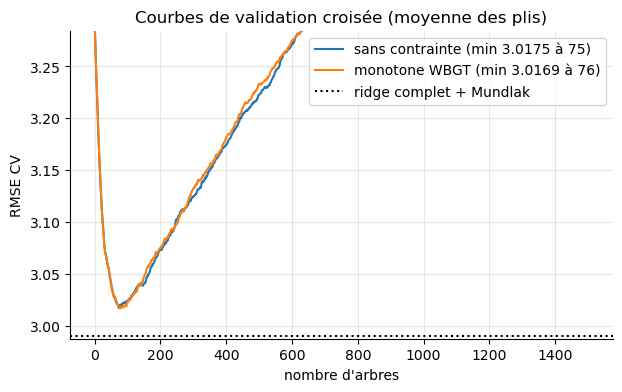

(8 s)


In [53]:
t0 = time.time()
res_gbm = {}
for nom, mono in [("sans contrainte", None), ("monotone WBGT", {"wbgt": 1})]:
    n, r, courbe = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1500, monotone=mono)
    res_gbm[nom] = (n, r, courbe)
    print(f"{nom:16s} : n* = {n:4d} arbres, RMSE CV = {r:.5f}")
plt.figure(figsize=(7, 4))
for nom, (n, r, courbe) in res_gbm.items():
    plt.plot(np.arange(1, len(courbe) + 1), courbe, label=f"{nom} (min {r:.4f} à {n})")
plt.axhline(RESULTATS_CV["ridge complet + Mundlak"]["rmse"].mean(), color="k", ls=":", label="ridge complet + Mundlak")
plt.xlabel("nombre d'arbres"); plt.ylabel("RMSE CV"); plt.ylim(None, np.min([c[2][0] for c in res_gbm.values()]))
plt.legend(); plt.title("Courbes de validation croisée (moyenne des plis)"); plt.show()
print(f"({time.time() - t0:.0f} s)")

**Analyse.**

| modèle | nombre d'arbres $n^\star$ | RMSE CV |
|---|---|---|
| LightGBM sans contrainte | 75 | 3,017 |
| LightGBM monotone en WBGT | 76 | 3,017 |
| *rappel* : ridge complet + Mundlak (partie 3) | – | 2,990 |
| *rappel* : ridge le plus simple, degré 1 (partie 3) | – | 2,996 |
| *rappel* : modèle mixte retenu (partie 4) | – | 3,013 |
| *rappel* : modèle constant (partie 3) | – | 3,300 |

**La contrainte de monotonie ne coûte rien.** Le modèle monotone obtient 3,0169 contre 3,0175 sans
contrainte : il fait même très légèrement mieux, avec un nombre d'arbres presque identique. Imposer que la
chaleur ne fasse jamais courir plus vite ne contredit donc pas les données ; la contrainte agit au plus
comme une légère régularisation. C'est un résultat important pour la suite : on peut imposer cette
connaissance physiologique sans perte de précision.

**Le boosting ne fait pas mieux que les modèles linéaires.** Avec 3,017, le LightGBM fait jeu égal avec le
modèle mixte (3,013) et légèrement moins bien que le ridge (2,990 à 2,996). Tous ces écarts sont inférieurs
à 0,03, alors que l'erreur type entre plis vaut environ 0,19 (partie 2.5) : les modèles sont équivalents en
prédiction. La flexibilité des arbres n'apporte rien de mesurable. Le signal qui se transpose d'un lieu à
l'autre est donc essentiellement **lisse et proche de l'additif** (effets de l'âge, du niveau, de la forme,
de la durée), ce que les modèles linéaires captent déjà. Les non-linéarités et interactions que les arbres
pourraient découvrir sont soit absentes, soit trop faibles pour être distinguées du bruit avec quelque 300
courses.

**La forme de la courbe de validation.** Les deux courbes tombent rapidement pendant les premières dizaines
d'arbres, atteignent leur minimum vers **75 arbres**, puis **remontent régulièrement** : vers 600 arbres, la
RMSE dépasse 3,25 et rejoint la valeur obtenue avec un seul arbre (le haut de la figure). Avec un taux d'apprentissage de 0,03, 75 arbres correspondent à peu près au nombre
nécessaire pour capter l'essentiel d'un signal simple (partie 5.1) : le modèle s'arrête dès qu'il a appris
les régularités générales. Au-delà, chaque arbre apprend des particularités des lieux d'apprentissage, qui
ne se transposent pas aux lieux de validation : c'est le sur-apprentissage, et il est rapide. Les courbes
restent toujours au-dessus de la ligne du ridge. La forte remontée confirme l'intérêt de choisir le nombre
d'arbres par validation croisée : au-delà de 600 arbres, un modèle trop entraîné fait moins bien qu'un
modèle presque constant.

### 5.4 Le WBGT résume-t-il bien la météo ? Que coûte une validation mal construite ?

Deux expériences complètent l'étude du boosting, avec les paramètres de base et un nombre d'arbres choisi à
chaque fois par la courbe de validation croisée.

**Expérience 1 : quelles variables météorologiques ?** On compare quatre jeux de variables, les autres
variables de contexte restant les mêmes :

| jeu de variables | variables météorologiques |
|---|---|
| WBGT (+ vent, pluie) | WBGT, vent, pluie, WBGT moyen du parcours |
| composantes brutes | température de l'air, humidité, vent, rayonnement, pluie, WBGT moyen du parcours |
| WBGT + composantes | WBGT, vent, pluie, température, humidité, rayonnement, WBGT moyen du parcours |
| sans météo | aucune (ni vent, ni pluie, ni terme de Mundlak) |

La partie 1.2 a montré que le WBGT combine ses composantes de façon très différente selon le type de course
(réunions de piste chaudes et sèches, marathons frais mais ensoleillés et humides). Deux hypothèses
s'opposent. Si le résumé physique du WBGT perd de l'information utile (par exemple si l'humidité pèse plus
que ne le dit la formule), les composantes brutes devraient mieux prédire. Si au contraire le résumé est
pertinent, il devrait faire au moins aussi bien avec moins de variables, donc moins de façons de
sur-apprendre. Le modèle « sans météo » mesure l'apport total de la météo à la prédiction.

**Expérience 2 : quel découpage de validation ?** On compare, pour le même modèle, la validation croisée par
lieux et une validation croisée **aléatoire** à cinq plis sur les lignes. La partie 2.1 a montré qu'un
découpage aléatoire place 77 des 79 lieux, et la plupart des parcours et des courses, des deux côtés. On
mesure ici ce que cette fuite fait à l'erreur annoncée et au nombre d'arbres choisi.

In [54]:
METEO_BRUTE = ["t_air", "hr", "vent_10m", "rayonnement_global", "precipitation_mm_h"]
variantes = {"WBGT (+ vent, pluie)": NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK,
             "composantes brutes": NUM_CONTEXTE + METEO_BRUTE + NUM_MUNDLAK,
             "WBGT + composantes": NUM_CONTEXTE + NUM_METEO + METEO_BRUTE[:2] + ["rayonnement_global"] + NUM_MUNDLAK,
             "sans météo": NUM_CONTEXTE}
tab_var = []
for nom, num in variantes.items():
    n, r, _ = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, num, CAT_GBM, n_max=1200)
    tab_var.append({"variables": nom, "n*": n, "RMSE CV": r})
print(pd.DataFrame(tab_var).round(5).to_string(index=False))

from sklearn.model_selection import KFold
plis_aleatoires = list(KFold(5, shuffle=True, random_state=SEED).split(df_train))
n_alea, r_alea, _ = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, plis_aleatoires, NUM_GBM, CAT_GBM, n_max=1500)
print(f"\nK-fold aléatoire : n* = {n_alea}, RMSE CV = {r_alea:.5f}  |  par lieux : n* = {res_gbm['sans contrainte'][0]}, "
      f"RMSE CV = {res_gbm['sans contrainte'][1]:.5f}")

           variables  n*  RMSE CV
WBGT (+ vent, pluie)  75  3.01748
  composantes brutes  97  3.00832
  WBGT + composantes  85  3.00827
          sans météo  82  3.01408



K-fold aléatoire : n* = 1498, RMSE CV = 2.37776  |  par lieux : n* = 75, RMSE CV = 3.01748


**Analyse.**

| jeu de variables | $n^\star$ | RMSE CV |
|---|---|---|
| WBGT (+ vent, pluie) | 75 | 3,017 |
| composantes brutes | 97 | 3,008 |
| WBGT + composantes | 85 | 3,008 |
| sans météo | 82 | 3,014 |

**La météo n'améliore pas la prédiction.** Les quatre jeux de variables tiennent en 0,01 de RMSE (de 3,008
à 3,017), et le modèle **sans aucune variable météorologique** (3,014) fait aussi bien que le modèle avec le
WBGT (3,017). Les composantes brutes font très légèrement mieux que le WBGT (0,009), mais cet écart est vingt
fois plus petit que l'erreur type entre plis (environ 0,19) : il ne permet de conclure ni que le WBGT perd de
l'information, ni qu'il en résume bien. Sur ces données et ce découpage, on ne peut pas départager les jeux
de variables par leur pouvoir prédictif.

**Pourquoi un effet réel peut ne rien apporter en prédiction.** Ce résultat ne contredit pas l'effet de la
chaleur estimé en partie 4 (environ 2 points de $y$ pour 10 °C). Il illustre la différence entre **estimer un
effet** et **améliorer une prédiction**. Un ordre de grandeur le montre. Si la chaleur agit avec une pente
$b \approx 0{,}2$ point par °C, et si le WBGT varie avec un écart-type d'environ 4,4 °C, la variance de $y$ due à
la chaleur vaut au plus $b^2\,\text{Var}(W) \approx 0{,}04 \times 19{,}5 \approx 0{,}8$. Rapportée à une variance
résiduelle d'environ $3^2 = 9$, elle ferait baisser la RMSE d'au plus $0{,}8/(2 \times 3) \approx 0{,}13$, et
seulement si l'effet était connu parfaitement. Le gain réel est bien plus faible, pour trois raisons :

* une grande partie de la variation du WBGT est **déjà expliquée** par le groupe d'épreuves et l'heure
  (piste chaude le soir, marathon frais le matin) : ce qui reste à expliquer par la météo est la variation
  du WBGT à épreuve et heure données, plus faible ;
* l'effet est **hétérogène** : fort au marathon, nul en demi-fond, où se trouvent la moitié des courses
  chaudes (partie 1.2) ;
* l'effet est **estimé** à partir de quelque 300 courses, dont peu de courses chaudes : l'erreur d'estimation
  ajoute de la variance aux prédictions et absorbe une partie du gain.

Un gain potentiel de quelques centièmes, noyé dans une variabilité entre plis de 0,19, est invisible en
validation croisée. La qualité de l'outil se jugera donc sur l'**estimation de l'effet** et sur son
incertitude (parties 4 et 8), pas sur la RMSE : c'est ce qu'annonçait la partie 2.2.

**Les plis aléatoires annoncent une performance illusoire.**

| validation | $n^\star$ | RMSE CV |
|---|---|---|
| K-fold aléatoire sur les lignes | 1 498 | 2,378 |
| K-fold par lieux | 75 | 3,017 |

Avec des plis aléatoires, la RMSE annoncée tombe à **2,378**, soit une performance surestimée de 21 %, et le
nombre d'arbres retenu atteint **1 498**, à la limite de la recherche ($n_{\max} = 1\,500$) : vingt fois plus
qu'avec les plis par lieux, et sans doute davantage si la recherche avait continué. L'explication tient à
la structure des données. Avec des plis aléatoires, chaque course a des coureurs en apprentissage et en
validation. Le modèle peut alors **mémoriser l'effet propre de chaque course** (sa date, son lieu, sa météo,
son plateau, son déroulement) et le restituer aux coureurs de la même course en validation. Plus il ajoute
d'arbres, plus il mémorise finement, et plus il « prédit » bien : la courbe de validation ne remonte plus,
d'où le nombre d'arbres maximal.

Un modèle sélectionné ainsi serait doublement trompeur : sa performance annoncée serait fausse, et son
nombre d'arbres, choisi pour mémoriser, le rendrait fortement sur-ajusté et décevant sur un lieu nouveau,
c'est-à-dire exactement dans l'usage prévu de l'outil (la courbe par lieux de la partie 5.3 montre ce que
coûtent 1 500 arbres sur des lieux nouveaux). C'est la confirmation empirique de la fuite d'information
décrite en partie 2.1.

## Partie 6 — Réseau de neurones

Les parties précédentes ont utilisé deux grandes familles de modèles : des modèles **linéaires** (parties 3
et 4), dont la forme est fixée à l'avance, et des **arbres** (partie 5), flexibles mais en marches
d'escalier. Les **réseaux de neurones** forment une troisième famille, flexible comme les arbres mais
produisant des fonctions **lisses**. Cette partie les présente sans supposer aucune connaissance préalable :
ce qu'ils sont, ce qu'ils peuvent représenter, comment ils apprennent, et ce qu'ils valent sur un problème
comme le nôtre.

### 6.1 Qu'est-ce qu'un réseau de neurones ?

#### À quoi sert un réseau de neurones

Comme tous les modèles de cette étude, un réseau de neurones est une **fonction paramétrée** $f_\theta$ qui
associe une prédiction $\hat y = f_\theta(x)$ à un vecteur de variables $x$. Ses paramètres $\theta$ sont
appris en minimisant une perte sur des exemples (partie 0.5). Sa particularité est d'appartenir à une
famille de fonctions **très riche** : avec assez de paramètres, il peut représenter presque n'importe quelle
relation entre $x$ et $y$, sans qu'on ait à en préciser la forme (droite, polynôme, interactions). On ne lui
dit pas « l'effet de l'âge est quadratique » : il le découvre.

Les réseaux de neurones sont à l'origine des progrès récents en reconnaissance d'images, en traduction
automatique, en reconnaissance de la parole ou en génération de texte : des problèmes où les données sont
**massives** (des millions d'exemples) et **non structurées** (des pixels, des mots), et où personne ne sait
écrire à la main la forme de la relation. Ils s'appliquent aussi aux données **tabulaires** comme les
nôtres (un tableau de lignes et de colonnes), mais avec moins de succès, comme on le verra.

#### Le neurone artificiel

L'unité de base est le **neurone** : il calcule une combinaison linéaire de ses entrées, puis lui applique
une fonction non linéaire $\sigma$, appelée **activation** :

$$h = \sigma\Big(\sum_{r=1}^{d} w_r\,x_r + b\Big) = \sigma(w^\top x + b).$$

Les $w_r$ sont les **poids**, $b$ le **biais** (une constante). Dans cette partie, $\sigma$ désigne une fonction
d'activation, et non plus un écart-type. Le nom vient d'une analogie lointaine avec le
neurone biologique, qui s'active quand la somme de ses signaux d'entrée dépasse un seuil. Deux cas
particuliers montrent qu'un neurone n'a rien de mystérieux : si $\sigma$ est l'identité, un neurone est
exactement une **régression linéaire** ; si $\sigma$ est la sigmoïde $1/(1 + e^{-z})$, c'est une
**régression logistique**.

#### Les couches

Un réseau assemble des neurones en **couches**. Une couche de $m$ neurones qui reçoivent tous le même vecteur
d'entrée $h \in \mathbb{R}^{d}$ s'écrit en notation matricielle :

$$h' = \sigma(W h + b), \qquad W \in \mathbb{R}^{m \times d},\ b \in \mathbb{R}^{m},$$

où chaque ligne de $W$ contient les poids d'un neurone et $\sigma$ s'applique composante par composante. Le
**perceptron multicouche** (MLP) enchaîne plusieurs couches : la sortie de l'une est l'entrée de la suivante.

$$h_0 = x, \qquad h_k = \sigma(W_k\, h_{k-1} + b_k) \ \ (k = 1, \dots, L), \qquad \hat y = w_{L+1}^\top h_L + b_{L+1} .$$

Les couches intermédiaires sont dites **cachées** : on n'observe ni leurs entrées ni leurs sorties, seulement
$x$ et $y$. Le nombre de neurones d'une couche est sa **largeur**, le nombre de couches la **profondeur** du
réseau. Une couche qui reçoit $d$ entrées et compte $m$ neurones a $(d + 1) \times m$ paramètres (les poids
et un biais par neurone) : le nombre de paramètres croît vite avec la largeur.

#### Pourquoi une activation non linéaire

Sans activation, un réseau ne serait qu'une **régression linéaire déguisée** : la composition de deux
fonctions affines est affine,

$$W_2(W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2),$$

et empiler des couches ne servirait à rien. C'est l'activation qui donne au réseau sa capacité à représenter
des relations non linéaires. Les plus courantes sont :

| activation | formule | propriétés |
|---|---|---|
| sigmoïde | $1/(1 + e^{-z})$ | lisse, à valeurs dans $(0, 1)$ ; sa dérivée est très faible pour $\lvert z \rvert$ grand, ce qui ralentit l'apprentissage des réseaux profonds |
| ReLU | $\max(0, z)$ | très simple, dérivée 0 ou 1 ; le réseau est alors une fonction affine par morceaux |
| SiLU | $z\,\sigma(z)$ | proche de ReLU, mais lisse et dérivable partout : le réseau est une fonction lisse |

**Une intuition géométrique.** Avec l'activation ReLU, chaque neurone de la première couche « plie » l'espace
le long de l'hyperplan $w^\top x + b = 0$ : il vaut 0 d'un côté et croît linéairement de l'autre. En une
dimension, une somme de neurones $\sum_k c_k \max(0, x - s_k)$ est une **ligne brisée** dont les coudes sont
placés en $s_k$ et dont les pentes changent de $c_k$ à chaque coude. Avec assez de coudes, une ligne brisée
approche n'importe quelle courbe continue : c'est l'idée du théorème suivant.

#### Ce qu'un réseau peut représenter : le théorème d'approximation universelle

> **Théorème** (Cybenko, 1989 ; Hornik, 1991 ; Leshno *et al.*, 1993). Soit $\sigma$ une fonction d'activation
> continue et non polynomiale. Pour toute fonction continue $g$ définie sur un compact $K \subset \mathbb{R}^d$ et
> pour tout $\varepsilon > 0$, il existe un réseau à **une seule couche cachée**, avec un nombre fini $N$ de
> neurones,
> $$f_N(x) = \sum_{k=1}^{N} c_k\,\sigma(w_k^\top x + b_k),$$
> tel que $\sup_{x \in K} \lvert g(x) - f_N(x) \rvert < \varepsilon$.

Ce théorème dit qu'aucune relation continue n'est hors de portée d'un réseau assez large. Il faut aussi
savoir ce qu'il **ne dit pas** :

* il garantit l'**existence** de poids qui conviennent, mais ne dit pas comment les **trouver** : l'apprentissage
  est un problème d'optimisation difficile (ci-dessous) ;
* le nombre de neurones nécessaire peut être **gigantesque** ;
* il porte sur l'approximation d'une fonction **connue** sur tout $K$, pas sur l'apprentissage à partir d'un
  **échantillon fini** et bruité : un réseau capable de tout représenter est aussi capable de représenter le
  bruit, c'est-à-dire de **sur-apprendre** ;
* il ne dit rien du comportement **hors** du domaine $K$ : un réseau n'extrapole pas de façon fiable.

**Largeur ou profondeur ?** Le théorème n'utilise qu'une couche cachée, mais la profondeur est souvent plus
économe : certaines fonctions exigent un nombre exponentiel de neurones avec une seule couche, et seulement
un nombre polynomial avec plusieurs couches (Telgarsky, 2016). Chaque couche peut construire des
caractéristiques plus élaborées à partir de celles de la couche précédente.

#### Comment un réseau apprend : optimisation et rétropropagation

**Un problème d'optimisation non convexe.** On cherche les paramètres $\theta$ (toutes les matrices $W_k$ et
tous les biais) qui minimisent le risque empirique, ici l'erreur quadratique moyenne
$\hat{\mathcal R}(\theta) = \frac1n\sum_i (y_i - f_\theta(x_i))^2$. Contrairement aux moindres carrés (partie
3.2), il n'existe pas de formule fermée, et la fonction à minimiser n'est **pas convexe** : elle a de nombreux
minima locaux et points-selles. On procède par **descente de gradient** : on part de poids tirés au hasard,
et l'on avance pas à pas dans la direction opposée au gradient,

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \hat{\mathcal R}(\theta),$$

où $\eta$ est le **taux d'apprentissage**. Trop grand, les pas font diverger l'optimisation ; trop petit,
elle est très lente. Rien ne garantit d'atteindre le minimum global, mais en pratique les minima atteints
par cette procédure sont souvent bons. Le résultat dépend toutefois du tirage initial des poids : deux
apprentissages avec des graines différentes donnent deux réseaux différents.

**La rétropropagation.** Il faut calculer le gradient de la perte par rapport à des milliers de paramètres.
La **rétropropagation** le fait efficacement par la règle de dérivation en chaîne, appliquée couche par couche
de la sortie vers l'entrée. Prenons un réseau à une couche cachée, $z = W_1 x + b_1$, $h = \sigma(z)$,
$\hat y = w_2^\top h + b_2$, et la perte d'une observation $\ell = \frac12(\hat y - y)^2$. En notant
$\delta = \hat y - y$ l'erreur de prédiction :

$$\frac{\partial \ell}{\partial b_2} = \delta, \qquad
  \frac{\partial \ell}{\partial w_2} = \delta\,h, \qquad
  \frac{\partial \ell}{\partial h} = \delta\,w_2, \qquad
  \frac{\partial \ell}{\partial z} = (\delta\,w_2) \odot \sigma'(z), \qquad
  \frac{\partial \ell}{\partial W_1} = \frac{\partial \ell}{\partial z}\,x^\top, \qquad
  \frac{\partial \ell}{\partial b_1} = \frac{\partial \ell}{\partial z},$$

où $\odot$ est le produit composante par composante. On voit le mécanisme : l'erreur $\delta$ est
**propagée en arrière** à travers les poids $w_2$, puis multipliée par la dérivée de l'activation. Le calcul
réutilise les quantités de la passe avant ($h$, $z$) et coûte à peu près autant qu'une prédiction. PyTorch
l'automatise : il enregistre les opérations de la passe avant (le « graphe de calcul ») et calcule tous les
gradients par `backward()`. On comprend aussi pourquoi la sigmoïde gêne les réseaux profonds : sa dérivée,
inférieure à 1/4, est multipliée une fois par couche, et le gradient s'éteint en remontant.

#### Le risque principal : le sur-apprentissage

Un réseau a beaucoup de paramètres. Celui de la démonstration de la partie 6.5 en compte environ 11 000,
pour quelque 6 400 performances d'apprentissage : plus de paramètres que d'observations. Un tel réseau peut,
en principe, mémoriser les données d'apprentissage, bruit compris. Il faut donc le **régulariser**
(partie 6.4) et choisir sa complexité par validation croisée, comme les autres modèles.

#### Quand utiliser un réseau de neurones ?

| | avantages | inconvénients |
|---|---|---|
| **flexibilité** | approche toute relation continue (théorème d'approximation) ; interactions découvertes automatiquement | risque élevé de sur-apprentissage, surtout avec peu de données |
| **forme de la fonction** | fonction **lisse** (avec SiLU), adaptée à des effets réguliers | n'extrapole pas de façon fiable hors des données |
| **données** | passe à l'échelle sur des millions d'exemples ; traite images, textes, sons | demande beaucoup de données pour dépasser des modèles plus simples |
| **variables catégorielles** | *embeddings* compacts, même pour des milliers de modalités (partie 6.2) | |
| **réglage** | souple : perte, architecture, contraintes peuvent être adaptées | nombreux hyperparamètres sensibles (taux d'apprentissage, architecture, régularisation) ; standardisation indispensable |
| **reproductibilité** | | optimisation non convexe : le résultat dépend des graines aléatoires |
| **interprétation** | | « boîte noire » : les poids n'ont pas d'interprétation directe (partie 8) |
| **coût** | | apprentissage plus long que les modèles linéaires ou le boosting sur petites données |

Sur des **données tabulaires de taille modeste**, comme les nôtres (environ 8 000 performances et une
quinzaine de variables), les réseaux de neurones ne font généralement **pas mieux** que le gradient boosting
ou des modèles linéaires bien spécifiés (Grinsztajn *et al.*, 2022). Notre attente est donc mesurée : le
réseau sert ici de point de comparaison, et sa forme lisse pourrait convenir à des effets réguliers comme
ceux de l'âge, du niveau ou du WBGT, que les arbres découpent en marches.

### 6.2 Les variables catégorielles : *embeddings*

Un réseau ne traite que des nombres. Pour une variable catégorielle (groupe d'épreuves, sexe), la partie 2.4
utilisait l'encodage **one-hot** : une colonne 0/1 par modalité. Les réseaux de neurones utilisent plutôt des
**embeddings**.

**Définition.** Un *embedding* associe à chaque modalité $m$ un vecteur **appris** $e_m \in \mathbb{R}^{d_e}$, rangé
dans une table $E$ (une ligne par modalité). Le réseau reçoit $e_m$ à la place de la modalité. C'est
équivalent à multiplier l'encodage *one-hot* de la modalité par la matrice $E$,

$$e_m = E^\top\,\mathbb 1_m, \qquad \mathbb 1_m = (0, \dots, 0, 1, 0, \dots, 0),$$

c'est-à-dire à une première couche linéaire sans biais appliquée au *one-hot*, mais implémenté comme une
simple lecture dans une table. Les vecteurs sont appris en même temps que le reste du réseau, par
rétropropagation : deux modalités qui ont des effets proches finissent avec des vecteurs proches.

**Intérêt.** Pour une variable à très nombreuses modalités (des milliers de produits, de mots, de clients),
l'encodage *one-hot* produirait des milliers de colonnes ; un *embedding* de dimension 8 ou 16 les résume en un
vecteur dense, qui partage l'information entre modalités semblables. Ici, les variables catégorielles n'ont
que 5 et 2 modalités : l'*embedding* n'apporte pas grand-chose par rapport au *one-hot*, mais c'est la façon
standard de les traiter dans un réseau. La dimension de l'*embedding* est plafonnée par le nombre de
modalités : un vecteur de dimension 4 pour une variable à 3 modalités n'apporterait aucune information de
plus.

**Le codage des modalités.** Pour lire la table, chaque modalité doit être codée par un entier. Ce codage est
**appris sur l'apprentissage**, comme le reste du prétraitement (partie 2.4) : les modalités vues reçoivent les
entiers $1, 2, \dots$ (dans l'ordre alphabétique), et l'entier **0 est réservé aux modalités inconnues**, vues
seulement en validation ou en test. La table a donc une ligne de plus que le nombre de modalités vues (la
« cardinalité » comprend la modalité inconnue). Recalculer le codage sur le test serait une erreur : les
entiers ne désigneraient plus les mêmes modalités, et le réseau lirait la mauvaise ligne de la table.

Le test vérifie ce comportement : avec les modalités « x » et « y » vues à l'apprentissage, « y » reçoit le
code 2, la modalité inconnue « z » le code 0, et la cardinalité vaut 3.

In [55]:
class EncodeurCategories:
    '''Code chaque modalité vue au fit par un entier >= 1 ; 0 = inconnue.

    Après fit : modalites_ (dict col -> dict modalite -> code), cardinalites_ (liste, inconnue comprise)
    '''

    def __init__(self, colonnes):
        self.colonnes = list(colonnes)

    def fit(self, df):
        self.modalites_ = {c: {m: k + 1 for k, m in enumerate(sorted(df[c].astype(str).unique()))}
                           for c in self.colonnes}
        self.cardinalites_ = [len(self.modalites_[c]) + 1 for c in self.colonnes]
        return self

    def transform(self, df):
        '''Sortie : np.ndarray int64 (n, nb_colonnes).'''
        return np.column_stack([df[c].astype(str).map(self.modalites_[c]).fillna(0).to_numpy(dtype=np.int64)
                                for c in self.colonnes])

In [56]:
#test
_e = EncodeurCategories(["a"]).fit(pd.DataFrame({"a": ["x", "y", "x"]}))
assert _e.cardinalites_ == [3] and _e.transform(pd.DataFrame({"a": ["y", "z"]})).tolist() == [[2], [0]]
print("EncodeurCategories : OK")

EncodeurCategories : OK


### 6.3 Architecture du réseau

Notre réseau est un perceptron multicouche dont l'entrée concatène les variables numériques standardisées
$x^{\text{num}}$ et un *embedding* par variable catégorielle :

$$h_0 = [x^{\text{num}},\ e_{\text{groupe}},\ e_{\text{sexe}}],\qquad
  h_k = \text{Dropout}\big(\text{SiLU}(W_k\, h_{k-1} + b_k)\big),\qquad \hat y = w_{L+1}^\top h_L + b_{L+1} .$$

* **Les entrées.** Les variables numériques sont celles du boosting : niveau, âge, forme, durée, altitude,
  heure, WBGT, vent, pluie et WBGT moyen du parcours, plus les indicatrices de manquant de l'âge et de la
  forme, soit 12 colonnes. L'*embedding* du groupe d'épreuves (5 modalités et la modalité inconnue) est de
  dimension 4, celui du sexe (2 modalités et l'inconnue) de dimension 3. L'entrée $h_0$ a donc 19 composantes.
* **Les couches cachées.** Leur nombre et leur largeur sont des hyperparamètres : deux couches de 64 et 32
  neurones par défaut, de 128 et 64 dans les expériences ci-dessous.
* **L'activation SiLU**, $\text{SiLU}(z) = z\,\sigma(z)$, de dérivée $\sigma(z)\big(1 + z\,(1 - \sigma(z))\big)$,
  est lisse : la fonction apprise l'est aussi.
* **Le dropout**, appliqué après chaque couche cachée, est présenté en partie 6.4.
* **La sortie** est un seul neurone sans activation : une combinaison linéaire de la dernière couche cachée,
  qui peut prendre n'importe quelle valeur réelle, comme $y$.

**Le nombre de paramètres.** Pour une architecture (128, 64) : $(19 + 1) \times 128 = 2\,560$ paramètres pour la
première couche, $(128 + 1) \times 64 = 8\,256$ pour la seconde, $64 + 1 = 65$ pour la sortie, et
$6 \times 4 + 3 \times 3 = 33$ pour les deux tables d'*embedding*, soit **10 914 paramètres**. Le test construit
un petit réseau (5 variables numériques, catégories de cardinalités 3 et 4, *embeddings* plafonnés à 3 et 4,
couches de 16 et 8 neurones) et vérifie qu'il compte $13 \times 16 + 17 \times 8 + 9 + 9 + 16 = 378$ paramètres.

**Un piège de forme.** La sortie est ramenée à un vecteur de forme $(n,)$ et non $(n, 1)$. Sinon, la
comparaison avec la cible, de forme $(n,)$, serait « diffusée » (*broadcasting*) en une matrice $(n, n)$ de
toutes les différences croisées : la perte serait fausse, sans aucun message d'erreur.

**Exécution.** Le code du réseau est écrit dans le module `reseau_torch.py` (commande `%%writefile`) et exécuté dans le processus PyTorch, de même que son test (partie 0.7).

In [57]:
%%writefile reseau_torch.py
# Module exécuté dans le processus PyTorch (partie 0.7) : PyTorch y est importé en premier.
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

torch.set_num_threads(2)


class ReseauPerf(nn.Module):
    '''MLP avec embeddings. n_num : nb de variables numériques ; cardinalites : liste d'entiers.'''

    def __init__(self, n_num, cardinalites, dim_emb=4, couches=(64, 32), dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, min(dim_emb, c)) for c in cardinalites])
        d = n_num + sum(e.embedding_dim for e in self.embs)
        blocs = []
        for h in couches:
            blocs += [nn.Linear(d, h), nn.SiLU(), nn.Dropout(dropout)]
            d = h
        blocs.append(nn.Linear(d, 1))
        self.mlp = nn.Sequential(*blocs)

    def forward(self, x_num, x_cat):
        '''x_num : (n, n_num) float32 ; x_cat : (n, nb_cat) int64. Sortie : (n,).'''
        z = torch.cat([x_num] + [emb(x_cat[:, k]) for k, emb in enumerate(self.embs)], dim=1)
        return self.mlp(z).squeeze(-1)

Overwriting reseau_torch.py


In [58]:
#test (exécuté dans le processus PyTorch, partie 0.7)
tester('''
torch.manual_seed(0)
_r = ReseauPerf(5, [3, 4], dim_emb=8, couches=(16, 8))
_out = _r(torch.randn(7, 5), torch.tensor([[0, 1]] * 7))
assert _out.shape == (7,) and _r.embs[0].embedding_dim == 3
print("ReseauPerf : OK,", sum(p.numel() for p in _r.parameters()), "paramètres")
''')

ReseauPerf : OK, 378 paramètres


### 6.4 Apprentissage et régularisation

#### Descente de gradient stochastique

Calculer le gradient du risque sur toutes les données à chaque pas serait coûteux. On le calcule plutôt sur
un **mini-lot** de $n_{\text{lot}}$ observations tirées au hasard (ici 128 ou 256) :

$$\theta \leftarrow \theta - \eta\,\nabla_\theta\,\frac{1}{n_{\text{lot}}}\sum_{i \in \text{lot}} (y_i - f_\theta(x_i))^2 .$$

Le gradient d'un mini-lot est un estimateur **sans biais** du gradient complet, plus bruité mais beaucoup
moins coûteux : on fait de nombreux petits pas approximatifs plutôt que quelques grands pas exacts. Ce bruit
aide même à sortir des minima locaux médiocres et des points-selles. Une **époque** est un passage complet sur
les données, en mini-lots tirés dans un ordre aléatoire. Chaque pas comprend quatre opérations : remettre à
zéro les gradients (sinon ils s'accumulent d'un pas à l'autre), calculer la perte du mini-lot, la
rétropropager, et mettre à jour les paramètres.

#### L'optimiseur Adam

Avec un taux d'apprentissage unique, les paramètres dont le gradient est grand avancent trop vite et ceux dont
le gradient est petit trop lentement. L'optimiseur **Adam** (Kingma et Ba, 2015) adapte le pas de chaque
paramètre à partir de deux moyennes mobiles, celle du gradient $g_t$ (une « inertie ») et celle de son carré
(une mesure de son amplitude) :

$$m_t = \beta_1 m_{t-1} + (1 - \beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1 - \beta_2)\,g_t^2,$$

$$\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
  \theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon},$$

avec par défaut $\beta_1 = 0{,}9$ et $\beta_2 = 0{,}999$. Les divisions par $1 - \beta^t$ corrigent le biais dû à
l'initialisation des moyennes à 0 lors des premiers pas. Le rapport $\hat m_t/\sqrt{\hat v_t}$ est de l'ordre de
1 quand le gradient est régulier et plus petit quand il est bruité : chaque paramètre avance d'environ $\eta$
dans une direction stable, et prudemment dans une direction incertaine.

#### Trois régularisations

**Le *weight decay* découplé (AdamW).** À chaque pas, on ajoute $\theta \leftarrow \theta - \eta\,\lambda\,\theta$ :
les poids sont rétrécis vers 0, comme dans une régression ridge (partie 3.2). Avec Adam, cette version
« découplée » (Loshchilov et Hutter, 2019) diffère d'une pénalité $\lambda\lVert\theta\rVert^2$ ajoutée à la
perte : le gradient de la pénalité serait divisé par $\sqrt{\hat v_t}$, et donc appliqué très inégalement aux
paramètres.

**Le *dropout*** (Srivastava *et al.*, 2014). Pendant l'apprentissage, chaque neurone d'une couche cachée est
mis à zéro avec une probabilité $p$, indépendamment à chaque mini-lot, et les neurones conservés sont
multipliés par $1/(1 - p)$ pour que l'espérance de la sortie ne change pas. Le réseau ne peut pas compter sur
un neurone particulier, ni sur une combinaison fragile de neurones : il doit répartir l'information. L'effet est
proche d'une moyenne d'un très grand nombre de sous-réseaux. En prédiction, le *dropout* est désactivé (mode
`eval`) : tous les neurones sont utilisés.

**L'arrêt précoce** (*early stopping*). Au fil des époques, l'erreur d'apprentissage baisse sans cesse, mais
l'erreur sur des données non vues baisse puis remonte quand le réseau commence à sur-apprendre (partie 5.3).
On mesure donc la perte de validation à chaque époque, on garde une **copie** des poids qui l'ont rendue
minimale, et l'on arrête l'apprentissage après un nombre fixé d'époques sans amélioration, la **patience** ; on
recharge alors les meilleurs poids. Deux détails comptent : une amélioration n'est retenue que si elle dépasse
une petite tolérance, et la copie doit être **profonde** (une simple référence pointerait vers les poids
courants, qui continuent d'évoluer, et l'on garderait les poids finaux).

**Reproductibilité.** Les graines de l'initialisation des poids et de l'ordre des mini-lots sont fixées : un
même apprentissage donne toujours le même réseau.

Le test entraîne un petit réseau sur des données simulées ($y = 2x_1 - x_2$) : la perte d'apprentissage doit
être divisée par plus de 5 en 60 époques. Avec une patience de 5 époques, l'apprentissage doit s'arrêter avant
la limite de 500 époques, et les poids rechargés doivent donner exactement la meilleure perte de validation
observée.

**Exécution.** La boucle d'apprentissage complète le module `reseau_torch.py`, et son test s'exécute dans le processus PyTorch (partie 0.7).

In [59]:
%%writefile -a reseau_torch.py


# Suite du module reseau_torch.py (processus PyTorch, partie 0.7).
import copy


def entrainer_reseau(modele, Xn, Xc, y, Xn_val=None, Xc_val=None, y_val=None, lr=1e-3, weight_decay=1e-4,
                     epochs=100, batch_size=256, patience=None, seed=0, tol=1e-6):
    '''Entraîne modele en place. Xn float32 (n, p), Xc int64 (n, q), y float32 (n,) : tenseurs torch.

    Sortie : dict {"train": [pertes], "val": [pertes]} (MSE par époque).
    '''
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(Xn, Xc, y), batch_size=batch_size, shuffle=True, generator=gen)
    perte = nn.MSELoss()
    hist = {"train": [], "val": []}
    meilleur, etat, attente = np.inf, None, 0
    for _ in range(epochs):
        modele.train()
        cumul = 0.0
        for xb, cb, yb in loader:
            opt.zero_grad()
            l = perte(modele(xb, cb), yb)
            l.backward()
            opt.step()
            cumul += l.item() * len(yb)
        hist["train"].append(cumul / len(y))
        if y_val is not None:
            modele.eval()
            with torch.no_grad():
                v = perte(modele(Xn_val, Xc_val), y_val).item()
            hist["val"].append(v)
            if v < meilleur - tol:
                meilleur, etat, attente = v, copy.deepcopy(modele.state_dict()), 0
            else:
                attente += 1
                if patience is not None and attente >= patience:
                    break
    if patience is not None and etat is not None:
        modele.load_state_dict(etat)
    return hist

Appending to reseau_torch.py


In [60]:
#test (exécuté dans le processus PyTorch, partie 0.7)
tester('''
_g = torch.Generator().manual_seed(0)
_Xn = torch.randn(400, 3, generator=_g); _Xc = torch.zeros(400, 1, dtype=torch.long)
_y = (_Xn[:, 0] * 2 - _Xn[:, 1]).float()
_m = ReseauPerf(3, [2], couches=(16,), dropout=0.0)
_h = entrainer_reseau(_m, _Xn[:300], _Xc[:300], _y[:300], _Xn[300:], _Xc[300:], _y[300:], lr=1e-2, epochs=60, batch_size=50)
assert _h["train"][-1] < 0.2 * _h["train"][0] and len(_h["val"]) == 60
_m2 = ReseauPerf(3, [2], couches=(16,), dropout=0.0)
_h2 = entrainer_reseau(_m2, _Xn[:300], _Xc[:300], _y[:300], _Xn[300:], _Xc[300:], _y[300:], lr=1e-2, epochs=500,
                       batch_size=50, patience=5)
_m2.eval()
with torch.no_grad():
    _v = nn.MSELoss()(_m2(_Xn[300:], _Xc[300:]), _y[300:]).item()
assert len(_h2["val"]) < 500 and np.isclose(_v, min(_h2["val"]), rtol=1e-5)
print("entrainer_reseau : OK (arrêt après", len(_h2["val"]), "époques)")
''')

entrainer_reseau : OK (arrêt après 200 époques)


### 6.5 Pipeline, ensemble de réseaux et nombre d'époques

**Le pipeline.** `PipelineReseau` assemble les éléments précédents avec les conventions des autres modèles
(`fit`, `predict`) :

* les variables numériques sont imputées, complétées par les indicatrices de manquant et **standardisées**
  (partie 2.4). C'est indispensable pour un réseau : avec des variables d'échelles très différentes (un âge
  de l'ordre de 30, une pluie de l'ordre de 0,1), les gradients seraient déséquilibrés et l'initialisation des
  poids inadaptée ;
* la **cible est aussi standardisée** (moyenne et écart-type d'apprentissage), puis les prédictions sont
  ramenées à l'échelle de $y$. Le réseau travaille ainsi sur une cible de moyenne 0 et d'écart-type 1, ce qui
  rend adaptés l'initialisation et le taux d'apprentissage par défaut ;
* les catégories sont codées par l'encodeur de la partie 6.2 ;
* `n_modeles` réseaux sont entraînés avec des graines différentes, et leurs prédictions sont **moyennées**.

**Pourquoi un ensemble de réseaux.** Deux réseaux entraînés avec des graines différentes donnent des
prédictions différentes : c'est une source de variance propre à l'optimisation non convexe. Si $n_{\text{mod}}$ prédicteurs
ont chacun une variance $s^2$ et une corrélation $\rho$ deux à deux, leur moyenne a pour variance

$$\text{Var}\Big(\frac{1}{n_{\text{mod}}}\sum_{m=1}^{n_{\text{mod}}} f_m\Big) = \rho\,s^2 + \frac{1 - \rho}{n_{\text{mod}}}\,s^2 ,$$

qui baisse avec $n_{\text{mod}}$ tant que les réseaux ne sont pas parfaitement corrélés. Le biais, lui, ne change pas : un
ensemble réduit la variance sans coût en biais.

**Démonstration du sur-apprentissage.** On entraîne d'abord un réseau assez large (deux couches de 128 et 64
neurones, environ 11 000 paramètres), **sans *dropout* ni *weight decay***, avec un taux d'apprentissage de
$3\cdot 10^{-3}$, sur quatre plis de lieux, en suivant l'erreur sur le cinquième pli (des lieux nouveaux). On
compare deux arrêts : à la fin des 150 époques, et par arrêt précoce avec une patience de 15 époques. La figure
trace les RMSE d'apprentissage et de validation à chaque époque.

**Le nombre d'époques par validation croisée.** Comme pour le boosting (partie 5.3), arrêter sur un pli puis
évaluer sur ce même pli serait optimiste. On enregistre donc la RMSE de validation après chaque époque sur
chaque pli, on **moyenne les courbes**, et l'on retient le minimum de la courbe moyenne. On compare ainsi deux
réglages du même réseau (128, 64), avec un taux d'apprentissage de $10^{-3}$ : sans régularisation, et avec
*dropout* ($p = 0{,}2$) et *weight decay* ($\lambda = 10^{-2}$). Pour limiter le temps de calcul, la recherche
porte sur trois plis sur cinq et 60 époques au plus.

**Exécution.** Toutes ces opérations passent par `PipelineReseau`, qui prétraite les données dans le processus principal et confie l'apprentissage et la prédiction des réseaux au processus PyTorch (partie 0.7).

In [61]:
class PipelineReseau:
    '''Prétraitement + ensemble de ReseauPerf. Mêmes conventions fit(df) / predict(df).

    Le prétraitement s'exécute ici ; l'entraînement et la prédiction des réseaux, dans le processus PyTorch
    (partie 0.7). reseaux_ contient les poids des réseaux, sous forme de tableaux numpy.
    '''

    def __init__(self, num, cat, couches=(64, 32), dropout=0.1, dim_emb=4, lr=1e-3, weight_decay=1e-4,
                 epochs=100, batch_size=256, n_modeles=1, seed=SEED, patience=None):
        self.num, self.cat = list(num), list(cat)
        self.hp = dict(couches=tuple(couches), dropout=dropout, dim_emb=dim_emb)
        self.lr, self.wd, self.epochs, self.bs = lr, weight_decay, int(epochs), int(batch_size)
        self.n_modeles, self.seed, self.patience = n_modeles, seed, patience

    def _tableaux(self, df, avec_y=True):
        """Tableaux numpy envoyés au processus PyTorch (partie 0.7)."""
        Xn = self.pre_.transform(df).astype(np.float32)
        Xc = self.enc_.transform(df).astype(np.int64)
        y = ((df[CIBLE].to_numpy() - self.my_) / self.sy_).astype(np.float32) if avec_y else None
        return Xn, Xc, y

    def fit(self, df, df_eval=None):
        self.pre_ = Preprocesseur(self.num, []).fit(df)
        self.enc_ = EncodeurCategories(self.cat).fit(df)
        self.my_, self.sy_ = float(df[CIBLE].mean()), float(df[CIBLE].std())
        Xn, Xc, y = self._tableaux(df)
        ev = self._tableaux(df_eval) if df_eval is not None else (None, None, None)
        # entraînement des n_modeles réseaux dans le processus PyTorch : on récupère leurs poids (tableaux numpy)
        self.reseaux_, self.historiques_ = executer(
            "entrainer_ensemble", Xn, Xc, y, *ev, cardinalites=self.enc_.cardinalites_, hp=self.hp, lr=self.lr,
            weight_decay=self.wd, epochs=self.epochs, batch_size=self.bs, patience=self.patience,
            n_modeles=self.n_modeles, seed=self.seed)
        if df_eval is not None:   # courbe de RMSE de validation (unités de y), moyenne sur l'ensemble
            self.courbe_ = np.sqrt(np.mean([np.array(h["val"]) for h in self.historiques_], axis=0)) * self.sy_
        return self

    def predict(self, df):
        Xn, Xc, _ = self._tableaux(df, avec_y=False)
        # prédiction de l'ensemble dans le processus PyTorch, à partir des poids conservés ici
        p = executer("predire_ensemble", self.reseaux_, Xn, Xc, cardinalites=self.enc_.cardinalites_, hp=self.hp)
        return p * self.sy_ + self.my_


NUM_NN = NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK
CAT_NN = CAT_CONTEXTE

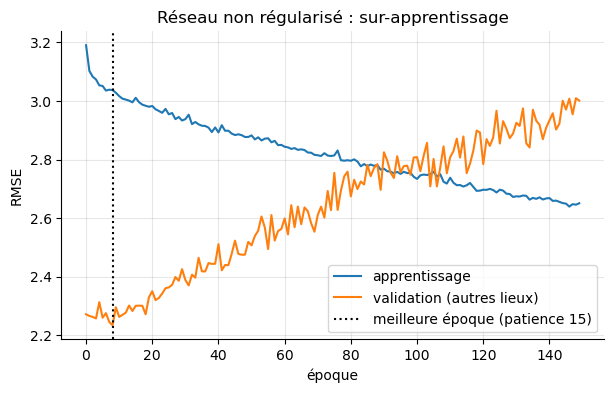

RMSE validation : fin d'entraînement 3.0015 | early stopping 2.2350   (8 s)


In [62]:
t0 = time.time()
_a, _v = df_train.iloc[PLIS[0][0]], df_train.iloc[PLIS[0][1]]
demo = PipelineReseau(NUM_NN, CAT_NN, couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=3e-3, epochs=150).fit(_a, _v)
demo_es = PipelineReseau(NUM_NN, CAT_NN, couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=3e-3, epochs=150,
                         patience=15).fit(_a, _v)
h = demo.historiques_[0]
plt.figure(figsize=(7, 4))
plt.plot(np.sqrt(h["train"]) * demo.sy_, label="apprentissage")
plt.plot(np.sqrt(h["val"]) * demo.sy_, label="validation (autres lieux)")
plt.axvline(len(demo_es.historiques_[0]["val"]) - 16, color="k", ls=":", label="meilleure époque (patience 15)")
plt.xlabel("époque"); plt.ylabel("RMSE"); plt.legend(); plt.title("Réseau non régularisé : sur-apprentissage")
plt.show()
print(f"RMSE validation : fin d'entraînement {rmse(_v[CIBLE], demo.predict(_v)):.4f} | "
      f"early stopping {rmse(_v[CIBLE], demo_es.predict(_v)):.4f}   ({time.time() - t0:.0f} s)")

**Analyse.** La figure montre la signature typique du **sur-apprentissage** :

| | époque 1 | meilleure époque de validation (9) | époque 150 |
|---|---|---|---|
| RMSE d'apprentissage (quatre plis) | 3,19 | environ 3,04 (lecture graphique) | 2,65 |
| RMSE de validation (pli 0, 14 lieux nouveaux) | 2,27 | **2,24** | 3,00 |

* La RMSE d'**apprentissage** baisse sans interruption, de 3,19 à 2,65 : le réseau s'ajuste de mieux en mieux
  aux lieux qu'il voit.
* La RMSE de **validation** atteint son minimum dès la **9e époque** (2,24), puis remonte presque linéairement
  jusqu'à 3,00 à la 150e époque. À partir de là, chaque époque améliore l'ajustement aux lieux d'apprentissage
  au détriment des lieux nouveaux : les deux courbes divergent. Avec environ 11 000 paramètres pour 6 435
  performances d'apprentissage, le réseau a largement de quoi mémoriser le bruit et les particularités de chaque
  lieu, et c'est ce qu'il fait après la 9e époque.
* L'**arrêt précoce** (patience de 15 époques) interrompt l'apprentissage à la 24e époque et recharge les poids
  de la 9e : la RMSE de validation vaut alors **2,235**, contre **3,002** à la fin de l'apprentissage. Le
  sur-apprentissage coûte donc 0,77 point de RMSE (+34 %). Sans arrêt précoce, le réseau fait même nettement
  moins bien que le modèle constant sur ce pli (2,647, partie 3.1).

**Pourquoi l'erreur de validation est-elle d'abord inférieure à l'erreur d'apprentissage ?** Ce n'est pas un
paradoxe. Le pli 0 est le plus « facile » des cinq : le modèle constant y obtient 2,65, contre 3,30 en moyenne
(partie 3.1). Ses lieux ont des performances moins dispersées. Les erreurs ne se comparent donc qu'au sein d'un
même pli, et c'est leur **évolution** qui compte.

**Une réserve.** La valeur 2,235 est optimiste : l'époque d'arrêt a été choisie sur ce même pli, au point le
plus bas d'une courbe bruitée (partie 5.3). C'est pourquoi le nombre d'époques est choisi ci-dessous par la
courbe de validation croisée moyenne.

In [63]:
def courbe_cv_reseau(hp, df, plis, num=NUM_NN, cat=CAT_NN, epochs=150):
    '''hp : dict d'hyperparamètres de PipelineReseau. Sortie : (n_epochs*, rmse_cv*, courbe moyenne).'''
    courbes = []
    for itr, iva in plis:
        m = PipelineReseau(num, cat, epochs=epochs, **hp).fit(df.iloc[itr], df_eval=df.iloc[iva])
        courbes.append(m.courbe_)
    moyenne = np.mean(courbes, axis=0)
    k = int(np.argmin(moyenne))
    return k + 1, float(moyenne[k]), moyenne

In [64]:
#test
_n, _r, _c = courbe_cv_reseau({"couches": (16,), "lr": 1e-3}, df_train, PLIS, epochs=5)
assert len(_c) == 5 and 1 <= _n <= 5 and np.isclose(_r, _c.min())
print("courbe_cv_reseau : OK")

courbe_cv_reseau : OK


non régularisé                   : époques* =   4, RMSE CV = 2.93736


dropout 0.2 + weight decay 1e-2  : époques* =  14, RMSE CV = 2.92631


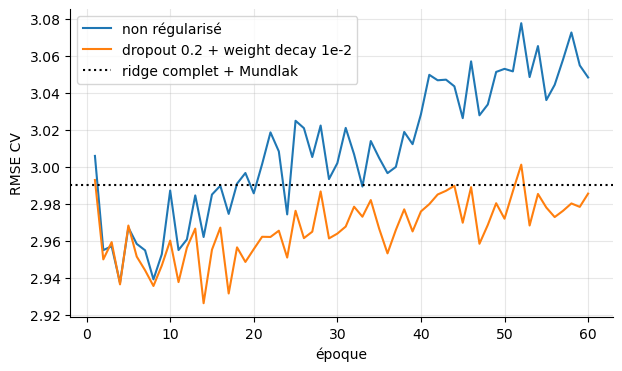

(17 s)


In [65]:
t0 = time.time()
reglages_nn = {"non régularisé": dict(couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=1e-3),
               "dropout 0.2 + weight decay 1e-2": dict(couches=(128, 64), dropout=0.2, weight_decay=1e-2, lr=1e-3)}
res_nn = {}
for nom, hp in reglages_nn.items():
    res_nn[nom] = courbe_cv_reseau(hp, df_train, PLIS[:3], epochs=60)   # 3 plis sur 5 : budget de calcul
    print(f"{nom:32s} : époques* = {res_nn[nom][0]:3d}, RMSE CV = {res_nn[nom][1]:.5f}")
plt.figure(figsize=(7, 4))
for nom, (n, r, cbe) in res_nn.items():
    plt.plot(np.arange(1, len(cbe) + 1), cbe, label=nom)
plt.axhline(RESULTATS_CV["ridge complet + Mundlak"]["rmse"].mean(), color="k", ls=":", label="ridge complet + Mundlak")
plt.xlabel("époque"); plt.ylabel("RMSE CV"); plt.legend(); plt.show()
print(f"({time.time() - t0:.0f} s)")

**Analyse.** La validation croisée du réseau ne porte que sur les **trois premiers plis** (budget de calcul).
Pour comparer honnêtement, il faut confronter le réseau aux autres modèles **sur les mêmes plis** :

| modèle | époques retenues | RMSE CV, 3 premiers plis | RMSE CV, 5 plis |
|---|---|---|---|
| réseau non régularisé | 4 | 2,937 | – |
| réseau avec *dropout* 0,2 et *weight decay* $10^{-2}$ | 14 | **2,926** | – |
| ridge complet sans Mundlak (partie 3) | – | 2,936 | 2,988 |
| ridge complet + Mundlak (partie 3) | – | 2,938 | 2,990 |
| modèle mixte retenu (partie 4) | – | 2,977 | 3,013 |
| modèle constant (partie 3) | – | 3,281 | 3,300 |

(Les colonnes « 3 premiers plis » des modèles des parties 3 et 4 sont les moyennes de leurs RMSE sur les plis
0, 1 et 2.)

**Une comparaison à lire avec précaution.** Les trois premiers plis sont plus faciles que la moyenne : le ridge
y obtient 2,938 contre 2,990 sur les cinq plis. La ligne pointillée de la figure, qui représente le ridge sur les
**cinq** plis, **flatte donc le réseau** : à plis égaux, le réseau régularisé (2,926) ne devance le ridge que de
0,01, et le réseau non régularisé (2,937) fait jeu égal avec lui. Ces écarts sont très inférieurs à l'erreur type
entre plis (environ 0,19) : **le réseau ne fait pas mieux qu'un modèle linéaire bien spécifié**. Il devance un peu
le modèle mixte (0,05), mais dans le bruit lui aussi. C'est le résultat attendu sur des données tabulaires de
taille modeste (partie 6.1), et il confirme le diagnostic de la partie 5 : le signal qui se transpose d'un lieu à
l'autre est lisse et presque additif, et un modèle linéaire le capte déjà.

**Le rôle de la régularisation.** Les deux courbes n'ont pas du tout la même allure :

* **sans régularisation**, la RMSE atteint son minimum dès la **4e époque**, puis remonte et dépasse 3,05 à
  partir de la 40e époque : le réseau sur-apprend très vite ;
* **avec *dropout* et *weight decay***, le minimum est atteint plus tard (14e époque), et surtout la courbe reste
  entre 2,93 et 3,00 pendant les 60 époques : elle remonte à peine.

La régularisation n'améliore presque pas la meilleure valeur (0,011), mais elle rend le réseau **beaucoup moins
sensible au nombre d'époques**. C'est précieux en pratique, puisque ce nombre est choisi sur une courbe bruitée :
avec la régularisation, une erreur de quelques époques ne coûte presque rien, alors qu'elle coûte cher sans.

**Le bruit des courbes.** D'une époque à l'autre, les deux courbes oscillent de 0,02 à 0,03, l'ordre de grandeur
des écarts entre modèles. Leur minimum contient donc une part de chance (partie 5.3) : les RMSE retenues sont un
peu optimistes, ce qui renforce la conclusion d'une équivalence avec le ridge. L'évaluation sur les lieux de test
(partie 7) tranchera, avec un ensemble de cinq réseaux pour réduire la variance due aux graines.

**Et des *embeddings* d'athlète, de course ou de lieu ?** Les *embeddings* permettraient en principe de traiter des
variables à très nombreuses modalités, comme l'athlète, la course ou le lieu. Un *embedding* par athlète serait
l'équivalent neuronal d'un intercept aléatoire individuel (partie 4). Il est impossible ici : les données sont
anonymes et les athlètes se répètent rarement. Un *embedding* par course ou par lieu serait inutile en validation
comme en test, car **toutes les courses et tous les lieux évalués sont nouveaux** : leur vecteur n'aurait jamais
été appris et resterait à sa valeur initiale. C'est le problème du **démarrage à froid**, le même qui annule le
BLUP du modèle mixte en validation (partie 4.3). Le record personnel joue déjà le rôle de l'effet individuel de
l'athlète, mesuré hors de la course.

## Partie 7 — Optimisation des hyperparamètres et comparaison rigoureuse

Les parties 3 à 6 ont construit quatre familles de modèles (linéaires, mixtes, boosting, réseaux) avec des
réglages de départ raisonnables. Cette partie répond à deux questions. Peut-on améliorer ces modèles en
réglant mieux leurs **hyperparamètres** ? Et, une fois chaque modèle réglé, lequel est le meilleur, avec
quelle certitude ? Pour la seconde question, on utilise pour la première et unique fois l'**ensemble de test**
mis de côté en partie 2.

### 7.1 Recherche aléatoire des hyperparamètres

#### Paramètres et hyperparamètres

Un modèle a deux sortes de réglages :

* les **paramètres** sont appris à partir des données par l'algorithme lui-même : les coefficients d'une
  régression, les valeurs des feuilles d'un arbre, les poids d'un réseau ;
* les **hyperparamètres** sont fixés **avant** l'apprentissage et déterminent sa forme ou son intensité : le
  taux d'apprentissage, le nombre de feuilles, la pénalité $\lambda$, l'architecture d'un réseau, le taux de
  *dropout*.

Les hyperparamètres règlent surtout la **complexité** du modèle, c'est-à-dire le compromis biais-variance : trop
peu de complexité et le modèle passe à côté du signal, trop et il apprend le bruit. Ils ne peuvent pas être
appris en minimisant l'erreur d'apprentissage, qui choisirait toujours le modèle le plus complexe. On les choisit
donc en minimisant une estimation de l'erreur **sur des données non vues**, ici la RMSE de validation croisée par
lieux (partie 2).

#### Grille ou tirage aléatoire ?

**La recherche sur grille** essaie toutes les combinaisons d'un ensemble de valeurs fixé pour chaque
hyperparamètre. Avec $q$ hyperparamètres et $k$ valeurs chacun, il faut $k^q$ évaluations : 5 valeurs pour 7
hyperparamètres demandent déjà $5^7 = 78\,125$ validations croisées. C'est la « malédiction de la dimension ».
Avec un budget réaliste, on ne peut essayer que 2 ou 3 valeurs par hyperparamètre.

**La recherche aléatoire** tire au hasard $N$ configurations dans l'espace de recherche. Bergstra et Bengio
(2012) ont montré qu'à budget égal, elle explore mieux qu'une grille, pour une raison simple : en pratique,
**seuls quelques hyperparamètres comptent vraiment**, et l'on ne sait pas d'avance lesquels. Une grille de $N$
points n'essaie que $N^{1/q}$ valeurs distinctes de chaque hyperparamètre, alors qu'un tirage aléatoire en
essaie $N$ de **chacun**. Par exemple, avec 9 évaluations et 2 hyperparamètres dont un seul compte, une grille
$3 \times 3$ n'essaie que 3 valeurs de celui qui compte ; 9 tirages aléatoires en essaient 9.

**Une garantie simple.** Appelons « bonne » une configuration située dans les 5 % meilleurs de l'espace de
recherche. Chaque tirage aléatoire a une probabilité 0,05 d'en être une, donc la probabilité qu'au moins un des
$N$ tirages soit bon vaut

$$\mathbb{P}(\text{au moins une bonne configuration}) = 1 - 0{,}95^N .$$

Elle dépasse 95 % dès $N = 60$, quelle que soit la dimension de l'espace. Avec nos budgets, 16 tirages donnent
une probabilité de 56 % d'atteindre les 5 % meilleurs, et de 81 % d'atteindre les 10 % meilleurs
($1 - 0{,}9^{16}$).

#### L'espace de recherche et les lois de tirage

Chaque hyperparamètre est tiré selon une loi adaptée à sa nature.

* **Loi log-uniforme**, pour les paramètres d'**échelle** (taux d'apprentissage, pénalités) dont l'effet dépend de
  l'ordre de grandeur plutôt que de la valeur absolue. On tire $U$ uniformément sur $[\ln a, \ln b]$ et l'on
  prend $x = e^U$. La densité de $x$ est alors $f(x) = \frac{1}{x \ln(b/a)}$ sur $[a, b]$, et

  $$\mathbb{P}(x \leq c) = \frac{\ln(c/a)}{\ln(b/a)} :$$

  chaque ordre de grandeur reçoit la même probabilité. Sur $[0{,}001\,;\,0{,}1]$, $\mathbb{P}(x < 0{,}01) = 1/2$.
  Avec une loi uniforme sur $[0{,}01\,;\,0{,}1]$ au contraire, 56 % des tirages tomberaient au-dessus de 0,05 et
  11 % seulement sous 0,02 : les petites valeurs, souvent les meilleures, seraient presque jamais essayées.
* **Loi uniforme**, pour les **proportions** (fraction de variables ou de lignes, taux de *dropout*).
* **Loi uniforme sur les entiers**, bornes comprises, pour les **effectifs** (nombre de feuilles, effectif minimal
  d'une feuille).
* **Choix uniforme dans une liste**, pour les options **discrètes** (architecture d'un réseau, dimension des
  *embeddings*).

L'espace est décrit par un dictionnaire qui associe à chaque hyperparamètre sa loi et ses bornes, par exemple
`"learning_rate": ("loguniforme", 0.02, 0.1)`. La procédure tire $N$ configurations avec une graine fixée,
évalue chacune, et renvoie le tableau des résultats trié par RMSE de validation croisée croissante.

Le test tire 2 000 configurations d'un espace de démonstration et vérifie les propriétés des lois : la
proportion de valeurs log-uniformes sous 0,01 sur $[0{,}001\,;\,0{,}1]$ est proche de 1/2, les bornes entières
sont incluses, les choix renvoient bien les éléments de la liste, et le tableau final est trié.

In [66]:
def echantillonner_config(espace, rng):
    '''Tire une configuration. espace : dict nom -> (type, ...). Sortie : dict nom -> valeur.'''
    cfg = {}
    for nom, spec in espace.items():
        t = spec[0]
        if t == "loguniforme":
            cfg[nom] = float(np.exp(rng.uniform(np.log(spec[1]), np.log(spec[2]))))
        elif t == "uniforme":
            cfg[nom] = float(rng.uniform(spec[1], spec[2]))
        elif t == "entier":
            cfg[nom] = int(rng.integers(spec[1], spec[2] + 1))
        elif t == "choix":
            cfg[nom] = spec[1][int(rng.integers(len(spec[1])))]
        else:
            raise ValueError(t)
    return cfg


def recherche_aleatoire(espace, evaluer, n_iter, seed=SEED):
    '''evaluer(config) -> dict contenant au moins "rmse_cv". Sortie : DataFrame trié.'''
    rng = np.random.default_rng(seed)
    lignes = []
    for _ in range(n_iter):
        cfg = echantillonner_config(espace, rng)
        lignes.append({**cfg, **evaluer(cfg)})
    return pd.DataFrame(lignes).sort_values("rmse_cv").reset_index(drop=True)

In [67]:
#test
_esp = {"a": ("loguniforme", 1e-3, 1e-1), "b": ("entier", 2, 3), "c": ("choix", [(1,), (2, 3)]), "d": ("uniforme", 0, 1)}
_rng = np.random.default_rng(0)
_cfgs = [echantillonner_config(_esp, _rng) for _ in range(2000)]
_a = np.array([q["a"] for q in _cfgs])
assert _a.min() >= 1e-3 and _a.max() <= 1e-1 and 0.4 < np.mean(_a < 1e-2) < 0.6        # log-uniforme
assert {q["b"] for q in _cfgs} == {2, 3} and {q["c"] for q in _cfgs} == {(1,), (2, 3)}
_df = recherche_aleatoire(_esp, lambda q: {"rmse_cv": (q["d"] - 0.3) ** 2}, 30)
assert _df["rmse_cv"].is_monotonic_increasing and len(_df) == 30
print("recherche aléatoire : OK")

recherche aléatoire : OK


#### Les deux recherches

**LightGBM** (16 configurations). Chaque configuration est évaluée par validation croisée sur les cinq plis de
lieux, avec la contrainte de monotonie en WBGT et un nombre d'arbres choisi par la courbe moyenne (partie 5.3,
1 000 arbres au plus). Le même réglage est ensuite évalué **sans** contrainte, pour comparaison.

| hyperparamètre | loi | plage | rôle (partie 5.2) |
|---|---|---|---|
| `learning_rate` | log-uniforme | 0,02 à 0,1 | taille du pas de chaque arbre |
| `num_leaves` | entière | 4 à 48 | complexité des interactions |
| `min_data_in_leaf` | entière | 20 à 250 | effectif minimal d'une feuille |
| `lambda_l2` | log-uniforme | 0,1 à 50 | rétrécissement des poids des feuilles |
| `feature_fraction` | uniforme | 0,5 à 1 | part des variables par arbre |
| `bagging_fraction` | uniforme | 0,5 à 1 | part des lignes par arbre |
| `min_gain_to_split` | choix | 0 ; 0,001 ; 0,01 | gain minimal d'une coupure |

**Réseau de neurones** (5 configurations). Chaque configuration est évaluée sur trois plis sur cinq, avec 60
époques au plus et un nombre d'époques choisi par la courbe moyenne (partie 6.5). Le budget est plus faible car
chaque évaluation est plus coûteuse.

| hyperparamètre | loi | valeurs | rôle (partie 6) |
|---|---|---|---|
| `couches` | choix | (32,), (64, 32), (128, 64), (64, 64, 32) | largeur et profondeur |
| `dropout` | uniforme | 0 à 0,3 | régularisation par extinction de neurones |
| `lr` | log-uniforme | $3\cdot10^{-4}$ à $3\cdot10^{-3}$ | taux d'apprentissage d'Adam |
| `weight_decay` | log-uniforme | $10^{-5}$ à $3\cdot10^{-2}$ | rétrécissement des poids |
| `dim_emb` | choix | 2, 4, 8 | dimension des *embeddings* |
| `batch_size` | choix | 128, 256 | taille des mini-lots |

#### L'optimisme du meilleur score

Choisir la meilleure de $N$ configurations sur la RMSE de validation croisée introduit un **biais de
sélection**. Chaque RMSE estimée contient une part de bruit. La configuration retenue est celle dont l'estimation
est la plus basse, ce qui favorise celles dont le bruit a été favorable. En moyenne, le minimum de plusieurs
estimations bruitées est plus bas que l'erreur réelle du modèle retenu :

$$\mathbb{E}\Big[\min_{k \leq N} \widehat{\text{RMSE}}_k\Big] \leq \min_{k \leq N} \mathbb{E}\big[\widehat{\text{RMSE}}_k\big] .$$

C'est la même inégalité que pour le choix du nombre d'arbres (partie 5.3), à l'échelle de la configuration
entière. L'écart grandit avec le nombre de configurations essayées. Dans le cas le plus simple, où $N$
configurations auraient la même erreur réelle et des erreurs d'estimation indépendantes de même écart-type
$s$, la plus favorable serait en moyenne inférieure de $1{,}8\,s$ à l'erreur réelle pour $N = 16$ (c'est
l'espérance du maximum de 16 lois normales centrées réduites, qui croît comme $\sqrt{2\ln N}$). En pratique,
l'effet est plus faible, car toutes les configurations sont évaluées sur les mêmes plis et leurs erreurs
d'estimation sont fortement corrélées. Le score de validation croisée du gagnant reste néanmoins une estimation
optimiste de sa performance : c'est le rôle de l'ensemble de test, utilisé une seule fois, à la fin.

In [68]:
t0 = time.time()
ESPACE_LGBM = {"learning_rate": ("loguniforme", 0.02, 0.1), "num_leaves": ("entier", 4, 48),
               "min_data_in_leaf": ("entier", 20, 250), "lambda_l2": ("loguniforme", 0.1, 50.0),
               "feature_fraction": ("uniforme", 0.5, 1.0), "bagging_fraction": ("uniforme", 0.5, 1.0),
               "min_gain_to_split": ("choix", [0.0, 0.001, 0.01])}

def evaluer_lgbm(cfg, monotone={"wbgt": 1}):
    p = {**PARAMS_LGBM_BASE, **cfg}
    n, r, _ = courbe_cv_lgbm(p, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1000, monotone=monotone)
    return {"n_arbres": n, "rmse_cv": r}

rech_lgbm = recherche_aleatoire(ESPACE_LGBM, evaluer_lgbm, n_iter=16)
print(rech_lgbm.head(6).round(4).to_string(index=False))
MEILLEUR_LGBM = {k: rech_lgbm.iloc[0][k] for k in ESPACE_LGBM}
MEILLEUR_LGBM["num_leaves"] = int(MEILLEUR_LGBM["num_leaves"]); MEILLEUR_LGBM["min_data_in_leaf"] = int(MEILLEUR_LGBM["min_data_in_leaf"])
N_ARBRES_LGBM = int(rech_lgbm.iloc[0]["n_arbres"])
# même réglage sans contrainte, pour comparaison
n_libre, r_libre, _ = courbe_cv_lgbm({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1000)
print(f"\nMeilleur LightGBM monotone : RMSE CV {rech_lgbm.iloc[0]['rmse_cv']:.5f} ({N_ARBRES_LGBM} arbres) | "
      f"même réglage sans contrainte : {r_libre:.5f} ({n_libre} arbres)   ({time.time() - t0:.0f} s)")

 learning_rate  num_leaves  min_data_in_leaf  lambda_l2  feature_fraction  bagging_fraction  min_gain_to_split  n_arbres  rmse_cv
        0.0201          21               218     0.1232            0.8648            0.5878              0.000       159   3.0278
        0.0639          42               141     0.6876            0.7429            0.9447              0.000        31   3.0290
        0.0275          22               238     3.6838            0.6493            0.8360              0.000       121   3.0312
        0.0406          45               129     2.2346            0.7126            0.8101              0.010        71   3.0318
        0.0356          46               175     0.7391            0.7972            0.6690              0.001        95   3.0325
        0.0478          42                38     1.3830            0.5142            0.5621              0.000        46   3.0328



Meilleur LightGBM monotone : RMSE CV 3.02779 (159 arbres) | même réglage sans contrainte : 3.03350 (130 arbres)   (66 s)


In [69]:
t0 = time.time()
ESPACE_NN = {"couches": ("choix", [(32,), (64, 32), (128, 64), (64, 64, 32)]), "dropout": ("uniforme", 0.0, 0.3),
             "lr": ("loguniforme", 3e-4, 3e-3), "weight_decay": ("loguniforme", 1e-5, 3e-2),
             "dim_emb": ("choix", [2, 4, 8]), "batch_size": ("choix", [128, 256])}

def evaluer_nn(cfg):
    n, r, _ = courbe_cv_reseau(cfg, df_train, PLIS[:3], epochs=60)   # 3 plis sur 5 : budget de calcul
    return {"epochs": n, "rmse_cv": r}

rech_nn = recherche_aleatoire(ESPACE_NN, evaluer_nn, n_iter=5)
print(rech_nn.round(4).to_string(index=False))
MEILLEUR_NN = {k: rech_nn.iloc[0][k] for k in ESPACE_NN}
MEILLEUR_NN["dim_emb"] = int(MEILLEUR_NN["dim_emb"]); MEILLEUR_NN["batch_size"] = int(MEILLEUR_NN["batch_size"])
EPOCHS_NN = int(rech_nn.iloc[0]["epochs"])
print(f"({time.time() - t0:.0f} s)")

     couches  dropout     lr  weight_decay  dim_emb  batch_size  epochs  rmse_cv
(64, 64, 32)   0.2738 0.0012        0.0034        4         256      14   2.9220
       (32,)   0.2189 0.0004        0.0100        2         256      55   2.9241
       (32,)   0.1268 0.0003        0.0000        2         128      58   2.9252
   (128, 64)   0.2448 0.0003        0.0096        8         256      40   2.9339
(64, 64, 32)   0.0809 0.0003        0.0000        4         128      24   2.9395
(43 s)


**Analyse.**

**LightGBM.** Les six meilleures configurations sur seize :

| taux | feuilles | effectif min. | $\lambda$ | frac. variables | frac. lignes | $\kappa$ | arbres | RMSE CV |
|---|---|---|---|---|---|---|---|---|
| 0,020 | 21 | 218 | 0,12 | 0,86 | 0,59 | 0 | 159 | **3,0278** |
| 0,064 | 42 | 141 | 0,69 | 0,74 | 0,94 | 0 | 31 | 3,0290 |
| 0,028 | 22 | 238 | 3,68 | 0,65 | 0,84 | 0 | 121 | 3,0312 |
| 0,041 | 45 | 129 | 2,23 | 0,71 | 0,81 | 0,01 | 71 | 3,0318 |
| 0,036 | 46 | 175 | 0,74 | 0,80 | 0,67 | 0,001 | 95 | 3,0325 |
| 0,048 | 42 | 38 | 1,38 | 0,51 | 0,56 | 0 | 46 | 3,0328 |

* **La surface est un plateau.** Les six meilleures configurations tiennent en 0,005 de RMSE, alors que leurs
  hyperparamètres sont très différents (taux de 0,02 à 0,06, de 31 à 159 arbres). La valeur précise des
  hyperparamètres compte très peu : des réglages très différents mènent à des modèles de même qualité, ce qui est
  la situation décrite par Bergstra et Bengio.
* **La recherche ne fait pas mieux que le réglage de départ.** Avec la contrainte de monotonie, le réglage de base
  de la partie 5 obtenait 3,0169, mieux que la meilleure configuration tirée (3,0278). Le réglage de base appartient
  pourtant à l'espace de recherche, mais aucun des seize tirages n'est tombé dans une région aussi bonne ; seize
  tirages ne donnent qu'environ une chance sur deux d'atteindre les 5 % meilleurs de l'espace. L'écart (0,011) reste
  de toute façon très inférieur à l'erreur type entre plis (environ 0,19) : la procédure, telle qu'elle est écrite,
  retient la meilleure configuration **tirée**, et le modèle final utilise ce réglage, sans conséquence pratique.
* **Une tendance nette : des feuilles très peuplées.** Cinq des six meilleures configurations exigent au moins 129
  performances par feuille (218 pour la meilleure), contre 40 dans le réglage de base. Une feuille aussi peuplée ne
  peut pas isoler une course ni même un petit lieu : ces arbres sont fortement régularisés. C'est cohérent avec la
  partie 5 : le signal transposable est lisse, et les détails propres à un lieu ne doivent pas être appris.
* **La contrainte de monotonie ne coûte toujours rien.** Le même réglage sans contrainte obtient 3,0335 (130 arbres),
  un peu moins bien qu'avec contrainte (3,0278).

**Réseau de neurones.** Les cinq configurations, évaluées sur les trois premiers plis :

| couches | *dropout* | taux | *weight decay* | dim. *embedding* | lot | époques | RMSE CV (3 plis) |
|---|---|---|---|---|---|---|---|
| (64, 64, 32) | 0,27 | $1{,}2\cdot10^{-3}$ | $3{,}4\cdot10^{-3}$ | 4 | 256 | 14 | **2,9220** |
| (32,) | 0,22 | $4\cdot10^{-4}$ | $10^{-2}$ | 2 | 256 | 55 | 2,9241 |
| (32,) | 0,13 | $3\cdot10^{-4}$ | $\approx 0$ | 2 | 128 | 58 | 2,9252 |
| (128, 64) | 0,24 | $3\cdot10^{-4}$ | $10^{-2}$ | 8 | 256 | 40 | 2,9339 |
| (64, 64, 32) | 0,08 | $3\cdot10^{-4}$ | $\approx 0$ | 4 | 128 | 24 | 2,9395 |

* **Ici aussi, un plateau.** Les cinq configurations tiennent en 0,018, avec des architectures très différentes, d'une
  seule couche de 32 neurones à trois couches de 64, 64 et 32.
* **La régularisation l'emporte légèrement.** La configuration la moins régularisée (*dropout* 0,08, pas de *weight
  decay*) est la dernière ; la meilleure a le *dropout* le plus fort (0,27).
* **Taux d'apprentissage et nombre d'époques vont de pair.** Avec un petit taux ($3$ à $4\cdot10^{-4}$), il faut 24 à
  58 époques pour atteindre le minimum ; avec un taux de $1{,}2\cdot10^{-3}$, 14 suffisent. Le nombre d'époques choisi
  par validation croisée s'adapte au taux.
* **Le gagnant doit une part de son score à la chance.** Sur les mêmes trois plis, le ridge obtenait 2,936 à 2,938
  (partie 6.5). L'avance du meilleur réseau (0,015) est très inférieure à l'erreur type, et elle est en partie
  l'effet du biais de sélection décrit plus haut : on a retenu le meilleur de cinq scores bruités. Pour réduire la
  variance due aux graines, le réseau final moyenne cinq réseaux de ce réglage, avec 14 époques.

### 7.2 Évaluation finale sur les lieux de test

#### Le protocole

Tous les modèles sont réentraînés sur **l'ensemble des 79 lieux d'apprentissage**, avec les hyperparamètres
choisis par validation croisée, puis évalués **une seule fois** sur les 21 lieux de test, jamais utilisés jusqu'ici.
Cette évaluation est honnête parce qu'aucun choix n'a été fait en regardant le test : modèles, variables,
hyperparamètres, nombre d'arbres ou d'époques ont tous été fixés par validation croisée. Neuf modèles sont
comparés :

| modèle | description |
|---|---|
| constant | moyenne de $y$ sur l'apprentissage (partie 3.1) |
| moyenne groupe × sexe | moyenne de $y$ par épreuve et sexe (partie 3.1) |
| MCO WBGT seul | régression de $y$ sur le WBGT seul (partie 3.4) |
| ridge complet + Mundlak | meilleur ridge de la partie 3, avec terme de Mundlak |
| mixte (course) | modèle à intercept aléatoire de course retenu en partie 4.3 |
| LightGBM monotone | meilleur réglage de la recherche aléatoire, contraint en WBGT |
| LightGBM libre | même réglage, sans contrainte |
| réseau (ensemble de 5) | meilleur réglage de la recherche aléatoire, moyenne de 5 réseaux de graines différentes |
| ensemble (mixte, LightGBM, réseau) | moyenne des prédictions des trois modèles précédents |

**Pourquoi un ensemble de modèles différents ?** Si $e_1, e_2, e_3$ sont les erreurs de trois modèles sur une
performance, l'erreur de leur moyenne est la moyenne des erreurs, et l'inégalité de convexité
$\big(\frac{e_1 + e_2 + e_3}{3}\big)^2 \leq \frac{e_1^2 + e_2^2 + e_3^2}{3}$ donne, en moyennant sur les
performances,

$$\text{MSE}(\text{ensemble}) \leq \frac{\text{MSE}_1 + \text{MSE}_2 + \text{MSE}_3}{3} .$$

L'ensemble fait toujours au moins aussi bien que la moyenne de ses membres, et d'autant mieux que leurs erreurs
sont peu corrélées. Des modèles de familles différentes (linéaire mixte, arbres, réseau) se trompent de façons
différentes, ce qui rend la combinaison intéressante.

#### Mesurer l'incertitude : le bootstrap

Avec 21 lieux seulement, la RMSE de test est elle-même incertaine : un autre tirage de lieux de test donnerait
une autre valeur. Pour quantifier cette incertitude, on utilise le **bootstrap** (Efron, 1979).

**Le principe.** On voudrait connaître la distribution d'une statistique (ici la RMSE) sur des échantillons tirés
de la population, mais on ne dispose que d'un échantillon. L'idée du bootstrap est de **remplacer la population
par l'échantillon lui-même** : on tire avec remise, dans l'échantillon, de nouveaux échantillons de même taille, et
l'on recalcule la statistique sur chacun. Certaines observations sont tirées plusieurs fois, d'autres pas du tout.
La dispersion des $B$ valeurs obtenues imite celle qu'on observerait sur de vrais nouveaux échantillons.
L'**intervalle de confiance percentile** à 95 % est formé des quantiles 2,5 % et 97,5 % des $B$ répliques. On
prend $B = 2\,000$ : un quantile à 2,5 % est alors estimé à partir des 50 répliques les plus extrêmes, ce qui le
rend stable.

**Le bootstrap par grappes.** Le bootstrap suppose que les unités rééchantillonnées sont **indépendantes**. Or les
erreurs de prédiction d'une même course, et même d'un même lieu, sont corrélées (même météo, même déroulement de
course, même parcours ; partie 1.6). Rééchantillonner les performances une à une ferait comme si chaque
performance apportait une information indépendante, et sous-estimerait l'incertitude, exactement comme les
erreurs-types naïves (effet de plan, partie 1.6). On rééchantillonne donc les **lieux** : on tire 21 lieux avec
remise parmi les 21 lieux de test, on réunit **toutes** leurs performances, et l'on recalcule la RMSE. L'unité de
rééchantillonnage est la même que l'unité de regroupement de la validation (partie 2) : c'est la cohérence de tout
le protocole.

**La comparaison appariée.** Pour comparer deux modèles $A$ et $B$, on ne compare pas leurs deux intervalles de
confiance : on calcule la **différence** de leurs RMSE **sur chacune des mêmes répliques**, puis l'intervalle de
confiance de cette différence. C'est beaucoup plus précis, car

$$\text{Var}(R_A - R_B) = \text{Var}(R_A) + \text{Var}(R_B) - 2\,\text{Cov}(R_A, R_B),$$

et la covariance est fortement positive : un lieu difficile à prédire augmente l'erreur de tous les modèles à la
fois. La différence élimine cette part commune d'incertitude. Si l'intervalle de confiance de la différence exclut
0, l'écart entre les deux modèles est significatif au seuil de 5 %. Le modèle constant sert de référence.

Le test simule 60 groupes de 20 observations, avec un effet de groupe, et deux « modèles » : l'un prédit 0,
l'autre est proche de la vérité. Il vérifie que la différence appariée est significativement négative pour le bon
modèle, que l'estimation tombe dans son intervalle, et surtout qu'un bootstrap **par lignes** donne un intervalle
plus étroit qu'un bootstrap **par groupes** : ignorer la structure de groupe rend trop optimiste.

**Les autres indicateurs.** On reporte aussi le $R^2$ et la MAE de test (partie 2.2), sans intervalle.

In [70]:
def bootstrap_par_groupes(y, predictions, groupes, reference, metrique=None, B=2000, seed=SEED):
    '''Bootstrap par grappes, apparié entre modèles.

    y : (n,) ; predictions : dict nom -> (n,) ; groupes : (n,) ; reference : nom du modèle de référence
    metrique : fonction (y, p) -> float (par défaut rmse)
    Sortie : DataFrame indexé par modèle : estimation, ic_bas, ic_haut, diff_ref, diff_ic_bas, diff_ic_haut
    '''
    metrique = metrique or rmse
    y = np.asarray(y, float); groupes = np.asarray(groupes)
    uniques, codes = np.unique(groupes, return_inverse=True)
    positions = [np.where(codes == k)[0] for k in range(len(uniques))]
    rng = np.random.default_rng(seed)
    noms = list(predictions)
    reps = np.empty((B, len(noms)))
    for b in range(B):
        tirage = rng.integers(0, len(uniques), len(uniques))
        idx = np.concatenate([positions[k] for k in tirage])
        reps[b] = [metrique(y[idx], np.asarray(predictions[n])[idx]) for n in noms]
    est = np.array([metrique(y, np.asarray(predictions[n])) for n in noms])
    j = noms.index(reference)
    diff = reps - reps[:, [j]]
    return pd.DataFrame({"estimation": est,
                         "ic_bas": np.quantile(reps, 0.025, axis=0), "ic_haut": np.quantile(reps, 0.975, axis=0),
                         "diff_ref": est - est[j],
                         "diff_ic_bas": np.quantile(diff, 0.025, axis=0), "diff_ic_haut": np.quantile(diff, 0.975, axis=0)},
                        index=noms)

In [71]:
#test
_rng = np.random.default_rng(7)
_gr = np.repeat(np.arange(60), 20); _yb = _rng.normal(size=1200) + _rng.normal(size=60)[_gr]
_pb = {"zero": np.zeros(1200), "bon": _yb - _rng.normal(0, 0.3, 1200)}
_t = bootstrap_par_groupes(_yb, _pb, _gr, "zero", B=300)
assert _t.loc["zero", "diff_ref"] == 0 and _t.loc["bon", "diff_ic_haut"] < 0
assert _t.loc["zero", "ic_bas"] < _t.loc["zero", "estimation"] < _t.loc["zero", "ic_haut"]
_t2 = bootstrap_par_groupes(_yb, _pb, np.arange(1200), "zero", B=300)
assert (_t2.loc["zero", "ic_haut"] - _t2.loc["zero", "ic_bas"]) < (_t.loc["zero", "ic_haut"] - _t.loc["zero", "ic_bas"])
print("bootstrap_par_groupes : OK")

bootstrap_par_groupes : OK


In [72]:
t0 = time.time()
FABRIQUES = {
    "constant": ModeleConstant,
    "moyenne groupe×sexe": ModeleMoyenneGroupe,
    "MCO WBGT seul": lambda: PipelineLineaire(RegressionMC(), degre=1),
    "ridge complet + Mundlak": lambda: fabrique_ridge_complet(mund=True),
    "mixte (course)": fabrique_mixte,
    "LightGBM monotone": lambda: PipelineLGBM({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM,
                                              monotone={"wbgt": 1}),
    "LightGBM libre": lambda: PipelineLGBM({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, n_libre, NUM_GBM, CAT_GBM),
    "réseau (ensemble de 5)": lambda: PipelineReseau(NUM_NN, CAT_NN, epochs=EPOCHS_NN, n_modeles=5, **MEILLEUR_NN),
}
MODELES_2325, PRED_TEST = {}, {}
for nom, fab in FABRIQUES.items():
    MODELES_2325[nom] = fab().fit(df_train)
    PRED_TEST[nom] = MODELES_2325[nom].predict(df_test)
PRED_TEST["ensemble (mixte, LightGBM, réseau)"] = np.mean([PRED_TEST["mixte (course)"], PRED_TEST["LightGBM monotone"],
                                                           PRED_TEST["réseau (ensemble de 5)"]], axis=0)
tab_test = bootstrap_par_groupes(df_test[CIBLE], PRED_TEST, df_test["id_lieu"], reference="constant", B=2000)
tab_test["R²"] = [r2(df_test[CIBLE], PRED_TEST[n]) for n in tab_test.index]
tab_test["MAE"] = [mae(df_test[CIBLE], PRED_TEST[n]) for n in tab_test.index]
print(f"Test : {len(df_test)} performances, {df_test['id_course'].nunique()} courses, {df_test['id_lieu'].nunique()} lieux ({time.time() - t0:.0f} s)")
print("RMSE et IC à 95 % (bootstrap par lieu) ; diff_ref = écart de RMSE au modèle constant")
print(tab_test.sort_values("estimation").round(4).to_string())

Test : 2355 performances, 102 courses, 21 lieux (5 s)
RMSE et IC à 95 % (bootstrap par lieu) ; diff_ref = écart de RMSE au modèle constant
                                    estimation  ic_bas  ic_haut  diff_ref  diff_ic_bas  diff_ic_haut      R²     MAE
ensemble (mixte, LightGBM, réseau)      2.8772  2.4968   3.2703   -0.3141      -0.5239       -0.1653  0.1724  2.1355
mixte (course)                          2.8959  2.5248   3.2898   -0.2954      -0.5067       -0.1390  0.1616  2.1486
LightGBM monotone                       2.8975  2.5184   3.2908   -0.2938      -0.4858       -0.1570  0.1607  2.1511
réseau (ensemble de 5)                  2.9022  2.5141   3.3001   -0.2891      -0.5032       -0.1353  0.1579  2.1598
LightGBM libre                          2.9023  2.5179   3.3027   -0.2890      -0.4659       -0.1612  0.1579  2.1551
ridge complet + Mundlak                 2.9444  2.4902   3.4088   -0.2469      -0.5283       -0.1110  0.1333  2.2137
MCO WBGT seul                           3.

**Analyse.** L'ensemble de test compte **2 355 performances, 102 courses et 21 lieux**.

| modèle | RMSE | IC 95 % | écart au constant | IC 95 % de l'écart | $R^2$ | MAE |
|---|---|---|---|---|---|---|
| ensemble (mixte, LightGBM, réseau) | **2,877** | [2,50 ; 3,27] | $-0{,}314$ | [$-0{,}52$ ; $-0{,}17$] | 0,172 | 2,136 |
| mixte (course) | 2,896 | [2,52 ; 3,29] | $-0{,}295$ | [$-0{,}51$ ; $-0{,}14$] | 0,162 | 2,149 |
| LightGBM monotone | 2,898 | [2,52 ; 3,29] | $-0{,}294$ | [$-0{,}49$ ; $-0{,}16$] | 0,161 | 2,151 |
| réseau (ensemble de 5) | 2,902 | [2,51 ; 3,30] | $-0{,}289$ | [$-0{,}50$ ; $-0{,}14$] | 0,158 | 2,160 |
| LightGBM libre | 2,902 | [2,52 ; 3,30] | $-0{,}289$ | [$-0{,}47$ ; $-0{,}16$] | 0,158 | 2,155 |
| ridge complet + Mundlak | 2,944 | [2,49 ; 3,41] | $-0{,}247$ | [$-0{,}53$ ; $-0{,}11$] | 0,133 | 2,214 |
| MCO WBGT seul | 3,142 | [2,73 ; 3,61] | $-0{,}050$ | [$-0{,}14$ ; $+0{,}05$] | 0,013 | 2,383 |
| constant | 3,191 | [2,70 ; 3,71] | 0 | – | $-0{,}018$ | 2,422 |
| moyenne groupe × sexe | 3,305 | [2,78 ; 3,86] | $+0{,}113$ | [$-0{,}03$ ; $+0{,}22$] | $-0{,}092$ | 2,501 |

**Les modèles avec variables de contrôle battent nettement le modèle constant.** Les six modèles qui utilisent le profil
des athlètes réduisent la RMSE de 0,25 à 0,31 point, et tous les intervalles de confiance de ces écarts excluent 0 :
le gain est significatif. Leur $R^2$ de test va de 0,13 à 0,17 : **environ un sixième de la variance des performances
est prévisible sur un lieu jamais vu**. Le reste (forme du jour, tactique, ancienneté du record) ne l'est pas, et
l'outil devra le dire (partie 9).

**Les modèles naïfs ne font pas mieux que la constante.** Le WBGT seul gagne 0,05 point, avec un intervalle qui contient 0
: la chaleur, prise seule, ne prédit pas la performance, ce qu'avaient montré les parties 3 et 5. Les moyennes par groupe
et sexe font même moins bien que la constante (+0,11), comme en validation croisée (partie 3.1) : les écarts de niveau
entre groupes appris sur certains lieux ne se transposent pas.

**L'ordre entre les meilleurs modèles n'est pas établi.** Cinq modèles tiennent en 0,025 de RMSE (de 2,877 à 2,902), et
le mixte, le LightGBM monotone, le réseau et le LightGBM libre en 0,006. Leurs écarts au modèle constant ont des
intervalles qui se chevauchent presque entièrement. Les familles de modèles sont **équivalentes en prédiction**, ce
qu'annonçaient les parties 4 à 6. On note toutefois que le ridge, légèrement meilleur en validation croisée (2,990),
est le moins bon des modèles avec contrôles sur le test (2,944), alors que le modèle mixte, légèrement moins bon en
validation croisée (3,013), est parmi les meilleurs. Le ridge retenu en partie 3 est un polynôme de degré 3 avec
interactions, choisi par la plus petite RMSE, alors que le modèle mixte est de degré 1, choisi par la règle d'un
écart-type (partie 4.3). Ce renversement va dans le sens de l'avertissement de la partie 3 : un modèle plus complexe,
choisi sur des écarts non significatifs, se transpose moins bien à de nouveaux lieux. L'écart entre les deux (0,048)
reste cependant trop faible pour le prouver.

**L'ensemble est le meilleur, mais gagne peu.** Conformément à l'inégalité de convexité, l'erreur quadratique de
l'ensemble ($2{,}877^2 = 8{,}28$) est inférieure à la moyenne de celles de ses trois membres
($\frac13(2{,}896^2 + 2{,}898^2 + 2{,}902^2) = 8{,}40$). Le gain est pourtant faible (1,5 %), parce que les trois
modèles se trompent presque toujours dans le même sens sur les mêmes performances : la corrélation entre leurs erreurs
est de 0,97 à 0,99 (calcul complémentaire, non affiché par le notebook). Ce qu'ils ne savent pas prédire, la forme du
jour, aucun d'eux ne le sait. De même, les cinq réseaux de l'ensemble ont des RMSE de test de 2,89 à 2,92 pris
séparément (calcul complémentaire) : moyenner les graines ne rend pas le réseau meilleur que son meilleur membre, mais
évite de dépendre d'une graine malchanceuse.

**Pourquoi les intervalles sont si larges, et pourquoi les écarts appariés sont plus précis.** L'intervalle de la RMSE
de l'ensemble va de 2,50 à 3,27, soit une largeur de 0,77 point. Il n'y a que 21 lieux, et quelques-uns pèsent très
lourd : Portland compte à lui seul 686 performances (29 % du test) et Valencia 415 (18 %). Selon que ces lieux sont
tirés zéro, une ou deux fois dans une réplique bootstrap, la RMSE change beaucoup. L'intervalle de l'**écart** au modèle
constant est deux fois plus étroit (0,36 point), parce qu'un lieu difficile augmente l'erreur de tous les modèles à la
fois et que la différence élimine cette part commune.

**La RMSE de test est plus basse qu'en validation croisée.** Les RMSE de test (2,88 à 2,94 pour les modèles avec
contrôles, 3,19 pour la constante) sont inférieures à celles de validation croisée (2,99 à 3,03, et 3,30 pour la
constante). Les lieux de test sont un peu moins hétérogènes que la moyenne des plis. Ce sont donc les **écarts entre
modèles** qu'il faut comparer, pas les niveaux absolus d'un ensemble de lieux à l'autre.

**Bilan.** En prédiction, les quatre familles de modèles se valent : un modèle linéaire mixte de degré 1 fait aussi
bien qu'un boosting réglé ou qu'un ensemble de réseaux. Le choix du modèle de l'outil ne peut donc pas se faire sur la
précision des prédictions. Il se fera sur la **qualité de l'estimation de l'effet de la chaleur** : lisibilité de la
courbe de dégradation, absence de biais et incertitude honnête (partie 8).

## Partie 8 — Interprétabilité : SHAP, dépendance partielle et courbe de dégradation

La partie 7 a montré que les familles de modèles se valent en prédiction. L'outil final n'a de toute façon pas
besoin de la meilleure prédiction d'un chrono, mais d'une estimation fiable de l'**effet** des conditions
météorologiques. Cette partie ouvre donc les modèles pour voir ce qu'ils ont appris (8.1), construit la courbe de
dégradation (8.2) et son incertitude (8.3), puis choisit et estime le modèle de l'outil (8.4).

### 8.1 Valeurs de Shapley (SHAP)

#### Le problème : attribuer une prédiction aux variables

Pour un modèle linéaire, la contribution d'une variable à une prédiction se lit directement : c'est le produit
de son coefficient par sa valeur. Pour un boosting de 159 arbres, il n'existe rien de tel : une même variable
intervient dans des centaines de coupures, en interaction avec les autres. On cherche pourtant à répondre à la
question : **quelle part de cette prédiction revient à chaque variable ?**

#### La valeur de Shapley

La théorie des jeux coopératifs (Shapley, 1953) répond à une question analogue : comment répartir équitablement
le gain d'une coalition entre ses joueurs, quand l'apport de chacun dépend des autres ? Ici, les « joueurs » sont
les $p$ variables, et le « gain » est la prédiction. Pour une performance $x$, notons

$$v(S) = \mathbb{E}\big[f(X) \mid X_S = x_S\big]$$

la prédiction attendue quand on ne connaît que les variables de l'ensemble $S$, les autres étant inconnues
(remplacées par leur distribution dans les données). $v(\varnothing) = \mathbb{E}[f(X)]$ est la prédiction
moyenne, et $v(\{1, \dots, p\}) = f(x)$ la prédiction complète. La **valeur de Shapley** de la variable $j$ est

$$\phi_j(x) = \sum_{S \subseteq \{1, \dots, p\} \setminus \{j\}} \frac{|S|!\,(p - |S| - 1)!}{p!}\,\big[v(S \cup \{j\}) - v(S)\big].$$

**Lecture.** $v(S \cup \{j\}) - v(S)$ est l'**apport marginal** de $j$ quand il rejoint l'ensemble $S$. Le
coefficient $|S|!\,(p - |S| - 1)!/p!$ est la probabilité que, dans un ordre d'arrivée des variables tiré au hasard
parmi les $p!$ ordres possibles, les variables arrivées avant $j$ soient exactement celles de $S$. La valeur de
Shapley est donc l'apport marginal de $j$, **moyenné sur tous les ordres d'arrivée** possibles : on ne privilégie
aucun ordre. Avec deux variables, par exemple,

$$\phi_1(x) = \tfrac12\big[v(\{1\}) - v(\varnothing)\big] + \tfrac12\big[v(\{1, 2\}) - v(\{2\})\big] :$$

la moyenne de l'apport de la variable 1 quand elle arrive en premier et quand elle arrive en second.

#### Quatre propriétés

Les valeurs de Shapley sont l'**unique** répartition qui vérifie les quatre propriétés suivantes :

* **efficacité** : $f(x) = \phi_0 + \sum_{j=1}^{p} \phi_j(x)$, avec $\phi_0 = \mathbb{E}[f(X)]$. La prédiction est
  exactement décomposée en une valeur de base et des contributions qui s'additionnent ;
* **symétrie** : deux variables qui jouent exactement le même rôle reçoivent la même contribution ;
* **variable muette** : une variable qui ne change jamais la prédiction reçoit 0 ;
* **additivité** : pour une somme de modèles, comme un boosting, les contributions s'additionnent.

#### Calcul et lecture

La formule demande $2^{p-1}$ termes par variable, ce qui est impossible à calculer directement pour $p = 18$
colonnes. Pour les arbres, l'algorithme **TreeSHAP** (Lundberg et Lee, 2017) exploite la structure des arbres pour
calculer les valeurs exactes en temps polynomial. On l'applique au LightGBM monotone de la partie 7, sur les lieux
de test. Deux lectures en sont tirées :

* l'**importance** globale d'une variable est la moyenne de $|\phi_j|$ sur les performances, en points de $y$ :
  l'amplitude moyenne de son effet sur les prédictions ;
* le **graphique de synthèse** place, pour chaque variable, un point par performance, à l'abscisse $\phi_j$, coloré
  selon la valeur de la variable : on y lit le sens de l'effet (les valeurs élevées poussent-elles la prédiction vers
  le haut ou vers le bas ?) et sa dispersion.

**Une valeur SHAP n'est pas un effet causal.** Elle décrit le **modèle**, pas le monde. Avec des variables
corrélées (WBGT, heure, groupe d'épreuves, lieu), le crédit est partagé entre elles par une convention, et une
variable peut recevoir une forte contribution simplement parce qu'elle aide le modèle à reconnaître un type de
course. Pour mesurer l'effet de la chaleur à profil d'athlète donné, on utilisera plutôt la dépendance partielle.

Importance moyenne |SHAP| (points de y) :
wbgt                         0.5485
age                          0.5021
niveau_pct                   0.3899
forme_pct                    0.2938
heure_dec                    0.2397
vent_10m                     0.1591
log_duree                    0.1278
precipitation_mm_h           0.0715
wbgt_moy_parcours            0.0684
forme_pct__manquant          0.0136
groupe_epreuve=fond piste    0.0129
groupe_epreuve=marathon      0.0091


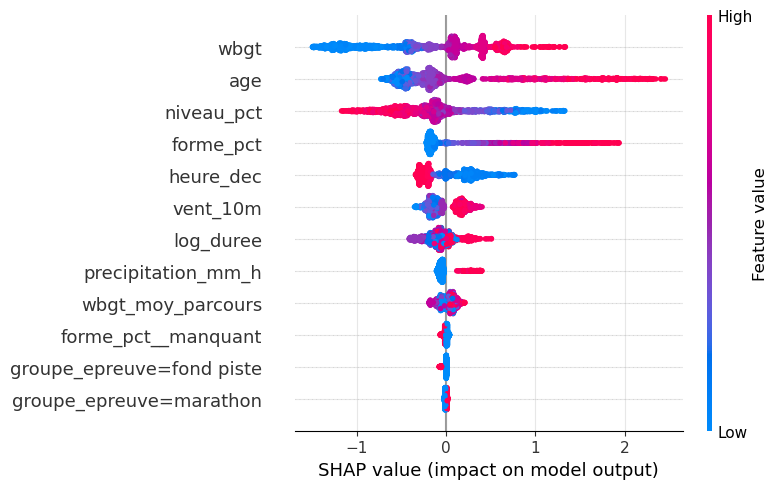

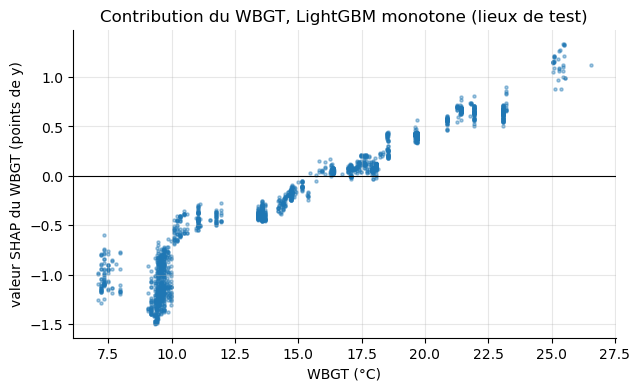

In [73]:
import shap
mod_lgbm = MODELES_2325["LightGBM monotone"]
X_test_lgbm = mod_lgbm.pre_.transform(df_test)
expl = shap.TreeExplainer(mod_lgbm.booster_)
sv = expl.shap_values(X_test_lgbm)
imp = pd.Series(np.abs(sv).mean(axis=0), index=mod_lgbm.pre_.noms_).sort_values(ascending=False)
print("Importance moyenne |SHAP| (points de y) :"); print(imp.head(12).round(4).to_string())
shap.summary_plot(sv, X_test_lgbm, feature_names=mod_lgbm.pre_.noms_, max_display=12, show=False)
plt.gcf().set_size_inches(8, 5); plt.tight_layout(); plt.show()
j = mod_lgbm.pre_.noms_.index("wbgt")
plt.figure(figsize=(7, 4))
plt.scatter(X_test_lgbm[:, j], sv[:, j], s=5, alpha=0.4)
plt.axhline(0, color="k", lw=0.8); plt.xlabel("WBGT (°C)"); plt.ylabel("valeur SHAP du WBGT (points de y)")
plt.title("Contribution du WBGT, LightGBM monotone (lieux de test)"); plt.show()

**Analyse.**

| variable | importance moyenne $\lvert\phi_j\rvert$ (points de $y$) | | variable | importance |
|---|---|---|---|---|
| WBGT | **0,549** | | vent | 0,159 |
| âge | 0,502 | | durée attendue (log) | 0,128 |
| niveau | 0,390 | | pluie | 0,072 |
| forme | 0,294 | | WBGT moyen du parcours | 0,068 |
| heure | 0,240 | | forme manquante, groupes d'épreuves | 0,009 à 0,014 |

**Le WBGT est la variable la plus importante du modèle.** Sur les lieux de test, sa contribution vaut en moyenne
0,55 point de $y$, devant l'âge (0,50), le niveau (0,39) et la forme (0,29). Le graphique de dépendance montre une
contribution croissante, en marches, de $-1{,}4$ point vers 9,5 °C à $+1{,}2$ point vers 25 °C. Les points forment
des bandes verticales : chaque bande correspond à une course, dont tous les coureurs partagent le même WBGT. Les
contributions sont mesurées par rapport à la prédiction moyenne $\phi_0$, et non par rapport au WBGT de référence :
elles sont négatives pour les courses plus fraîches que la moyenne des données d'apprentissage.

**Un paradoxe apparent avec la partie 5.4.** Retirer toutes les variables météorologiques ne dégradait pas la RMSE
(partie 5.4), et pourtant le WBGT reçoit ici la plus forte contribution. Les deux résultats sont compatibles. Le WBGT
est très lié au groupe d'épreuves et à l'heure (piste chaude le soir, marathon frais le matin) : quand il est
présent, une partie de l'information qu'il porte pourrait aussi être portée par ces variables, et la valeur de Shapley
lui en attribue le crédit ; quand il est absent, l'heure, la durée et le groupe prennent le relais. Les indicatrices
de groupe d'épreuves reçoivent d'ailleurs des contributions quasi nulles, signe que leur information est déjà
captée par le WBGT, l'heure et la durée. **Une forte valeur SHAP ne signifie ni qu'une variable est indispensable à
la prédiction, ni qu'elle a un effet causal.**

**Le sens des effets** (graphique de synthèse, rouge = valeur élevée de la variable) :

* **WBGT élevé, âge élevé, forme élevée** (meilleure performance de la saison loin du record), **vent fort, pluie,
  longue durée** : contributions positives, c'est-à-dire une performance plus lente par rapport au record, comme
  attendu ;
* **heure tardive** : contributions négatives. Les réunions de piste en soirée réunissent des athlètes qui courent près
  de leur record (pistes rapides, lièvres) ;
* **niveau élevé** (athlète plus lent que la médiane de son épreuve) : contributions négatives. Les athlètes les moins
  rapides courent plus près de leur record. Plusieurs explications sont possibles, comme un record moins exceptionnel
  ou la sélection par la marge de troncature, et le modèle ne permet pas de les départager.

### 8.2 Dépendance partielle et courbe de dégradation

#### La dépendance partielle

La **dépendance partielle** d'un modèle $f$ en une variable $v$ (Friedman, 2001) est la fonction

$$\text{PD}_v(\xi) = \frac1n\sum_{i=1}^n f\big(x_i \text{ avec } x_{i,v} = \xi\big) :$$

pour chaque valeur $\xi$, on **impose** $x_{i,v} = \xi$ à toutes les performances $i$, les autres variables gardant
leurs valeurs observées, et l'on moyenne les prédictions. C'est la réponse à la question : « que prédirait le
modèle, en moyenne sur nos athlètes et nos courses, si la variable $v$ valait $\xi$ pour tout le monde ? ».
Contrairement à la moyenne de $y$ par classe de WBGT (partie 1.3), qui compare des courses différentes, la
dépendance partielle compare les **mêmes** performances sous deux valeurs de la variable : la composition des
épreuves, l'âge et le niveau sont identiques d'une valeur à l'autre, ce qui neutralise le paradoxe de Simpson
**au sein du modèle**.

#### Les courbes ICE

Avant la moyenne, chaque performance $i$ a sa propre courbe $\xi \mapsto f(x_i \text{ avec } x_{i,v} = \xi)$ : c'est
une courbe **ICE** (*individual conditional expectation*, Goldstein *et al.*, 2015). La dépendance partielle est la
moyenne des courbes ICE. Leur dispersion renseigne sur les **interactions** : si toutes les courbes ICE sont
parallèles (identiques à une constante près), l'effet de $v$ est le même pour toutes les performances ; si elles
divergent, l'effet de $v$ dépend des autres variables. Pour comparer les formes, on recentre chaque courbe sur sa
valeur à la référence.

#### La courbe de dégradation

La courbe de dégradation est la dépendance partielle en WBGT, recentrée sur le WBGT de référence :

$$\Delta(W) = \text{PD}_{\text{WBGT}}(W) - \text{PD}_{\text{WBGT}}(W_{\text{ref}}) \qquad (\text{en points de } y \approx \text{ % de vitesse}).$$

C'est exactement la quantité dont l'outil a besoin (partie 0.4) : la dégradation moyenne de la performance
quand le WBGT passe de 15 °C à $W$, à profil d'athlète inchangé. Pour un modèle linéaire de degré 1 en WBGT, sans
interaction, toutes les courbes ICE sont des droites parallèles et $\Delta(W) = \beta_W\,(W - W_{\text{ref}})$ : la
courbe est une droite de pente $\beta_W$, et sa valeur en 25 °C est l'effet de +10 °C de la partie 3.4 (le test
ci-dessous le vérifie). Si le modèle contient le terme de Mundlak $\bar W_g$, on ne le modifie **pas** : on mesure
l'effet d'un changement de WBGT sur un parcours donné, c'est-à-dire l'effet intra-parcours (partie 4.2).

**Mise en œuvre.** Pour une grille de $n_\xi$ valeurs, on empile $n_\xi$ copies du tableau, chacune avec une valeur
imposée, et l'on prédit le tout en un seul appel : c'est beaucoup plus rapide que $n_\xi$ appels successifs. La
valeur de référence est ajoutée à la grille pour le recentrage.

#### Deux précautions de lecture

* **L'extrapolation.** Aux extrémités de la grille, peu de performances ont été observées : la courbe y repose sur
  très peu de courses, ou prolonge simplement la forme du modèle. Les figures grisent les 2,5 % extrêmes des données
  de chaque côté.
* **Les variables corrélées.** Imposer un WBGT de 27 °C à une performance de cross-country hivernal, ou à une course
  courue à 23 h, crée des combinaisons qui n'existent pas dans les données. La dépendance partielle évalue alors le
  modèle là où il n'a rien appris. Elle reste une description du modèle ; son interprétation comme effet causal
  repose sur les contrôles inclus et sur l'absence de facteur confondant omis (parties 1.4 et 4.2).

La figure compare les courbes de dégradation de six modèles de la partie 7, et montre les courbes ICE du LightGBM
monotone pour 60 performances tirées au hasard.

In [74]:
def dependance_partielle(modele, df, variable, grille, retour_ice=False):
    '''PD de modele.predict en `variable` sur `grille`. Sortie : (G,) ; si retour_ice, aussi (n, G).'''
    grille = np.asarray(grille, dtype=float)
    bloc = pd.concat([df] * len(grille), ignore_index=True)
    bloc[variable] = np.repeat(grille, len(df))
    p = np.asarray(modele.predict(bloc), dtype=float).reshape(len(grille), len(df))
    return (p.mean(axis=1), p.T) if retour_ice else p.mean(axis=1)


def courbe_degradation(modele, df, grille, ref=WBGT_REF, variable="wbgt"):
    '''Delta(w) = PD(w) - PD(ref), en points de y. Sortie : (G,).'''
    pd_g = dependance_partielle(modele, df, variable, np.append(grille, ref))
    return pd_g[:-1] - pd_g[-1]

In [75]:
#test
_m = PipelineLineaire(RegressionMC(), degre=1).fit(df_train)
_g = np.array([10.0, 20.0, 30.0])
_pdp, _ice = dependance_partielle(_m, df_train.head(30), "wbgt", _g, retour_ice=True)
assert _ice.shape == (30, 3) and np.allclose(_ice.mean(axis=0), _pdp)
_d = courbe_degradation(_m, df_train.head(30), _g)
assert np.allclose(_d, effet_wbgt(_m, df_train.head(30), WBGT_REF, WBGT_REF + 10) * (_g - WBGT_REF) / 10)
assert np.isclose(courbe_degradation(_m, df_train.head(30), [WBGT_REF])[0], 0)
print("dépendance partielle : OK")

dépendance partielle : OK


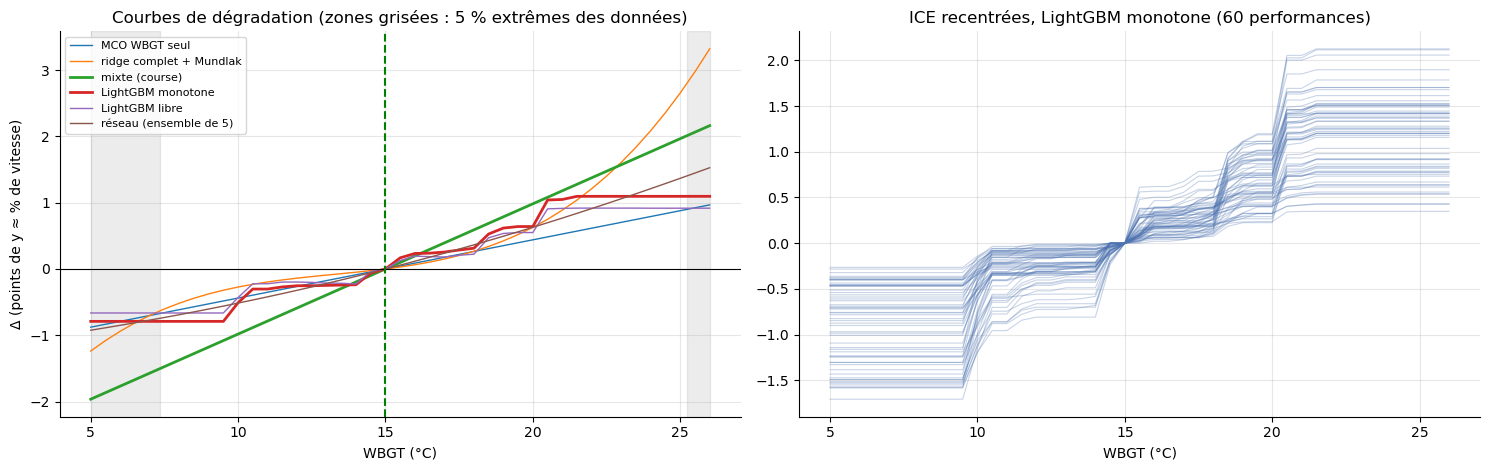

In [76]:
GRILLE = np.arange(np.floor(df["wbgt"].quantile(0.005)), np.ceil(df["wbgt"].quantile(0.995)) + 0.5, 0.5)
q_lo, q_hi = df["wbgt"].quantile([0.025, 0.975])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for nom in ["MCO WBGT seul", "ridge complet + Mundlak", "mixte (course)", "LightGBM monotone", "LightGBM libre",
            "réseau (ensemble de 5)"]:
    axes[0].plot(GRILLE, courbe_degradation(MODELES_2325[nom], df_train, GRILLE), label=nom, lw=2 if "mixte" in nom or "monotone" in nom else 1)
axes[0].axvspan(GRILLE[0], q_lo, color="gray", alpha=0.15); axes[0].axvspan(q_hi, GRILLE[-1], color="gray", alpha=0.15)
axes[0].axhline(0, color="k", lw=0.8); axes[0].axvline(WBGT_REF, color="g", ls="--")
axes[0].set_xlabel("WBGT (°C)"); axes[0].set_ylabel("Δ (points de y ≈ % de vitesse)"); axes[0].legend(fontsize=8)
axes[0].set_title("Courbes de dégradation (zones grisées : 5 % extrêmes des données)")
_, ice = dependance_partielle(MODELES_2325["LightGBM monotone"], df_train.sample(60, random_state=SEED), "wbgt", GRILLE, retour_ice=True)
axes[1].plot(GRILLE, (ice - ice[:, [np.argmin(np.abs(GRILLE - WBGT_REF))]]).T, color="#4C72B0", alpha=0.3, lw=0.8)
axes[1].set_xlabel("WBGT (°C)"); axes[1].set_title("ICE recentrées, LightGBM monotone (60 performances)")
plt.tight_layout(); plt.show()

**Analyse.** Les courbes de dégradation des six modèles (moyennes sur les performances d'apprentissage, toutes
épreuves confondues) ont toutes le même sens : **plus chaud, plus lent**. Leur amplitude et leur forme diffèrent
nettement au-delà de 20 °C. Les valeurs suivantes sont lues sur la figure :

| modèle | $\Delta$ à 25 °C (environ) | forme de la courbe |
|---|---|---|
| MCO WBGT seul | +0,9 | droite, sans contrôle des facteurs confondants |
| LightGBM monotone et libre | +1,1 | en marches, **constante** au-delà d'environ 21 °C |
| réseau (ensemble de 5) | +1,4 | lisse, presque linéaire |
| modèle mixte (course) | +1,9 | droite (degré 1) |
| ridge complet + Mundlak | +2,6 | courbe convexe (degré 3 avec interactions) |

* **Les arbres plafonnent.** Au-delà du dernier seuil appris sur le WBGT (vers 21 °C), le LightGBM prédit la même
  chose quel que soit le WBGT : faute de courses chaudes en nombre suffisant, il n'a pas de quoi couper plus haut. Il ne
  peut pas extrapoler (partie 5.1).
* **Le polynôme de degré 3 s'envole.** La courbure du ridge est portée par les quelques courses les plus chaudes. Elle
  dépasse 3 points dans la zone grisée, où les données manquent : c'est le risque d'extrapolation signalé en parties 3
  et 4.3.
* **Le modèle mixte et le réseau** donnent des courbes régulières, entre ces deux extrêmes.
* **Côté frais**, tous les modèles prédisent une performance plus rapide qu'à 15 °C. L'écart entre eux (de $-0{,}8$ à
  $-1{,}9$ point à 5 °C) se creuse dans la zone grisée : en dessous de 7,5 °C, les données sont rares.

Ces courbes mélangent toutes les épreuves : le modèle de l'outil (partie 8.4) les sépare.

**Les courbes ICE** du LightGBM monotone sont loin d'être parallèles : à 25 °C, la dégradation va d'environ +0,4 à
+2,1 points selon la performance. L'effet de la chaleur dépend donc des autres variables (épreuve, durée, heure) :
le modèle a appris des **interactions**, ce qui justifie d'estimer un effet par groupe d'épreuves. Les marches,
situées vers 10, 14,5, 18,5 et 20,5 °C, sont les seuils de coupure des arbres, communs à toutes les performances.

### 8.3 Incertitude sur la courbe : bootstrap par lieux

#### Pourquoi réentraîner sur tous les lieux

Pour l'outil, les modèles sont désormais réentraînés sur **tous les lieux**, apprentissage et test réunis. Le test a
déjà servi à l'évaluation (partie 7), et il n'y a plus aucun choix à faire en le regardant : l'utiliser pour estimer
l'effet ne crée aucune fuite, et 21 lieux de plus améliorent la précision.

#### D'où vient l'incertitude

L'incertitude sur $\Delta(W)$ vient surtout du **petit nombre de lieux et de courses** : chaque course n'apporte
qu'une situation météorologique (partie 1.2), et les courses chaudes sont rares. Comme en partie 7.2, on l'estime
par un **bootstrap par grappes** des lieux, mais cette fois en **réentraînant** le modèle sur chaque réplique :

1. tirer, avec remise, autant de lieux qu'il y en a dans les données ;
2. réunir toutes les performances des lieux tirés, et réentraîner le modèle sur cet échantillon ;
3. calculer la courbe de dégradation du modèle réentraîné sur une population de référence fixe ;
4. répéter $B$ fois, puis prendre, **point par point** de la grille, les quantiles 2,5 % et 97,5 % des $B$ courbes.

On obtient une **bande de confiance ponctuelle** à 95 % : pour chaque valeur de WBGT, l'intervalle contient la
valeur de la vraie courbe avec une probabilité d'environ 95 %. Ce n'est pas une bande **simultanée** : la probabilité
que la courbe entière reste dans la bande est plus faible. Ce bootstrap mesure l'incertitude due à l'échantillon
de lieux, y compris la variabilité de l'estimation de tous les coefficients, mais pas celle due à un mauvais choix
de forme du modèle.

#### Deux précautions

* **Une population de référence fixe.** La courbe est toujours calculée sur le même ensemble de performances
  (`df_ref`), et non sur l'échantillon bootstrap, dont la composition change à chaque réplique : sinon, la
  variabilité mesurée mélangerait celle du modèle et celle de la population sur laquelle on moyenne.
* **Renommer les copies d'un lieu tiré plusieurs fois.** Si un lieu est tiré deux fois, ses lignes apparaissent en
  double. Sans renommage, ses courses deviendraient des courses de taille double, faites de paires de lignes
  identiques. Un modèle mixte y verrait une variance intra-course artificiellement faible et pourrait estimer
  $\gamma \to \infty$, avec des effets aberrants. Chaque copie reçoit donc des identifiants de course, de meeting, de
  parcours et de lieu suffixés par son numéro (`#k`) : elle devient un lieu distinct, ce qu'elle est dans la logique
  du bootstrap, où chaque tirage représente un nouveau lieu de la population.

Le test vérifie que la courbe vaut 0 à la référence dans toutes les répliques, qu'elle varie d'une réplique à
l'autre, et, à l'aide d'un modèle « espion », que chaque copie a bien reçu des identifiants distincts.

In [77]:
IDENTIFIANTS = ["id_course", "id_meeting", "id_parcours", "id_lieu"]


def bootstrap_courbes(fabrique, df, df_ref, grille, B=100, groupe="id_lieu", seed=SEED, garder_modeles=False):
    '''Bootstrap par grappes de la courbe de dégradation. Sortie : courbes (B, G) [, liste de modèles].'''
    rng = np.random.default_rng(seed)
    uniques = df[groupe].unique()
    positions = df.groupby(groupe).indices
    courbes, modeles = [], []
    for _ in range(B):
        tirage = rng.choice(uniques, size=len(uniques), replace=True)
        blocs = [positions[g] for g in tirage]
        df_b = df.iloc[np.concatenate(blocs)].copy()
        copie = np.repeat(np.arange(len(blocs)), [len(i) for i in blocs]).astype(str)
        for col in IDENTIFIANTS:
            df_b[col] = df_b[col].astype(str).to_numpy() + "#" + copie
        m = fabrique().fit(df_b)
        courbes.append(courbe_degradation(m, df_ref, grille))
        if garder_modeles:
            modeles.append(m)
    courbes = np.array(courbes)
    return (courbes, modeles) if garder_modeles else courbes

In [78]:
#test
_c = bootstrap_courbes(lambda: PipelineLineaire(RegressionMC(), degre=1), df_train, df_train.head(50), np.array([WBGT_REF, 22.0]), B=5)
assert _c.shape == (5, 2) and np.allclose(_c[:, 0], 0) and np.std(_c[:, 1]) > 0
class _Espion:                       # vérifie le renommage des copies
    def fit(self, d):
        assert d["id_course"].str.contains("#").all() and d.groupby("id_course")["id_lieu"].nunique().max() == 1
        return self
    def predict(self, d):
        return np.zeros(len(d))
_ = bootstrap_courbes(_Espion, df_train.head(400), df_train.head(10), np.array([WBGT_REF]), B=2)
print("bootstrap_courbes : OK")

bootstrap_courbes : OK


### 8.4 Le modèle retenu pour l'outil

#### Le cahier des charges

Pour l'outil, ce qui compte est l'**effet** des conditions : estimé avec le moins de biais possible, assorti d'une
incertitude honnête, lisible par épreuve, et sans extrapolation fantaisiste. La partie 7 ayant montré que les
familles de modèles se valent en prédiction, le choix se fait sur ces critères.

#### Le modèle

Nous retenons un modèle linéaire à **intercept aléatoire de course** (partie 4), dont les termes sont choisis
*a priori* d'après la physiologie et la littérature. Pour la performance $j$ de la course $g$ :

$$y_{gj} = u_g + \sum_e \mathbb 1_e\,P_e(W_{gj}) + \beta_{W,\text{niv}}\,\frac{\text{niveau}_{gj}}{10}\,(W_{gj} - W_{\text{ref}})
  + \sum_e \mathbb 1_e\,\beta_{\text{alt},e}\,\text{alt}_g + \beta_{\text{vent}}\,\text{vent}_{gj} + \beta_{\text{pluie}}\,\text{pluie}_{gj}
  + x_{gj}^\top\beta + \varepsilon_{gj} .$$

* $u_g \sim \mathcal N(0, \tau^2)$ est l'effet aléatoire de la course $g$, $\varepsilon_{gj} \sim \mathcal N(0, \sigma^2)$
  l'aléa individuel (partie 4.1).
* $P_e$ est un **polynôme du WBGT propre à chaque groupe d'épreuves** $e$, et $\mathbb 1_e$ vaut 1 pour les
  performances du groupe $e$ : l'effet de la chaleur peut croître avec la durée de l'effort (partie 0.2). Les
  polynômes s'écrivent dans la base $\psi(W)$ de la partie 3.3, nulle en $W_{\text{ref}}$. Leur degré $D$ est choisi
  par validation croisée par lieux, parmi 1, 2 et 3.
* Le terme $\beta_{W,\text{niv}}$ multiplie l'écart de WBGT à la référence par le niveau de l'athlète (en dizaines de
  points de `niveau_pct`) : il teste le résultat d'Ely *et al.* (2007), selon lequel les coureurs lents sont plus
  affectés par la chaleur. S'il est positif, un coureur plus lent que la médiane (niveau positif) perd davantage.
* $\text{alt}_g$ est l'altitude au-delà de 500 m (`alt_km`, partie 2.3), avec une pente $\beta_{\text{alt},e}$ propre à
  chaque groupe (hypoxie). Les pistes du jeu de données sont toutes sous 300 m : pour le demi-fond et le fond sur
  piste, la colonne est identiquement nulle et son coefficient l'est aussi (solution de norme minimale, partie 3.2).
  L'outil refusera donc toute altitude supérieure à celle observée pour le groupe.
* $x_{gj}^\top\beta$ regroupe les contrôles : âge, forme, heure, durée attendue, niveau, sexe, groupe d'épreuves.

Le terme de Mundlak n'est pas inclus (`MUNDLAK_OUTIL = False`) : avec un effet propre à chaque groupe, il faudrait
une moyenne de parcours par groupe, et la partie 4.2 a montré que l'effet intra-parcours n'est pas plus faible que
l'effet estimé sans distinction. Les conditions de référence de l'outil comprennent un vent de 2 m/s à 10 m
(`VENT_REF`), une brise légère.

#### Les étapes de l'estimation

1. **Choix du degré** $D$ par la RMSE de validation croisée par lieux, sur les données d'apprentissage.
2. **Estimation sur tous les lieux**, et calcul du profil de la vraisemblance REML en $\ln\gamma$ (voir ci-dessous).
3. **Bootstrap des lieux** : 300 répliques pour le modèle mixte, et 50 pour le LightGBM monotone, gardé comme point
   de comparaison (chaque réplique du boosting est plus coûteuse).
4. **Effets par groupe d'épreuves** : la dégradation $\Delta(W)$ est calculée séparément sur les performances de
   référence de chaque groupe (jusqu'à 250 par groupe), à 20 °C et à 25 °C, avec l'intervalle bootstrap. Le calcul
   signale les valeurs situées au-delà du centile 99 du WBGT observé pour le groupe, qui sont des extrapolations.
5. **Autres effets** : vent (+2 m/s), pluie (1 mm/h), écart entre coureurs lents et rapides au marathon (niveau
   $+10$ contre $-10$), altitude (1 500 m), chacun avec son intervalle bootstrap.

#### Un point technique : la vraisemblance REML peut être bimodale

La log-vraisemblance restreinte profilée $\ell_R(\gamma)$ (partie 4.1) n'a pas toujours un seul maximum. Outre le
maximum intérieur, elle peut remonter vers la borne $\gamma \to \infty$, qui correspond aux effets fixes de course.
La cause principale est l'**hétéroscédasticité** : l'écart-type de $y$ au sein d'une course vaut environ 1,9 point
en demi-fond et 3,6 au marathon, alors que le modèle suppose un $\sigma^2$ commun. En traitant chaque course comme
un effet fixe, le modèle absorbe une partie de cette hétérogénéité dans les moyennes de course, ce que la
vraisemblance peut récompenser. Si, dans une réplique bootstrap, la borne l'emporte, les variables de niveau
course (WBGT, altitude, groupe d'épreuves) ne sont plus identifiées que par l'infime variation qui subsiste au sein
des courses, et leurs effets deviennent aberrants.

**La parade : fixer $\gamma$.** On fixe $\gamma$ à sa valeur estimée sur l'échantillon complet, $\hat\gamma$, dans
toutes les répliques. Chaque réplique calcule alors un estimateur des moindres carrés généralisés avec une matrice
de covariance **de travail** $V(\hat\gamma)$ fixée :

$$\hat\beta = (X^\top V^{-1} X)^{-1} X^\top V^{-1} y .$$

Cet estimateur reste **sans biais** même si $V(\hat\gamma)$ n'est pas la vraie covariance : comme
$\mathbb{E}[y] = X\beta$, on a $\mathbb{E}[\hat\beta] = (X^\top V^{-1} X)^{-1} X^\top V^{-1} X\beta = \beta$ quelle que
soit la matrice $V$ utilisée. Une matrice imparfaite ne coûte que de la **précision**. Sa variance n'est en revanche
plus celle que donnerait la formule du modèle ; si la vraie covariance est $\Sigma$, elle vaut

$$\text{Var}(\hat\beta) = (X^\top V^{-1} X)^{-1}\,X^\top V^{-1}\,\Sigma\,V^{-1} X\,(X^\top V^{-1} X)^{-1},$$

la variance dite « **sandwich** », utilisée par les équations d'estimation généralisées (GEE). Le bootstrap des lieux
estime cette variance sans avoir à connaître $\Sigma$ : c'est une incertitude **robuste** à une covariance mal
spécifiée. Une alternative plus complète aurait été un $\sigma^2$ propre à chaque groupe d'épreuves. Le profil de
vraisemblance tracé ci-dessous permet de vérifier que, sur l'échantillon complet, le maximum intérieur l'emporte
nettement.

#### Pourquoi pas le boosting monotone ou le réseau ?

Leurs performances prédictives sont du même ordre (partie 7), mais leurs courbes de chaleur se prêtent mal à
l'outil :

* la courbe du **boosting monotone** est **contrainte** à être croissante : si l'effet réel est nul, elle est biaisée
  vers le haut, et son intervalle bootstrap ne peut pas contenir de valeurs négatives au-dessus de la référence. Elle
  est aussi en marches, et **plafonne** au-delà des derniers seuils appris, faute de courses chaudes ;
* la courbe du **réseau** est lisse, mais elle ne se décompose pas par épreuve, et son incertitude demanderait de
  réentraîner des ensembles de réseaux des centaines de fois ;
* le **modèle linéaire mixte** donne une courbe lisse, propre à chaque épreuve, dont chaque terme a une
  interprétation et un intervalle de confiance.

In [79]:
MUNDLAK_OUTIL = False
VENT_REF = 2.0     # m/s à 10 m : brise légère, conditions de référence pour l'outil


class PipelineOutil(PipelineMixte):
    '''Modèle mixte (intercept aléatoire de course) : polynôme du WBGT par groupe d'épreuves,
    WBGT x niveau, altitude x groupe, vent, pluie, contrôles.'''

    def __init__(self, degre=None, mundlak=MUNDLAK_OUTIL, log_gamma=None):
        degre = DEGRE_OUTIL if degre is None else degre               # DEGRE_OUTIL : choisi ci-dessous
        bornes = (-10.0, 6.0) if log_gamma is None else (log_gamma - 1e-9, log_gamma + 1e-9)   # gamma fixé si donné
        super().__init__(degre=degre, interactions=False, num=["age", "forme_pct", "heure_dec", "log_duree",
                                                               "niveau_pct", "vent_10m", "precipitation_mm_h"],
                         cat=CAT_CONTEXTE, mundlak=mundlak, groupe="id_course", bornes_log_gamma=bornes)

    def _design(self, df):
        d = super()._design(df)
        B = base_polynomiale(df["wbgt"], self.degre)
        for g in GROUPES:
            ind = (df["groupe_epreuve"] == g).to_numpy()
            if g != GROUPES[0]:
                for k in range(self.degre):
                    d[f"wbgt_p{k + 1}_x_{g}"] = B[:, k] * ind
            d[f"alt_x_{g}"] = df["alt_km"].to_numpy() * ind     # une pente d'altitude par groupe
        d["wbgt_x_niveau"] = (df["wbgt"].to_numpy() - WBGT_REF) * df["niveau_pct"].to_numpy() / 10.0
        return d

RMSE CV (plis de lieux) du modèle de l'outil selon le degré : {1: np.float64(3.024), 2: np.float64(3.0282), 3: np.float64(3.0422)} -> DEGRE_OUTIL = 1 (2 s)


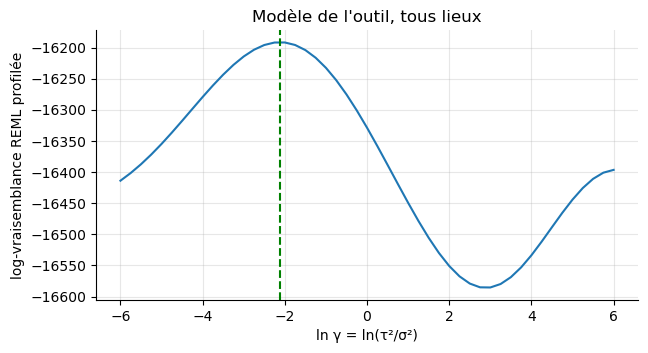

ln gamma estimé = -2.12 (tau²/sigma² = 0.120) ; log-vraisemblance : -16191.8 au maximum intérieur, -16396.4 à ln gamma = 6


modèle mixte (outil) : 300 répliques (40 s)


LightGBM monotone : 50 répliques (60 s)


Modèle mixte (tous lieux) : tau² course = 0.945, sigma² = 7.873

Effet d'une hausse du WBGT depuis 15 °C (points de y), IC 95 % bootstrap par lieu :


 WBGT = 20 °C
  demi-fond piste  +0.018  [-0.430 ; +0.346]
  fond piste       +0.411  [-0.010 ; +1.083]
  route courte     +0.761  [+0.239 ; +1.254]
  semi-marathon    +0.887  [+0.465 ; +1.339]
  marathon         +1.572  [+1.162 ; +2.062]


 WBGT = 25 °C
  demi-fond piste  +0.035  [-0.860 ; +0.693]
  fond piste       +0.823  [-0.020 ; +2.166]
  route courte     +1.522  [+0.477 ; +2.507]
  semi-marathon    +1.775  [+0.930 ; +2.678]   (hors plage du groupe : extrapolation)
  marathon         +3.144  [+2.324 ; +4.124]


In [80]:
t0 = time.time()
cv_outil = {D: cv_rmse(lambda D=D: PipelineOutil(degre=D))[0] for D in [1, 2, 3]}
DEGRE_OUTIL = min(cv_outil, key=cv_outil.get)
print("RMSE CV (plis de lieux) du modèle de l'outil selon le degré :", {D: round(v, 4) for D, v in cv_outil.items()},
      f"-> DEGRE_OUTIL = {DEGRE_OUTIL} ({time.time() - t0:.0f} s)")

df_tout = df.copy()                      # tous les lieux, pour les modèles finaux
MODELE_COMPLET = PipelineOutil().fit(df_tout)
LOG_GAMMA = float(np.log(MODELE_COMPLET.mm_.gamma_))
# profil de la log-vraisemblance REML en ln(gamma)
_d = MODELE_COMPLET._design(df_tout)
_X = np.column_stack([np.ones(len(_d)), MODELE_COMPLET.pre_.transform(_d)])[:, MODELE_COMPLET.mm_.garde_]
_u, _codes = np.unique(df_tout["id_course"].to_numpy(), return_inverse=True)
_n = np.bincount(_codes).astype(float)
grille_lg = np.linspace(-6, 6, 49)
profil = [MODELE_COMPLET.mm_.log_vraisemblance(np.exp(t), _X, df_tout[CIBLE].to_numpy(), _codes, _n)[0] for t in grille_lg]
plt.figure(figsize=(7, 3.5)); plt.plot(grille_lg, profil); plt.axvline(LOG_GAMMA, color="g", ls="--")
plt.xlabel("ln γ = ln(τ²/σ²)"); plt.ylabel("log-vraisemblance REML profilée"); plt.title("Modèle de l'outil, tous lieux")
plt.show()
print(f"ln gamma estimé = {LOG_GAMMA:.2f} (tau²/sigma² = {np.exp(LOG_GAMMA):.3f}) ; "
      f"log-vraisemblance : {max(profil):.1f} au maximum intérieur, {profil[-1]:.1f} à ln gamma = 6")

t0 = time.time()
FAB_FINAL = {"modèle mixte (outil)": lambda: PipelineOutil(log_gamma=LOG_GAMMA),
             "LightGBM monotone": FABRIQUES["LightGBM monotone"]}
B_FINAL = {"modèle mixte (outil)": 300, "LightGBM monotone": 50}
df_ref_courbe = pd.concat([g.sample(min(250, len(g)), random_state=SEED) for _, g in df_tout.groupby("groupe_epreuve")])
BOOT = {}
for nom, fab in FAB_FINAL.items():
    BOOT[nom] = bootstrap_courbes(fab, df_tout, df_ref_courbe, GRILLE, B=B_FINAL[nom], groupe="id_lieu", garder_modeles=True)
    print(f"{nom} : {B_FINAL[nom]} répliques ({time.time() - t0:.0f} s)")
MODELES_FINAUX = {nom: fab().fit(df_tout) for nom, fab in FAB_FINAL.items()}
mm = MODELES_FINAUX["modèle mixte (outil)"].mm_
print(f"Modèle mixte (tous lieux) : tau² course = {mm.tau2_:.3f}, sigma² = {mm.sigma2_:.3f}")

def effet_par_groupe(modele, w=WBGT_REF + 10):
    return {g: courbe_degradation(modele, df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g], [w])[0] for g in GROUPES}

PLAGE_GROUPE = df_tout.groupby("groupe_epreuve")["wbgt"].quantile([0.01, 0.99]).unstack()
print(f"\nEffet d'une hausse du WBGT depuis {WBGT_REF:g} °C (points de y), IC 95 % bootstrap par lieu :")
for w in [WBGT_REF + 5, WBGT_REF + 10]:
    est = effet_par_groupe(MODELES_FINAUX["modèle mixte (outil)"], w)
    reps = pd.DataFrame([effet_par_groupe(m, w) for m in BOOT["modèle mixte (outil)"][1]])
    print(f" WBGT = {w:g} °C")
    for g in GROUPES:
        hors = "   (hors plage du groupe : extrapolation)" if w > PLAGE_GROUPE.loc[g, 0.99] else ""
        print(f"  {g:16s} {est[g]:+.3f}  [{reps[g].quantile(0.025):+.3f} ; {reps[g].quantile(0.975):+.3f}]{hors}")

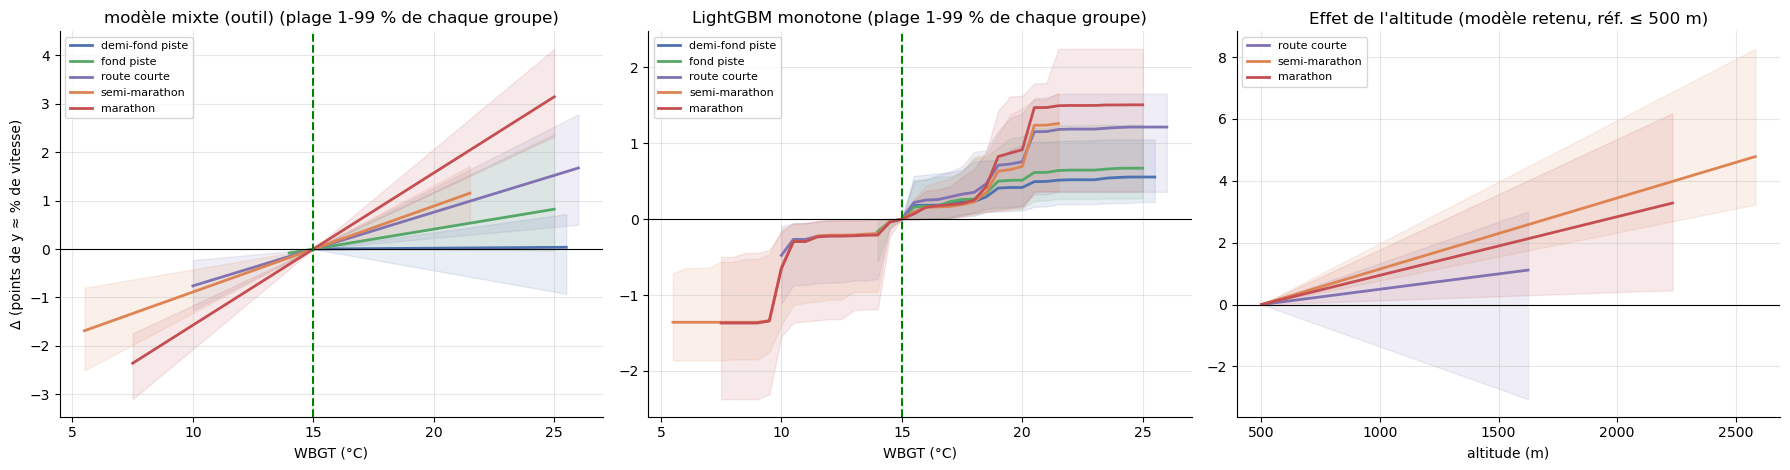

Autres effets du modèle retenu (points de y, IC 95 % bootstrap par lieu) :


  vent +2 m/s (2 -> 4 m/s à 10 m)       : +0.356  [+0.082 ; +0.629]


  pluie 1 mm/h                          : +0.340  [-0.529 ; +2.003]


  marathon, +10 °C : lent - rapide      : -0.174  [-1.240 ; +0.855]


  altitude 1 500 m, route courte         : +0.990  [-2.952 ; +2.798]


  altitude 1 500 m, semi-marathon        : +2.297  [+1.552 ; +4.480]


  altitude 1 500 m, marathon             : +1.893  [+0.045 ; +3.652]


In [81]:
couleurs = dict(zip(GROUPES, ["#4C72B0", "#55A868", "#8172B2", "#DD8452", "#C44E52"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, nom in zip(axes[:2], FAB_FINAL):
    courbes_b, modeles_b = BOOT[nom]
    for g in GROUPES:
        sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
        gg = GRILLE[(GRILLE >= min(PLAGE_GROUPE.loc[g, 0.01], WBGT_REF)) & (GRILLE <= PLAGE_GROUPE.loc[g, 0.99])]
        cb = np.array([courbe_degradation(m, sous, gg) for m in modeles_b[:200]])
        ax.plot(gg, courbe_degradation(MODELES_FINAUX[nom], sous, gg), color=couleurs[g], lw=2, label=g)
        ax.fill_between(gg, np.quantile(cb, 0.025, axis=0), np.quantile(cb, 0.975, axis=0), color=couleurs[g], alpha=0.12)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(WBGT_REF, color="g", ls="--"); ax.set_title(nom + " (plage 1-99 % de chaque groupe)")
    ax.legend(fontsize=8); ax.set_xlabel("WBGT (°C)")
axes[0].set_ylabel("Δ (points de y ≈ % de vitesse)")
mod_o = MODELES_FINAUX["modèle mixte (outil)"]
for g in ["route courte", "semi-marathon", "marathon"]:      # les pistes sont toutes sous 300 m
    sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
    ga = np.linspace(0, df_tout.loc[df_tout["groupe_epreuve"] == g, "alt_km"].max(), 20)
    ca = np.array([courbe_degradation(m, sous, ga, ref=0.0, variable="alt_km") for m in BOOT["modèle mixte (outil)"][1][:200]])
    axes[2].plot(500 + 1000 * ga, courbe_degradation(mod_o, sous, ga, ref=0.0, variable="alt_km"), color=couleurs[g], lw=2, label=g)
    axes[2].fill_between(500 + 1000 * ga, np.quantile(ca, 0.025, axis=0), np.quantile(ca, 0.975, axis=0), color=couleurs[g], alpha=0.12)
axes[2].axhline(0, color="k", lw=0.8); axes[2].set_xlabel("altitude (m)"); axes[2].legend(fontsize=8)
axes[2].set_title("Effet de l'altitude (modèle retenu, réf. ≤ 500 m)")
plt.tight_layout(); plt.show()
def resume(fonction):
    e = fonction(MODELES_FINAUX["modèle mixte (outil)"])
    b = np.array([fonction(m) for m in BOOT["modèle mixte (outil)"][1]])
    return f"{e:+.3f}  [{np.quantile(b, 0.025):+.3f} ; {np.quantile(b, 0.975):+.3f}]"

print("Autres effets du modèle retenu (points de y, IC 95 % bootstrap par lieu) :")
print("  vent +2 m/s (2 -> 4 m/s à 10 m)       :", resume(lambda m: courbe_degradation(m, df_ref_courbe, [VENT_REF + 2], ref=VENT_REF, variable="vent_10m")[0]))
print("  pluie 1 mm/h                          :", resume(lambda m: courbe_degradation(m, df_ref_courbe, [1.0], ref=0.0, variable="precipitation_mm_h")[0]))
mara = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == "marathon"]
def ecart_niveau(m):   # Ely et al. : effet de +10 °C chez un coureur 10 % plus lent moins chez un coureur 10 % plus rapide
    lent, rapide = mara.assign(niveau_pct=10.0), mara.assign(niveau_pct=-10.0)
    return courbe_degradation(m, lent, [WBGT_REF + 10])[0] - courbe_degradation(m, rapide, [WBGT_REF + 10])[0]
print("  marathon, +10 °C : lent - rapide      :", resume(ecart_niveau))
for g in ["route courte", "semi-marathon", "marathon"]:
    sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
    print(f"  altitude 1 500 m, {g:14s}       :", resume(lambda m: courbe_degradation(m, sous, [1.0], ref=0.0, variable="alt_km")[0]))

**Analyse.**

**Choix du degré.** La validation croisée par lieux donne une RMSE de 3,024 pour un effet linéaire du WBGT dans chaque
groupe, 3,028 en degré 2 et 3,042 en degré 3. Le degré 1 est retenu : les données ne permettent pas d'estimer une
courbure propre à chaque groupe d'épreuves. Les écarts étant très inférieurs à l'erreur type entre plis (partie 2.5),
la règle d'un écart-type aurait fait le même choix.

**Le profil de vraisemblance confirme la bimodalité.** Le maximum intérieur est atteint en $\ln\hat\gamma = -2{,}12$,
soit $\hat\gamma = 0{,}120$, avec $\hat\tau^2 = 0{,}945$ et $\hat\sigma^2 = 7{,}873$ : la course explique 11 % de la
variance résiduelle, comme en partie 4.2. La vraisemblance descend ensuite jusqu'à environ $-16\,585$ vers
$\ln\gamma \approx 2{,}8$, puis **remonte** jusqu'à $-16\,396$ à la borne $\ln\gamma = 6$ : c'est le second mode, du
côté des effets fixes de course. Sur l'échantillon complet, le maximum intérieur ($-16\,192$) l'emporte de plus de 200
unités de log-vraisemblance : fixer $\gamma$ à cette valeur dans le bootstrap est sans ambiguïté.

**Ordres de grandeur.** Dégradation $\Delta$ depuis un WBGT de 15 °C, en points de $y$ (≈ % de vitesse), avec l'IC à
95 % par bootstrap des lieux (300 répliques) :

| groupe d'épreuves | WBGT 20 °C | WBGT 25 °C |
|---|---|---|
| demi-fond piste | $+0{,}02$ [$-0{,}43$ ; $+0{,}35$] | $+0{,}04$ [$-0{,}86$ ; $+0{,}69$] |
| fond piste | $+0{,}41$ [$-0{,}01$ ; $+1{,}08$] | $+0{,}82$ [$-0{,}02$ ; $+2{,}17$] |
| route courte | $+0{,}76$ [$+0{,}24$ ; $+1{,}25$] | $+1{,}52$ [$+0{,}48$ ; $+2{,}51$] |
| semi-marathon | $+0{,}89$ [$+0{,}47$ ; $+1{,}34$] | $+1{,}78$ [$+0{,}93$ ; $+2{,}68$] (extrapolé) |
| marathon | $+1{,}57$ [$+1{,}16$ ; $+2{,}06$] | $+3{,}14$ [$+2{,}32$ ; $+4{,}12$] |

**L'effet croît avec la durée de l'effort**, comme le prévoit la physiologie : la chaleur stockée s'accumule et la
dérive cardiovasculaire s'installe au fil de l'effort (partie 0.2).

* Il est **nul en demi-fond** : un 800 m ou un 1 500 m est trop court pour que la thermorégulation limite la
  performance. L'intervalle, centré sur 0, exclut un effet supérieur à 0,7 point à 25 °C.
* Il vaut environ **0,8 point en fond sur piste**, avec un intervalle qui touche 0, puis environ **1,5 point sur route
  courte** (5 et 10 km).
* Il atteint environ **3 points au marathon** entre 15 et 25 °C, soit environ 4 min 45 s sur 2 h 30. C'est l'ordre de
  grandeur d'Ely *et al.* (2007).
* Le semi-marathon à 25 °C est une **extrapolation** : aucune course n'a été observée au-delà de 22 °C.

Les effets étant linéaires, celui de 25 °C est le double de celui de 20 °C. Les moyennes par classes de la partie 1.3
suggéraient une accélération au-delà de 20 °C au marathon : le modèle linéaire peut sous-estimer légèrement l'effet vers
25 °C et le surestimer vers 18-20 °C. Pondéré par les effectifs des groupes, l'effet de +10 °C vaut environ 1,7 point
($\frac{1}{10\,398}\sum_e n_e\,\Delta_e(25)$, avec les effectifs de la partie 1.1). C'est un peu moins que les estimations de
la partie 4.2 (1,9 à 2,4 points avec les effets aléatoires, le terme de Mundlak et les effets fixes), obtenues sur les
seuls lieux d'apprentissage et avec un effet commun à toutes les épreuves, mais du même ordre de grandeur.

**Les autres termes.**

| effet | estimation [IC 95 %] (points de $y$) |
|---|---|
| vent +2 m/s (de 2 à 4 m/s à 10 m), à WBGT égal | $+0{,}36$ [$+0{,}08$ ; $+0{,}63$] |
| pluie 1 mm/h | $+0{,}34$ [$-0{,}53$ ; $+2{,}00$] |
| marathon, +10 °C : coureur lent (niveau $+10$) moins coureur rapide ($-10$) | $-0{,}17$ [$-1{,}24$ ; $+0{,}86$] |
| altitude 1 500 m, route courte | $+0{,}99$ [$-2{,}95$ ; $+2{,}80$] |
| altitude 1 500 m, semi-marathon | $+2{,}30$ [$+1{,}55$ ; $+4{,}48$] |
| altitude 1 500 m, marathon | $+1{,}89$ [$+0{,}05$ ; $+3{,}65$] |

* Le **vent** coûte 0,36 point pour +2 m/s, à WBGT égal. Son effet rafraîchissant passe déjà par le WBGT ; il reste
  l'effet mécanique, le vent de face n'étant pas compensé par le vent de dos.
* La **pluie** est trop rare (partie 1.2) pour conclure.
* L'écart entre coureurs lents et rapides au marathon prédit par Ely *et al.* n'est **pas détecté** : le jeu de
  données ne contient que de bons coureurs, sur une plage de niveaux étroite.
* L'**altitude** coûte, à 1 500 m, environ 1,9 point au marathon et 2,3 au semi-marathon ; sur route courte elle
  reste indéterminée. Ces effets reposent sur 3 à 6 lieux par groupe, d'où la largeur des intervalles, et peuvent
  aussi refléter les parcours propres à ces villes. La figure montre que l'altitude, observée jusqu'à 2 600 m environ,
  n'est estimée que sur route.

**Comparaison avec le LightGBM monotone.** Le boosting donne le même classement des épreuves et des valeurs proches
jusqu'à 20 °C, mais il **plafonne** au-delà : environ +1,5 point au marathon à 25 °C, contre 3,1 pour le modèle mixte.
Ses arbres sont constants au-delà des derniers seuils appris, faute de courses chaudes. La contrainte de monotonie a un
autre effet, visible en **demi-fond** : sa courbe ne peut pas descendre sous 0 au-dessus de 15 °C, et elle monte jusqu'à
environ +0,5 point avec un intervalle qui exclut 0, alors que le modèle mixte trouve un effet nul. C'est le biais vers
le haut décrit plus haut : quand l'effet réel est nul, une courbe contrainte à monter ne peut que le surestimer. Les deux
modèles s'accordent côté frais : au marathon, courir à 7-8 °C plutôt qu'à 15 °C fait gagner de 1,4 à 2,4 points.

## Partie 9 — Quantification de l'incertitude de prédiction

#### Deux incertitudes à ne pas confondre

* L'**intervalle de confiance** (IC) porte sur un **paramètre** ou un effet moyen, ici la courbe de dégradation
  $\Delta(W)$ (partie 8). Il traduit l'imprécision due à la taille finie de l'échantillon : avec plus de lieux et de
  courses, il se resserrerait jusqu'à zéro.
* L'**intervalle de prédiction** (IP) $\hat I(x) = [\hat q_{\text{bas}}(x),\ \hat q_{\text{haut}}(x)]$ porte sur une
  **observation future** : il doit contenir la performance $y$ d'un athlète avec une probabilité $1 - \alpha$. Même avec
  un modèle parfait, connu sans erreur, il reste aussi large que le bruit individuel (forme du jour, tactique,
  ancienneté du record) : il ne se resserre pas avec les données.

Cette partie construit des intervalles de prédiction, avec $\alpha = 0{,}1$ (couverture visée : 90 %).

### 9.1 Régression quantile et perte *pinball*

#### Le quantile comme minimiseur

La moyenne minimise la perte quadratique, la médiane la perte absolue (partie 2.2). Plus généralement, le quantile
d'ordre $\alpha$ d'une variable $Y$ (la valeur $q$ telle que $\mathbb{P}(Y \leq q) = \alpha$) minimise l'espérance de
la **perte *pinball*** :

$$\rho_\alpha(y, q) = \max\big(\alpha\,(y - q),\ (\alpha - 1)(y - q)\big) =
\begin{cases} \alpha\,(y - q) & \text{si } y \geq q \ \ (\text{prédiction trop basse}), \\ (1 - \alpha)\,(q - y) & \text{si } y < q \ \ (\text{prédiction trop haute}). \end{cases}$$

**Démonstration.** Pour une variable $Y$ de fonction de répartition $F$ continue,

$$\mathbb{E}[\rho_\alpha(Y, q)] = \alpha\int_{q}^{+\infty}(y - q)\,dF(y) + (1 - \alpha)\int_{-\infty}^{q}(q - y)\,dF(y),$$

dont la dérivée en $q$ vaut $-\alpha\,\big(1 - F(q)\big) + (1 - \alpha)\,F(q) = F(q) - \alpha$. Elle s'annule quand
$F(q) = \alpha$, et la fonction est convexe : le minimum est atteint au quantile d'ordre $\alpha$.

**Intuition.** Une prédiction trop basse coûte $\alpha$ par unité, une prédiction trop haute $1 - \alpha$. Pour
$\alpha = 0{,}95$, être trop bas coûte 19 fois plus qu'être trop haut : on place $q$ haut, de sorte que 95 % des
observations soient en dessous. Pour $\alpha = 0{,}5$, on retrouve la perte absolue et la médiane.

#### La régression quantile

En minimisant la perte *pinball* moyenne sur les données au lieu de l'erreur quadratique, un modèle estime un
**quantile conditionnel** $\hat q_\alpha(x)$ : la valeur sous laquelle on attend une proportion $\alpha$ des
performances de profil $x$. LightGBM le fait avec `objective="quantile"`. Deux modèles, pour $\alpha/2 = 0{,}05$ et
$1 - \alpha/2 = 0{,}95$, donnent un intervalle de prédiction « brut » à 90 %, dont la largeur s'adapte à $x$.

**Le défaut des quantiles bruts.** Rien ne garantit leur couverture. Appris sur les données d'apprentissage, ils
ignorent l'erreur d'estimation du modèle lui-même, et la différence entre les lieux d'apprentissage et un lieu
nouveau : ils ont tendance à être trop étroits.

### 9.2 Prédiction conforme et CQR

#### Le principe

La **prédiction conforme** corrige ce défaut en calibrant l'intervalle sur un ensemble **séparé** de $n$ observations,
non utilisées pour l'apprentissage. On calcule sur cet ensemble un **score de non-conformité** $s_i$, d'autant plus
grand que l'observation $i$ est mal prédite, puis le seuil

$$\hat q = \text{la } \lceil (n+1)(1-\alpha)\rceil\text{-ième plus petite valeur des scores}
  \quad(+\infty \text{ si cet indice dépasse } n),$$

et l'on retient comme intervalle de prédiction l'ensemble des valeurs $y$ dont le score serait inférieur à $\hat q$.

#### La garantie de couverture

**Hypothèse.** Les scores des $n$ observations de calibration et celui d'une nouvelle observation sont
**échangeables** : leur loi jointe est inchangée quand on les permute. C'est le cas s'ils sont indépendants et de même
loi, mais l'hypothèse est plus faible.

**Résultat.** Sous cette hypothèse, le rang du nouveau score parmi les $n + 1$ scores est uniforme sur
$\{1, \dots, n + 1\}$ (en l'absence d'égalités) : chaque position est également probable. Le nouveau score est donc
inférieur ou égal à la $k$-ième plus petite valeur de calibration avec une probabilité d'au moins $k/(n + 1)$. Avec
$k = \lceil (n+1)(1-\alpha)\rceil$, on obtient

$$\mathbb{P}\big(y \in \hat I(x)\big) \geq \frac{\lceil (n+1)(1-\alpha)\rceil}{n + 1} \geq 1 - \alpha .$$

La garantie vaut **en échantillon fini**, quelle que soit la qualité du modèle et sans aucune hypothèse sur la loi
des données. Un mauvais modèle donne des intervalles larges, mais toujours bien calibrés. La correction $(n + 1)$
compte : le quantile empirique ordinaire, d'indice $\lceil n(1-\alpha)\rceil$, sous-couvrirait légèrement, surtout
pour un petit ensemble de calibration.

#### Deux scores

* **Conforme simple** : $s_i = |y_i - \hat y(x_i)|$, l'erreur absolue d'un modèle de la moyenne. L'intervalle est
  $\hat y(x) \pm \hat q$, de **largeur constante** : il est aussi large pour un 800 m que pour un marathon.
* **CQR** (*conformalized quantile regression*, Romano *et al.*, 2019) : à partir des quantiles bruts,
  $s_i = \max\big(\hat q_{\text{bas}}(x_i) - y_i,\ y_i - \hat q_{\text{haut}}(x_i)\big)$, qui mesure de combien $y_i$
  dépasse l'intervalle brut (il est négatif si $y_i$ est à l'intérieur). L'intervalle est
  $[\hat q_{\text{bas}}(x) - \hat q,\ \hat q_{\text{haut}}(x) + \hat q]$ : il garde la **largeur adaptative** des
  quantiles bruts, élargie (ou rétrécie, si $\hat q < 0$) juste assez pour atteindre la couverture voulue.

#### Couverture marginale et conditionnelle

La garantie est **marginale** : elle porte sur la proportion de performances couvertes en moyenne sur toutes les
performances. Elle ne garantit pas la couverture **conditionnelle** à un sous-groupe, par exemple les marathons :
certains groupes peuvent être sur-couverts et d'autres sous-couverts, la moyenne restant correcte. On mesure donc
aussi la couverture par groupe d'épreuves.

#### Le protocole

On entraîne trois LightGBM (la moyenne avec contrainte de monotonie, les quantiles 0,05 et 0,95) sur quatre plis de
lieux, on **calibre sur le cinquième pli**, et l'on évalue sur les lieux de test. Calibrer sur des lieux que le modèle
n'a pas vus reproduit la situation d'un lieu nouveau. L'échangeabilité n'est qu'approchée : calibration et test
portent sur des lieux différents, et les performances d'une même course sont corrélées. On ne tronque pas la borne
basse à 0 : $y < 0$ (nouveau record) est fréquent.

Le test vérifie la perte *pinball* sur deux cas simples, l'indice du quantile conforme (la 18e valeur sur 19 pour
$\alpha = 0{,}1$, l'infini sur 3 valeurs), et la garantie elle-même par simulation : sur 300 tirages, la couverture
empirique d'un intervalle à 80 % reste proche de 80 %.

In [82]:
def perte_pinball(y, q, alpha):
    '''Perte pinball moyenne pour le quantile d'ordre alpha.'''
    e = np.asarray(y, float) - np.asarray(q, float)
    return float(np.mean(np.maximum(alpha * e, (alpha - 1) * e)))


def quantile_conforme(scores, alpha):
    '''Quantile conforme corrigé : ceil((n+1)(1-alpha))-ième plus petite valeur (inf si hors bornes).'''
    s = np.sort(np.asarray(scores, float))
    k = int(np.ceil((len(s) + 1) * (1 - alpha)))
    return float(s[k - 1]) if k <= len(s) else np.inf


def couverture_largeur(y, bas, haut):
    '''(couverture empirique, largeur moyenne).'''
    y, bas, haut = (np.asarray(a, float) for a in (y, bas, haut))
    return float(np.mean((y >= bas) & (y <= haut))), float(np.mean(haut - bas))

In [83]:
#test
assert np.isclose(perte_pinball([1.0], [0.0], 0.9), 0.9) and np.isclose(perte_pinball([0.0], [1.0], 0.9), 0.1)
assert quantile_conforme(np.arange(1, 20), 0.1) == 18 and quantile_conforme([1, 2, 3], 0.1) == np.inf
_rng = np.random.default_rng(8); _cov = []
for _ in range(300):
    _s = np.abs(_rng.normal(size=51)); _q = quantile_conforme(_s[:50], 0.2); _cov.append(_s[50] <= _q)
assert 0.74 < np.mean(_cov) < 0.9
assert np.allclose(couverture_largeur([1, 2, 3], [0, 0, 0], [2.5, 2.5, 2.5]), (2 / 3, 2.5))
print("conforme : OK")

conforme : OK


In [84]:
t0 = time.time()
ALPHA = 0.1
d_fit, d_cal = df_train.iloc[PLIS[0][0]], df_train.iloc[PLIS[0][1]]
p_lgbm = {**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}
m_moy = PipelineLGBM(p_lgbm, N_ARBRES_LGBM, NUM_GBM, CAT_GBM, monotone={"wbgt": 1}).fit(d_fit)
m_bas = PipelineLGBM({**p_lgbm, "objective": "quantile", "alpha": ALPHA / 2}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM).fit(d_fit)
m_haut = PipelineLGBM({**p_lgbm, "objective": "quantile", "alpha": 1 - ALPHA / 2}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM).fit(d_fit)
y_cal, y_te = d_cal[CIBLE].to_numpy(), df_test[CIBLE].to_numpy()
# 1) conforme simple
q_abs = quantile_conforme(np.abs(y_cal - m_moy.predict(d_cal)), ALPHA)
p_te = m_moy.predict(df_test)
int_simple = (p_te - q_abs, p_te + q_abs)
# 2) quantiles bruts puis CQR
qb_cal, qh_cal = m_bas.predict(d_cal), m_haut.predict(d_cal)
qb_te, qh_te = m_bas.predict(df_test), m_haut.predict(df_test)
q_cqr = quantile_conforme(np.maximum(qb_cal - y_cal, y_cal - qh_cal), ALPHA)
int_brut = (qb_te, qh_te)
int_cqr = (qb_te - q_cqr, qh_te + q_cqr)
lignes = []
for nom, (b, h) in [("quantiles LightGBM bruts", int_brut), ("conforme simple", int_simple), ("CQR", int_cqr)]:
    cov, larg = couverture_largeur(y_te, b, h)
    lignes.append({"méthode": nom, "couverture": cov, "largeur moyenne": larg})
print(f"Quantiles conformes : simple {q_abs:.3f}, CQR {q_cqr:+.3f} (points de y)")
print(f"Objectif : couverture {1 - ALPHA:.0%} | pinball test q{ALPHA / 2:.2f} = {perte_pinball(y_te, qb_te, ALPHA / 2):.4f}, "
      f"q{1 - ALPHA / 2:.2f} = {perte_pinball(y_te, qh_te, 1 - ALPHA / 2):.4f}")
print(pd.DataFrame(lignes).round(3).to_string(index=False))
cond = pd.DataFrame({"groupe": df_test["groupe_epreuve"], "dans": (y_te >= int_cqr[0]) & (y_te <= int_cqr[1]),
                     "largeur": int_cqr[1] - int_cqr[0]}).groupby("groupe").agg(couverture=("dans", "mean"),
                                                                                largeur=("largeur", "mean"), n=("dans", "size"))
print("\nCQR, couverture conditionnelle par épreuve :"); print(cond.round(3))
print(f"({time.time() - t0:.0f} s)")

Quantiles conformes : simple 3.655, CQR -0.211 (points de y)
Objectif : couverture 90% | pinball test q0.05 = 0.2420, q0.95 = 0.3551
                 méthode  couverture  largeur moyenne
quantiles LightGBM bruts       0.868            8.131
         conforme simple       0.834            7.310
                     CQR       0.842            7.708

CQR, couverture conditionnelle par épreuve :
                 couverture  largeur    n
groupe                                   
demi-fond piste       0.796    4.968  726
fond piste            0.868    6.289  333
marathon              0.858   10.360  663
route courte          0.851    8.377  422
semi-marathon         0.886    9.704  211
(0 s)


**Analyse.**

| méthode | couverture (visée : 90 %) | largeur moyenne (points de $y$) |
|---|---|---|
| quantiles LightGBM bruts | 86,8 % | 8,13 |
| conforme simple | 83,4 % | 7,31 |
| CQR | 84,2 % | 7,71 |

| CQR par groupe d'épreuves | couverture | largeur | performances |
|---|---|---|---|
| demi-fond piste | 79,6 % | 4,97 | 726 |
| fond piste | 86,8 % | 6,29 | 333 |
| route courte | 85,1 % | 8,38 | 422 |
| semi-marathon | 88,6 % | 9,70 | 211 |
| marathon | 85,8 % | 10,36 | 663 |

Quantiles conformes : $\hat q = 3{,}655$ (simple) et $\hat q = -0{,}211$ (CQR). Perte *pinball* sur le test : 0,242
pour le quantile 0,05 et 0,355 pour le quantile 0,95.

**Les intervalles conformes sous-couvrent.** Les deux intervalles calibrés ne couvrent que 83 à 84 % des performances
de test, au lieu des 90 % garantis, et font même moins bien que les quantiles bruts (86,8 %). La garantie de la partie
9.2 n'est pas fausse : c'est son **hypothèse** qui n'est pas satisfaite. Le pli de calibration est le pli 0, le plus
« facile » des cinq : le modèle constant y obtenait une RMSE de 2,65, contre 3,19 sur les lieux de test (parties 3.1
et 7.2). Ses performances, moins dispersées, donnent des scores plus petits que ceux des lieux de test : les scores de
calibration et de test ne sont pas **échangeables**. Le seuil $\hat q$ calibré est donc trop petit, et l'intervalle
trop étroit. Le signe du seuil de la CQR le montre : $\hat q = -0{,}211$ est négatif, ce qui signifie que, sur le pli de
calibration, les quantiles bruts semblaient trop larges, et la CQR les a **rétrécis**, alors qu'ils étaient déjà un peu
trop étroits pour les lieux de test.

**La leçon.** Une garantie conforme ne vaut que si l'ensemble de calibration est représentatif des données sur
lesquelles on l'applique. Avec des données groupées par lieux, très hétérogènes d'un lieu à l'autre, un pli de 14
lieux ne suffit pas à représenter la variabilité entre lieux. Deux remèdes sont possibles : calibrer sur plusieurs
plis, en utilisant les prédictions hors pli de la validation croisée (*cross-conformal*), ou calibrer par groupe
d'épreuves.

**La largeur s'adapte, la couverture conditionnelle reste inégale.** La CQR adapte bien la largeur à l'épreuve :
5,0 points en demi-fond, 10,4 au marathon, ce qui reflète l'hétéroscédasticité de la partie 1.2. Sa couverture varie
pourtant de 79,6 % en demi-fond à 88,6 % au semi-marathon : la garantie, déjà approchée en moyenne, ne vaut pas groupe
par groupe.

**Intervalle de prédiction et intervalle de confiance.** Les intervalles de prédiction (environ $\pm 4$ points) sont
bien plus larges que l'intervalle de confiance de la courbe de dégradation (de $\pm 0{,}4$ à $\pm 1$ point, partie 8.4). Le
premier porte sur le chrono d'une performance individuelle : il inclut la forme du jour, la tactique et l'ancienneté du
record, un bruit d'écart-type proche de 2,8 points (partie 4) qui ne diminue pas avec la taille de l'échantillon. Le
second porte sur l'effet **moyen** des conditions, qui se précise avec les données.

**Pour régler une allure**, c'est $\Delta$ et son intervalle de confiance qui comptent : la question est « de combien
ralentir pour fournir le même effort », pas « quel chrono vais-je faire ». La borne haute de l'IC donne une allure
prudente. L'intervalle de prédiction rappelle, lui, qu'un chrono individuel reste très incertain, quelles que soient
les conditions.

## Partie 10 — Outil final : la vitesse « à effort égal »

### 10.1 Du modèle à la vitesse équivalente

**Entrées** : la vitesse $Y$ (m/s) en conditions de référence ; les conditions du jour $\mathcal{C}$ (température,
humidité, vent à 10 m, rayonnement global, pluie, altitude ; date, heure et lieu pour la position du soleil) ;
l'épreuve et le sexe. **Conditions de référence** $\mathcal{C}_{\text{ref}}$ : WBGT de 15 °C, vent de 2 m/s à 10 m,
pas de pluie, altitude inférieure ou égale à 500 m. Le calcul se fait en cinq étapes.

1. **Le WBGT du jour**, par le modèle de Liljegren (partie 0.3, `wbgt_liljegren.py`). La pression est déduite de
   l'altitude $z$ (en m) par la formule barométrique de l'atmosphère standard :

   $$p(z) = 1013{,}25\,\big(1 - 2{,}2557\cdot 10^{-5}\,z\big)^{5{,}2559}\ \text{hPa}.$$

   Elle découle de l'équilibre hydrostatique d'une atmosphère dont la température décroît linéairement avec
   l'altitude : $2{,}2557\cdot10^{-5} = L/T_0$, avec un gradient thermique $L = 0{,}0065$ K/m et une température au sol
   $T_0 = 288{,}15$ K, et $5{,}2559 = g_0 M/(R L)$, où $g_0$ est l'accélération de la pesanteur, $M$ la masse molaire
   de l'air et $R$ la constante des gaz parfaits. À 1 000 m, la pression est 11 % plus basse qu'au niveau de la mer.
2. **Le profil implicite de l'athlète.** Sa vitesse $Y$ correspond, sur la distance $d$, à un temps $t_Y = d/Y$, que l'on
   traite comme son record : `niveau_pct` $= 100\ln(t_Y/t^{\text{RP}}_{\text{méd}})$, où $t^{\text{RP}}_{\text{méd}}$ est le
   record médian du sexe et de l'épreuve (partie 1.1), et `log_duree` $= \ln(t_Y/60)$.
3. **La dégradation** $\Delta = f(\mathcal{C}) - f(\mathcal{C}_{\text{ref}})$. On prend jusqu'à 200 performances de la
   même épreuve et du même sexe, on leur donne le profil de l'athlète, on impose les conditions $\mathcal{C}$, puis les
   conditions de référence (WBGT, vent, pluie **et** altitude), et l'on moyenne la différence des prédictions. C'est une
   moyenne de courbes ICE (partie 8.2), qui intègre sur les autres variables (âge, forme, heure) observées pour ce type
   de course.
4. **La vitesse équivalente** $X = Y\,e^{-\Delta/100}$ (partie 0.4). L'intervalle de confiance vient des 300 modèles
   bootstrap de la partie 8.4. Avec $\Delta_{2,5\%}$ et $\Delta_{97,5\%}$ les quantiles des dégradations bootstrap,
   $X_{\text{bas}} = Y\,e^{-\Delta_{97,5\%}/100}$ et $X_{\text{haut}} = Y\,e^{-\Delta_{2,5\%}/100}$ : la fonction
   $\Delta \mapsto Y e^{-\Delta/100}$ étant décroissante, la borne basse de la vitesse correspond à la borne haute de la
   dégradation.
5. **Pas d'extrapolation silencieuse.** Si le WBGT du jour sort de la plage observée pour ce groupe d'épreuves
   (centiles 1 et 99), ou si l'altitude dépasse celle observée pour ce groupe, l'outil renvoie une valeur manquante,
   sauf demande explicite (`extrapoler=True`). Un modèle linéaire prolongerait docilement sa droite au-delà des données ;
   mieux vaut ne pas répondre que répondre faux.

La cellule suivante prépare ces éléments : calcul du WBGT, records médians, distances, groupes et plages de WBGT et
d'altitude observées par groupe.

In [85]:
from datetime import datetime
from zoneinfo import ZoneInfo
sys.path.insert(0, os.getcwd())
from wbgt_liljegren import wbgt_liljegren

def pression_altitude(z):
    '''Pression standard (hPa) à l'altitude z (m).'''
    return 1013.25 * (1 - 2.2557e-5 * z) ** 5.2559

def calculer_wbgt(T, HR, vent=VENT_REF, rayonnement=0.0, altitude=0.0, date="2025-06-21", heure_locale=9.0,
                  lat=48.85, lon=2.35, fuseau="Europe/Paris"):
    '''WBGT (°C) par Liljegren. vent : m/s à 10 m ; rayonnement : W/m² global horizontal.'''
    d = datetime.fromisoformat(date)
    h, mn = int(heure_locale), int(round((heure_locale % 1) * 60)) % 60
    loc = datetime(d.year, d.month, d.day, h, mn, tzinfo=ZoneInfo(fuseau)).astimezone(ZoneInfo("UTC"))
    return wbgt_liljegren(loc.year, loc.month, loc.day, loc.hour, loc.minute, lat, lon, rayonnement,
                          pression_altitude(altitude), T, HR, vent, zspeed=10.0, dT=-1.0, urban=True)["wbgt"]

print(f"20 °C, 50 %, ombre : WBGT = {calculer_wbgt(20, 50):.1f} °C | 30 °C, 70 %, soleil 600 W/m² : "
      f"WBGT = {calculer_wbgt(30, 70, rayonnement=600):.1f} °C")
RP_MEDIAN = df_tout.groupby(["sexe", "epreuve_norm"])["rp_s"].median()
DISTANCE = df_tout.groupby("epreuve_norm")["distance_m"].first()
GROUPE_DE = df_tout.groupby("epreuve_norm")["groupe_epreuve"].first()
PLAGE_WBGT = df_tout.groupby("groupe_epreuve")["wbgt"].quantile([0.01, 0.99]).unstack()
ALT_MAX = df_tout.groupby("groupe_epreuve")["altitude_m"].max()      # altitude maximale observée par groupe
MODELE_OUTIL = "modèle mixte (outil)"
print("Plage de WBGT couverte par groupe (centiles 1-99) :"); print(PLAGE_WBGT.round(1))

20 °C, 50 %, ombre : WBGT = 15.2 °C | 30 °C, 70 %, soleil 600 W/m² : WBGT = 31.0 °C
Plage de WBGT couverte par groupe (centiles 1-99) :
                 0.01  0.99
groupe_epreuve             
demi-fond piste  16.0  25.6
fond piste       13.5  25.2
marathon          7.3  25.1
route courte      9.8  27.4
semi-marathon     5.2  21.8


#### L'inversion : de la vitesse courue à la vitesse de référence

Le problème inverse est : « j'ai couru à la vitesse $X$ dans les conditions $\mathcal{C}$ ; quelle vitesse cela vaut-il
en conditions de référence ? ». Il s'agit de trouver $Y$ tel que

$$r(Y) = Y\,e^{-\Delta(\mathcal{C};\,Y)/100} - X = 0 .$$

Comme $\Delta$ dépend de $Y$, par le niveau et la durée attendus de l'athlète, il n'y a pas de formule fermée : on
résout numériquement.

**La méthode de Brent.** On encadre d'abord la racine : $r(0{,}8\,X) < 0 < r(1{,}25\,X)$, puisque la dégradation reste
de quelques pourcents. La **dichotomie** garantit alors la convergence : on coupe l'intervalle en deux, on garde la
moitié où $r$ change de signe, et la largeur est divisée par 2 à chaque itération (une précision de $10^{-7}$ est
atteinte en une trentaine d'itérations). La méthode de Brent combine cette sécurité avec deux méthodes plus rapides,
la **sécante** (qui remplace $r$ par la droite passant par deux points) et l'**interpolation quadratique inverse** (par
une parabole passant par trois points). Elle utilise la méthode rapide quand elle fait progresser, et se replie sur la
dichotomie sinon : la convergence est garantie dès que $r(a)\,r(b) < 0$, et rapide quand $r$ est régulière.

**Deux erreurs à éviter.** $\Delta$ est en points de $y$, c'est-à-dire en pourcents **logarithmiques** :
$X = Y(1 - \Delta/100)$ n'est qu'une approximation au premier ordre, d'autant moins bonne que $\Delta$ est grand. Et les
conditions de référence doivent fixer **toutes** les variables météorologiques (WBGT, vent, pluie, altitude) : sinon
$\Delta$ mélange l'effet des conditions du jour et celui des conditions observées dans la population de référence.

Le test vérifie que l'outil renvoie un intervalle ordonné ($X_{\text{bas}} \leq X \leq X_{\text{haut}}$), que la
dégradation est nulle aux conditions de référence, que le vent compte, que l'outil refuse une chaleur extrême
(45 °C, 95 %) et un 1 500 m en altitude (jamais observé), et que l'inversion retrouve la vitesse de départ.

In [86]:
from scipy.optimize import brentq


def degradation(modele, wbgt, epreuve, sexe, Y, vent=VENT_REF, pluie=0.0, altitude=0.0, df_ref=None):
    '''Delta (points de y) entre les conditions (wbgt, vent, pluie, altitude) et la référence.

    Les performances de référence (même épreuve et même sexe) reçoivent le profil (niveau, durée) d'un athlète
    courant à Y m/s en conditions de référence.
    '''
    base = df_ref if df_ref is not None else df_tout
    base = base[(base["epreuve_norm"] == epreuve) & (base["sexe"] == sexe)]
    if len(base) > 200:
        base = base.sample(200, random_state=SEED)
    t_y = DISTANCE[epreuve] / Y
    base = base.assign(niveau_pct=100 * np.log(t_y / RP_MEDIAN[(sexe, epreuve)]), log_duree=np.log(t_y / 60.0))
    d1 = base.assign(wbgt=wbgt, vent_10m=vent, precipitation_mm_h=pluie, alt_km=max(0.0, altitude - 500) / 1000)
    d0 = base.assign(wbgt=WBGT_REF, vent_10m=VENT_REF, precipitation_mm_h=0.0, alt_km=0.0)
    return float(np.mean(modele.predict(d1) - modele.predict(d0)))


def vitesse_equivalente(Y, T, HR, epreuve="marathon", sexe="M", vent=VENT_REF, rayonnement=0.0, altitude=0.0,
                        pluie=0.0, nom_modele=None, niveau_ic=0.95, avec_ic=True, extrapoler=False, **kw_soleil):
    '''Vitesse X (m/s) à effort égal à Y (m/s en conditions de référence).

    Sortie : dict WBGT, delta_pct, X, X_bas, X_haut, hors_plage (X = NaN hors plage sauf si extrapoler=True).
    '''
    nom_modele = nom_modele or MODELE_OUTIL
    w = calculer_wbgt(T, HR, vent, rayonnement, altitude, **kw_soleil)
    lo, hi = PLAGE_WBGT.loc[GROUPE_DE[epreuve]]
    hors = not (lo <= w <= hi) or altitude > max(500.0, ALT_MAX[GROUPE_DE[epreuve]])
    if hors and not extrapoler:
        return {"WBGT": w, "delta_pct": np.nan, "X": np.nan, "X_bas": np.nan, "X_haut": np.nan, "hors_plage": True}
    delta = degradation(MODELES_FINAUX[nom_modele], w, epreuve, sexe, Y, vent, pluie, altitude)
    d_bas = d_haut = delta
    if avec_ic:
        deltas_b = np.array([degradation(m, w, epreuve, sexe, Y, vent, pluie, altitude) for m in BOOT[nom_modele][1]])
        a = (1 - niveau_ic) / 2
        d_bas, d_haut = np.quantile(deltas_b, [a, 1 - a])
    return {"WBGT": w, "delta_pct": delta, "X": Y * np.exp(-delta / 100),
            "X_bas": Y * np.exp(-d_haut / 100), "X_haut": Y * np.exp(-d_bas / 100), "hors_plage": hors}


def vitesse_reference(X, T, HR, **kw):
    '''Inverse : vitesse Y en conditions de référence équivalente à X couru dans les conditions données.'''
    f = lambda Y: vitesse_equivalente(Y, T, HR, avec_ic=False, **kw)["X"] - X
    return brentq(f, 0.8 * X, 1.25 * X, xtol=1e-7)

In [87]:
#test
_Tok = 22.0
_r = vitesse_equivalente(4.8, _Tok, 60.0, epreuve="marathon", sexe="M")
assert set(_r) >= {"WBGT", "delta_pct", "X", "X_bas", "X_haut", "hors_plage"} and not _r["hors_plage"]
assert _r["X_bas"] <= _r["X"] <= _r["X_haut"]
assert np.isclose(degradation(MODELES_FINAUX[MODELE_OUTIL], WBGT_REF, "marathon", "M", 4.8), 0.0)
assert degradation(MODELES_FINAUX[MODELE_OUTIL], WBGT_REF, "marathon", "M", 4.8, vent=6.0) != 0.0     # le vent compte
assert np.isnan(vitesse_equivalente(4.8, 45.0, 95.0, epreuve="marathon")["X"])                        # hors plage
assert np.isnan(vitesse_equivalente(6.5, 25.0, 50.0, epreuve="1500m", altitude=1500.0)["X"])           # piste en altitude : jamais observé
_Y = vitesse_reference(_r["X"], _Tok, 60.0, epreuve="marathon", sexe="M")
assert abs(_Y - 4.8) < 1e-5, _Y
print(f"Marathon, Y = 4.80 m/s, {_Tok:g} °C / 60 % (WBGT {_r['WBGT']:.1f} °C) : X = {_r['X']:.4f} m/s "
      f"[{_r['X_bas']:.4f} ; {_r['X_haut']:.4f}], Δ = {_r['delta_pct']:+.2f} % ; inversion : Y = {_Y:.5f} m/s")

Marathon, Y = 4.80 m/s, 22 °C / 60 % (WBGT 18.1 °C) : X = 4.7554 m/s [4.7365 ; 4.7734], Δ = +0.93 % ; inversion : Y = 4.80000 m/s


**Analyse.** Le WBGT est d'abord calculé dans deux situations de contrôle : 20 °C et 50 % d'humidité à l'ombre donnent
un WBGT de 15,2 °C, proche de la référence ; 30 °C, 70 % et un soleil de 600 W/m² donnent 31,0 °C, au-delà du drapeau
noir de l'ACSM. Les plages de WBGT sur lesquelles l'outil accepte de répondre sont celles des données :

| groupe d'épreuves | centile 1 % | centile 99 % |
|---|---|---|
| demi-fond piste | 16,0 °C | 25,6 °C |
| fond piste | 13,5 °C | 25,2 °C |
| route courte | 9,8 °C | 27,4 °C |
| semi-marathon | 5,2 °C | 21,8 °C |
| marathon | 7,3 °C | 25,1 °C |

**Exemple de contrôle.** Un marathonien qui court à $Y = 4{,}80$ m/s en conditions de référence (2 h 26 min 30 s), par
22 °C et 60 % d'humidité à l'ombre (WBGT de 18,1 °C), perd $\Delta = +0{,}93$ point : l'outil conseille
$X = 4{,}7554$ m/s, avec un intervalle de confiance de 4,7365 à 4,7734 m/s. L'inversion retrouve exactement la vitesse
de départ ($Y = 4{,}80000$ m/s), ce qui valide la résolution numérique.

In [88]:
def allure(v):
    if not np.isfinite(v):
        return "—"
    s = 1000 / v
    return f"{int(s // 60)}'{s % 60:04.1f}/km"

def chrono(v, d):
    if not np.isfinite(v):
        return "—"
    s = d / v
    return f"{int(s // 3600)}h{int(s % 3600 // 60):02d}'{int(s % 60):02d}" if s >= 3600 else f"{int(s // 60)}'{s % 60:04.1f}"

# (épreuve, sexe, chrono de référence en s, T, HR, vent, rayonnement, altitude)
exemples = [("marathon", "M", 2 * 3600 + 30 * 60, 15, 70, 2, 0, 0), ("marathon", "M", 2 * 3600 + 30 * 60, 22, 70, 2, 300, 0),
            ("marathon", "M", 2 * 3600 + 30 * 60, 27, 80, 2, 300, 0), ("marathon", "F", 2 * 3600 + 50 * 60, 22, 70, 2, 300, 0),
            ("marathon", "M", 2 * 3600 + 30 * 60, 15, 70, 2, 0, 1500), ("semi-marathon", "M", 3900, 20, 70, 2, 300, 0),
            ("10 km route", "F", 2100, 25, 75, 2, 300, 0), ("1500m", "M", 230, 28, 50, 2, 0, 0), ("800m", "F", 125, 28, 50, 2, 0, 0)]
lignes = []
for ep, sx, t_ref, T, HR, v, ray, alt in exemples:
    Y = DISTANCE[ep] / t_ref
    r = vitesse_equivalente(Y, T, HR, epreuve=ep, sexe=sx, vent=v, rayonnement=ray, altitude=alt)
    lignes.append({"épreuve": ep, "sexe": sx, "T": T, "HR": HR, "ray.": ray, "alt.": alt, "WBGT": round(r["WBGT"], 1),
                   "référence": chrono(Y, DISTANCE[ep]), "Δ (%)": round(r["delta_pct"], 2), "équivalent": chrono(r["X"], DISTANCE[ep]),
                   "IC 95 %": f"{chrono(r['X_haut'], DISTANCE[ep])} à {chrono(r['X_bas'], DISTANCE[ep])}" if np.isfinite(r["X"]) else "hors plage"})
print(pd.DataFrame(lignes).to_string(index=False))

      épreuve sexe  T  HR  ray.  alt.  WBGT référence  Δ (%) équivalent           IC 95 %
     marathon    M 15  70     0     0  12.4   2h30'00  -0.79    2h28'49 2h28'17 à 2h29'20
     marathon    M 22  70   300     0  21.9   2h30'00   2.10    2h33'10 2h31'47 à 2h34'38
     marathon    M 27  80   300     0  27.5   2h30'00    NaN          —        hors plage
     marathon    F 22  70   300     0  21.9   2h50'00   2.12    2h53'38 2h52'13 à 2h55'09
     marathon    M 15  70     0  1500  12.2   2h30'00   1.05    2h31'35 2h28'44 à 2h34'35
semi-marathon    M 20  70   300     0  20.1   1h05'00   0.90    1h05'35 1h05'17 à 1h05'55
  10 km route    F 25  75   300     0  25.2   35'00.0   1.48    35'31.4 35'04.1 à 35'54.8
        1500m    M 28  50     0     0  22.4    3'50.0  -0.00     3'50.0   3'48.2 à 3'51.3
         800m    F 28  50     0     0  22.4    2'05.0   0.02     2'05.0   2'04.2 à 2'05.6


**Analyse.**

| épreuve | sexe | $T$ (°C) | $HR$ (%) | soleil (W/m²) | altitude (m) | WBGT (°C) | référence | $\Delta$ (%) | équivalent | IC 95 % |
|---|---|---|---|---|---|---|---|---|---|---|
| marathon | M | 15 | 70 | 0 | 0 | 12,4 | 2h30'00 | $-0{,}79$ | 2h28'49 | 2h28'17 à 2h29'20 |
| marathon | M | 22 | 70 | 300 | 0 | 21,9 | 2h30'00 | $+2{,}10$ | 2h33'10 | 2h31'47 à 2h34'38 |
| marathon | M | 27 | 80 | 300 | 0 | 27,5 | 2h30'00 | – | – | hors plage |
| marathon | F | 22 | 70 | 300 | 0 | 21,9 | 2h50'00 | $+2{,}12$ | 2h53'38 | 2h52'13 à 2h55'09 |
| marathon | M | 15 | 70 | 0 | 1 500 | 12,2 | 2h30'00 | $+1{,}05$ | 2h31'35 | 2h28'44 à 2h34'35 |
| semi-marathon | M | 20 | 70 | 300 | 0 | 20,1 | 1h05'00 | $+0{,}90$ | 1h05'35 | 1h05'17 à 1h05'55 |
| 10 km route | F | 25 | 75 | 300 | 0 | 25,2 | 35'00 | $+1{,}48$ | 35'31 | 35'04 à 35'55 |
| 1 500 m | M | 28 | 50 | 0 | 0 | 22,4 | 3'50,0 | $0{,}00$ | 3'50,0 | 3'48,2 à 3'51,3 |
| 800 m | F | 28 | 50 | 0 | 0 | 22,4 | 2'05,0 | $+0{,}02$ | 2'05,0 | 2'04,2 à 2'05,6 |

* **Par temps frais** (15 °C à l'ombre, WBGT de 12,4 °C, sous la référence), l'outil conseille de courir **plus vite**
  qu'en référence : 2 h 28' 49" au lieu de 2 h 30'.
* **Par 22 °C au soleil** (WBGT de 21,9 °C), un marathon de 2 h 30 en référence en vaut 2 h 33' 10" ; l'intervalle va de
  2 h 31' 47" à 2 h 34' 38". L'effet est quasiment identique pour une femme à 2 h 50 (+2,12 %) : le modèle ne distingue
  pas les sexes dans l'effet de la chaleur.
* **Par 27 °C et 80 % au soleil**, le WBGT (27,5 °C) dépasse le centile 99 observé au marathon (25,1 °C) : l'outil
  **refuse de répondre**.
* **À 1 500 m d'altitude**, le marathon perd environ 1 % (2 h 31' 35"), mais l'intervalle (de 2 h 28' 44" à 2 h 34' 35")
  contient la référence : l'effet de l'altitude reste très incertain.
* **Sur piste**, même par 28 °C (WBGT de 22,4 °C), l'allure ne change pas, et l'intervalle ne dépasse pas une ou deux
  secondes de part et d'autre.

### 10.2 Abaque température × humidité

Un coureur raisonne en température et en humidité, pas en WBGT. L'**abaque** traduit l'outil dans ces termes : pour
une épreuve, un sexe, une vitesse de référence, un vent et un rayonnement donnés, on calcule le WBGT sur une grille de
températures (5 à 40 °C) et d'humidités (10 à 100 %), puis la dégradation $\Delta$ dans chaque case.

**Un calcul accéléré.** À vent, pluie et altitude fixés, le modèle ne dépend de la météo qu'à travers le WBGT. On
évalue donc $\Delta$ et ses quantiles bootstrap sur une grille de 30 valeurs de WBGT couvrant la plage du groupe, puis
on **interpole linéairement** pour chaque case : bien plus rapide que d'appeler le modèle et ses 300 répliques case par
case. Une vérification préalable s'assure que ce calcul vectorisé redonne exactement la dégradation de la partie 10.1.

**Lecture.** Chaque situation est représentée par deux panneaux : l'estimation centrale de $\Delta$, et la **borne haute
de l'intervalle de confiance à 95 %**, c'est-à-dire le ralentissement le plus fort compatible avec les données, la
borne prudente pour fixer une allure. Les isolignes de WBGT 10, 18, 23 et 28 °C correspondent aux seuils de l'ACSM
(partie 0.3). Les cases dont le WBGT sort de la plage observée pour le groupe restent blanches. On représente un
marathon masculin (2 h 30 en référence, soleil de 300 W/m², départ à 9 h) et un 1 500 m masculin (3' 50", en soirée,
sans soleil), puis un tableau de chronos équivalents pour le marathon.

marathon M : Δ de -2.333 à +3.045 ; borne haute de -1.310 à +4.510 ; plage de WBGT 7.3-25.1 °C ; 41% des cases hors plage


1500m M : Δ de -0.003 à -0.000 ; borne haute de +0.083 à +0.792 ; plage de WBGT 16.0-25.6 °C ; 70% des cases hors plage


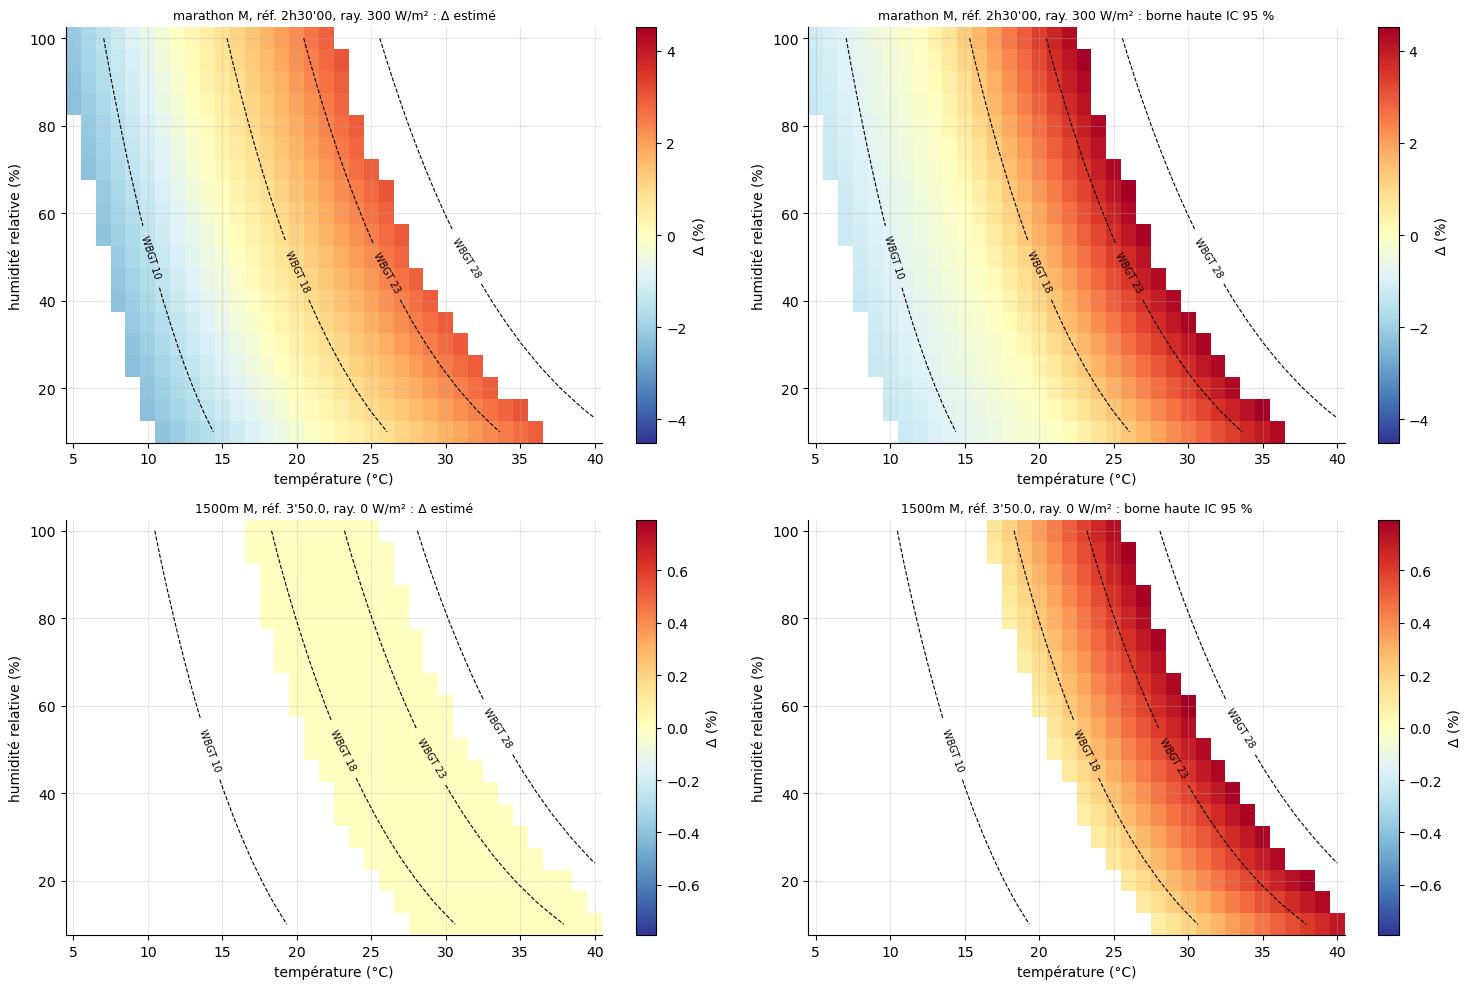

Marathon homme, 2h30 en conditions de référence, rayonnement 300 W/m², vent 2 m/s :
chrono équivalent estimé / chrono prudent (borne IC 95 %)
                     10 °C              15 °C              20 °C              25 °C              30 °C
HR 30 %  2h27'03 / 2h28'20  2h28'48 / 2h29'20  2h30'34 / 2h30'51  2h32'21 / 2h33'30  2h34'09 / 2h36'11
HR 50 %  2h27'40 / 2h28'41  2h29'34 / 2h29'45  2h31'30 / 2h32'14  2h33'27 / 2h35'09              — / —
HR 70 %  2h28'14 / 2h29'00  2h30'16 / 2h30'24  2h32'20 / 2h33'28  2h34'27 / 2h36'38              — / —
HR 90 %  2h28'46 / 2h29'18  2h30'55 / 2h31'21  2h33'06 / 2h34'37              — / —              — / —


In [89]:
def degradation_grille(modele, grille_w, epreuve, sexe, Y, vent=VENT_REF):
    '''Même calcul que degradation (pluie 0, altitude 0), vectorisé sur une grille de WBGT : un seul predict.'''
    base = df_tout[(df_tout["epreuve_norm"] == epreuve) & (df_tout["sexe"] == sexe)]
    if len(base) > 200:
        base = base.sample(200, random_state=SEED)
    t_y = DISTANCE[epreuve] / Y
    base = base.assign(niveau_pct=100 * np.log(t_y / RP_MEDIAN[(sexe, epreuve)]), log_duree=np.log(t_y / 60.0))
    p0 = modele.predict(base.assign(wbgt=WBGT_REF, vent_10m=VENT_REF, precipitation_mm_h=0.0, alt_km=0.0)).mean()
    d1 = pd.concat([base.assign(wbgt=w, vent_10m=vent, precipitation_mm_h=0.0, alt_km=0.0) for w in grille_w])
    return np.asarray(modele.predict(d1)).reshape(len(grille_w), len(base)).mean(axis=1) - p0

_gw = [WBGT_REF + 5.0, WBGT_REF + 12.0]
assert np.allclose(degradation_grille(MODELES_FINAUX[MODELE_OUTIL], _gw, "marathon", "M", 4.5),
                   [degradation(MODELES_FINAUX[MODELE_OUTIL], w, "marathon", "M", 4.5) for w in _gw], atol=1e-8)


def abaque(Y, epreuve, sexe, rayonnement=0.0, heure_locale=9.0, vent=VENT_REF, axes=None):
    T = np.arange(5, 41, 1.0); HR = np.arange(10, 101, 5.0)
    W = np.array([[calculer_wbgt(t, h, vent, rayonnement, heure_locale=heure_locale) for t in T] for h in HR])
    lo, hi = PLAGE_WBGT.loc[GROUPE_DE[epreuve]]
    gw = np.linspace(lo, hi, 30)
    dg = degradation_grille(MODELES_FINAUX[MODELE_OUTIL], gw, epreuve, sexe, Y, vent)
    db = np.array([degradation_grille(m, gw, epreuve, sexe, Y, vent) for m in BOOT[MODELE_OUTIL][1][:200]])
    hors = (W < lo) | (W > hi)
    D = np.where(hors, np.nan, np.interp(W, gw, dg))
    D_haut = np.where(hors, np.nan, np.interp(W, gw, np.quantile(db, 0.975, axis=0)))
    vmax = max(np.nanmax(np.abs(D_haut)), 0.5)
    for ax, Z, titre in zip(axes, [D, D_haut], ["Δ estimé", "borne haute IC 95 %"]):
        im = ax.pcolormesh(T, HR, Z, cmap="RdYlBu_r", shading="nearest", vmin=-vmax, vmax=vmax)
        cs = ax.contour(T, HR, W, levels=[10, 18, 23, 28], colors="k", linewidths=0.8, linestyles="--")
        ax.clabel(cs, fmt="WBGT %g", fontsize=7)
        ax.set_xlabel("température (°C)"); ax.set_ylabel("humidité relative (%)")
        ax.set_title(f"{epreuve} {sexe}, réf. {chrono(Y, DISTANCE[epreuve])}, ray. {rayonnement:g} W/m² : {titre}", fontsize=9)
        plt.colorbar(im, ax=ax, label="Δ (%)")
    print(f"{epreuve} {sexe} : Δ de {np.nanmin(D):+.3f} à {np.nanmax(D):+.3f} ; borne haute de {np.nanmin(D_haut):+.3f} à "
          f"{np.nanmax(D_haut):+.3f} ; plage de WBGT {lo:.1f}-{hi:.1f} °C ; {np.isnan(D).mean():.0%} des cases hors plage")
    return T, HR, W, D, D_haut

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
T_, HR_, W_, D_, Dh_ = abaque(DISTANCE["marathon"] / 9000, "marathon", "M", rayonnement=300.0, axes=axes[0])
_ = abaque(DISTANCE["1500m"] / 230, "1500m", "M", rayonnement=0.0, heure_locale=20.0, axes=axes[1])
plt.tight_layout(); plt.show()
Y_m = DISTANCE["marathon"] / 9000
sel_T, sel_H = [10, 15, 20, 25, 30], [30, 50, 70, 90]
tab = pd.DataFrame([[chrono(Y_m * np.exp(-D_[list(HR_).index(h), list(T_).index(t)] / 100), DISTANCE["marathon"]) + " / " +
                     chrono(Y_m * np.exp(-Dh_[list(HR_).index(h), list(T_).index(t)] / 100), DISTANCE["marathon"]) for t in sel_T] for h in sel_H],
                   index=[f"HR {h} %" for h in sel_H], columns=[f"{t} °C" for t in sel_T])
print("Marathon homme, 2h30 en conditions de référence, rayonnement 300 W/m², vent 2 m/s :")
print("chrono équivalent estimé / chrono prudent (borne IC 95 %)")
print(tab.to_string())

**Analyse.**

| marathon homme, 2 h 30 en référence | 10 °C | 15 °C | 20 °C | 25 °C | 30 °C |
|---|---|---|---|---|---|
| $HR$ 30 % | 2h27'03 / 2h28'20 | 2h28'48 / 2h29'20 | 2h30'34 / 2h30'51 | 2h32'21 / 2h33'30 | 2h34'09 / 2h36'11 |
| $HR$ 50 % | 2h27'40 / 2h28'41 | 2h29'34 / 2h29'45 | 2h31'30 / 2h32'14 | 2h33'27 / 2h35'09 | – |
| $HR$ 70 % | 2h28'14 / 2h29'00 | 2h30'16 / 2h30'24 | 2h32'20 / 2h33'28 | 2h34'27 / 2h36'38 | – |
| $HR$ 90 % | 2h28'46 / 2h29'18 | 2h30'55 / 2h31'21 | 2h33'06 / 2h34'37 | – | – |

(chrono équivalent estimé / chrono prudent, c'est-à-dire la borne de l'IC à 95 % ; soleil de 300 W/m², vent de 2 m/s,
« – » : hors de la plage observée)

**Marathon.** Les isolignes de WBGT descendent de gauche à droite : à température égale, l'humidité augmente la charge
thermique, et le soleil seul ajoute plusieurs degrés de WBGT par rapport à l'ombre. $\Delta$ va de $-2{,}3$ % (WBGT de 8
à 10 °C : on court plus vite qu'en référence) à $+3{,}0$ % vers 25 °C ; la borne prudente va de $-1{,}3$ à $+4{,}5$ %. À
22 °C, 70 % et au soleil, l'outil conseille 2 h 33' 10", soit environ 3' 38" au kilomètre au lieu de 3' 33". **41 % des
cases sont blanches** : chaleur humide (25 °C et 90 %, ou 30 °C au-delà de 30 % d'humidité) et froid sec. L'outil refuse
d'y répondre plutôt que d'extrapoler une droite.

**1 500 m.** $\Delta$ est nul (moins de 0,01 point en valeur absolue) sur toute la plage couverte, de 16 à 25,6 °C ; la
borne haute reste sous 0,8 %, moins de 2 secondes sur 3' 50". **70 % de la grille est blanche** : il n'y a pas de réunion
de piste fraîche dans les données, et l'outil ne dit donc rien d'un 1 500 m par temps frais.

**Conseil d'allure.** Sur 1 500 m, pas d'ajustement. Au marathon, ralentir de 1 à 1,5 % par tranche de 5 °C de WBGT
au-dessus de 15 °C, et viser la borne prudente si l'on ne connaît pas sa tolérance à la chaleur. Ces chiffres sont des
**moyennes** pour des coureurs de bon niveau, acclimatés ou non, sans distinction ; la tolérance individuelle,
l'acclimatation et l'hydratation peuvent faire beaucoup plus. Au-delà de 23 °C de WBGT (drapeau rouge de l'ACSM), l'enjeu
devient la **sécurité** plus que le chrono.

## Partie 11 — Discussion critique

Cette dernière partie examine la solidité des résultats : sensibilité au choix de la marge de troncature, validité de
la cible, biais possibles et leur sens, généralisation, et pistes d'amélioration.

**Sensibilité à la marge de troncature.** La partie 1.5 a étudié la pente brute de $y$ sur le WBGT en fonction de la
marge minimale $M$. On refait l'exercice avec le modèle de l'outil : pour chaque $M \in \{0, 3, 5, 8, 12\}$ %, on
réestime le modèle sur les performances valides de marge au moins égale à $M$, et l'on calcule l'effet d'une hausse du
WBGT de 15 à 25 °C dans chaque groupe d'épreuves. Si la troncature atténue l'effet de la chaleur (partie 1.5), cet
effet doit augmenter avec $M$.

In [90]:
# Un élément pour la discussion : sensibilité de l'effet de la chaleur à la marge de troncature M
df_c = ajouter_variables(df_complet)
lignes = []
for M in [0, 3, 5, 8, 12]:
    d_m = df_c[df_c["marge_troncature_pct"] >= M]
    m = PipelineOutil().fit(d_m)
    ref = pd.concat([g.sample(min(200, len(g)), random_state=SEED) for _, g in d_m.groupby("groupe_epreuve")])
    lignes.append({"M (%)": M, "n": len(d_m), **{g: round(courbe_degradation(m, ref[ref["groupe_epreuve"] == g], [WBGT_REF + 10])[0], 3)
                                                  for g in GROUPES}})
print(f"Effet d'une hausse de 10 °C du WBGT (points de y) selon la marge minimale M :")
print(pd.DataFrame(lignes).to_string(index=False))

Effet d'une hausse de 10 °C du WBGT (points de y) selon la marge minimale M :
 M (%)     n  demi-fond piste  fond piste  route courte  semi-marathon  marathon
     0 14221           -0.060       0.502         1.083          1.736     3.356
     3 12275            0.006       0.533         1.299          1.711     3.227
     5 10398            0.036       0.824         1.522          1.776     3.142
     8  7637           -0.016       0.787         1.619          1.878     3.160
    12  4514           -0.336       1.861         1.716          1.443     3.020


**Analyse.**

| marge minimale $M$ | performances | demi-fond piste | fond piste | route courte | semi-marathon | marathon |
|---|---|---|---|---|---|---|
| 0 % | 14 221 | $-0{,}06$ | 0,50 | 1,08 | 1,74 | 3,36 |
| 3 % | 12 275 | 0,01 | 0,53 | 1,30 | 1,71 | 3,23 |
| 5 % | 10 398 | 0,04 | 0,82 | 1,52 | 1,78 | 3,14 |
| 8 % | 7 637 | $-0{,}02$ | 0,79 | 1,62 | 1,88 | 3,16 |
| 12 % | 4 514 | $-0{,}34$ | 1,86 | 1,72 | 1,44 | 3,02 |

(effet d'une hausse du WBGT de 15 à 25 °C, en points de $y$)

**La troncature est bornée.** Au marathon, l'effet reste entre **3,0 et 3,4 points** quand $M$ varie de 0 à 12 % : le
résultat principal est robuste au choix de la marge. Sur route courte, il passe de 1,1 à 1,7 point quand $M$ augmente,
ce qui va dans le sens d'une atténuation par la troncature (partie 1.5). Le demi-fond reste proche de 0 quel que soit
$M$. Les valeurs à $M = 12$ % reposent sur des échantillons réduits de moitié, et le fond sur piste y devient instable.
Au marathon, l'effet diminue même légèrement quand $M$ augmente (de 3,36 à 3,02), à l'inverse de la pente brute de la
partie 1.5 : une fois les contrôles introduits, la troncature n'y biaise plus l'effet de façon détectable, et ces écarts
restent dans la marge d'incertitude des estimations (partie 8.4).

#### Validité de la cible

$y = 100\ln(t/t^{\text{RP}})$ suppose un effort maximal et un record représentatif du niveau du jour.

* Le record peut être **ancien** : $y$ croît fortement avec l'âge (partie 1.4), et l'âge, la forme et le niveau ne
  corrigent qu'en moyenne.
* Le jeu de données ne suit pas les athlètes : la comparaison se fait **entre** coureurs semblables, pas chez un même
  coureur. Un plan intra-athlète (le même coureur dans des conditions différentes) serait plus convaincant.
* 6 222 performances sans record publié (débutants sur la distance, ou donnée manquante) sont exclues : l'échantillon
  surreprésente les coureurs expérimentés.

#### Les biais possibles et leur sens

* **L'erreur de mesure de la météo atténue les effets.** La météo vient d'une réanalyse à 9-30 km de résolution, sans
  microclimat (îlot de chaleur urbain, tribunes) ; sur piste, l'heure est celle du début de la réunion et non de la
  course. Si l'on observe $W^{\text{obs}} = W + \epsilon_W$ au lieu du vrai WBGT $W$, avec une erreur $\epsilon_W$
  indépendante de $W$ et de $y$, la pente estimée tend vers

  $$\beta_W\,\frac{\text{Var}(W)}{\text{Var}(W) + \text{Var}(\epsilon_W)} < \beta_W :$$

  c'est le **biais d'atténuation** (ou de dilution). Une erreur de mesure aléatoire tire toujours l'effet vers 0, et ce
  d'autant plus que la variation utile du WBGT est faible, ce qui est le cas pour la variation intra-parcours (partie
  2.3).
* **La sélection sous-estime l'effet.** Par forte chaleur, les abandons ne sont pas listés, et certains coureurs
  renoncent ou « assurent ». L'effet est sous-estimé pour le chrono maximal ; c'est pourtant en partie ce qu'un coureur
  veut savoir : de combien ralentir pour finir.
* **La confusion entre lieux reste possible.** La chaleur est surtout observée **entre** lieux (100 lieux, 396 courses),
  avec un écart-type intra-parcours d'environ 1 °C seulement. Le pays, le plateau et le profil des parcours ne sont
  contrôlés qu'imparfaitement, même si les effets fixes et le terme de Mundlak concordent avec les effets aléatoires
  (partie 4.2).
* **L'hétéroscédasticité n'est que contournée.** L'écart-type intra-course de $y$ double entre la piste et le marathon
  (1,9 contre 3,6 points). Le modèle mixte à $\sigma^2$ commun a une vraisemblance bimodale, contournée en fixant
  $\gamma$ (partie 8.4) mais pas corrigée.
* **Les intervalles de prédiction dépendent de l'échangeabilité.** La partie 9 a montré qu'un pli de calibration non
  représentatif fait perdre la couverture garantie.

#### Généralisation

Les données couvrent des coureurs de bon niveau, un WBGT de 5 à 28 °C, la piste uniquement entre 13,5 et 26 °C en
soirée, et l'altitude uniquement sur route (8 lieux au-dessus de 1 000 m). Rien ne permet d'extrapoler aux coureurs
populaires (plus touchés selon Ely *et al.*), aux canicules, aux championnats sous climat tropical ou au demi-fond par
temps froid. Pour l'**entraînement** à allure sous-maximale, « même effort » renvoie plutôt à la fréquence cardiaque ou
à la perception de l'effort : l'outil ne s'y transpose pas directement.

#### Pistes d'amélioration

* Des listes **complètes** (tous les arrivants, abandons compris), donc sans troncature, et des identifiants
  d'athlètes, pour un plan intra-athlète.
* Les heures réelles de départ, des stations météorologiques proches et le profil des parcours (dénivelé, virages).
* Un modèle mixte **hétéroscédastique** ($\sigma^2$ propre à chaque groupe d'épreuves), des effets aléatoires croisés
  athlète × course, ou un modèle bayésien hiérarchique qui rétrécit l'effet de la chaleur d'un groupe d'épreuves vers
  celui des autres et autorise une courbure commune.
* Une calibration conforme sur plusieurs plis, ou par groupe d'épreuves (partie 9).
* Un modèle conjoint de l'abandon et de la performance, pour traiter la sélection.
* Des données de fréquence cardiaque, pour transposer l'outil à l'entraînement.

#### Conclusion

À effort égal, quand le WBGT passe de 15 à 25 °C, la chaleur ne coûte **rien de mesurable sur 800 m et 1 500 m**,
environ **1,5 % sur 5 et 10 km** et environ **3 % au marathon**. Le vent coûte environ 0,2 % par m/s à WBGT égal, et
l'altitude pèse sur route, avec une grande incertitude. En prédiction, les quatre familles de modèles se valent, et
environ un sixième de la variance des performances est prévisible sur un lieu nouveau ; le reste relève de la forme
du jour. Sur le plan méthodologique, quatre leçons se dégagent : valider par **groupes** (lieux) quand les données sont
structurées, estimer l'incertitude par un bootstrap des **mêmes** groupes, distinguer **prédire** et **estimer un
effet**, et préférer un outil qui donne un intervalle honnête et refuse d'extrapoler.

In [91]:
print(f"Durée totale d'exécution du notebook : {(time.time() - t0_notebook) / 60:.1f} min")

Durée totale d'exécution du notebook : 5.7 min


### Références

* Aitken A. C. (1935). On least squares and linear combination of observations. *Proc. R. Soc. Edinburgh* 55, 42-48.
* Armstrong L. E. *et al.* (2007). American College of Sports Medicine position stand. Exertional heat illness during
  training and competition. *Med. Sci. Sports Exerc.* 39(3), 556-572.
* Bergstra J., Bengio Y. (2012). Random search for hyper-parameter optimization. *JMLR* 13, 281-305.
* Breiman L., Friedman J., Olshen R., Stone C. (1984). *Classification and Regression Trees*. Wadsworth.
* Brent R. P. (1973). *Algorithms for Minimization without Derivatives*. Prentice-Hall.
* Cybenko G. (1989). Approximation by superpositions of a sigmoidal function. *Math. Control Signals Syst.* 2(4),
  303-314.
* Efron B. (1979). Bootstrap methods: another look at the jackknife. *Ann. Stat.* 7(1), 1-26.
* Ely M. R., Cheuvront S. N., Roberts W. O., Montain S. J. (2007). Impact of weather on marathon-running performance.
  *Med. Sci. Sports Exerc.* 39(3), 487-493.
* Friedman J. H. (2001). Greedy function approximation: a gradient boosting machine. *Ann. Stat.* 29(5), 1189-1232.
* Goldstein A., Kapelner A., Bleich J., Pitkin E. (2015). Peeking inside the black box: visualizing statistical
  learning with plots of individual conditional expectation. *J. Comput. Graph. Stat.* 24(1), 44-65.
* Grinsztajn L., Oyallon E., Varoquaux G. (2022). Why do tree-based models still outperform deep learning on typical
  tabular data? *NeurIPS, Datasets and Benchmarks Track*.
* Hastie T., Tibshirani R., Friedman J. (2009). *The Elements of Statistical Learning*, 2e éd. Springer.
* Hersbach H. *et al.* (2020). The ERA5 global reanalysis. *Q. J. R. Meteorol. Soc.* 146, 1999-2049.
* Hornik K. (1991). Approximation capabilities of multilayer feedforward networks. *Neural Networks* 4(2), 251-257.
* Ke G. *et al.* (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.
* Kingma D. P., Ba J. (2015). Adam: a method for stochastic optimization. *ICLR*.
* Kish L. (1965). *Survey Sampling*. Wiley.
* Leshno M., Lin V. Y., Pinkus A., Schocken S. (1993). Multilayer feedforward networks with a nonpolynomial activation
  function can approximate any function. *Neural Networks* 6(6), 861-867.
* Liljegren J. C., Carhart R. A., Lawday P., Tschopp S., Sharp R. (2008). Modeling the wet bulb globe temperature using
  standard meteorological measurements. *J. Occup. Environ. Hyg.* 5(10), 645-655.
* Lorenzo S., Halliwill J. R., Sawka M. N., Minson C. T. (2010). Heat acclimation improves exercise performance.
  *J. Appl. Physiol.* 109(4), 1140-1147.
* Loshchilov I., Hutter F. (2019). Decoupled weight decay regularization. *ICLR*.
* Lundberg S. M., Lee S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.
* Mantzios K. *et al.* (2022). Effects of weather parameters on endurance running performance: discipline-specific
  analysis of 1258 races. *Med. Sci. Sports Exerc.* 54(1), 153-161.
* Mundlak Y. (1978). On the pooling of time series and cross section data. *Econometrica* 46(1), 69-85.
* Patterson H. D., Thompson R. (1971). Recovery of inter-block information when block sizes are unequal.
  *Biometrika* 58(3), 545-554.
* Racinais S. *et al.* (2015). Consensus recommendations on training and competing in the heat. *Br. J. Sports Med.*
  49(18), 1164-1173.
* Romano Y., Patterson E., Candès E. (2019). Conformalized quantile regression. *NeurIPS*.
* Rønnestad B. R. *et al.* (2022). Heat suit training increases hemoglobin mass in elite cross-country skiers.
  *Scand. J. Med. Sci. Sports*.
* Shapley L. S. (1953). A value for n-person games. *Contributions to the Theory of Games* II, 307-317.
* Srivastava N., Hinton G., Krizhevsky A., Sutskever I., Salakhutdinov R. (2014). Dropout: a simple way to prevent
  neural networks from overfitting. *JMLR* 15, 1929-1958.
* Telgarsky M. (2016). Benefits of depth in neural networks. *COLT*.
* Zippenfenig P. (2023). Open-Meteo.com Weather API. Zenodo, doi:10.5281/ZENODO.7970649.